# Detección de emociones en mensajes de estudiantes para un tutor virtual

## 1. Introducción

Las emociones influyen directamente en el aprendizaje. La teoría de control-valor de las emociones de logro [1] sostiene que estados como la frustración, el enojo o la alegría afectan la motivación, la atención y las estrategias de estudio. Del mismo modo, los estudios sobre la dinámica afectiva durante el aprendizaje complejo [2] muestran que la confusión es un estado frecuente y, hasta cierto punto, productivo: cuando se resuelve, favorece una comprensión más profunda. Cuando no se resuelve, en cambio, tiende a convertirse en frustración y, después, en desinterés o abandono de la tarea.

En la educación presencial, un docente percibe estas señales en el rostro, el tono o las preguntas de sus estudiantes y ajusta su explicación sobre la marcha. En los entornos de aprendizaje mediados por tecnología, y en particular en los tutores virtuales basados en chatbots, esa información se pierde: el sistema responde al contenido del mensaje, pero no a la forma en que el estudiante se siente. Un tutor que no distingue entre un estudiante que pregunta por curiosidad y otro que está a punto de rendirse responderá de la misma manera a ambos.

El objetivo de este proyecto es construir un clasificador supervisado que, a partir de un mensaje escrito por un estudiante, identifique su estado emocional entre cinco clases relevantes para el contexto educativo: **frustración, confusión, enojo, alegría y neutral**. Este clasificador está pensado como un componente que, en trabajos futuros, permitirá a un tutor virtual adaptar su estrategia pedagógica, por ejemplo simplificando la explicación cuando detecta frustración o confusión.

El principal reto es la escasez de datos: no existen datasets públicos y abiertos de mensajes de estudiantes en español etiquetados con estas emociones. Para abordarlo, se construye un dataset a partir de la versión en español de GoEmotions [3], cuyas 27 emociones originales se agrupan en las cinco clases de interés, y se complementa con mensajes de contexto educativo generados con un modelo de lenguaje. Como representación de los textos se usan embeddings de un modelo Sentence-BERT multilingüe preentrenado [4] (transfer learning), sobre los cuales se entrenan y comparan estadísticamente clasificadores de aprendizaje supervisado, siguiendo una metodología de validación con repeated k-fold cross-validation.

## 2. Análisis exploratorio de datos (EDA)

El dataset del proyecto se construye a partir de **tres fuentes**:

| Fuente (columna `fuente`) | Origen | Tamaño |
|---|---|---|
| `goemotions` | GoEmotions traducido automáticamente al español (`mrm8488/go_emotions-es-mt`): comentarios de Reddit etiquetados por personas. | 54.263 comentarios antes de filtrar |
| `gpt` | Mensajes de contexto educativo generados con ChatGPT. | 1.000 (200 por clase) |
| `gemini` | Mensajes de contexto educativo generados con Gemini. | 500 (100 por clase) |

La sección se organiza en tres partes:

- **Parte A (2.1 a 2.4):** carga, análisis y transformación de GoEmotions hasta las cinco clases del proyecto.
- **Parte B (2.5 y 2.6):** carga y verificación de los datasets sintéticos y unificación de las tres fuentes en un único DataFrame con la columna `fuente`.
- **Parte C (2.7 a 2.14):** análisis del dataset unificado. Cada análisis se presenta para el conjunto completo y **desglosado por fuente**, con dos objetivos: caracterizar el dataset final y comparar los datos reales (Reddit) con los sintéticos (GPT y Gemini).

Cada decisión se justifica junto al código que la implementa, y al final de cada subsección se resumen las cifras clave.

### Configuración general

Antes de empezar se importan las bibliotecas y se fijan los elementos comunes a toda la notebook:

- **Semilla global (`42`)**: se usa en todo muestreo aleatorio para que los resultados sean reproducibles.
- **Orden y paleta de colores de las clases**: cada clase tiene siempre el mismo color en todos los gráficos de la notebook (EDA, matriz de confusión, t-SNE), de modo que, por ejemplo, la frustración se reconozca a simple vista. La paleta se eligió para que los cinco colores se distingan también con los tipos de daltonismo más comunes.
- **Orden y paleta de colores de las fuentes**: una segunda paleta, distinta de la de las clases, identifica siempre a `goemotions`, `gpt` y `gemini`, para que en los gráficos desglosados por fuente no se confunda una fuente con una clase.
- **Agrupación de emociones**: el diccionario que asigna cada emoción original de GoEmotions a una de las cinco clases se define aquí porque se usa desde la subsección 2.3; su justificación está en la subsección 2.4.
- **Rutas de los datos**: en Colab, la notebook monta Google Drive y lee los CSV sintéticos desde la carpeta indicada en `CARPETA_DRIVE`, donde también guarda el dataset final, de modo que los archivos persisten entre sesiones. Fuera de Colab se usa la carpeta local `data/`. Todas las rutas dependen de una sola variable, `DIRECTORIO_DATOS`; la opción de subir los archivos directamente a la sesión de Colab queda comentada.

In [3]:
%pip install -q datasets spacy

In [4]:
import itertools
import os
import random
import re
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Semilla global para que todo muestreo aleatorio sea reproducible
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# ------------------------------------------------------------------
# Rutas de los datos (configuración única)
# ------------------------------------------------------------------
# Opción activa: en Colab se leen los CSV desde Google Drive; fuera de Colab, desde la carpeta local data/.
# Cambiar CARPETA_DRIVE si los CSV están en otra carpeta de "Mi unidad".
CARPETA_DRIVE = "/content/drive/MyDrive/analisis_sentimientos/data"

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount("/content/drive")
    DIRECTORIO_DATOS = CARPETA_DRIVE
else:
    DIRECTORIO_DATOS = "data"

# Otra opción en Colab (sin Drive): subir los dos CSV a la sesión (panel "Archivos" > "Subir")
# y usar la línea siguiente. Los archivos se pierden al reiniciar el entorno de ejecución.
# DIRECTORIO_DATOS = "/content"

RUTA_CSV_GPT = os.path.join(DIRECTORIO_DATOS, "dataset_sentimientos_educativo_gpt.csv")
RUTA_CSV_GEMINI = os.path.join(DIRECTORIO_DATOS, "dataset_sentimientos_educativo_gemini.csv")
RUTA_DATASET_FINAL = os.path.join(DIRECTORIO_DATOS, "dataset_final.csv")

# Comprobación temprana para que un error de ruta se detecte aquí y no en la sección 2.5
for ruta in [RUTA_CSV_GPT, RUTA_CSV_GEMINI]:
    if not os.path.exists(ruta):
        contenido = sorted(os.listdir(DIRECTORIO_DATOS)) if os.path.isdir(DIRECTORIO_DATOS) else "la carpeta no existe"
        raise FileNotFoundError(
            f"No se encontró {ruta}. Contenido de '{DIRECTORIO_DATOS}': {contenido}. "
            f"Revise CARPETA_DRIVE (o DIRECTORIO_DATOS) y el nombre de los archivos."
        )
print(f"Carpeta de datos: {os.path.abspath(DIRECTORIO_DATOS)}")

# Orden fijo de las clases y nombres para mostrar en los gráficos
ORDEN_CLASES = ["frustracion", "confusion", "enojo", "alegria", "neutral"]
NOMBRES_CLASES = {
    "frustracion": "Frustración",
    "confusion": "Confusión",
    "enojo": "Enojo",
    "alegria": "Alegría",
    "neutral": "Neutral",
}

# Paleta fija por clase (se reutiliza en toda la notebook)
PALETA_CLASES = {
    "frustracion": "#eb6834",  # naranja
    "confusion": "#2a78d6",    # azul
    "enojo": "#e87ba4",        # magenta
    "alegria": "#eda100",      # amarillo
    "neutral": "#1baf7a",      # verde agua
}
COLOR_GENERAL = "#5f6b7a"  # gris para gráficos que no distinguen clases ni fuentes

# Orden fijo de las fuentes y paleta por fuente (distinta de la paleta de clases)
ORDEN_FUENTES = ["goemotions", "gpt", "gemini"]
NOMBRES_FUENTES = {
    "goemotions": "GoEmotions (Reddit)",
    "gpt": "GPT",
    "gemini": "Gemini",
}
PALETA_FUENTES = {
    "goemotions": "#264653",  # azul petróleo oscuro
    "gpt": "#8e44ad",         # violeta
    "gemini": "#b5651d",      # siena
}

# Agrupación de las emociones originales en las 5 clases (justificada en 2.4)
MAPEO_CLASES = {
    "annoyance": "frustracion",
    "disappointment": "frustracion",
    "confusion": "confusion",
    "anger": "enojo",
    "disgust": "enojo",
    "joy": "alegria",
    "gratitude": "alegria",
    "admiration": "alegria",
    "approval": "alegria",
    "relief": "alegria",
    "excitement": "alegria",
    "neutral": "neutral",
}

# Estilo de los gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# Mostrar los textos completos en las tablas
pd.set_option("display.max_colwidth", None)

Mounted at /content/drive
Carpeta de datos: /content/drive/MyDrive/analisis_sentimientos/data


---

## Parte A: GoEmotions

### 2.1 Carga de GoEmotions

Se usa el dataset **`mrm8488/go_emotions-es-mt`** de Hugging Face [5], que es la versión de GoEmotions traducida automáticamente al español. Se carga con la biblioteca `datasets` y, a continuación, se muestra su estructura: los splits disponibles y el número de filas de cada uno.

In [5]:
from datasets import load_dataset

ds = load_dataset("mrm8488/go_emotions-es-mt")
print(ds)

print("\nFilas por split:")
for nombre_split, split in ds.items():
    print(f"  {nombre_split:<12}{split.num_rows:>8,}")
print(f"  {'total':<12}{sum(s.num_rows for s in ds.values()):>8,}")

README.md:   0%|          | 0.00/631 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/2.30k [00:00<?, ?B/s]

data/train-00000-of-00001-1a52cf3c7c7bc8(…): reconstructing file:   0%|          |  0.00B / 5.19MB            

data/train-00000-of-00001-1a52cf3c7c7bc8(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-f19ff191d(…): reconstructing file:   0%|          |  0.00B /  649kB            

data/validation-00000-of-00001-f19ff191d(…): downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id', 'text_es'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id', 'text_es'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id', 'text_es'],
        num_rows: 5427
    })
})

Filas por split:
  train         43,410
  validation     5,426
  test           5,427
  total         54,263


**Unión de los splits.** Los tres splits (`train`, `validation` y `test`) se unen en un único DataFrame. Más adelante los modelos se evaluarán con un esquema propio de *repeated k-fold cross-validation*, que genera sus propias particiones de entrenamiento y validación; por eso las particiones originales no se usan. Se agrega la columna `split` para conservar el origen de cada fila por si se necesita consultarlo.

In [6]:
df_crudo = pd.concat(
    [split.to_pandas().assign(split=nombre_split) for nombre_split, split in ds.items()],
    ignore_index=True,
)
# La columna labels llega como arreglo de NumPy; se convierte a lista de enteros
df_crudo["labels"] = df_crudo["labels"].apply(lambda etiquetas: [int(e) for e in etiquetas])

print("Dimensiones:", df_crudo.shape)
print("Columnas:", list(df_crudo.columns))
print("\nTipos de datos:")
print(df_crudo.dtypes)

Dimensiones: (54263, 5)
Columnas: ['text', 'labels', 'id', 'text_es', 'split']

Tipos de datos:
text       object
labels     object
id         object
text_es    object
split      object
dtype: object


In [7]:
df_crudo.head()

,text,labels,id,text_es,split
0,My favourite food is anything I didn't have to cook myself.,[27],eebbqej,Mi comida favorita es cualquier cosa que no tuviera que cocinar yo mismo.,train
1,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead",[27],ed00q6i,"Ahora, si lo hace fuera de sí mismo, todo el mundo pensará que está teniendo una risa jodiendo con la gente en lugar de realmente muerto",train
2,WHY THE FUCK IS BAYLESS ISOING,[2],eezlygj,POR QUÉ FUE EL FOLLADO ES LA BAYLESS ISOING,train
3,To make her feel threatened,[14],ed7ypvh,Para hacerla sentir amenazada.,train
4,Dirty Southern Wankers,[3],ed0bdzj,Sucio sureño Wankers,train


**Descripción de las columnas**

| Columna | Descripción |
|---|---|
| `text` | Comentario original de Reddit, en inglés. |
| `text_es` | Traducción automática del comentario al español. **Es la columna que se usará para modelar.** |
| `labels` | Lista de índices de emociones. El dataset es multietiqueta, así que un comentario puede tener varias. |
| `id` | Identificador del comentario en Reddit. |
| `split` | Partición original de la que proviene la fila (columna agregada en esta notebook). |

**Descripción del dataset original.** GoEmotions [3] es un corpus de aproximadamente 58 000 comentarios en inglés extraídos de Reddit, publicado por Google Research en 2020 (Demszky et al.). Cada comentario fue anotado por personas mediante *crowdsourcing* con una o varias de **27 emociones más la categoría `neutral`** (28 categorías en total). La versión usada aquí contiene los comentarios de la versión simplificada del dataset original (54.263 comentarios, porque esa versión descarta los comentarios sin acuerdo suficiente entre anotadores), con su traducción automática al español.

**Cifras clave de 2.1**

- Filas por split: `train` = 43.410, `validation` = 5.426, `test` = 5.427.
- Filas del DataFrame unido (`df_crudo`): 54.263.

### 2.2 Decodificación de las etiquetas

La columna `labels` solo contiene índices numéricos. Para poder analizarlos se define la lista ordenada de las 28 categorías de GoEmotions, donde la posición de cada nombre corresponde a su índice (0 = `admiration`, …, 27 = `neutral`).

In [8]:
EMOCIONES_GOEMOTIONS = [
    "admiration", "amusement", "anger", "annoyance", "approval", "caring",
    "confusion", "curiosity", "desire", "disappointment", "disapproval",
    "disgust", "embarrassment", "excitement", "fear", "gratitude", "grief",
    "joy", "love", "nervousness", "optimism", "pride", "realization",
    "relief", "remorse", "sadness", "surprise", "neutral",
]
print(f"Número de categorías: {len(EMOCIONES_GOEMOTIONS)}")

Número de categorías: 28


**Verificación del orden.** Un error en el orden de la lista asignaría nombres equivocados a todas las etiquetas sin que el código falle, así que se comprueba explícitamente. Para ello se cargan los nombres de las etiquetas desde el dataset original `google-research-datasets/go_emotions` (configuración `simplified`) y se comparan con la lista definida. Esos nombres corresponden al archivo `emotions.txt` del repositorio oficial de Google Research (https://github.com/google-research/google-research/blob/master/goemotions/data/emotions.txt), que define el orden oficial de las 28 categorías.

In [9]:
ds_original = load_dataset("google-research-datasets/go_emotions", "simplified")
nombres_oficiales = ds_original["train"].features["labels"].feature.names

assert nombres_oficiales == EMOCIONES_GOEMOTIONS, "El orden de las emociones no coincide con el dataset original"
print("El orden de las 28 emociones coincide con el dataset original.")

# Comprobación adicional: todos los índices del dataset en español están dentro del rango válido
indices_usados = {indice for etiquetas in df_crudo["labels"] for indice in etiquetas}
assert indices_usados <= set(range(len(EMOCIONES_GOEMOTIONS))), "Hay índices fuera del rango 0-27"
print(f"Índices presentes en el dataset: {min(indices_usados)} a {max(indices_usados)}")

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

El orden de las 28 emociones coincide con el dataset original.
Índices presentes en el dataset: 0 a 27


Con el orden verificado, se crea un nuevo DataFrame (`df_etiquetado`) con dos columnas adicionales: `emociones`, con la lista de nombres de cada comentario, y `n_etiquetas`, con la cantidad de etiquetas que tiene.

In [10]:
df_etiquetado = df_crudo.copy()
df_etiquetado["emociones"] = df_etiquetado["labels"].apply(
    lambda etiquetas: [EMOCIONES_GOEMOTIONS[i] for i in etiquetas]
)
df_etiquetado["n_etiquetas"] = df_etiquetado["labels"].apply(len)

df_etiquetado[["text_es", "labels", "emociones", "n_etiquetas"]].sample(8, random_state=SEMILLA)

,text_es,labels,emociones,n_etiquetas
34480,Esto es realmente espeluznante.,[11],[disgust],1
15157,"Bien, tomaré esto con una pizca de sal, pero tómelo en consideración. Gracias.","[4, 15]","[approval, gratitude]",2
28594,"Me encanta bloodborne, empecé mi segundo juego a través de pero renunciar después de que me puse ocupado con cosas de la escuela.. necesidad de volver a ella sin embargo.. amor ese juego",[18],[love],1
20091,"Dios mío, me alegro de que tú también estuvieras allí. Hiciste que su día apestara un poco menos.",[17],[joy],1
14786,Sí... una mujer que espera que un hombre nunca piense en otras mujeres por el resto de su vida es una especie especial de delirante.,[0],[admiration],1
31660,100% sí,[27],[neutral],1
6975,La gente siempre los parry (600ms) :(,"[3, 9, 25]","[annoyance, disappointment, sadness]",3
45915,Título: geez otro idiota Texto: ooh well lol,[1],[amusement],1


**Cifras clave de 2.2**

- Las 28 categorías definidas coinciden con las del dataset original.
- Filas de `df_etiquetado`: 54.263 (igual que `df_crudo`; en esta subsección no se elimina ninguna fila).

### 2.3 Análisis del dataset original (28 categorías)

Antes de filtrar o agrupar se analiza el dataset tal como viene, para entender su desbalance, su carácter multietiqueta y qué emociones tienden a aparecer juntas.

#### 2.3.1 Distribución de las 28 emociones

Se cuenta cada aparición de una emoción: un comentario con dos etiquetas suma una vez a cada una de ellas. Por eso el total de apariciones es mayor que el número de comentarios.

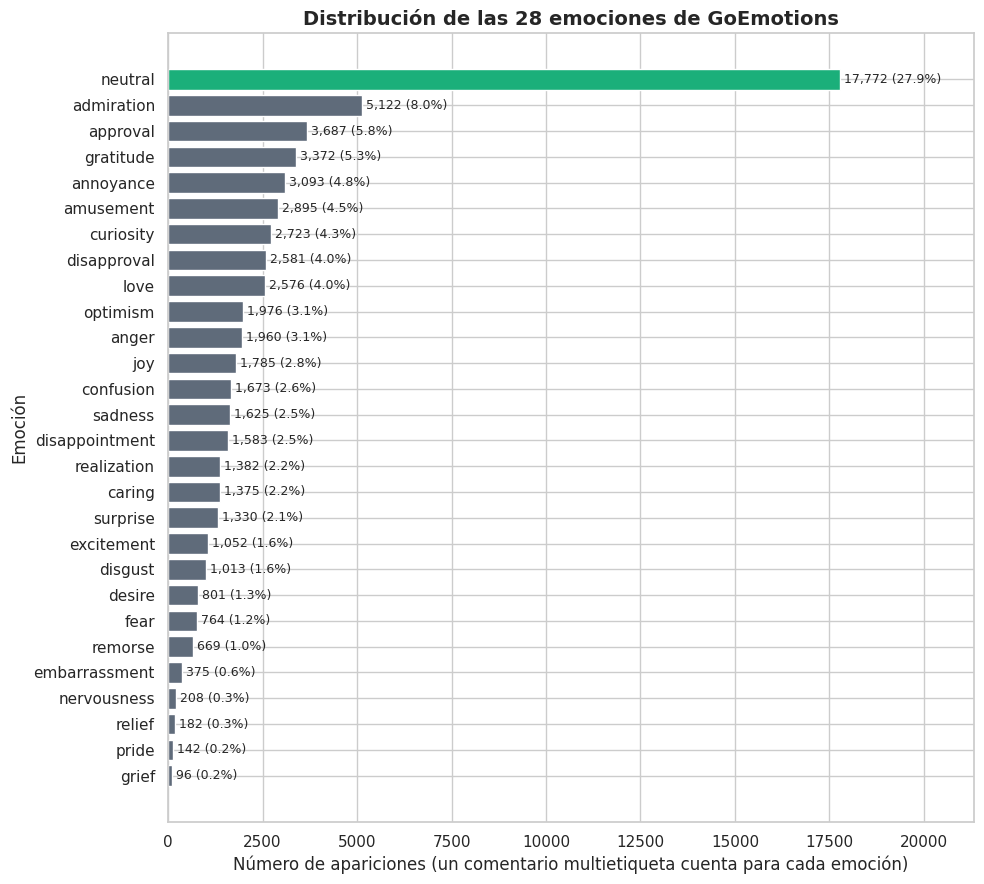

Total de apariciones: 63,812 en 54,263 comentarios
Ratio entre la emoción más frecuente y la menos frecuente: 185.1


In [11]:
conteo_emociones = df_etiquetado["emociones"].explode().value_counts()
total_apariciones = conteo_emociones.sum()

fig, ax = plt.subplots(figsize=(10, 9))
conteo_ordenado = conteo_emociones.sort_values()
colores = [PALETA_CLASES["neutral"] if e == "neutral" else COLOR_GENERAL for e in conteo_ordenado.index]
ax.barh(conteo_ordenado.index, conteo_ordenado.values, color=colores)
for i, valor in enumerate(conteo_ordenado.values):
    ax.text(valor, i, f" {valor:,} ({valor / total_apariciones:.1%})", va="center", fontsize=9)
ax.set_title("Distribución de las 28 emociones de GoEmotions")
ax.set_xlabel("Número de apariciones (un comentario multietiqueta cuenta para cada emoción)")
ax.set_ylabel("Emoción")
ax.set_xlim(0, conteo_ordenado.max() * 1.2)
plt.tight_layout()
plt.show()

print(f"Total de apariciones: {total_apariciones:,} en {len(df_etiquetado):,} comentarios")
print(f"Ratio entre la emoción más frecuente y la menos frecuente: "
      f"{conteo_emociones.iloc[0] / conteo_emociones.iloc[-1]:.1f}")

**Interpretación.** La distribución de las 28 categorías está fuertemente desbalanceada. `neutral` es la categoría más frecuente, con 17.772 apariciones (27,9 % del total), más del triple que la segunda, `admiration`, con 5.122 (8,0 %). En el otro extremo, `grief` (96 apariciones) y `pride` (142) apenas llegan al 0,2 % cada una, lo que da un ratio de 185,1 entre la categoría más frecuente y la menos frecuente. Varias de las emociones que se usarán en el proyecto están entre las poco frecuentes (`confusion`, con 1.673 apariciones; `disgust`, con 1.013; `relief`, con 182), así que el desbalance es una característica central del dataset y condiciona la métrica de evaluación (2.8) y el balanceo (2.13).

#### 2.3.2 Análisis multietiqueta

Se cuenta cuántas etiquetas tiene cada comentario. Esto indica cuántos datos se conservarán al quedarse solo con los comentarios de una única etiqueta (subsección 2.4).

,comentarios,porcentaje
n_etiquetas,,
1,45446,83.75
2,8124,14.97
3,655,1.21
4,37,0.07
5,1,0.00


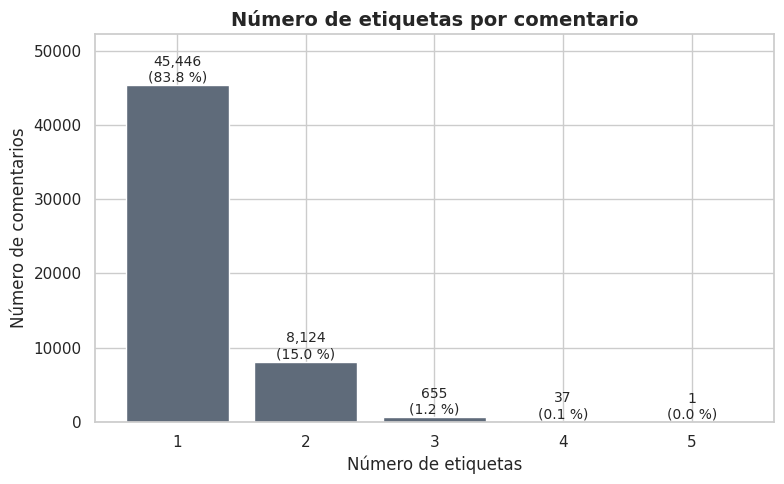

In [12]:
tabla_n_etiquetas = (
    df_etiquetado["n_etiquetas"].value_counts().sort_index()
    .rename_axis("n_etiquetas").to_frame("comentarios")
)
tabla_n_etiquetas["porcentaje"] = (tabla_n_etiquetas["comentarios"] / len(df_etiquetado) * 100).round(2)
display(tabla_n_etiquetas)

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(tabla_n_etiquetas.index.astype(str), tabla_n_etiquetas["comentarios"], color=COLOR_GENERAL)
for barra, pct in zip(barras, tabla_n_etiquetas["porcentaje"]):
    ax.annotate(f"{int(barra.get_height()):,}\n({pct:.1f} %)",
                (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Número de etiquetas por comentario")
ax.set_xlabel("Número de etiquetas")
ax.set_ylabel("Número de comentarios")
ax.set_ylim(0, tabla_n_etiquetas["comentarios"].max() * 1.15)
plt.tight_layout()
plt.show()

**Interpretación.** El 83,8 % de los comentarios (45.446) tiene una sola etiqueta, el 15,0 % (8.124) tiene dos y solo el 1,3 % (693) tiene tres o más. La gran mayoría del dataset es de etiqueta única, de modo que filtrar los comentarios multietiqueta en 2.4.1 conserva la mayor parte de los datos.

#### 2.3.3 Co-ocurrencias de emociones

Entre los comentarios multietiqueta se cuentan los pares de emociones que aparecen juntos. Esto sirve para evaluar la agrupación propuesta en 2.4: si dos emociones que se agruparán en la misma clase (por ejemplo, `annoyance` y `disappointment`, ambas en frustración) aparecen juntas con frecuencia, eso respalda que expresan estados parecidos. Si, en cambio, emociones de clases distintas aparecen juntas a menudo (por ejemplo, `anger` con `annoyance`), eso anticipa que esas clases serán difíciles de separar.

In [13]:
df_multi = df_etiquetado[df_etiquetado["n_etiquetas"] > 1]
conteo_pares = Counter(
    par
    for emociones in df_multi["emociones"]
    for par in itertools.combinations(sorted(emociones), 2)
)

top_pares = pd.DataFrame(
    [(a, b, n) for (a, b), n in conteo_pares.most_common(15)],
    columns=["emocion_1", "emocion_2", "comentarios"],
)
top_pares["clase_1"] = top_pares["emocion_1"].map(MAPEO_CLASES).fillna("(descartada)")
top_pares["clase_2"] = top_pares["emocion_2"].map(MAPEO_CLASES).fillna("(descartada)")
top_pares["misma_clase"] = (top_pares["clase_1"] == top_pares["clase_2"]) & (top_pares["clase_1"] != "(descartada)")
print(f"Comentarios multietiqueta: {len(df_multi):,}")
print("Top 15 de pares de emociones más frecuentes:")
display(top_pares)

Comentarios multietiqueta: 8,817
Top 15 de pares de emociones más frecuentes:


,emocion_1,emocion_2,comentarios,clase_1,clase_2,misma_clase
0,anger,annoyance,348,enojo,frustracion,False
1,admiration,gratitude,341,alegria,alegria,True
2,admiration,approval,298,alegria,alegria,True
3,approval,neutral,258,alegria,neutral,False
4,confusion,curiosity,253,confusion,(descartada),False
5,admiration,love,236,alegria,(descartada),False
6,annoyance,disapproval,222,frustracion,(descartada),False
7,annoyance,neutral,177,frustracion,neutral,False
8,disappointment,sadness,163,frustracion,(descartada),False
9,curiosity,neutral,162,(descartada),neutral,False


Para mirar en detalle las emociones que se usarán en el proyecto, el siguiente heatmap muestra las co-ocurrencias solo entre las 12 emociones que se agrupan en las cinco clases, ordenadas por clase. Los recuadros marcan los pares que quedan dentro de la misma clase.

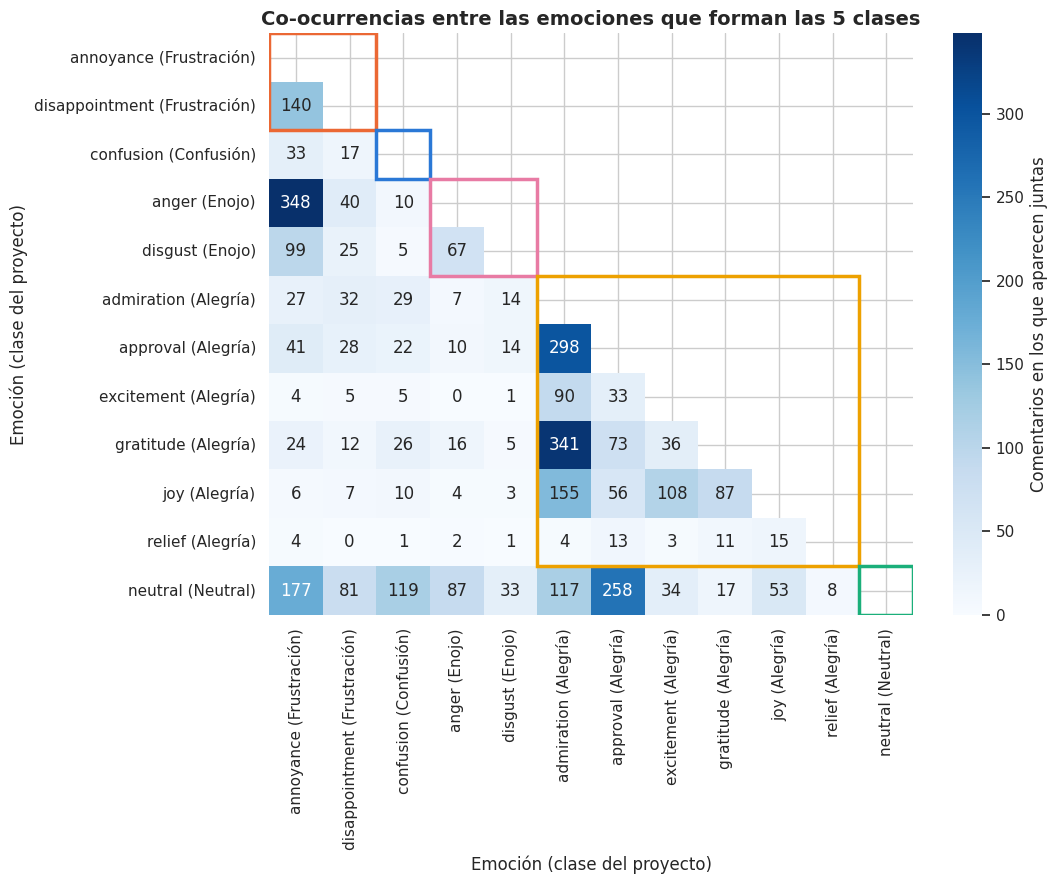

Pares de interés para la agrupación:
  annoyance + disappointment: 140 comentarios
  anger + disgust: 67 comentarios
  anger + annoyance: 348 comentarios
  annoyance + disgust: 99 comentarios
  admiration + gratitude: 341 comentarios
  excitement + joy: 108 comentarios


In [14]:
emociones_usadas = sorted(MAPEO_CLASES, key=lambda e: (ORDEN_CLASES.index(MAPEO_CLASES[e]), e))
matriz_coocurrencia = pd.DataFrame(0, index=emociones_usadas, columns=emociones_usadas)
for (a, b), n in conteo_pares.items():
    if a in MAPEO_CLASES and b in MAPEO_CLASES:
        matriz_coocurrencia.loc[a, b] += n
        matriz_coocurrencia.loc[b, a] += n

etiquetas_ejes = [f"{e} ({NOMBRES_CLASES[MAPEO_CLASES[e]]})" for e in emociones_usadas]
mascara = np.triu(np.ones_like(matriz_coocurrencia, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(matriz_coocurrencia, mask=mascara, annot=True, fmt="d", cmap="Blues",
            xticklabels=etiquetas_ejes, yticklabels=etiquetas_ejes,
            cbar_kws={"label": "Comentarios en los que aparecen juntas"}, ax=ax)

# Recuadros que delimitan los pares de emociones de una misma clase
inicio = 0
for clase in ORDEN_CLASES:
    tamano = sum(MAPEO_CLASES[e] == clase for e in emociones_usadas)
    ax.add_patch(plt.Rectangle((inicio, inicio), tamano, tamano, fill=False,
                               edgecolor=PALETA_CLASES[clase], linewidth=2.5))
    inicio += tamano

ax.set_title("Co-ocurrencias entre las emociones que forman las 5 clases")
ax.set_xlabel("Emoción (clase del proyecto)")
ax.set_ylabel("Emoción (clase del proyecto)")
plt.tight_layout()
plt.show()

print("Pares de interés para la agrupación:")
for a, b in [("annoyance", "disappointment"), ("anger", "disgust"), ("anger", "annoyance"),
             ("annoyance", "disgust"), ("admiration", "gratitude"), ("excitement", "joy")]:
    par = tuple(sorted((a, b)))
    print(f"  {a} + {b}: {conteo_pares.get(par, 0):,} comentarios")

**Interpretación.** El top 15 está dominado por dos tipos de pares: los de emociones positivas entre sí (`admiration` + `gratitude`, 341 comentarios; `admiration` + `approval`, 298; `admiration` + `joy`, 155) y los de una emoción con `neutral` (`approval`, `annoyance`, `curiosity` y `disapproval` con `neutral`, 4 de los 15 pares). Sin embargo, el par más frecuente de todo el dataset es `anger` + `annoyance`, con 348 comentarios, y une dos emociones que el proyecto asigna a clases distintas (enojo y frustración): la frontera entre ambas clases es difusa ya en las anotaciones humanas.

`annoyance` y `disappointment` aparecen juntas en 140 comentarios, lo que respalda agruparlas en frustración, y `anger` y `disgust`, que forman la clase enojo, en 67. Aun así, `annoyance` aparece con `anger` (348 comentarios) más del doble de veces que con `disappointment` (140), y también aparece con `disgust` (99) más que `anger` (67). Esto anticipa que la confusión entre frustración y enojo será uno de los principales errores del clasificador.

**Cifras clave de 2.3**

- Total de apariciones de emociones: 63.812 en 54.263 comentarios.
- Comentarios con una sola etiqueta: 45.446 (83,8 %).
- Comentarios multietiqueta: 8.817.

### 2.4 Filtrado y agrupación en las 5 clases del proyecto

#### 2.4.1 Filtrado de comentarios con una única etiqueta

Se conservan solo los comentarios que tienen **una única etiqueta**. Hay dos razones:

1. **Evitar ejemplos ambiguos.** Un comentario anotado a la vez con, por ejemplo, `annoyance` y `joy` no tiene una emoción dominante clara, y usarlo como ejemplo de una sola clase introduciría ruido en el entrenamiento.
2. **Convertir el problema en clasificación multiclase.** El clasificador del tutor debe asignar una emoción a cada mensaje, así que cada ejemplo de entrenamiento debe tener exactamente una etiqueta.

Como se vio en 2.3.2, la gran mayoría de los comentarios son de etiqueta única, de modo que el filtro conserva la mayor parte de los datos.

In [15]:
df_una_etiqueta = df_etiquetado[df_etiquetado["n_etiquetas"] == 1].copy()
df_una_etiqueta["emocion_original"] = df_una_etiqueta["emociones"].str[0]

print(f"Filas antes del filtro: {len(df_etiquetado):,}")
print(f"Filas con una única etiqueta: {len(df_una_etiqueta):,} "
      f"({len(df_una_etiqueta) / len(df_etiquetado):.1%})")

Filas antes del filtro: 54,263
Filas con una única etiqueta: 45,446 (83.8%)


#### 2.4.2 Agrupación de las emociones en las 5 clases

Las emociones originales se agrupan en las cinco clases del proyecto según la siguiente tabla:

| Clase del proyecto | Emociones originales de GoEmotions |
|---|---|
| frustracion | annoyance, disappointment |
| confusion | confusion |
| enojo | anger, disgust |
| alegria | joy, gratitude, admiration, approval, relief, excitement |
| neutral | neutral |

Las filas cuya emoción no aparece en la tabla se descartan.

In [16]:
df_5clases = df_una_etiqueta.copy()
df_5clases["clase"] = df_5clases["emocion_original"].map(MAPEO_CLASES)

df_descartado = df_5clases[df_5clases["clase"].isna()]
df_5clases = df_5clases.dropna(subset=["clase"]).reset_index(drop=True)

print(f"Filas descartadas por no estar en la tabla: {len(df_descartado):,}")
print(f"Filas tras agrupar en 5 clases: {len(df_5clases):,}")
print("\nEmociones descartadas (comentarios de una sola etiqueta):")
display(df_descartado["emocion_original"].value_counts().rename_axis("emocion").to_frame("comentarios"))

Filas descartadas por no estar en la tabla: 13,868
Filas tras agrupar en 5 clases: 31,578

Emociones descartadas (comentarios de una sola etiqueta):


,comentarios
emocion,
amusement,2046
disapproval,1809
love,1760
curiosity,1729
optimism,1087
sadness,1003
surprise,902
caring,831
realization,749


**Justificación de los descartes.** Se conservan solo las emociones que corresponden a los estados emocionales que el tutor necesita reconocer. Las demás se descartan porque no aportan a ninguna de las cinco clases o porque introducirían ruido. Los casos más discutibles son:

- **`curiosity`**: en un contexto educativo la curiosidad indica interés y podría parecer relevante. Sin embargo, en el texto se expresa casi siempre con preguntas, igual que la confusión, y el modelo tendría muchas dificultades para distinguir "pregunto porque me interesa" de "pregunto porque no entiendo". Se excluye para no introducir ruido en la clase confusión.
- **`sadness`, `fear` y `nervousness`**: aunque la ansiedad o el desánimo pueden darse al estudiar, en Reddit estas emociones se refieren sobre todo a temas personales (duelo, enfermedades, miedos), no a dificultades de aprendizaje. Incluirlas haría que las clases aprendieran vocabulario de un dominio muy distinto al del tutor.
- **Otras emociones** como `amusement`, `love`, `caring`, `optimism`, `surprise` o `disapproval` no corresponden de forma directa a ninguna de las cinco clases, o lo hacen de forma ambigua (por ejemplo, `disapproval` puede expresar desacuerdo sin frustración ni enojo).

In [17]:
resumen_filtrado = pd.DataFrame({
    "paso": [
        "Total original (todos los splits)",
        "Con una única etiqueta",
        "Tras agrupar en 5 clases",
    ],
    "filas": [len(df_crudo), len(df_una_etiqueta), len(df_5clases)],
})
resumen_filtrado["% del total original"] = (resumen_filtrado["filas"] / len(df_crudo) * 100).round(2)
resumen_filtrado

,paso,filas,% del total original
0,Total original (todos los splits),54263,100.00
1,Con una única etiqueta,45446,83.75
2,Tras agrupar en 5 clases,31578,58.19


#### 2.4.3 Composición interna de cada clase

Se revisa cuántos ejemplos aporta cada emoción original a su clase. Si una clase depende casi por completo de una sola emoción, el modelo aprenderá en realidad esa emoción y no el concepto más amplio de la clase.

,clase,emocion_original,comentarios,% dentro de la clase
0,frustracion,annoyance,1809,67.1
1,frustracion,disappointment,888,32.9
2,confusion,confusion,1057,100.0
3,enojo,anger,1265,66.6
4,enojo,disgust,635,33.4
5,alegria,admiration,3384,34.2
6,alegria,gratitude,2378,24.0
7,alegria,approval,2367,23.9
8,alegria,joy,1052,10.6
9,alegria,excitement,619,6.3


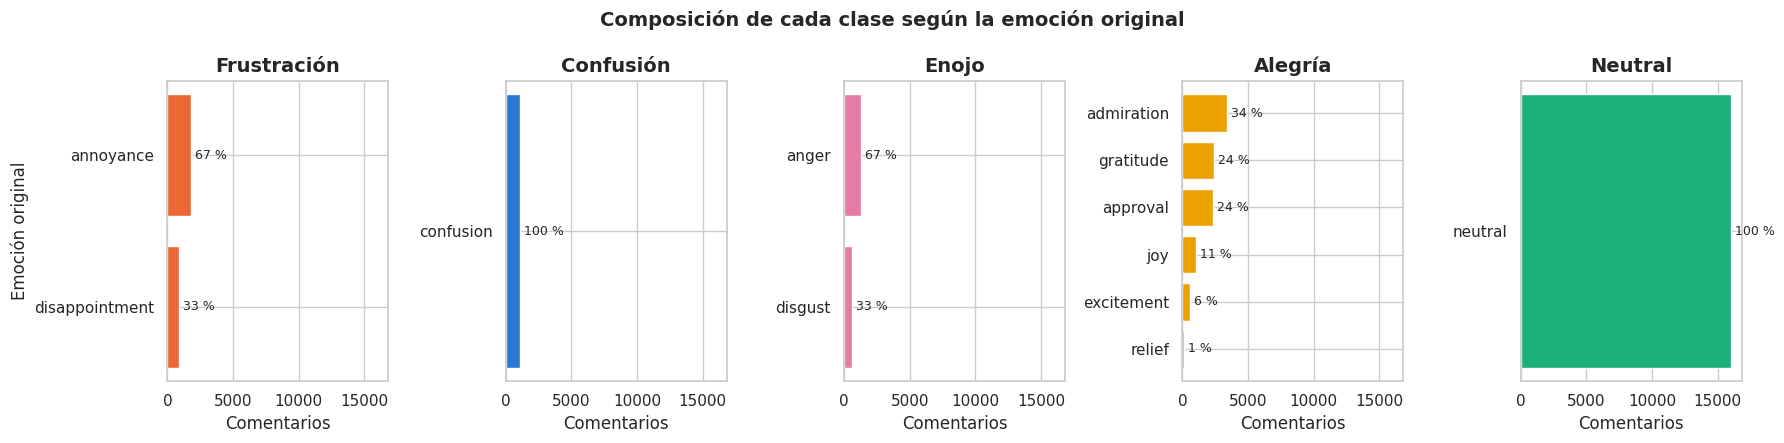

In [18]:
composicion = (
    df_5clases.groupby(["clase", "emocion_original"]).size()
    .rename("comentarios").reset_index()
)
composicion["% dentro de la clase"] = (
    composicion["comentarios"] / composicion.groupby("clase")["comentarios"].transform("sum") * 100
).round(1)
composicion["clase"] = pd.Categorical(composicion["clase"], categories=ORDEN_CLASES, ordered=True)
composicion = composicion.sort_values(["clase", "comentarios"], ascending=[True, False]).reset_index(drop=True)
display(composicion)

fig, ejes = plt.subplots(1, len(ORDEN_CLASES), figsize=(18, 4.5), sharex=True)
for ax, clase in zip(ejes, ORDEN_CLASES):
    datos = composicion[composicion["clase"] == clase].sort_values("comentarios")
    ax.barh(datos["emocion_original"], datos["comentarios"], color=PALETA_CLASES[clase])
    for i, (valor, pct) in enumerate(zip(datos["comentarios"], datos["% dentro de la clase"])):
        ax.text(valor, i, f" {pct:.0f} %", va="center", fontsize=9)
    ax.set_title(NOMBRES_CLASES[clase])
    ax.set_xlabel("Comentarios")
ejes[0].set_ylabel("Emoción original")
fig.suptitle("Composición de cada clase según la emoción original", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación.** Dos clases tienen una única emoción por construcción: `confusion` (1.057 comentarios) y `neutral` (16.021). En frustración domina `annoyance` (1.809 comentarios, 67,1 %) frente a `disappointment` (888, 32,9 %), y en enojo, `anger` (1.265, 66,6 %) frente a `disgust` (635, 33,4 %): en ambas clases, la emoción principal aporta unos dos tercios de los ejemplos. Alegría es la clase más heterogénea: `admiration` (34,2 %), `gratitude` (24,0 %) y `approval` (23,9 %) suman el 82,1 %, mientras que `joy` aporta el 10,6 %, `excitement` el 6,3 % y `relief` solo 103 comentarios (1,0 %). Ninguna de las clases compuestas depende casi por completo de una sola emoción (el máximo es el 67,1 % de `annoyance`), pero el submuestreo de 2.13 se estratifica por emoción original para mantener estas proporciones; con un muestreo simple, emociones minoritarias como `relief` podrían quedar con muy pocos ejemplos.

**Cifras clave de 2.4**

- Total original: 54.263 filas → con una única etiqueta: 45.446 → tras agrupar en 5 clases: 31.578.
- Filas descartadas por emoción fuera de la tabla: 13.868.

---

## Parte B: datasets sintéticos (GPT y Gemini)

### 2.5 Carga y verificación de los datasets sintéticos

**Origen de los datos.** GoEmotions aporta muchos ejemplos etiquetados por personas, pero son comentarios de Reddit sobre temas de todo tipo, no mensajes de estudiantes a un tutor. No existen datasets públicos de mensajes de estudiantes en español etiquetados con estas cinco emociones, así que se generaron mensajes de **contexto educativo** con dos modelos de lenguaje:

| Fuente | Modelo | Mensajes pedidos por clase | Total |
|---|---|---|---|
| `gpt` | ChatGPT | 200 | 1 000 |
| `gemini` | Gemini | 100 | 500 |

Usar dos generadores reduce la dependencia del estilo de uno solo. El aporte real de estos mensajes al clasificador se medirá en el modelado, comparando un modelo entrenado solo con GoEmotions con otro que además usa los mensajes sintéticos (ver 2.14).

**Codificación.** Los archivos se leen como UTF-8 para que las tildes, las eñes y los signos `¿` y `¡` se lean correctamente. Se usa la variante `utf-8-sig`, que es UTF-8 pero descarta la marca BOM que algunos programas (por ejemplo, Excel) escriben al inicio del archivo; con `utf-8` simple, el nombre de la primera columna se leería como `﻿texto` en lugar de `texto`.

**Verificaciones.** Para cada archivo se muestra su estructura y se comprueba que tenga exactamente las columnas `texto` y `sentimiento`, que las etiquetas sean solo las cinco del proyecto y que no haya valores nulos ni textos vacíos. Aunque los archivos ya usan las etiquetas correctas, como medida defensiva las etiquetas se normalizan igualmente (sin espacios, en minúsculas y sin tildes), y se informa si alguna fila tenía una etiqueta fuera del conjunto esperado.

In [19]:
COLUMNAS_ESPERADAS = {"texto", "sentimiento"}
PATRON_TILDES = r"[áéíóúüñÁÉÍÓÚÜÑ¿¡]"
PATRON_MOJIBAKE = "Ã|Â|�"  # restos típicos de leer UTF-8 con otra codificación


def quitar_tildes(texto):
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))


def normalizar_etiqueta(etiqueta):
    # Medida defensiva: quitar espacios, pasar a minúsculas y quitar tildes
    return quitar_tildes(str(etiqueta).strip().lower())


def verificar_sintetico(df, nombre):
    """Muestra la estructura de un CSV sintético, verifica su formato y
    devuelve una copia con las etiquetas normalizadas."""
    print(f"Dimensiones de {nombre}: {df.shape}")
    print(f"Columnas: {list(df.columns)}")
    print("\nTipos de datos:")
    print(df.dtypes.to_string())
    display(df.head())

    # 1) Columnas
    assert set(df.columns) == COLUMNAS_ESPERADAS, f"Columnas inesperadas en {nombre}: {list(df.columns)}"
    print("Columnas correctas: existen exactamente 'texto' y 'sentimiento'.")

    # 2) Codificación: deben aparecer tildes y eñes, y ningún carácter mal decodificado
    textos = df["texto"].fillna("").astype(str)
    con_tildes = textos.str.contains(PATRON_TILDES)
    print(f"\nMensajes con tildes, eñes o signos ¿ ¡: {con_tildes.sum():,}")
    print(f"Mensajes con caracteres mal decodificados (Ã, Â, �): {textos.str.contains(PATRON_MOJIBAKE).sum():,}")
    if con_tildes.any():
        print(f"Ejemplo de lectura: {textos[con_tildes].iloc[0]}")

    # 3) Etiquetas
    print("\nValores únicos de 'sentimiento' tal como vienen en el archivo:")
    display(df["sentimiento"].value_counts(dropna=False).rename_axis("sentimiento").to_frame("mensajes"))
    df_normalizado = df.copy()
    df_normalizado["sentimiento"] = df_normalizado["sentimiento"].apply(normalizar_etiqueta)
    n_modificadas = (df_normalizado["sentimiento"] != df["sentimiento"]).sum()
    fuera_de_conjunto = ~df_normalizado["sentimiento"].isin(ORDEN_CLASES)
    print(f"Etiquetas modificadas por la normalización: {n_modificadas:,}")
    print(f"Etiquetas fuera del conjunto esperado tras normalizar: {fuera_de_conjunto.sum():,}")
    if fuera_de_conjunto.any():
        display(df[fuera_de_conjunto])

    # 4) Nulos y textos vacíos
    print("\nValores nulos por columna:")
    print(df.isna().sum().to_string())
    print(f"Textos vacíos o formados solo por espacios: {(textos.str.strip() == '').sum():,}")
    return df_normalizado

#### 2.5.1 Dataset generado con GPT

In [20]:
df_gpt_crudo = pd.read_csv(RUTA_CSV_GPT, encoding="utf-8-sig")
df_gpt = verificar_sintetico(df_gpt_crudo, "GPT")

Dimensiones de GPT: (1000, 2)
Columnas: ['texto', 'sentimiento']

Tipos de datos:
texto          object
sentimiento    object


,texto,sentimiento
0,No entiendo nada de la clase de matemáticas.,frustracion
1,No entiendo nada de el tema de álgebra.,frustracion
2,No entiendo nada de la explicación de hoy.,frustracion
3,No entiendo nada de el ejercicio de física.,frustracion
4,No entiendo nada de la práctica de programación.,frustracion


Columnas correctas: existen exactamente 'texto' y 'sentimiento'.

Mensajes con tildes, eñes o signos ¿ ¡: 956
Mensajes con caracteres mal decodificados (Ã, Â, �): 0
Ejemplo de lectura: No entiendo nada de la clase de matemáticas.

Valores únicos de 'sentimiento' tal como vienen en el archivo:


,mensajes
sentimiento,
frustracion,200
confusion,200
enojo,200
alegria,200
neutral,200


Etiquetas modificadas por la normalización: 0
Etiquetas fuera del conjunto esperado tras normalizar: 0

Valores nulos por columna:
texto          0
sentimiento    0
Textos vacíos o formados solo por espacios: 0


#### 2.5.2 Dataset generado con Gemini

In [21]:
df_gemini_crudo = pd.read_csv(RUTA_CSV_GEMINI, encoding="utf-8-sig")
df_gemini = verificar_sintetico(df_gemini_crudo, "Gemini")

Dimensiones de Gemini: (500, 2)
Columnas: ['texto', 'sentimiento']

Tipos de datos:
texto          object
sentimiento    object


,texto,sentimiento
0,Estoy furioso con la calificación que me pusieron en el cuestionario.,enojo
1,Hoy vimos la introducción a este tema y dejaron lectura.,neutral
2,"¡Qué emoción, subí muchísimo mi promedio en programación!",alegria
3,¡Es injusto que pongan este ejercicio tan larga para mañana!,enojo
4,No entiendo nada de derivadas.,frustracion


Columnas correctas: existen exactamente 'texto' y 'sentimiento'.

Mensajes con tildes, eñes o signos ¿ ¡: 415
Mensajes con caracteres mal decodificados (Ã, Â, �): 0
Ejemplo de lectura: Estoy furioso con la calificación que me pusieron en el cuestionario.

Valores únicos de 'sentimiento' tal como vienen en el archivo:


,mensajes
sentimiento,
enojo,100
neutral,100
alegria,100
frustracion,100
confusion,100


Etiquetas modificadas por la normalización: 0
Etiquetas fuera del conjunto esperado tras normalizar: 0

Valores nulos por columna:
texto          0
sentimiento    0
Textos vacíos o formados solo por espacios: 0


**Interpretación.** Ambos archivos superan todas las verificaciones: tienen exactamente las columnas `texto` y `sentimiento`; las tildes, las eñes y los signos de apertura se leen bien (aparecen en 956 mensajes de GPT y 415 de Gemini, y ninguno tiene caracteres mal decodificados); las etiquetas son solo las cinco del proyecto (la normalización no modificó ninguna y ninguna queda fuera del conjunto), y no hay valores nulos ni textos vacíos. Los archivos pueden usarse sin correcciones de formato.

**Diferencia de tamaño entre las fuentes.** El CSV de Gemini tiene **la mitad de registros** que el de GPT (500 frente a 1.000), y ambos son muy pequeños frente a GoEmotions. Por eso, al comparar las fuentes en el resto de la sección se usan sobre todo **proporciones** (porcentajes dentro de cada fuente, densidades en lugar de conteos, métricas calculadas sobre muestras del mismo tamaño) y no solo conteos absolutos, que harían parecer que Gemini "tiene menos" de todo solo por ser más pequeño.

**Cifras clave de 2.5**

- GPT: 1.000 filas (200 por clase). Gemini: 500 filas (100 por clase).
- Etiquetas fuera del conjunto esperado: GPT = 0, Gemini = 0. Nulos o vacíos: GPT = 0, Gemini = 0.

### 2.6 Unificación de las tres fuentes

Las tres fuentes se llevan a un **esquema común** y se concatenan en un único DataFrame (`df_unificado`):

| Columna | GoEmotions | GPT / Gemini |
|---|---|---|
| `texto` | `text_es` | `texto` |
| `clase` | clase agrupada en 2.4 | `sentimiento` normalizado |
| `emocion_original` | emoción de GoEmotions (`annoyance`, `joy`…) | igual a `clase` |
| `fuente` | `goemotions` | `gpt` o `gemini` |

Además se conserva una columna auxiliar, `texto_ingles`, con el comentario original de Reddit (vacía en los sintéticos). Solo se usa en la revisión de la traducción (2.12) y no forma parte del dataset final.

In [22]:
def contar_por_fuente(df):
    """Número de filas de cada fuente, siempre en el mismo orden."""
    return df["fuente"].value_counts().reindex(ORDEN_FUENTES, fill_value=0)


# GoEmotions en 5 clases llevado al esquema común
df_goemotions_esquema = pd.DataFrame({
    "texto": df_5clases["text_es"],
    "clase": df_5clases["clase"],
    "emocion_original": df_5clases["emocion_original"],
    "fuente": "goemotions",
    "texto_ingles": df_5clases["text"],
})


def sintetico_a_esquema(df, fuente):
    validas = df["sentimiento"].isin(ORDEN_CLASES)
    if (~validas).any():
        print(f"{fuente}: se descartan {(~validas).sum():,} filas con una etiqueta fuera del conjunto esperado")
    df = df[validas]
    return pd.DataFrame({
        "texto": df["texto"].fillna("").astype(str),
        "clase": df["sentimiento"],
        "emocion_original": df["sentimiento"],
        "fuente": fuente,
        "texto_ingles": np.nan,
    })


df_sinteticos = pd.concat(
    [sintetico_a_esquema(df_gpt, "gpt"), sintetico_a_esquema(df_gemini, "gemini")],
    ignore_index=True,
)
df_unificado = pd.concat([df_goemotions_esquema, df_sinteticos], ignore_index=True)

print(f"Dimensiones de df_unificado: {df_unificado.shape}")
print(f"Columnas: {list(df_unificado.columns)}")

print("\nMuestra aleatoria de 3 filas por fuente:")
muestra = df_unificado.groupby("fuente", group_keys=False).sample(n=3, random_state=SEMILLA)
muestra["fuente"] = pd.Categorical(muestra["fuente"], categories=ORDEN_FUENTES, ordered=True)
display(muestra.sort_values("fuente")[["fuente", "texto", "clase", "emocion_original"]].reset_index(drop=True))

Dimensiones de df_unificado: (33078, 5)
Columnas: ['texto', 'clase', 'emocion_original', 'fuente', 'texto_ingles']

Muestra aleatoria de 3 filas por fuente:


,fuente,texto,clase,emocion_original
0,goemotions,Debajo de Springfield Illinois morador check-in. Gracias por compartir el sub ILGuns!,alegria,gratitude
1,goemotions,¡Y terminó esa etapa de la carrera sin ser eliminada! Fue un poco impresionante.,alegria,admiration
2,goemotions,Es curioso cómo lo hace.,alegria,joy
3,gpt,Hoy tenemos la clase de matemáticas según el horario.,neutral,neutral
4,gpt,El curso tiene una unidad dedicada a la tarea de química.,neutral,neutral
5,gpt,¡Me fue excelente en la evaluación de la explicación de hoy!,alegria,alegria
6,gemini,Me siento muy torpe intentando entender programación.,frustracion,frustracion
7,gemini,No me queda clara la diferencia entre la variable dependiente y el predicado.,confusion,confusion
8,gemini,¡Me felicitaron por mi desempeño en el proyecto!,alegria,alegria


In [23]:
filas_por_fuente = contar_por_fuente(df_unificado).rename("filas").to_frame()
filas_por_fuente["% del total"] = (filas_por_fuente["filas"] / len(df_unificado) * 100).round(2)
filas_por_fuente.loc["Total"] = [len(df_unificado), 100.0]
filas_por_fuente["filas"] = filas_por_fuente["filas"].astype(int)
filas_por_fuente.rename_axis("fuente")

,filas,% del total
fuente,,
goemotions,31578,95.47
gpt,1000,3.02
gemini,500,1.51
Total,33078,100.00


**Cifras clave de 2.6**

- `df_unificado`: 33.078 filas = GoEmotions 31.578 (95,5 %) + GPT 1.000 (3,0 %) + Gemini 500 (1,5 %).
- Los datos sintéticos representan solo el 4,5 % del dataset unificado antes de la limpieza y el balanceo.

---

## Parte C: análisis del dataset unificado

### 2.7 Limpieza y duplicados

Se elimina el ruido evidente y, sobre todo, los textos repetidos o casi repetidos. Se trabaja sobre una copia (`df_limpio`), de modo que `df_unificado` se conserva intacto, y cada paso registra cuántas filas elimina **de cada fuente**.

**Por qué es importante eliminar duplicados y casi duplicados.** Los modelos se evaluarán con *repeated k-fold cross-validation*. Si dos mensajes idénticos o casi idénticos quedan uno en el conjunto de entrenamiento y otro en el de prueba de un mismo fold, el modelo "reconoce" en la prueba un texto que ya vio al entrenar. La métrica obtenida mide entonces memoria y no generalización, y queda inflada: es un caso de ***data leakage***. Este riesgo es mayor en los datos sintéticos, porque los modelos generadores tienden a repetir estructuras de frase.

**Importante:** los textos se representarán más adelante con embeddings de un modelo Sentence-BERT preentrenado. Estos modelos se entrenaron con texto natural, así que en el texto que se usará para modelar **no** se eliminan stopwords, no se aplica *stemming* ni se pasa a minúsculas: el encoder necesita el texto tal como lo escribiría una persona. Las normalizaciones que aparecen en esta sección (por ejemplo, para detectar casi duplicados) se aplican sobre copias auxiliares y solo sirven para comparar textos.

In [24]:
df_limpio = df_unificado.copy()
registro_limpieza = []


def registrar_paso(paso, df_antes, df_despues):
    """Guarda y muestra cuántas filas de cada fuente eliminó un paso de limpieza."""
    eliminadas = contar_por_fuente(df_antes) - contar_por_fuente(df_despues)
    registro_limpieza.append({"paso": paso, **eliminadas.to_dict(), "total": int(eliminadas.sum())})
    detalle = ", ".join(f"{fuente} = {n:,}" for fuente, n in eliminadas.items())
    print(f"{paso}: {int(eliminadas.sum()):,} filas eliminadas ({detalle})")

#### 2.7.1 Ruido de la traducción automática

**Origen del ruido.** Al revisar los textos de GoEmotions se encontraron cadenas de caracteres basura que provienen de la traducción automática. Los comentarios originales en inglés tenían emojis, signos repetidos o separadores, y el traductor los convirtió en secuencias largas de símbolos. Por ejemplo:

- `¿Pero los monos no hablan?♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ …` (cientos de `♪`)
- `Es por eso que nos encanta el fútbol!!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡`
- `¡Fuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuuu!`

El caso más frecuente es un artefacto del traductor: el original terminaba en "!!!!!!" y la traducción añadió una cadena de "¡¡¡¡¡¡" **al final** de la frase, algo que nunca es válido en español.

**Por qué afecta al proyecto.**

- **Embeddings:** cada símbolo se convierte en uno o varios tokens. El encoder Sentence-BERT trunca la entrada a 128 tokens y promedia los embeddings de todos ellos, así que la basura ocupa espacio y diluye el significado real de la frase.
- **EDA:** cada `*` o `♪` separado por espacios cuenta como una palabra, así que estas cadenas distorsionan las estadísticas de longitud de 2.9 (el máximo de GoEmotions llegaba a 538 palabras).
- **Duplicados:** "¡Increíble!" y "¡Increíble!¡¡¡¡¡¡" no se reconocen como el mismo texto.

**Criterio: se limpia el texto, no se elimina la fila.** La frase real ("¿Pero los monos no hablan?") sigue siendo un ejemplo válido de su clase. Solo se eliminarán las filas que queden vacías o demasiado cortas tras la limpieza, y de eso se encarga el filtro de textos cortos (2.7.5).

**Por qué es el primer paso de la limpieza.** Tras quitar el ruido, algunos textos quedan idénticos a otros y deben detectarse como duplicados (2.7.2 y 2.7.3), y otros quedan con menos de 3 palabras y deben pasar por el filtro de 2.7.5.

##### Diagnóstico antes de limpiar

Se cuenta, por fuente, cuántos textos tienen cada tipo de ruido, qué símbolos forman las cadenas repetidas y, como indicador independiente, cuántas traducciones son más del doble de largas que el original en inglés (señal de que el traductor añadió contenido). Los patrones que se definen aquí son los mismos que usa la función de limpieza.

In [25]:
# Patrones de ruido (se reutilizan en la función de limpieza)
# Regla 1: el mismo símbolo no alfanumérico repetido 3 veces o más, con o sin espacios ("♪ ♪ ♪", "* * *",
# "-----"). Se excluyen . ! ? ¡ ¿ … (tienen reglas propias) y los corchetes de los marcadores ([NOMBRE]).
PATRON_CADENA_SIMBOLO = re.compile(r"([^\w\s.!?¡¿…\[\]]|_)(?:\s*\1){2,}")
# Regla 2: ¡ o ¿ al final de una frase (al final del texto o antes de un signo de cierre)
PATRON_APERTURA_AL_FINAL = re.compile(r"\s*[¡¿]+(?=\s*(?:$|[!?.,;:…]))")
# Regla 2: ¡ o ¿ repetidos al inicio de una frase
PATRON_APERTURA_REPETIDA = re.compile(r"([¡¿])\1+")
# Regla 3: signos de cierre repetidos, seguidos ("!!!!", "?!?!") o separados por espacios ("! ! !")
PATRON_CIERRE_REPETIDO = re.compile(r"[!?]{2,}")
PATRON_CIERRE_ESPACIADO = re.compile(r"[!?](?:\s+[!?]){2,}")
# Regla 4: cuatro o más puntos seguidos, con o sin espacios
PATRON_PUNTOS = re.compile(r"[.…](?:\s*[.…]){3,}")
# Regla 5: la misma letra (no dígito) repetida 4 veces o más
PATRON_LETRA_ALARGADA = re.compile(r"([^\W\d_])\1{3,}")

TIPOS_RUIDO = {
    "cadena del mismo símbolo": PATRON_CADENA_SIMBOLO,
    "¡ o ¿ al final de la frase": PATRON_APERTURA_AL_FINAL,
    "¡ o ¿ repetidos al inicio": PATRON_APERTURA_REPETIDA,
    "! o ? repetidos": re.compile(f"{PATRON_CIERRE_REPETIDO.pattern}|{PATRON_CIERRE_ESPACIADO.pattern}"),
    "4 o más puntos": PATRON_PUNTOS,
    "letra alargada": PATRON_LETRA_ALARGADA,
}


def recortar(texto, n=150):
    return texto if len(texto) <= n else texto[:n] + " […]"


presencia_ruido = pd.DataFrame({
    tipo: df_limpio["texto"].apply(lambda t, p=patron: bool(p.search(t))) for tipo, patron in TIPOS_RUIDO.items()
})
presencia_ruido["con algún tipo de ruido"] = presencia_ruido.any(axis=1)

tabla_ruido = presencia_ruido.groupby(df_limpio["fuente"]).sum().T.reindex(columns=ORDEN_FUENTES, fill_value=0)
tabla_ruido["% de GoEmotions"] = (tabla_ruido["goemotions"] / contar_por_fuente(df_limpio)["goemotions"] * 100).round(2)
print("Textos con cada tipo de ruido, por fuente:")
display(tabla_ruido)

# Símbolos que forman cadenas repetidas (cualquier signo no alfanumérico repetido 3 veces o más)
PATRON_DIAGNOSTICO_CADENA = re.compile(r"([^\w\s])(?:\s*\1){2,}")
simbolos = df_limpio["texto"].apply(lambda t: sorted({m.group(1) for m in PATRON_DIAGNOSTICO_CADENA.finditer(t)}))
print("Símbolos más frecuentes en las cadenas repetidas (número de textos):")
display(simbolos.explode().dropna().value_counts().rename_axis("símbolo").to_frame("textos").head(15))

Textos con cada tipo de ruido, por fuente:


fuente,goemotions,gpt,gemini,% de GoEmotions
cadena del mismo símbolo,195,0,0,0.62
¡ o ¿ al final de la frase,527,0,0,1.67
¡ o ¿ repetidos al inicio,562,0,0,1.78
! o ? repetidos,429,0,0,1.36
4 o más puntos,177,0,0,0.56
letra alargada,208,0,0,0.66
con algún tipo de ruido,1258,0,0,3.98


Símbolos más frecuentes en las cadenas repetidas (número de textos):


,textos
símbolo,
.,1788
¡,545
!,178
*,106
♪,65
?,13
#,7
-,5
(,2


In [26]:
# Indicador independiente: traducciones más del doble de largas que el original en inglés
df_razon = df_limpio.loc[df_limpio["fuente"] == "goemotions", ["texto", "texto_ingles"]].copy()
df_razon["razon_longitud"] = df_razon["texto"].str.len() / df_razon["texto_ingles"].str.len().clip(lower=1)
print(f"Textos de GoEmotions cuya traducción es más del doble de larga que el original: "
      f"{(df_razon['razon_longitud'] > 2).sum():,} de {len(df_razon):,}")
print("Ejemplos con la razón más alta:")
display(df_razon.nlargest(5, "razon_longitud").assign(
    texto=lambda d: d["texto"].apply(recortar), texto_ingles=lambda d: d["texto_ingles"].apply(recortar)
).round(1).reset_index(drop=True))

print("8 ejemplos aleatorios de textos con ruido:")
con_ruido = df_limpio[presencia_ruido["con algún tipo de ruido"]]
display(con_ruido.sample(min(8, len(con_ruido)), random_state=SEMILLA)
        .assign(texto=lambda d: d["texto"].apply(recortar))[["fuente", "texto", "clase"]].reset_index(drop=True))

Textos de GoEmotions cuya traducción es más del doble de larga que el original: 655 de 31,578
Ejemplos con la razón más alta:


,texto,texto_ingles,razon_longitud
0,Lindo. * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],Cute. 💖,146.6
1,¡Hola! * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],Hiya! 😃,146.6
2,¡El NERVIO! * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],The NERVE! 🤣,85.9
3,Gracias. * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],Thank you. 😀,85.7
4,Oh... welp. * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],Oh... welp. 😑,79.3


8 ejemplos aleatorios de textos con ruido:


,fuente,texto,clase
0,goemotions,¡¡¡EL TÍO RADIZ ESTÁ PERDIDO!!!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,frustracion
1,goemotions,"¿Por qué ella no celebró, ella redirigió que uno en!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡",neutral
2,goemotions,Bien dicho. Y me encanta tu nombre de usuario. * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],alegria
3,goemotions,¿Pero los monos no hablan?♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ […],confusion
4,goemotions,...... jamón no prohibido mmmm,neutral
5,goemotions,¿¡Esperar es esta maldita pérdida!?¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,enojo
6,goemotions,¿Qué son esas cosas que ha vomitado?¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,neutral
7,goemotions,"¿Dónde está el, “esto” * cliché * bot!?!?? Además, es bueno para ti por elegir una vida menos estresante.",alegria


##### Función de limpieza

La función `limpiar_ruido_traduccion` aplica, en este orden, las reglas siguientes:

1. **Cadenas del mismo símbolo no alfanumérico** (`♪ ♪ ♪`, `* * * *`, `# # #`, `• • •`, `-----`), a partir de 3 repeticiones y con o sin espacios: se eliminan por completo. Se excluyen `.`, `!`, `?`, `¡` y `¿`, que tienen reglas propias, y los corchetes, para no afectar a los marcadores como `[NOMBRE]`.
2. **`¡` y `¿` mal colocados:** las cadenas de `¡` o `¿` que aparecen al final de una frase (al final del texto o antes de un signo de cierre) se eliminan, porque en español estos signos solo abren una frase. Las cadenas al inicio de una frase se reducen a un solo signo.
3. **Signos de cierre repetidos:** `!!!!` → `!`, `????` → `?` y las combinaciones como `?!?!` → `?!`. Si al eliminar las cadenas anteriores el texto queda empezando por un signo de cierre (por ejemplo, "¡¡¡¡! Me encanta"), ese signo se elimina.
4. **Puntos repetidos:** cuatro o más puntos (con o sin espacios) → `...`. **Decisión:** la cadena se une a la palabra anterior, así que "Mucho más interesante. ......" queda como "Mucho más interesante...", que es la forma correcta de los puntos suspensivos en español.
5. **Letras alargadas:** la misma letra repetida 4 veces o más → 3 repeticiones ("Fuuuuuuuuu" → "Fuuu"). Se conserva el alargamiento porque expresa énfasis y puede tener información emocional, pero se evita que genere decenas de tokens. No se aplica a dígitos ("1000000" no cambia).
6. **Espacios:** si alguna regla modificó el texto, se colapsan los espacios múltiples, se quitan los espacios que hayan quedado antes de `.`, `,`, `!` y `?`, y se recortan los extremos. Los textos sin ruido se devuelven exactamente iguales.

La función **no** pasa a minúsculas, no quita tildes, no quita emojis aislados, no quita la puntuación normal ni las stopwords: el encoder necesita el texto natural, y solo se elimina el ruido.

In [27]:
PATRON_CIERRE_AL_INICIO = re.compile(r"^\s*[!?,;:]+\s*")
PATRON_ESPACIO_ANTES_SIGNO = re.compile(r"\s+([.,!?])")


def reducir_cierre(coincidencia):
    signos = set(coincidencia.group(0)) - set(" \t\n")
    if signos == {"!"}:
        return "!"
    if signos == {"?"}:
        return "?"
    return "?!"


def limpiar_ruido_traduccion(texto):
    """Elimina el ruido de símbolos generado por la traducción automática sin alterar el texto natural."""
    # Regla 1: cadenas del mismo símbolo no alfanumérico ("♪ ♪ ♪", "* * * *", "-----") -> se eliminan
    limpio = PATRON_CADENA_SIMBOLO.sub(" ", texto)
    # Regla 2: ¡ o ¿ al final de una frase -> se eliminan; repetidos al inicio de una frase -> uno solo
    limpio = PATRON_APERTURA_AL_FINAL.sub("", limpio)
    limpio = PATRON_APERTURA_REPETIDA.sub(r"\1", limpio)
    # Regla 3: signos de cierre repetidos ("!!!!" -> "!", "?!?!" -> "?!") y signos de cierre sueltos
    # que hayan quedado al comienzo del texto tras las reglas anteriores
    limpio = PATRON_CIERRE_ESPACIADO.sub(reducir_cierre, limpio)
    limpio = PATRON_CIERRE_REPETIDO.sub(reducir_cierre, limpio)
    limpio = PATRON_CIERRE_AL_INICIO.sub("", limpio)
    # Regla 4: cuatro o más puntos -> puntos suspensivos
    limpio = PATRON_PUNTOS.sub("... ", limpio)
    # Regla 5: letra repetida 4 veces o más -> 3 repeticiones (no afecta a los dígitos)
    limpio = PATRON_LETRA_ALARGADA.sub(r"\1\1\1", limpio)
    # Regla 6: espacios, solo si alguna regla anterior modificó el texto
    if limpio == texto:
        return texto
    limpio = re.sub(r"\s+", " ", limpio)
    limpio = PATRON_ESPACIO_ANTES_SIGNO.sub(r"\1", limpio)
    return limpio.strip()

**Pruebas de la función.** Antes de aplicarla al dataset se comprueba con casos de prueba que cubren cada regla y los casos que **no** deben cambiar (marcadores, números, puntuación normal, emojis aislados). Si algún caso falla, el `assert` detiene la ejecución.

In [28]:
CASOS_PRUEBA = [
    ("¿Pero los monos no hablan?♪ ♪ ♪ ♪ ♪ ♪", "¿Pero los monos no hablan?"),
    ("¡Increíble! Lo veré pronto. * * * * * * * *", "¡Increíble! Lo veré pronto."),
    ("Es por eso que nos encanta el fútbol!!¡¡¡¡¡¡¡¡¡¡", "Es por eso que nos encanta el fútbol!"),
    ("¡¡¡¡Qué bien!!!!", "¡Qué bien!"),
    ("Mucho más interesante. ....................", "Mucho más interesante..."),
    ("¡Fuuuuuuuuuuuuuuuuu!", "¡Fuuu!"),
    ("Gracias, [NOMBRE]. Me alegra.", "Gracias, [NOMBRE]. Me alegra."),
    ("Eso cuesta 1000000 dólares...", "Eso cuesta 1000000 dólares..."),
    ("¿En serio? No lo sabía.", "¿En serio? No lo sabía."),
    # Casos adicionales
    ("¿Qué?!?! No puede ser", "¿Qué?! No puede ser"),
    ("¡¡¡¡¡¡! Me encanta la leche!", "Me encanta la leche!"),
    ("Bueno, dicen... ....No puedo", "Bueno, dicen... No puedo"),
    ("Ja ja # # # # bien", "Ja ja bien"),
    ("Me encanta 😂", "Me encanta 😂"),
    ("...Hola", "...Hola"),
]

tabla_pruebas = pd.DataFrame(CASOS_PRUEBA, columns=["entrada", "salida esperada"])
tabla_pruebas["salida obtenida"] = tabla_pruebas["entrada"].apply(limpiar_ruido_traduccion)
tabla_pruebas["correcto"] = tabla_pruebas["salida obtenida"] == tabla_pruebas["salida esperada"]
display(tabla_pruebas)
assert tabla_pruebas["correcto"].all(), "Algún caso de prueba de limpiar_ruido_traduccion falla"
print(f"Los {len(tabla_pruebas)} casos de prueba son correctos.")

,entrada,salida esperada,salida obtenida,correcto
0,¿Pero los monos no hablan?♪ ♪ ♪ ♪ ♪ ♪,¿Pero los monos no hablan?,¿Pero los monos no hablan?,True
1,¡Increíble! Lo veré pronto. * * * * * * * *,¡Increíble! Lo veré pronto.,¡Increíble! Lo veré pronto.,True
2,Es por eso que nos encanta el fútbol!!¡¡¡¡¡¡¡¡¡¡,Es por eso que nos encanta el fútbol!,Es por eso que nos encanta el fútbol!,True
3,¡¡¡¡Qué bien!!!!,¡Qué bien!,¡Qué bien!,True
4,Mucho más interesante. ....................,Mucho más interesante...,Mucho más interesante...,True
5,¡Fuuuuuuuuuuuuuuuuu!,¡Fuuu!,¡Fuuu!,True
6,"Gracias, [NOMBRE]. Me alegra.","Gracias, [NOMBRE]. Me alegra.","Gracias, [NOMBRE]. Me alegra.",True
7,Eso cuesta 1000000 dólares...,Eso cuesta 1000000 dólares...,Eso cuesta 1000000 dólares...,True
8,¿En serio? No lo sabía.,¿En serio? No lo sabía.,¿En serio? No lo sabía.,True
9,¿Qué?!?! No puede ser,¿Qué?! No puede ser,¿Qué?! No puede ser,True


Los 15 casos de prueba son correctos.


##### Aplicación y resultados

La función se aplica a la columna `texto` de **todas las fuentes**. Los sintéticos no deberían cambiar, porque no tienen este ruido, y eso sirve como comprobación. La columna `texto_ingles` no se modifica.

In [29]:
texto_original = df_limpio["texto"]
texto_sin_ruido = texto_original.apply(limpiar_ruido_traduccion)
modificados = texto_sin_ruido != texto_original
caracteres_eliminados = texto_original.str.len() - texto_sin_ruido.str.len()

resumen_ruido = pd.DataFrame({
    "textos": contar_por_fuente(df_limpio),
    "modificados": contar_por_fuente(df_limpio[modificados]),
    "caracteres eliminados": caracteres_eliminados.groupby(df_limpio["fuente"]).sum().reindex(ORDEN_FUENTES, fill_value=0),
})
resumen_ruido["% modificados"] = (resumen_ruido["modificados"] / resumen_ruido["textos"] * 100).round(2)
print("Textos modificados por fuente:")
display(resumen_ruido)

# 10 ejemplos: los 6 cambios más grandes y 4 cambios elegidos al azar entre los demás
mayores = caracteres_eliminados[modificados].nlargest(6).index
resto = caracteres_eliminados[modificados].drop(mayores)
otros = resto.sample(min(4, len(resto)), random_state=SEMILLA).index
print("Ejemplos de antes y después (primero los cambios más grandes):")
display(pd.DataFrame({
    "fuente": df_limpio.loc[mayores.append(otros), "fuente"],
    "antes": texto_original[mayores.append(otros)].apply(recortar),
    "después": texto_sin_ruido[mayores.append(otros)].apply(recortar),
    "caracteres eliminados": caracteres_eliminados[mayores.append(otros)],
}).reset_index(drop=True))

Textos modificados por fuente:


,textos,modificados,caracteres eliminados,% modificados
fuente,,,,
goemotions,31578,1250,150365,3.96
gpt,1000,0,0,0.00
gemini,500,0,0,0.00


Ejemplos de antes y después (primero los cambios más grandes):


,fuente,antes,después,caracteres eliminados
0,goemotions,"Hark a la historia de [NAME], y el niño que amaba tan querido. Seguían siendo los mejores amigos durante años y años y años. * * * * * * * * * * * * […]","Hark a la historia de [NAME], y el niño que amaba tan querido. Seguían siendo los mejores amigos durante años y años y años.",1022
1,goemotions,No puedo esperar por el drama saas!!! * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],No puedo esperar por el drama saas!,1022
2,goemotions,Estoy muy emocionado por este juego!! * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],Estoy muy emocionado por este juego!,1021
3,goemotions,Pero luego te perdiste su oficiante que se ve y suena como [NAME]! * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],Pero luego te perdiste su oficiante que se ve y suena como [NAME]!,1021
4,goemotions,¡Gracias! ¡Muy cool!! * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],¡Gracias! ¡Muy cool!,1021
5,goemotions,Maldito imbécil que causa problemas!! Alguien tiene problemas con la momia. * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],Maldito imbécil que causa problemas! Alguien tiene problemas con la momia.,1021
6,goemotions,Shhhh está bien.,Shhh está bien.,1
7,goemotions,it WaSn'TrUe CoMuNiSm!!!!! Derp It WaS StatE CaPiTaLiSm!!! /s,it WaSn'TrUe CoMuNiSm! Derp It WaS StatE CaPiTaLiSm! /s,6
8,goemotions,BROOOO PENSÉ QUE ESTA ERA LA MADERA TODO EL TIEMPO OUUUUCCCCCCHHhhh,BROOO PENSÉ QUE ESTA ERA LA MADERA TODO EL TIEMPO OUUUCCCHHhhh,5
9,goemotions,Wooooooooahahhohohohho agradable uno Bembry a [NAME].,Woooahahhohohohho agradable uno Bembry a [NAME].,5


In [30]:
palabras_antes = texto_original.str.split().str.len()
palabras_despues = texto_sin_ruido.str.split().str.len()


def estadisticos_palabras(palabras):
    return palabras.groupby(df_limpio["fuente"]).agg(
        media="mean", p95=lambda s: s.quantile(0.95), máximo="max").reindex(ORDEN_FUENTES).round(1)


print("Número de palabras antes y después de la limpieza:")
display(pd.concat({"antes": estadisticos_palabras(palabras_antes),
                   "después": estadisticos_palabras(palabras_despues)}, axis=1))

nuevos_cortos = (palabras_despues < 3) & (palabras_antes >= 3)  # mismo umbral que el filtro de 2.7.5
print(f"Textos vacíos tras la limpieza: {(palabras_despues == 0).sum():,}")
print(f"Textos que pasan a tener menos de 3 palabras por la limpieza: {nuevos_cortos.sum():,} "
      f"(por fuente: {contar_por_fuente(df_limpio[nuevos_cortos]).to_dict()})")
if nuevos_cortos.any():
    display(pd.DataFrame({"antes": texto_original[nuevos_cortos].apply(recortar),
                          "después": texto_sin_ruido[nuevos_cortos]}).head(8))

# Se aplica la limpieza. No se eliminan filas: los textos que quedaron cortos se eliminan en 2.7.5
df_antes = df_limpio
df_limpio = df_limpio.copy()
df_limpio["texto"] = texto_sin_ruido
registrar_paso("Limpieza del ruido de traducción (modifica textos, no elimina filas)", df_antes, df_limpio)

Número de palabras antes y después de la limpieza:


antes              después             
           media   p95 máximo   media   p95 máximo
fuente                                            
goemotions  14.3  26.0    538    12.7  26.0     75
gpt         12.0  15.0     16    12.0  15.0     16
gemini      10.4  13.0     14    10.4  13.0     14

Textos vacíos tras la limpieza: 14
Textos que pasan a tener menos de 3 palabras por la limpieza: 33 (por fuente: {'goemotions': 33, 'gpt': 0, 'gemini': 0})


,antes,después
784,Lindo. * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],Lindo.
820,¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡!!!!!!! ¡He llegado […],¡He llegado!
1457,¡Hola! * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],¡Hola!
2802,¡Gran álbum! * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * […],¡Gran álbum!
3160,¿Qué?♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ […],¿Qué?
4496,¿Por qué?♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ […],¿Por qué?
8141,Es alto. ¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡!!!¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡¡,Es alto.!
8405,¿Poo??♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ ♪ […],¿Poo?


Limpieza del ruido de traducción (modifica textos, no elimina filas): 0 filas eliminadas (goemotions = 0, gpt = 0, gemini = 0)


**Interpretación.**

- **Alcance.** Según el diagnóstico, 1.258 textos de GoEmotions (4,0 %) tenían al menos un tipo de ruido, y la función de limpieza modificó 1.250 (4,0 %), con 150.365 caracteres eliminados en total. La pequeña diferencia corresponde a textos en los que un patrón de diagnóstico encuentra ruido que la regla de limpieza deja igual (por ejemplo, un `?!` aislado, que el diagnóstico cuenta como signos repetidos y la regla 3 conserva). Como se esperaba, GPT y Gemini no cambiaron (0 textos modificados), lo que confirma que el ruido viene de la traducción automática.
- **Tipos de ruido.** Los más frecuentes son los `¡` o `¿` repetidos (562 textos) y los `¡` o `¿` al final de la frase (527), que en su mayoría corresponden al mismo artefacto: la cadena de `¡` que el traductor añade al final (por ejemplo, "¿Qué son esas cosas que ha vomitado?¡¡¡¡…"). Les siguen los `!` o `?` repetidos (429 textos), las letras alargadas (208), las cadenas de un mismo símbolo (195, sobre todo `*` en 106 textos y `♪` en 65) y los cuatro o más puntos (177).
- **Longitud.** El máximo de GoEmotions pasó de 538 a 75 palabras y la media, de 14,3 a 12,7, mientras que el percentil 95 se mantuvo en 26. El ruido afectaba a pocos textos, pero los alargaba de forma desmedida: cada uno de los seis cambios más grandes eliminó más de 1.000 caracteres, y las traducciones con mayor razón de longitud respecto del original (hasta 146,6 veces más largas) eran emojis convertidos en cadenas de `*`. Los textos extremadamente largos de 2.9 eran ruido, no comentarios largos.
- **Sin pérdida de ejemplos.** Este paso no eliminó ninguna fila: solo dejó los textos en condiciones de ser representados por el encoder. 33 textos pasaron a tener menos de 3 palabras (por ejemplo, "Lindo. * * * …" quedó como "Lindo.") y 14 quedaron vacíos porque solo contenían símbolos. Los textos vacíos, idénticos entre sí, se eliminaron en los pasos de duplicados y conflictos de etiqueta (2.7.2 y 2.7.3), de modo que en 2.7.5 ya no queda ninguno; los textos cortos se eliminan en el filtro de 2.7.5.

#### 2.7.2 Duplicados exactos y conflictos de etiquetas

Se buscan textos idénticos dentro de cada fuente y **entre fuentes** (en especial entre GPT y Gemini, que podrían haber generado los mismos mensajes). En la tabla, "dentro de" cuenta las copias sobrantes de un texto en la misma fuente y "entre" cuenta los textos distintos que aparecen en las dos fuentes comparadas.

Hay dos casos que se tratan de forma distinta:

- **Duplicados con la misma clase**: no aportan información nueva y provocarían *data leakage*. Se conserva una sola copia (la primera, de modo que, si un texto aparece en dos fuentes, se mantiene en el orden GoEmotions → GPT → Gemini).
- **Duplicados con clases distintas (conflicto de etiquetas)**: el mismo texto tiene dos clases diferentes. No es posible saber cuál es la correcta, así que se eliminan todas sus copias.

In [31]:
textos_por_fuente = {fuente: set(df_limpio.loc[df_limpio["fuente"] == fuente, "texto"]) for fuente in ORDEN_FUENTES}

filas = [
    {"comparación": f"dentro de {fuente}",
     "duplicados": int(df_limpio.loc[df_limpio["fuente"] == fuente, "texto"].duplicated().sum())}
    for fuente in ORDEN_FUENTES
]
filas += [
    {"comparación": f"entre {a} y {b}", "duplicados": len(textos_por_fuente[a] & textos_por_fuente[b])}
    for a, b in itertools.combinations(ORDEN_FUENTES, 2)
]
print("Duplicados exactos:")
display(pd.DataFrame(filas))

clases_por_texto = df_limpio.groupby("texto")["clase"].nunique()
textos_en_conflicto = clases_por_texto[clases_por_texto > 1].index
print(f"Textos distintos con conflicto de clases: {len(textos_en_conflicto):,}")
if len(textos_en_conflicto) > 0:
    print("Ejemplos de conflictos de etiquetas:")
    display(
        df_limpio[df_limpio["texto"].isin(textos_en_conflicto)]
        .sort_values("texto")[["texto", "clase", "emocion_original", "fuente"]]
        .head(10)
    )

Duplicados exactos:


,comparación,duplicados
0,dentro de goemotions,405
1,dentro de gpt,0
2,dentro de gemini,0
3,entre goemotions y gpt,0
4,entre goemotions y gemini,0
5,entre gpt y gemini,0


Textos distintos con conflicto de clases: 40
Ejemplos de conflictos de etiquetas:


,texto,clase,emocion_original,fuente
24688,,frustracion,annoyance,goemotions
3635,,neutral,neutral,goemotions
5322,,neutral,neutral,goemotions
10513,,neutral,neutral,goemotions
28836,,neutral,neutral,goemotions
12030,,frustracion,annoyance,goemotions
10544,,neutral,neutral,goemotions
917,,alegria,joy,goemotions
12476,,neutral,neutral,goemotions
20923,,alegria,admiration,goemotions


In [32]:
# 1) Eliminar todas las copias de los textos con conflicto de clases
df_antes = df_limpio
df_limpio = df_limpio[~df_limpio["texto"].isin(textos_en_conflicto)]
registrar_paso("Conflicto de etiquetas (texto exacto)", df_antes, df_limpio)

# 2) Eliminar los duplicados restantes (misma clase), conservando la primera aparición
df_antes = df_limpio
df_limpio = df_limpio.drop_duplicates(subset="texto", keep="first")
registrar_paso("Duplicado exacto", df_antes, df_limpio)

Conflicto de etiquetas (texto exacto): 141 filas eliminadas (goemotions = 141, gpt = 0, gemini = 0)
Duplicado exacto: 304 filas eliminadas (goemotions = 304, gpt = 0, gemini = 0)


#### 2.7.3 Casi duplicados

Dos textos pueden ser prácticamente iguales sin ser idénticos: cambian una mayúscula, una tilde, un signo de puntuación o una sola palabra. Para el encoder son casi el mismo ejemplo, así que provocan el mismo *data leakage* que un duplicado exacto. Se detectan en dos pasos:

1. **Texto normalizado.** Solo para esta comparación, cada texto se pasa a minúsculas, se le quitan las tildes y la puntuación y se colapsan los espacios (las variantes de los marcadores de Reddit, como `[NAME]` y `[NOMBRE]`, se unifican antes; ver 2.7.6). Los textos que coinciden en esta versión se tratan como duplicados: si tienen la misma clase se conserva uno, y si tienen clases distintas se eliminan todos.
2. **Similitud coseno sobre TF-IDF de n-gramas de caracteres.** Cada texto normalizado se representa con los n-gramas de 3 a 5 caracteres, y se buscan los pares con **similitud coseno ≥ 0,9**. Los n-gramas de caracteres detectan textos que comparten casi todas sus palabras aunque cambie alguna (por ejemplo, "no entiendo nada de la clase de matemáticas" y "no entiendo nada de la clase de física"). El umbral es alto a propósito, para eliminar solo textos que son en esencia el mismo mensaje. De cada grupo de textos casi iguales se conserva el primero y se eliminan los demás.

In [33]:
REEMPLAZOS_MARCADORES = {
    r"\[(?:NAME|NAM|NOMBRE)\]": "[NOMBRE]",
    r"\[(?:RELIGION|RELIGIÓN)\]": "[RELIGIÓN]",
}


def normalizar_para_comparar(texto):
    # Normalización usada SOLO para comparar textos (no para el modelo)
    for patron, reemplazo in REEMPLAZOS_MARCADORES.items():
        texto = re.sub(patron, reemplazo, texto)
    texto = quitar_tildes(texto.lower())
    texto = re.sub(r"[^\w\s]", " ", texto)
    return " ".join(texto.split())


texto_comparacion = df_limpio["texto"].apply(normalizar_para_comparar)
repetidos = texto_comparacion.duplicated(keep=False)
print(f"Filas que comparten el texto normalizado con otra fila: {repetidos.sum():,}")
print("Por fuente:")
display(contar_por_fuente(df_limpio[repetidos]).rename("filas").to_frame())

if repetidos.any():
    print("Ejemplos:")
    display(
        df_limpio.assign(texto_normalizado=texto_comparacion)[repetidos]
        .sort_values("texto_normalizado")[["texto", "texto_normalizado", "clase", "fuente"]]
        .head(10)
    )

# Conflictos: mismo texto normalizado con clases distintas -> se eliminan todas las copias
clases_por_normalizado = df_limpio.groupby(texto_comparacion)["clase"].nunique()
normalizados_en_conflicto = clases_por_normalizado[clases_por_normalizado > 1].index

df_antes = df_limpio
df_limpio = df_limpio[~texto_comparacion.isin(normalizados_en_conflicto)]
registrar_paso("Conflicto de etiquetas (texto normalizado)", df_antes, df_limpio)

df_antes = df_limpio
df_limpio = df_limpio[~texto_comparacion.loc[df_limpio.index].duplicated(keep="first")]
registrar_paso("Duplicado tras normalizar el texto", df_antes, df_limpio)

Filas que comparten el texto normalizado con otra fila: 386
Por fuente:


,filas
fuente,
goemotions,386
gpt,0
gemini,0


Ejemplos:


,texto,texto_normalizado,clase,fuente
26509,¡!,,alegria,goemotions
7907,^(,,neutral,goemotions
22132,(:),,neutral,goemotions
18886,((,,neutral,goemotions
1369,Adiós [NAME].,adios nombre,neutral,goemotions
15906,"Adiós, [NAME].",adios nombre,neutral,goemotions
13530,Adiós [NAME],adios nombre,neutral,goemotions
5728,"¡Ah, gracias!",ah gracias,alegria,goemotions
22634,Ah gracias,ah gracias,alegria,goemotions
183,"Ah, gracias.",ah gracias,alegria,goemotions


Conflicto de etiquetas (texto normalizado): 69 filas eliminadas (goemotions = 69, gpt = 0, gemini = 0)
Duplicado tras normalizar el texto: 182 filas eliminadas (goemotions = 182, gpt = 0, gemini = 0)


In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

UMBRAL_SIMILITUD = 0.9

textos_comparacion = df_limpio["texto"].apply(normalizar_para_comparar).to_numpy()
vectorizador_caracteres = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), dtype=np.float32)
X_caracteres = vectorizador_caracteres.fit_transform(textos_comparacion)

# Vecinos con distancia coseno <= 1 - umbral, es decir, similitud >= umbral.
# La búsqueda por fuerza bruta se calcula por bloques, así que no requiere la matriz completa en memoria.
buscador = NearestNeighbors(metric="cosine", algorithm="brute", n_jobs=-1).fit(X_caracteres)
vecinos = buscador.radius_neighbors(X_caracteres, radius=1 - UMBRAL_SIMILITUD, return_distance=False)

# Recorrido en orden: un texto se elimina si es casi igual a otro anterior que se conserva
conservado = np.zeros(len(df_limpio), dtype=bool)
posiciones_a_eliminar = []
pares_similares = []
for i, vecinos_i in enumerate(vecinos):
    anteriores = [j for j in vecinos_i if j < i]
    pares_similares.extend((j, i) for j in anteriores)
    if any(conservado[j] for j in anteriores):
        posiciones_a_eliminar.append(i)
    else:
        conservado[i] = True

textos = df_limpio["texto"].to_numpy()
fuentes = df_limpio["fuente"].to_numpy()
clases = df_limpio["clase"].to_numpy()
df_pares = pd.DataFrame(
    [{
        "texto_1": textos[j], "texto_2": textos[i],
        "fuente_1": fuentes[j], "fuente_2": fuentes[i],
        "clase_1": clases[j], "clase_2": clases[i],
        "similitud": float(X_caracteres[j].multiply(X_caracteres[i]).sum()),
    } for j, i in pares_similares],
    columns=["texto_1", "texto_2", "fuente_1", "fuente_2", "clase_1", "clase_2", "similitud"],
)

print(f"Pares con similitud >= {UMBRAL_SIMILITUD}: {len(df_pares):,}")
print(f"Pares con clases distintas: {(df_pares['clase_1'] != df_pares['clase_2']).sum():,}")
print("\nPares por combinación de fuentes:")
display(df_pares.groupby(["fuente_1", "fuente_2"]).size().rename("pares").to_frame())

Pares con similitud >= 0.9: 464
Pares con clases distintas: 122

Pares por combinación de fuentes:


,,pares
fuente_1,fuente_2,
gemini,gemini,3
goemotions,goemotions,461


In [35]:
print("Ejemplos de pares casi duplicados (hasta 4 por combinación de fuentes):")
for (fuente_1, fuente_2), grupo in df_pares.groupby(["fuente_1", "fuente_2"]):
    print(f"\n=== {fuente_1} / {fuente_2} ===")
    display(
        grupo.sample(min(4, len(grupo)), random_state=SEMILLA)
        [["texto_1", "texto_2", "clase_1", "clase_2", "similitud"]].round(3)
        .reset_index(drop=True)
    )

if (df_pares["clase_1"] != df_pares["clase_2"]).any():
    print("Ejemplos de pares casi iguales con clases distintas:")
    display(
        df_pares[df_pares["clase_1"] != df_pares["clase_2"]].head(8)
        [["texto_1", "clase_1", "texto_2", "clase_2", "similitud"]].round(3)
    )

Ejemplos de pares casi duplicados (hasta 4 por combinación de fuentes):

=== gemini / gemini ===


,texto_1,texto_2,clase_1,clase_2,similitud
0,Hoy vimos la introducción a este tema y dejaron lectura.,Hoy vimos la introducción a la lectura y dejaron lectura.,neutral,neutral,0.903
1,No me queda clara la diferencia entre la primera ley y el segundo método.,No me queda clara la diferencia entre el primer método y la segunda ley.,confusion,confusion,0.917
2,El profesor dijo que el examen de este tema será el próximo martes.,El profesor dijo que el examen de esta unidad será el próximo martes.,neutral,neutral,0.901



=== goemotions / goemotions ===


,texto_1,texto_2,clase_1,clase_2,similitud
0,[NAME] y [NAME].,Su nombre es [NAME].,neutral,neutral,0.944
1,Por suerte no lo es.,"No, por suerte.",alegria,alegria,0.964
2,Gracias por la respuesta.,Sí. gracias por su respuesta,alegria,alegria,0.947
3,Mi nombre es [NAME],Su nombre es [NAME].,neutral,neutral,0.930


Ejemplos de pares casi iguales con clases distintas:


,texto_1,clase_1,texto_2,clase_2,similitud
7,¡Ese es mi plan!,alegria,Ese es el plan.,neutral,0.941
13,¿Qué diablos fue eso?,enojo,¿Qué diablos es eso?,frustracion,0.936
17,Yo también pensé eso.,alegria,"Sí, yo también lo pensé :)",neutral,0.915
22,No es más que un rasguño.,frustracion,Es sólo un rasguño.,neutral,0.903
23,¿De verdad?,neutral,Es verdad.,alegria,0.968
24,¿Verdad?,neutral,Es verdad.,alegria,0.982
25,Mi nombre es [NAME],neutral,[NAME] es [NAME].,alegria,0.966
26,"¿Qué es, [NOMBRE]?",neutral,[NAME] es [NAME].,alegria,0.917


In [36]:
df_antes = df_limpio
df_limpio = df_limpio.drop(index=df_limpio.index[posiciones_a_eliminar])
registrar_paso(f"Casi duplicado (similitud TF-IDF >= {UMBRAL_SIMILITUD})", df_antes, df_limpio)

perdida_por_fuente = pd.DataFrame({
    "antes": contar_por_fuente(df_antes),
    "después": contar_por_fuente(df_limpio),
})
perdida_por_fuente["% eliminado"] = (
    (perdida_por_fuente["antes"] - perdida_por_fuente["después"]) / perdida_por_fuente["antes"] * 100
).round(2)
perdida_por_fuente

Casi duplicado (similitud TF-IDF >= 0.9): 320 filas eliminadas (goemotions = 317, gpt = 0, gemini = 3)


,antes,después,% eliminado
fuente,,,
goemotions,30882,30565,1.03
gpt,1000,1000,0.00
gemini,500,497,0.60


**Interpretación.** El filtro de similitud encontró 464 pares con similitud ≥ 0,9: 461 dentro de GoEmotions, 3 dentro de Gemini y ninguno en GPT ni entre fuentes distintas. Se eliminaron 320 filas: 317 de GoEmotions (1,0 % de la fuente), 3 de Gemini (0,6 %) y ninguna de GPT. Antes, la comparación del texto normalizado ya había eliminado 69 filas por conflicto de etiquetas y 182 duplicados, todas de GoEmotions. Los ejemplos son coherentes con estas cifras: en GoEmotions los pares son frases cortas casi idénticas ("Mi nombre es [NAME]" / "Su nombre es [NAME]."), y los 3 pares de Gemini son, de hecho, variantes de una plantilla ("El profesor dijo que el examen de este tema será el próximo martes." / "… de esta unidad …").

En 122 pares las dos clases son distintas, por ejemplo "¿Verdad?" (neutral) frente a "Es verdad." (alegría). Son frases cortas que comparten casi todos sus n-gramas de caracteres aunque su sentido difiera; en esos casos se conserva el primer texto y se elimina el segundo. El filtro elimina, por tanto, algunos ejemplos que no son realmente el mismo mensaje, pero el costo es pequeño (el 1,0 % de GoEmotions) frente al riesgo de *data leakage* que evita.

Los pares que solo diferían por el ruido de la traducción (por ejemplo, "¡Increíble!" frente a "¡Increíble!¡¡¡¡¡¡") ya no aparecen aquí: tras la limpieza de 2.7.1 pasaron a ser duplicados exactos y se eliminaron en 2.7.2.

Llama la atención que **GPT no pierde ningún mensaje** en este paso, a pesar de que, como se verá en la subsección siguiente, se generó con plantillas: la misma frase en la que solo cambia la materia o el tema. Este filtro compara el texto completo, y en mensajes tan cortos la parte que cambia pesa demasiado en el vector TF-IDF como para superar el umbral de 0,9. Por eso se añade un paso específico para detectar plantillas (2.7.4), que complementa a este y no lo sustituye: el filtro de similitud sigue siendo válido para los casi duplicados de GoEmotions.

#### 2.7.4 Plantillas de los generadores

**Qué es una plantilla.** Al revisar los resultados de la limpieza y del análisis de vocabulario se encontró que los generadores no produjeron mensajes independientes: usaron **frases fijas en las que solo cambia la materia o el tema**. Por ejemplo:

- GPT (frustración): "No entiendo nada de **la clase de matemáticas**." / "No entiendo nada de **el tema de álgebra**." / "No entiendo nada de **el ejercicio de física**."
- Gemini (alegría): "¡Pasé **química**, todavía no me lo creo!" / "¡Pasé **física**, todavía no me lo creo!"

**Evidencia en la propia notebook.** En una ejecución anterior a este paso, en la tabla de muletillas (2.10.4) todos los inicios de 2 palabras más frecuentes de GPT tenían exactamente un 5,0 % (10 de 200 mensajes por clase): cada frase aparecía con 10 temas distintos. En 2.11, la proporción de mensajes cuyo inicio de 3 palabras se repite era de 0,998 en GPT y 0,875 en Gemini, frente a 0,027 en GoEmotions.

**Por qué no lo detectó 2.7.3.** La similitud coseno sobre TF-IDF compara el texto completo. En mensajes cortos, la parte variable (el tema) es casi la mitad del texto y, además, es la que más pesa en TF-IDF, porque cada tema aparece en pocos mensajes. Por eso las variantes de una misma plantilla quedan por debajo del umbral de 0,9: en 2.7.3 no se eliminó ningún mensaje de GPT, aunque, como se verá, todos sus mensajes pertenecen a alguna plantilla.

**Por qué hay que eliminarlas.** En el *repeated k-fold*, variantes de una misma plantilla quedarían repartidas entre entrenamiento y prueba de un mismo fold. El modelo reconocería la frase fija y acertaría la clase sin necesidad de entender la emoción, de modo que el F1 saldría inflado (*data leakage*).

**Cómo se detectan.** Se **enmascara la parte variable**: la materia o el tema se reemplazan por el marcador `{tema}`. Si al hacerlo dos mensajes quedan idénticos, comparten plantilla. Por ejemplo, los tres mensajes de GPT anteriores quedan como "no entiendo nada de {tema}". De cada plantilla se conserva un solo mensaje.

Este paso se aplica **solo a `gpt` y `gemini`**. GoEmotions no se toca: sus textos son comentarios reales escritos por personas distintas.

##### Paso 1: corrección gramatical de los sintéticos

Al rellenar las plantillas, los generadores produjeron contracciones incorrectas como "de el tema" o "a el capítulo". Se corrigen en el texto que se usará para modelar (`texto`): "de el" → "del" y "a el" → "al", respetando la mayúscula inicial ("De el" → "Del"). Los pronombres con tilde ("de él", "a él") no se tocan, porque el patrón solo coincide con "el" sin tilde.

Se corrige por dos razones: es un error del generador, no la forma en que escribiría un estudiante, y "de el" podría funcionar como una marca de "texto sintético" que el modelo aprendiera a asociar con la fuente en lugar de con la emoción.

In [37]:
FUENTES_SINTETICAS = ["gpt", "gemini"]
PATRON_DE_EL = r"\b([Dd])e el\b"
PATRON_A_EL = r"\b([Aa]) el\b"


def corregir_contracciones(texto):
    # "de el" -> "del" y "a el" -> "al"; "de él" y "a él" (pronombres, con tilde) no coinciden con el patrón
    texto = re.sub(PATRON_DE_EL, lambda m: m.group(1) + "el", texto)
    return re.sub(PATRON_A_EL, lambda m: m.group(1) + "l", texto)


es_sintetico = df_limpio["fuente"].isin(FUENTES_SINTETICAS)
texto_corregido = df_limpio["texto"].copy()
texto_corregido[es_sintetico] = df_limpio.loc[es_sintetico, "texto"].apply(corregir_contracciones)
corregidos = texto_corregido != df_limpio["texto"]

print("Mensajes corregidos por fuente:")
display(pd.DataFrame({
    "mensajes": contar_por_fuente(df_limpio),
    "corregidos": contar_por_fuente(df_limpio[corregidos]),
}).loc[FUENTES_SINTETICAS])

print("Ejemplos de corrección:")
display(pd.DataFrame({
    "fuente": df_limpio.loc[corregidos, "fuente"],
    "antes": df_limpio.loc[corregidos, "texto"],
    "después": texto_corregido[corregidos],
}).sample(min(8, int(corregidos.sum())), random_state=SEMILLA).reset_index(drop=True))

df_limpio = df_limpio.copy()
df_limpio["texto"] = texto_corregido

Mensajes corregidos por fuente:


,mensajes,corregidos
fuente,,
gpt,1000,132
gemini,497,40


Ejemplos de corrección:


,fuente,antes,después
0,gpt,¡Estoy emocionado por presentar mi proyecto de el tema de álgebra!,¡Estoy emocionado por presentar mi proyecto del tema de álgebra!
1,gemini,¡Me harta que cambien las reglas de el taller a última hora!,¡Me harta que cambien las reglas del taller a última hora!
2,gemini,El profesor dijo que el examen de el capítulo será el próximo martes.,El profesor dijo que el examen del capítulo será el próximo martes.
3,gpt,¡Me fue excelente en la evaluación de el tema de álgebra!,¡Me fue excelente en la evaluación del tema de álgebra!
4,gemini,¡Me encanta cuando por fin le agarro el truco a el capítulo!,¡Me encanta cuando por fin le agarro el truco al capítulo!
5,gemini,Leí las instrucciones de el cuestionario pero no entiendo qué piden.,Leí las instrucciones del cuestionario pero no entiendo qué piden.
6,gpt,En el aula revisamos algunos conceptos de el ejercicio de física.,En el aula revisamos algunos conceptos del ejercicio de física.
7,gemini,Subí el archivo de el taller a la plataforma hace un rato.,Subí el archivo del taller a la plataforma hace un rato.


##### Paso 2: lista de rellenos (materias y temas)

Para enmascarar la parte variable hace falta saber qué palabras la forman. Se usan dos listas, ambas sin tildes porque se aplican sobre el texto normalizado de `normalizar_para_comparar`:

- **Materias**, que aparecen solas ("¡Pasé química…") o detrás de un sustantivo ("la clase de matemáticas").
- **Sustantivos académicos**, que forman frases nominales de tema con la estructura *artículo o demostrativo* + (*ordinal*) + *sustantivo* + opcionalmente "de" + *materia*, "hoy" u otra frase de tema. Por ejemplo: "la clase de matemáticas", "la explicación de hoy", "el ejercicio de la clase de física", "este módulo", "el primer método".

**La lista se construye revisando los datos.** Se parte de una lista inicial con las materias y sustantivos que aparecen en los ejemplos ya vistos y se ejecuta una exploración: se agrupan los mensajes sintéticos que comparten las **4 primeras palabras** y se muestran los grupos que, tras enmascarar, siguen teniendo más de una clave. En esos grupos, las palabras que cambian entre mensajes son rellenos que faltan en la lista. Se amplía la lista con ellas y se repite la exploración hasta que no queden rellenos evidentes.

**Precaución con el sobre-enmascaramiento.** Solo se enmascara el *objeto académico* del que habla el mensaje. No se incluyen palabras de uso general que forman parte del mensaje emocional ("nada", "todo", "nunca", "otra vez"), y "hoy" solo se enmascara dentro de "de hoy" (por ejemplo, "la explicación de hoy"), no cuando aparece solo ("Hoy toca entregar…").

In [38]:
# Lista inicial: rellenos observados en los ejemplos de la notebook
MATERIAS_INICIALES = [
    "matematicas", "algebra", "calculo", "fisica", "quimica", "estadistica",
    "programacion", "historia", "ciencias", "ingles", "biologia", "literatura",
]
SUSTANTIVOS_INICIALES = [
    "clase", "tema", "ejercicio", "practica", "problema", "tarea", "proyecto", "lectura",
    "explicacion", "examen", "unidad", "capitulo", "ensayo", "evaluacion", "material",
    "modulo", "materia", "leccion", "cuestionario", "taller",
]

# Lista final, ampliada con los rellenos que reveló la exploración de las celdas siguientes
MATERIAS = MATERIAS_INICIALES + ["contabilidad", "derivadas"]
SUSTANTIVOS_ACADEMICOS = SUSTANTIVOS_INICIALES + [
    "prueba", "algoritmo", "concepto", "formula", "teoria",
    # Términos que Gemini intercambia en "No me queda clara la diferencia entre X y Y"
    "hipotesis", "sujeto", "predicado", "conclusion", "metodo", "ley",
    "variable dependiente", "variable independiente", "dependiente", "independiente",
]
ORDINALES = ["primer", "primera", "segundo", "segunda"]  # "el primer método", "la segunda ley"
DETERMINANTES = ["el", "la", "los", "las", "este", "esta", "estos", "estas", "ese", "esa"]


def construir_clave_plantilla(materias, sustantivos, ordinales=()):
    """Devuelve una función que calcula la clave de plantilla de un texto con las listas dadas."""
    def alternativa(palabras):
        # Las expresiones más largas primero, para que "variable dependiente" gane a "variable"
        return "|".join(re.escape(p) for p in sorted(palabras, key=len, reverse=True))

    materia = alternativa(materias)
    nucleo = rf"(?:{alternativa(DETERMINANTES)})\s+"
    if ordinales:
        nucleo += rf"(?:(?:{alternativa(ordinales)})\s+)?"
    nucleo += rf"(?:{alternativa(sustantivos)})(?:es|s)?"
    complemento = rf"(?:\s+de\s+(?:{materia}|hoy|{nucleo}(?:\s+de\s+(?:{materia}|hoy))?))?"
    patron_frase = re.compile(rf"\b{nucleo}{complemento}\b")
    patron_materia = re.compile(rf"\b(?:{materia})\b")

    def clave(texto):
        texto = normalizar_para_comparar(texto)
        # Se deshacen las contracciones para que "del tema" y "de la clase" tengan la misma forma
        texto = re.sub(r"\bdel\b", "de el", texto)
        texto = re.sub(r"\bal\b", "a el", texto)
        texto = patron_frase.sub("{tema}", texto)    # primero las frases nominales completas...
        texto = patron_materia.sub("{tema}", texto)  # ...después las materias sueltas
        return re.sub(r"\{tema\}(?:\s+\{tema\})+", "{tema}", texto)

    return clave


def explorar_rellenos(funcion_clave, max_grupos=12):
    """Muestra los grupos de mensajes sintéticos con las mismas 4 primeras palabras que, tras
    enmascarar, siguen teniendo claves distintas, y las palabras que cambian dentro de ellos."""
    sinteticos = df_limpio[df_limpio["fuente"].isin(FUENTES_SINTETICAS)]
    df_exploracion = pd.DataFrame({
        "fuente": sinteticos["fuente"],
        "inicio": sinteticos["texto"].apply(lambda t: " ".join(normalizar_para_comparar(t).split()[:4])),
        "clave": sinteticos["texto"].apply(funcion_clave),
    })
    claves_por_grupo = df_exploracion.groupby(["fuente", "inicio"])["clave"].unique()
    sin_unificar = claves_por_grupo[claves_por_grupo.apply(len) > 1]
    print(f"Grupos con las mismas 4 primeras palabras que siguen teniendo más de una clave: {len(sin_unificar)}")

    palabras_variables = Counter()
    for claves in sin_unificar:
        conjuntos = [set(c.split()) - {"{tema}"} for c in claves]
        comunes = set.intersection(*conjuntos)
        palabras_variables.update(p for conjunto in conjuntos for p in conjunto - comunes)

    for (fuente, inicio), claves in sin_unificar.head(max_grupos).items():
        print(f"\n[{fuente}] \"{inicio} …\" ({len(claves)} claves distintas)")
        for c in sorted(claves)[:5]:
            print(f"    {c}")
    if palabras_variables:
        print("\nPalabras más frecuentes en las posiciones que cambian dentro de un mismo grupo:")
        display(pd.Series(palabras_variables).nlargest(25).rename_axis("palabra").to_frame("apariciones"))
    return sin_unificar


clave_plantilla = construir_clave_plantilla(MATERIAS, SUSTANTIVOS_ACADEMICOS, ORDINALES)

**Exploración con la lista inicial.** Primero se ejecuta la exploración con la lista inicial, para ver qué rellenos faltan:

In [39]:
_ = explorar_rellenos(construir_clave_plantilla(MATERIAS_INICIALES, SUSTANTIVOS_INICIALES))

Grupos con las mismas 4 primeras palabras que siguen teniendo más de una clave: 47

[gemini] "alguien me puede explicar …" (2 claves distintas)
    alguien me puede explicar que hay que hacer exactamente en la prueba
    alguien me puede explicar que hay que hacer exactamente en {tema}

[gemini] "el profesor dijo que …" (5 claves distintas)
    el profesor dijo que {tema} de derivadas sera el proximo martes
    el profesor dijo que {tema} de el algoritmo sera el proximo martes
    el profesor dijo que {tema} de la formula sera el proximo martes
    el profesor dijo que {tema} de la teoria sera el proximo martes
    el profesor dijo que {tema} sera el proximo martes

[gemini] "entiendo las palabras por …" (6 claves distintas)
    entiendo las palabras por separado pero no capto la idea general de derivadas
    entiendo las palabras por separado pero no capto la idea general de el algoritmo
    entiendo las palabras por separado pero no capto la idea general de este concepto
    entiendo

,apariciones
palabra,
la,38
el,20
teoria,17
formula,16
prueba,16
este,15
concepto,15
algoritmo,15
derivadas,14


Todos los grupos sin unificar provienen de Gemini, que usa rellenos más variados que GPT. Las palabras que cambian dentro de esos grupos son los rellenos que se añadieron a la lista final:

- **Materias:** `contabilidad` y `derivadas` (por ejemplo, "Odio contabilidad…", "No entiendo nada de derivadas").
- **Sustantivos académicos:** `prueba`, `algoritmo`, `concepto`, `fórmula` y `teoría` (por ejemplo, "Por fin entendí la fórmula…", "Tengo una duda con respecto a cómo se aplica el algoritmo").
- **Términos de una plantilla de confusión de Gemini:** "No me queda clara la diferencia entre *X* y *Y*", donde *X* e *Y* toman valores como "la hipótesis", "el sujeto", "el primer método", "la segunda ley" o "la variable dependiente". Por eso se añaden esos sustantivos y los ordinales `primer`, `primera`, `segundo` y `segunda`.

**Exploración con la lista final.** Se repite la exploración con la lista ampliada:

In [40]:
grupos_sin_unificar = explorar_rellenos(clave_plantilla)

Grupos con las mismas 4 primeras palabras que siguen teniendo más de una clave: 0


Con la lista final no queda ningún grupo sin unificar (0, frente a 47 con la lista inicial): todos los mensajes sintéticos que comparten sus 4 primeras palabras reciben ahora la misma clave de plantilla, de modo que la lista final cubre todos los rellenos que este método permite detectar.

##### Paso 3: clave de plantilla

La función `clave_plantilla` aplica la normalización de comparación de 2.7.3 (minúsculas, sin tildes ni puntuación), reemplaza primero las frases nominales de tema y después las materias sueltas por `{tema}` (así "la clase de matemáticas" queda como un solo `{tema}` y no como "la clase de {tema}") y colapsa los marcadores consecutivos. El resultado se guarda en una columna auxiliar, `plantilla`, que solo se usa en este análisis y no forma parte del dataset final (en GoEmotions queda vacía).

In [41]:
df_limpio["plantilla"] = None  # columna auxiliar (vacía en GoEmotions)
es_sintetico = df_limpio["fuente"].isin(FUENTES_SINTETICAS)
df_limpio.loc[es_sintetico, "plantilla"] = df_limpio.loc[es_sintetico, "texto"].apply(clave_plantilla)

print("Ejemplos del texto y su clave de plantilla (10 por fuente):")
for fuente in FUENTES_SINTETICAS:
    print(f"\n=== {NOMBRES_FUENTES[fuente]} ===")
    display(df_limpio[df_limpio["fuente"] == fuente].sample(10, random_state=SEMILLA)
            [["texto", "plantilla", "clase"]].reset_index(drop=True))

Ejemplos del texto y su clave de plantilla (10 por fuente):

=== GPT ===


,texto,plantilla,clase
0,¡Basta de complicar el tema de álgebra con instrucciones confusas!,basta de complicar {tema} con instrucciones confusas,enojo
1,¡Qué satisfacción terminar la lectura de historia y saber que lo hice bien!,que satisfaccion terminar {tema} y saber que lo hice bien,alegria
2,¡Esta vez sí pude explicar la clase de matemáticas sin ayuda!,esta vez si pude explicar {tema} sin ayuda,alegria
3,¡No puedo creer que resolví correctamente todo la clase de matemáticas!,no puedo creer que resolvi correctamente todo {tema},alegria
4,¡Qué pérdida de tiempo tener que hacer el tema de álgebra de esta manera!,que perdida de tiempo tener que hacer {tema} de esta manera,enojo
5,¡Hoy sí disfruté aprender sobre el proyecto de ciencias!,hoy si disfrute aprender sobre {tema},alegria
6,¡Estoy feliz porque aprobé el problema de estadística!,estoy feliz porque aprobe {tema},alegria
7,¡No sirve de nada estudiar el ejercicio de física si después preguntan otra cosa!,no sirve de nada estudiar {tema} si despues preguntan otra cosa,enojo
8,La evaluación de la evaluación de inglés está programada para el lunes.,{tema} esta programada para el lunes,neutral
9,"No avanzo nada con el problema de estadística, por más tiempo que le dedique.",no avanzo nada con {tema} por mas tiempo que le dedique,frustracion



=== Gemini ===


,texto,plantilla,clase
0,¿Qué significa exactamente ese término dentro de estadística?,que significa exactamente ese termino dentro de {tema},confusion
1,¡Me encanta cuando por fin le agarro el truco a la teoría!,me encanta cuando por fin le agarro el truco a {tema},alegria
2,"¡Pasé esta materia, todavía no me lo creo!",pase {tema} todavia no me lo creo,alegria
3,"Vengo a clases porque toca, no porque me interese este módulo.",vengo a clases porque toca no porque me interese {tema},neutral
4,Leí las instrucciones de la prueba pero no entiendo qué piden.,lei las instrucciones de {tema} pero no entiendo que piden,confusion
5,Hoy toca entregar esta práctica antes de las doce.,hoy toca entregar {tema} antes de las doce,neutral
6,"Siento que por más que estudio derivadas, no se me queda nada.",siento que por mas que estudio {tema} no se me queda nada,frustracion
7,Estoy un poco perdido con las fechas y los requisitos del taller.,estoy un poco perdido con las fechas y los requisitos de {tema},confusion
8,No me queda clara la diferencia entre la variable dependiente y el segundo método.,no me queda clara la diferencia entre {tema} y {tema},confusion
9,"Hice el taller tal como decía la rúbrica, sin complicarme.",hice {tema} tal como decia la rubrica sin complicarme,neutral


##### Paso 4: análisis de las plantillas

Antes de eliminar nada se cuantifica el problema: cuántas plantillas distintas hay, cuántas variantes tiene cada una, si hay plantillas compartidas entre GPT y Gemini y si alguna plantilla aparece con clases distintas.

In [42]:
df_sinteticos_plantilla = df_limpio[df_limpio["fuente"].isin(FUENTES_SINTETICAS)].copy()


def resumir_plantillas(grupo):
    tamanos = grupo["plantilla"].value_counts()
    return pd.Series({
        "mensajes": len(grupo),
        "plantillas distintas": len(tamanos),
        "mensajes por plantilla (media)": round(tamanos.mean(), 2),
        "mensajes por plantilla (máximo)": tamanos.max(),
        "% que comparte plantilla": round(grupo["plantilla"].map(tamanos).gt(1).mean() * 100, 1),
    })


print("Plantillas por fuente:")
display(df_sinteticos_plantilla.groupby("fuente")[["plantilla"]].apply(resumir_plantillas)
        .reindex(FUENTES_SINTETICAS))

print("Plantillas por clase y fuente:")
tabla_plantillas_clase = (
    df_sinteticos_plantilla.groupby(["clase", "fuente"])[["plantilla"]].apply(resumir_plantillas)
    .reindex(pd.MultiIndex.from_product([ORDEN_CLASES, FUENTES_SINTETICAS], names=["clase", "fuente"]))
)
display(tabla_plantillas_clase)

Plantillas por fuente:


,mensajes,plantillas distintas,mensajes por plantilla (media),mensajes por plantilla (máximo),% que comparte plantilla
fuente,,,,,
gpt,1000.0,100.0,10.00,10.0,100.0
gemini,497.0,100.0,4.97,11.0,93.0


Plantillas por clase y fuente:


mensajes  plantillas distintas  \
clase       fuente                                   
frustracion gpt        200.0                  20.0   
            gemini     100.0                  20.0   
confusion   gpt        200.0                  20.0   
            gemini      99.0                  20.0   
enojo       gpt        200.0                  20.0   
            gemini     100.0                  20.0   
alegria     gpt        200.0                  20.0   
            gemini     100.0                  20.0   
neutral     gpt        200.0                  20.0   
            gemini      98.0                  20.0   

                    mensajes por plantilla (media)  \
clase       fuente                                   
frustracion gpt                              10.00   
            gemini                            5.00   
confusion   gpt                              10.00   
            gemini                            4.95   
enojo       gpt                              10.00   
            gemini                            5.00   
alegria     gpt                              10.00   
            gemini                            5.00   
neutral     gpt                              10.00   
            gemini                            4.90   

                    mensajes por plantilla (máximo)  % que comparte plantilla  
clase       fuente                                                             
frustracion gpt                                10.0                     100.0  
            gemini                              8.0                      95.0  
confusion   gpt                                10.0                     100.0  
            gemini                             11.0                      89.9  
enojo       gpt                                10.0                     100.0  
            gemini                             10.0                      92.0  
alegria     gpt                                10.0                     100.0  
            gemini                              8.0                      95.0  
neutral     gpt                                10.0                     100.0  
            gemini                              9.0                      92.9

In [43]:
for fuente in FUENTES_SINTETICAS:
    print(f"\n=== {NOMBRES_FUENTES[fuente]}: las 10 plantillas más repetidas ===")
    datos_fuente = df_sinteticos_plantilla[df_sinteticos_plantilla["fuente"] == fuente]
    display(
        datos_fuente.groupby("plantilla").agg(
            clase=("clase", lambda s: ", ".join(sorted(s.unique()))),
            variantes=("texto", "size"),
            ejemplo_1=("texto", "first"),
            ejemplo_2=("texto", lambda s: s.iloc[1] if len(s) > 1 else ""),
        )
        .sort_values("variantes", ascending=False).head(10).reset_index()
    )


=== GPT: las 10 plantillas más repetidas ===


,plantilla,clase,variantes,ejemplo_1,ejemplo_2
0,anote {tema} en mi cuaderno,neutral,10,Anoté los ejercicios de la clase de matemáticas en mi cuaderno.,Anoté los ejercicios del tema de álgebra en mi cuaderno.
1,basta de complicar {tema} con instrucciones confusas,enojo,10,¡Basta de complicar la clase de matemáticas con instrucciones confusas!,¡Basta de complicar el tema de álgebra con instrucciones confusas!
2,cada practica me sale mejor y hoy lo note en {tema},alegria,10,¡Cada práctica me sale mejor y hoy lo noté en la clase de matemáticas!,¡Cada práctica me sale mejor y hoy lo noté en el tema de álgebra!
3,cada vez que intento estudiar {tema} termino sintiendome incapaz,frustracion,10,"Cada vez que intento estudiar la clase de matemáticas, termino sintiéndome incapaz.","Cada vez que intento estudiar el tema de álgebra, termino sintiéndome incapaz."
4,creo que me falta un paso para comprender {tema},confusion,10,Creo que me falta un paso para comprender la clase de matemáticas.,Creo que me falta un paso para comprender el tema de álgebra.
5,cual es la relacion entre {tema} y {tema},confusion,10,¿Cuál es la relación entre este concepto y la clase de matemáticas?,¿Cuál es la relación entre este concepto y el tema de álgebra?
6,despues de practicar tanto finalmente domine {tema},alegria,10,"¡Después de practicar tanto, finalmente dominé la clase de matemáticas!","¡Después de practicar tanto, finalmente dominé el tema de álgebra!"
7,durante esta semana vamos a estudiar {tema},neutral,10,Durante esta semana vamos a estudiar la clase de matemáticas.,Durante esta semana vamos a estudiar el tema de álgebra.
8,el contenido de {tema} esta en {tema},neutral,10,El contenido de la clase de matemáticas está en el segundo capítulo.,El contenido del tema de álgebra está en el segundo capítulo.
9,el curso tiene una unidad dedicada a {tema},neutral,10,El curso tiene una unidad dedicada a la clase de matemáticas.,El curso tiene una unidad dedicada al tema de álgebra.



=== Gemini: las 10 plantillas más repetidas ===


,plantilla,clase,variantes,ejemplo_1,ejemplo_2
0,no me queda clara la diferencia entre {tema} y {tema},confusion,11,No me queda clara la diferencia entre el sujeto y la conclusión.,No me queda clara la diferencia entre la variable dependiente y el predicado.
1,alguien me puede explicar que hay que hacer exactamente en {tema},confusion,10,¿Alguien me puede explicar qué hay que hacer exactamente en el examen?,¿Alguien me puede explicar qué hay que hacer exactamente en esta práctica?
2,odio {tema} es una perdida total de tiempo,enojo,10,"Odio química, es una pérdida total de tiempo.","Odio cálculo, es una pérdida total de tiempo."
3,siento que me falta una pieza clave para entender {tema},confusion,10,Siento que me falta una pieza clave para entender derivadas.,Siento que me falta una pieza clave para entender esta unidad.
4,estoy un poco perdido con las fechas y los requisitos de {tema},confusion,9,Estoy un poco perdido con las fechas y los requisitos del cuestionario.,Estoy un poco perdido con las fechas y los requisitos del taller.
5,que significa exactamente ese termino dentro de {tema},confusion,9,¿Qué significa exactamente ese término dentro de matemáticas?,¿Qué significa exactamente ese término dentro de cálculo?
6,vengo a clases porque toca no porque me interese {tema},neutral,9,"Vengo a clases porque toca, no porque me interese este tema.","Vengo a clases porque toca, no porque me interese este módulo."
7,no tiene ningun sentido perder el tiempo memorizando {tema},enojo,9,No tiene ningún sentido perder el tiempo memorizando este tema.,No tiene ningún sentido perder el tiempo memorizando este concepto.
8,me harta que cambien las reglas de {tema} a ultima hora,enojo,9,¡Me harta que cambien las reglas del taller a última hora!,¡Me harta que cambien las reglas de este ejercicio a última hora!
9,hoy toca entregar {tema} antes de las doce,neutral,9,Hoy toca entregar el ensayo antes de las doce.,Hoy toca entregar el taller antes de las doce.


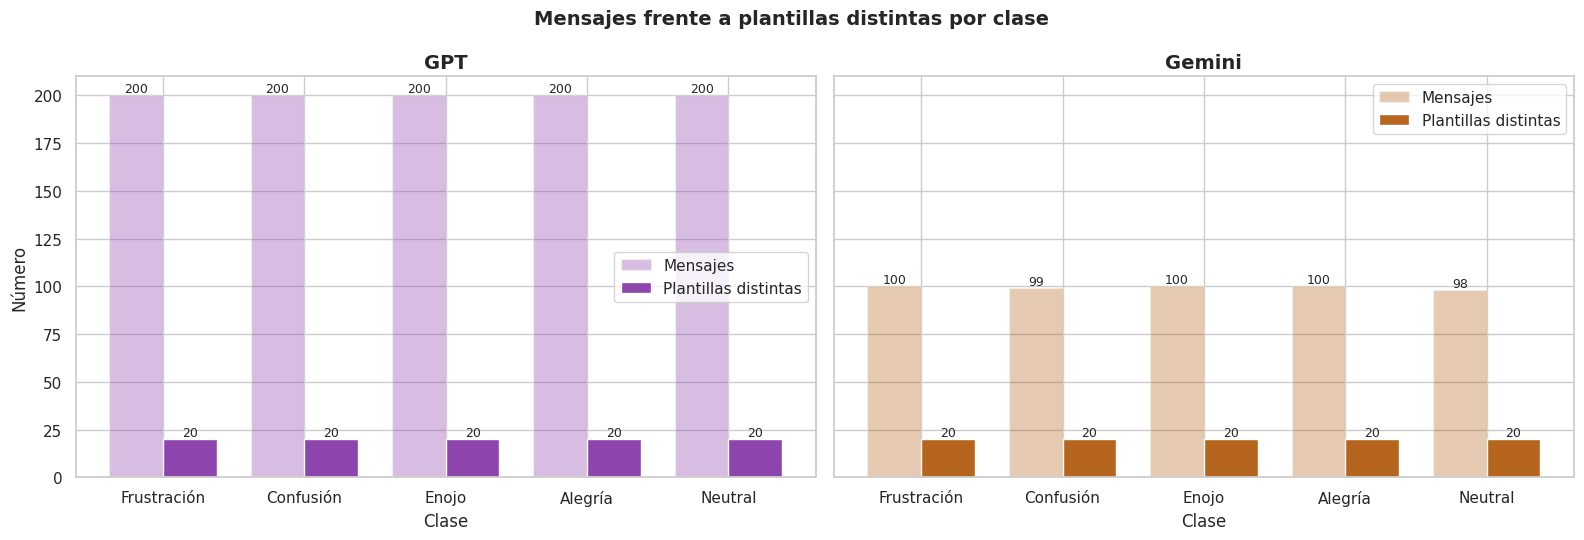

In [44]:
fig, ejes = plt.subplots(1, len(FUENTES_SINTETICAS), figsize=(16, 5.5), sharey=True)
posiciones = np.arange(len(ORDEN_CLASES))
ancho = 0.38
for ax, fuente in zip(ejes, FUENTES_SINTETICAS):
    datos = tabla_plantillas_clase.xs(fuente, level="fuente")
    barras_mensajes = ax.bar(posiciones - ancho / 2, datos["mensajes"], width=ancho,
                             color=PALETA_FUENTES[fuente], alpha=0.35, label="Mensajes")
    barras_plantillas = ax.bar(posiciones + ancho / 2, datos["plantillas distintas"], width=ancho,
                               color=PALETA_FUENTES[fuente], label="Plantillas distintas")
    for barras in (barras_mensajes, barras_plantillas):
        for barra in barras:
            ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(), f"{int(barra.get_height())}",
                    ha="center", va="bottom", fontsize=9)
    ax.set_xticks(posiciones)
    ax.set_xticklabels([NOMBRES_CLASES[c] for c in ORDEN_CLASES])
    ax.set_title(NOMBRES_FUENTES[fuente])
    ax.set_xlabel("Clase")
    ax.legend()
ejes[0].set_ylabel("Número")
fig.suptitle("Mensajes frente a plantillas distintas por clase", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Plantillas compartidas y conflictos de etiqueta.** Se buscan las claves que aparecen en GPT y en Gemini a la vez, y las claves que aparecen con más de una clase (la misma estructura etiquetada, por ejemplo, como frustración en unos mensajes y como confusión en otros).

In [45]:
fuentes_por_plantilla = df_sinteticos_plantilla.groupby("plantilla")["fuente"].nunique()
plantillas_compartidas = fuentes_por_plantilla[fuentes_por_plantilla > 1].index
print(f"Plantillas que aparecen en GPT y en Gemini: {len(plantillas_compartidas)}")
if len(plantillas_compartidas) > 0:
    display(df_sinteticos_plantilla[df_sinteticos_plantilla["plantilla"].isin(plantillas_compartidas)]
            .sort_values(["plantilla", "fuente"])[["plantilla", "fuente", "clase", "texto"]]
            .reset_index(drop=True))

clases_por_plantilla = df_sinteticos_plantilla.groupby("plantilla")["clase"].nunique()
plantillas_en_conflicto = clases_por_plantilla[clases_por_plantilla > 1].index
print(f"\nPlantillas con más de una clase (conflicto de etiqueta): {len(plantillas_en_conflicto)}")
if len(plantillas_en_conflicto) > 0:
    display(df_sinteticos_plantilla[df_sinteticos_plantilla["plantilla"].isin(plantillas_en_conflicto)]
            .sort_values(["plantilla", "clase"])[["plantilla", "clase", "fuente", "texto"]]
            .reset_index(drop=True))

Plantillas que aparecen en GPT y en Gemini: 1


,plantilla,fuente,clase,texto
0,no entiendo nada de {tema},gemini,frustracion,No entiendo nada de derivadas.
1,no entiendo nada de {tema},gemini,frustracion,No entiendo nada del algoritmo.
2,no entiendo nada de {tema},gemini,frustracion,No entiendo nada de la lectura.
3,no entiendo nada de {tema},gemini,frustracion,No entiendo nada del capítulo.
4,no entiendo nada de {tema},gemini,frustracion,No entiendo nada de este módulo.
5,no entiendo nada de {tema},gpt,frustracion,No entiendo nada de la clase de matemáticas.
6,no entiendo nada de {tema},gpt,frustracion,No entiendo nada del tema de álgebra.
7,no entiendo nada de {tema},gpt,frustracion,No entiendo nada de la explicación de hoy.
8,no entiendo nada de {tema},gpt,frustracion,No entiendo nada del ejercicio de física.
9,no entiendo nada de {tema},gpt,frustracion,No entiendo nada de la práctica de programación.



Plantillas con más de una clase (conflicto de etiqueta): 0


**Revisión manual de falsos positivos.** Se muestran 15 grupos de plantilla elegidos al azar, con todas sus variantes, para comprobar que los mensajes agrupados son realmente la misma frase con distinto tema y no mensajes distintos que coinciden por casualidad tras enmascarar.

In [46]:
tamano_plantilla = df_sinteticos_plantilla["plantilla"].value_counts()
plantillas_con_variantes = pd.Series(tamano_plantilla[tamano_plantilla > 1].index)
for plantilla in plantillas_con_variantes.sample(min(15, len(plantillas_con_variantes)), random_state=SEMILLA):
    grupo = df_sinteticos_plantilla[df_sinteticos_plantilla["plantilla"] == plantilla]
    print(f"\n«{plantilla}» — {len(grupo)} variantes | clase: {', '.join(grupo['clase'].unique())} "
          f"| fuente: {', '.join(grupo['fuente'].unique())}")
    for texto in grupo["texto"]:
        print(f"    {texto}")


«siento que mi cerebro no da para entender {tema}» — 7 variantes | clase: frustracion | fuente: gemini
    Siento que mi cerebro no da para entender la fórmula.
    Siento que mi cerebro no da para entender esta unidad.
    Siento que mi cerebro no da para entender este concepto.
    Siento que mi cerebro no da para entender este tema.
    Siento que mi cerebro no da para entender derivadas.
    Siento que mi cerebro no da para entender este módulo.
    Siento que mi cerebro no da para entender la teoría.

«me bloqueo cada vez que intento empezar {tema}» — 8 variantes | clase: frustracion | fuente: gemini
    Me bloqueo cada vez que intento empezar el ensayo.
    Me bloqueo cada vez que intento empezar la tarea.
    Me bloqueo cada vez que intento empezar este problema.
    Me bloqueo cada vez que intento empezar el cuestionario.
    Me bloqueo cada vez que intento empezar esta práctica.
    Me bloqueo cada vez que intento empezar el taller.
    Me bloqueo cada vez que intento empezar

Los 15 grupos revisados son, en todos los casos, la misma frase en la que solo cambia el tema (por ejemplo, «me bloqueo cada vez que intento empezar {tema}» agrupa "el ensayo", "la tarea", "este problema", "el examen"…), y ninguno junta mensajes distintos, así que no fue necesario ajustar la lista de rellenos. La revisión confirma además el relleno mecánico de GPT: los mismos 10 temas aparecen en el mismo orden en todas sus plantillas y producen frases incorrectas como "¡No puedo creer que resolví correctamente todo la clase de matemáticas!" o "La evaluación de la evaluación de inglés está programada para el lunes".

##### Paso 5: eliminación

1. **Conflictos:** se eliminan **todas** las variantes de las plantillas que aparecen con más de una clase, con la misma lógica que en 2.7.2: no se puede saber qué etiqueta es la correcta.
2. **Variantes:** de cada plantilla restante se conserva **un solo mensaje**, elegido al azar con la semilla fija. No se conserva siempre el primero para no favorecer a una misma materia (en GPT, el primer mensaje de cada plantilla es siempre el de "la clase de matemáticas").
3. Si una plantilla aparece en GPT y en Gemini con la misma clase, se conserva **un único mensaje para el conjunto de ambas fuentes**, porque es la misma frase; por eso la selección se hace agrupando solo por la plantilla, sin separar por fuente.

In [47]:
# 1) Conflictos de etiqueta: se eliminan todas las variantes
df_antes = df_limpio
df_limpio = df_limpio[~df_limpio["plantilla"].isin(plantillas_en_conflicto)]
registrar_paso("Conflicto de etiquetas (plantilla)", df_antes, df_limpio)

# 2) y 3) Un mensaje por plantilla, elegido al azar, contando GPT y Gemini juntos
es_sintetico = df_limpio["fuente"].isin(FUENTES_SINTETICAS)
sinteticos_conservados = (
    df_limpio[es_sintetico]
    .groupby("plantilla", group_keys=False)
    .sample(n=1, random_state=SEMILLA)
)
df_antes = df_limpio
df_limpio = pd.concat([df_limpio[~es_sintetico], sinteticos_conservados]).sort_index()
registrar_paso("Variante de plantilla", df_antes, df_limpio)

# Mensajes antes y después por clase y fuente
sinteticos_finales = df_limpio[df_limpio["fuente"].isin(FUENTES_SINTETICAS)]
antes = pd.crosstab(df_sinteticos_plantilla["clase"], df_sinteticos_plantilla["fuente"]).reindex(
    index=ORDEN_CLASES, columns=FUENTES_SINTETICAS, fill_value=0)
despues = pd.crosstab(sinteticos_finales["clase"], sinteticos_finales["fuente"]).reindex(
    index=ORDEN_CLASES, columns=FUENTES_SINTETICAS, fill_value=0)
tabla_eliminacion = pd.concat(
    {"antes": antes, "después": despues, "% eliminado": ((antes - despues) / antes * 100).round(1)}, axis=1)
tabla_eliminacion.loc["Total"] = [
    *antes.sum(), *despues.sum(), *((antes.sum() - despues.sum()) / antes.sum() * 100).round(1)]
tabla_eliminacion

Conflicto de etiquetas (plantilla): 0 filas eliminadas (goemotions = 0, gpt = 0, gemini = 0)
Variante de plantilla: 1,298 filas eliminadas (goemotions = 0, gpt = 900, gemini = 398)


antes        después        % eliminado       
fuente          gpt gemini     gpt gemini         gpt gemini
clase                                                       
frustracion   200.0  100.0    20.0   19.0        90.0   81.0
confusion     200.0   99.0    20.0   20.0        90.0   79.8
enojo         200.0  100.0    20.0   20.0        90.0   80.0
alegria       200.0  100.0    20.0   20.0        90.0   80.0
neutral       200.0   98.0    20.0   20.0        90.0   79.6
Total        1000.0  497.0   100.0   99.0        90.0   80.1

**Materias en los mensajes conservados.** Se comprueba que la selección aleatoria no dejó una materia sobrerrepresentada, contando cuántos mensajes mencionan cada materia antes y después de eliminar las variantes.

antes        después       
fuente                    gpt gemini     gpt gemini
matematicas               100     13      11      4
algebra                   100      0      14      0
calculo                     0     15       0      3
fisica                    100     16      11      3
quimica                   100     10      11      0
estadistica               100      8       5      1
programacion              100     11       9      2
historia                  100     12      11      1
ciencias                  100      0      11      0
ingles                    100     11      11      2
biologia                    0      0       0      0
literatura                  0      0       0      0
contabilidad                0     11       0      1
derivadas                   0     15       0      2
(sin materia explícita)   100    375       6     80

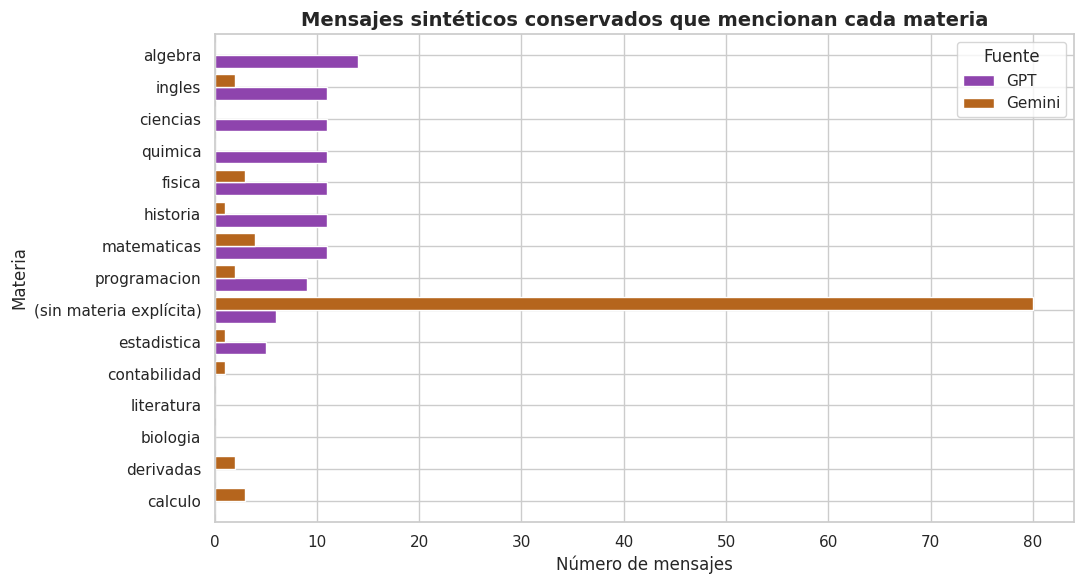

In [48]:
def contar_materias(df):
    texto_comparacion = df["texto"].apply(normalizar_para_comparar)
    menciones = pd.DataFrame({m: texto_comparacion.str.contains(rf"\b{m}\b") for m in MATERIAS})
    menciones["(sin materia explícita)"] = ~menciones.any(axis=1)
    return menciones.groupby(df["fuente"]).sum().T.reindex(columns=FUENTES_SINTETICAS, fill_value=0)


tabla_materias = pd.concat(
    {"antes": contar_materias(df_sinteticos_plantilla), "después": contar_materias(sinteticos_finales)}, axis=1)
display(tabla_materias)

materias_despues = contar_materias(sinteticos_finales)
fig, ax = plt.subplots(figsize=(11, 6))
materias_despues.sort_values("gpt").plot.barh(
    ax=ax, color=[PALETA_FUENTES[f] for f in FUENTES_SINTETICAS], width=0.8)
ax.set_title("Mensajes sintéticos conservados que mencionan cada materia")
ax.set_xlabel("Número de mensajes")
ax.set_ylabel("Materia")
ax.legend([NOMBRES_FUENTES[f] for f in FUENTES_SINTETICAS], title="Fuente")
plt.tight_layout()
plt.show()

**Interpretación.**

- **Mensajes efectivos.** GPT parecía aportar 200 mensajes por clase, pero en realidad tenía 100 plantillas (20 por clase) con exactamente 10 variantes cada una: sus 1.000 mensajes equivalían a 100 mensajes distintos. Gemini tenía 100 plantillas (20 por clase) para sus 497 mensajes (los 500 originales menos los 3 casi duplicados de 2.7.3), con 4,97 variantes de media y un máximo de 11, y solo el 7,0 % de sus mensajes no compartía plantilla con ningún otro. Tras este paso, los sintéticos pasan de 1.497 a 199 mensajes: 100 de GPT y 99 de Gemini. Gemini conserva 99 y no 100 porque su plantilla "no entiendo nada de {tema}" coincide con una de GPT y se conserva un solo mensaje para ambas.
- **Fuente más repetitiva.** GPT es la más repetitiva: el 100,0 % de sus mensajes compartía plantilla, frente al 93,0 % de Gemini. Gemini combina plantillas con algunos mensajes únicos y usa rellenos más variados (materias, tipos de evaluación, conceptos), mientras que GPT usa siempre los mismos 10 temas.
- **Conflictos de etiqueta.** Ninguna plantilla aparece con clases distintas (0 conflictos), así que el primer paso de la eliminación no quitó ningún mensaje. La plantilla compartida "no entiendo nada de {tema}" aparece en GPT y en Gemini etiquetada como **frustración**, aunque "no entiendo" es la expresión típica de la confusión. No es un conflicto dentro de los datos, pero muestra que la frontera entre frustración y confusión depende del criterio del generador, y anticipa confusiones entre ambas clases en la matriz de confusión.
- **Resultado.** Tras este paso, los sintéticos que quedan son **mensajes realmente distintos**, y ya no hay riesgo de que variantes de una misma frase queden en folds distintos de la validación cruzada. La selección aleatoria no dejó ninguna materia sobrerrepresentada: en GPT, cada materia aparece en entre 5 (`estadistica`) y 14 (`algebra`) de los 100 mensajes conservados, y solo 6 no mencionan ninguna; en Gemini, 80 de los 99 mensajes conservados no mencionan una materia explícita (usan rellenos como "este tema" o "la teoría") y ninguna materia supera los 4 mensajes.
- **Lección metodológica.** Un filtro de similitud sobre el texto completo, como el de 2.7.3, no detecta las plantillas generadas por LLMs: en mensajes cortos la parte variable domina la comparación. Ese filtro no eliminó ningún mensaje de GPT, mientras que este paso eliminó 900 (el 90,0 %). Para detectar las plantillas hay que analizar la **estructura** de los mensajes (inicios repetidos, enmascaramiento de la parte variable). Es un hallazgo del proyecto que se recoge en las conclusiones.

#### 2.7.5 Textos muy cortos

Se eliminan los textos vacíos y los que tienen **menos de 3 palabras**. Con una o dos palabras ("Gracias", "Lol", "[NAME] jaja") casi nunca hay contexto suficiente para reconocer una emoción con seguridad, y en un dataset traducido automáticamente estos fragmentos suelen ser los peor traducidos, porque son interjecciones, abreviaturas o jerga. Además, los mensajes que un estudiante escribe a un tutor para expresar confusión o frustración suelen ser frases completas. El umbral de 3 palabras es deliberadamente bajo para eliminar solo los casos claramente insuficientes.

Se comprueba además si la regla afecta de forma desigual a alguna fuente: como los mensajes sintéticos se pidieron como frases completas, se espera que casi todos los textos eliminados provengan de Reddit.

In [49]:
UMBRAL_PALABRAS = 3

n_palabras = df_limpio["texto"].str.split().str.len()
mascara_cortos = n_palabras < UMBRAL_PALABRAS

tabla_cortos = pd.DataFrame({
    "textos": contar_por_fuente(df_limpio),
    f"con menos de {UMBRAL_PALABRAS} palabras": contar_por_fuente(df_limpio[mascara_cortos]),
})
tabla_cortos["% de la fuente"] = (tabla_cortos.iloc[:, 1] / tabla_cortos["textos"] * 100).round(2)
print(f"Textos vacíos: {(n_palabras == 0).sum():,}")
display(tabla_cortos)

print("Textos cortos por clase y fuente:")
display(pd.crosstab(df_limpio.loc[mascara_cortos, "clase"], df_limpio.loc[mascara_cortos, "fuente"])
        .reindex(index=ORDEN_CLASES, columns=ORDEN_FUENTES, fill_value=0))

for fuente in ORDEN_FUENTES:
    cortos_fuente = df_limpio[mascara_cortos & (df_limpio["fuente"] == fuente)]
    print(f"\nEjemplos de textos cortos en {NOMBRES_FUENTES[fuente]}:")
    if cortos_fuente.empty:
        print("  (ninguno)")
    else:
        display(cortos_fuente.sample(min(8, len(cortos_fuente)), random_state=SEMILLA)[["texto", "clase"]])

df_antes = df_limpio
df_limpio = df_limpio[~mascara_cortos]
registrar_paso(f"Texto con menos de {UMBRAL_PALABRAS} palabras", df_antes, df_limpio)

Textos vacíos: 0


,textos,con menos de 3 palabras,% de la fuente
fuente,,,
goemotions,30565,786,2.57
gpt,100,0,0.00
gemini,99,0,0.00


Textos cortos por clase y fuente:


fuente,goemotions,gpt,gemini
clase,,,
frustracion,29,0,0
confusion,12,0,0
enojo,65,0,0
alegria,223,0,0
neutral,457,0,0



Ejemplos de textos cortos en GoEmotions (Reddit):


,texto,clase
30471,Intp:(,neutral
1167,¡Ditto!,alegria
7701,Qué viaje.,alegria
7121,Perfecto. ¡Gracias!,alegria
8525,¿Qué decía?,neutral
7826,¡Precisa! Gracias.,alegria
21990,"Oh, Dios...",neutral
24016,Gran espectáculo.,alegria



Ejemplos de textos cortos en GPT:
  (ninguno)

Ejemplos de textos cortos en Gemini:
  (ninguno)
Texto con menos de 3 palabras: 786 filas eliminadas (goemotions = 786, gpt = 0, gemini = 0)


#### 2.7.6 Marcadores de Reddit y URLs

El dataset original anonimiza los nombres de personas y de religiones con marcadores entre corchetes, como `[NAME]` o `[RELIGION]`. Al traducir, el sistema a veces los dejó en inglés y a veces los tradujo (por ejemplo, `[NOMBRE]` o `[RELIGIÓN]`), así que se cuentan todas sus variantes. También se buscan URLs. Ambos se cuentan por fuente: se espera que solo aparezcan en GoEmotions.

In [50]:
PATRON_MARCADOR = r"\[[^\[\]\s]{2,20}\]"
PATRON_URL = r"https?://\S+|www\.\S+"

marcadores = df_limpio["texto"].str.findall(PATRON_MARCADOR).explode().dropna()
print("Marcadores entre corchetes encontrados:")
display(marcadores.value_counts().rename_axis("marcador").to_frame("apariciones").head(20))

print("Textos con marcadores o URLs por fuente:")
display(pd.DataFrame({
    "textos con marcador": contar_por_fuente(df_limpio[df_limpio["texto"].str.contains(PATRON_MARCADOR)]),
    "textos con URL": contar_por_fuente(df_limpio[df_limpio["texto"].str.contains(PATRON_URL)]),
}))

Marcadores entre corchetes encontrados:


,apariciones
marcador,
[NAME],5062
[NOMBRE],461
[RELIGION],47
[RELIGIÓN],26
[NAM],3
[goshdarn],1
[get_user_id],1
[{respuesta}],1
[...],1


Textos con marcadores o URLs por fuente:


,textos con marcador,textos con URL
fuente,,
goemotions,4309,0
gpt,0,0
gemini,0,0


**Decisión.** Los marcadores **se conservan, pero se normalizan** a una única forma en español:

- `[NAME]`, `[NAM]` y `[NOMBRE]` → `[NOMBRE]`
- `[RELIGION]` y `[RELIGIÓN]` → `[RELIGIÓN]`

Se conservan porque forman parte de la estructura de la frase (por ejemplo, "Gracias, [NOMBRE]"), y eliminarlos dejaría oraciones incompletas que el encoder interpretaría peor. Se normalizan porque tener dos o tres variantes del mismo marcador hace que textos equivalentes produzcan embeddings distintos solo por un detalle de la traducción. Se elige la forma en español porque el resto del texto está en español. Los demás textos entre corchetes que aparecen pocas veces (por ejemplo, `[risas]`) son palabras normales del comentario y no se modifican.

Las URLs, si aparecen, se reemplazan por el marcador `[URL]`, porque su contenido (direcciones concretas) no aporta información emocional.

Fuera de esto, el texto no se modifica (no se pasa a minúsculas ni se quitan stopwords), por la razón explicada al inicio de 2.7.

In [51]:
df_limpio = df_limpio.copy()
for patron, reemplazo in REEMPLAZOS_MARCADORES.items():
    df_limpio["texto"] = df_limpio["texto"].str.replace(patron, reemplazo, regex=True)
df_limpio["texto"] = df_limpio["texto"].str.replace(PATRON_URL, "[URL]", regex=True)

marcadores_despues = df_limpio["texto"].str.findall(PATRON_MARCADOR).explode().dropna()
print("Marcadores más frecuentes después de normalizar:")
display(marcadores_despues.value_counts().rename_axis("marcador").to_frame("apariciones").head(5))

# Comprobación de seguridad: la normalización no debe haber creado nuevos duplicados exactos
clases_por_texto = df_limpio.groupby("texto")["clase"].nunique()
df_antes = df_limpio
df_limpio = df_limpio[~df_limpio["texto"].isin(clases_por_texto[clases_por_texto > 1].index)]
df_limpio = df_limpio.drop_duplicates(subset="texto", keep="first").reset_index(drop=True)
registrar_paso("Duplicado creado al normalizar marcadores", df_antes, df_limpio)

Marcadores más frecuentes después de normalizar:


,apariciones
marcador,
[NOMBRE],5526
[RELIGIÓN],73
[goshdarn],1
[get_user_id],1
[{respuesta}],1


Duplicado creado al normalizar marcadores: 0 filas eliminadas (goemotions = 0, gpt = 0, gemini = 0)


#### 2.7.7 Resumen de la limpieza por fuente

In [52]:
filas_inicio = contar_por_fuente(df_unificado)
filas_fin = contar_por_fuente(df_limpio)

resumen_limpieza = pd.concat([
    pd.DataFrame([{**filas_inicio.to_dict(), "total": int(filas_inicio.sum())}], index=["Filas al inicio de la limpieza"]),
    pd.DataFrame(registro_limpieza).set_index("paso")[ORDEN_FUENTES + ["total"]],
    pd.DataFrame([{**filas_fin.to_dict(), "total": int(filas_fin.sum())}], index=["Filas tras la limpieza"]),
])
porcentaje_eliminado = (filas_inicio - filas_fin) / filas_inicio * 100
resumen_limpieza.loc["% eliminado"] = [
    *porcentaje_eliminado.round(2), round((filas_inicio.sum() - filas_fin.sum()) / filas_inicio.sum() * 100, 2)
]
resumen_limpieza.rename_axis("paso")

,goemotions,gpt,gemini,total
paso,,,,
Filas al inicio de la limpieza,31578.0,1000.0,500.0,33078.00
"Limpieza del ruido de traducción (modifica textos, no elimina filas)",0.0,0.0,0.0,0.00
Conflicto de etiquetas (texto exacto),141.0,0.0,0.0,141.00
Duplicado exacto,304.0,0.0,0.0,304.00
Conflicto de etiquetas (texto normalizado),69.0,0.0,0.0,69.00
Duplicado tras normalizar el texto,182.0,0.0,0.0,182.00
Casi duplicado (similitud TF-IDF >= 0.9),317.0,0.0,3.0,320.00
Conflicto de etiquetas (plantilla),0.0,0.0,0.0,0.00
Variante de plantilla,0.0,900.0,398.0,1298.00


**Cifras clave de 2.7**

- Ruido de la traducción (2.7.1): 1.250 textos de GoEmotions modificados (4,0 %), 150.365 caracteres eliminados; GPT y Gemini sin cambios. Máximo de palabras: 538 antes → 75 después. 33 textos quedaron con menos de 3 palabras y 14 quedaron vacíos; se eliminaron en los pasos siguientes (2.7.2 a 2.7.5).
- Filas al inicio: GoEmotions = 31.578, GPT = 1.000, Gemini = 500 → tras la limpieza: GoEmotions = 29.779, GPT = 100, Gemini = 99.
- Porcentaje eliminado por fuente: GoEmotions = 5,7 %, GPT = 90,0 %, Gemini = 80,2 % (9,4 % del total).
- Duplicados exactos entre fuentes: 0 (dentro de GoEmotions: 405; se eliminaron 141 filas por conflicto de etiquetas y 304 duplicados). Casi duplicados eliminados: 320 (de ellos, 0 en GPT y 3 en Gemini).
- Plantillas (2.7.4): GPT pasa de 1.000 mensajes a 100 (una por plantilla) y Gemini de 497 a 99. Conflictos de etiqueta por plantilla: 0.
- Textos con menos de 3 palabras: 786 (todos de GoEmotions). Textos con marcadores: 4.309. Textos con URL: 0.

### 2.8 Distribución de clases por fuente

Se cuantifica el desbalance entre las cinco clases y la contribución de cada fuente a cada clase. Esto condiciona la métrica de evaluación, la estrategia de balanceo y el riesgo de que el modelo aprenda el estilo de un generador en lugar de la emoción.

In [53]:
tabla_clase_fuente = pd.crosstab(df_limpio["clase"], df_limpio["fuente"], margins=True, margins_name="Total")
tabla_clase_fuente = tabla_clase_fuente.reindex(index=ORDEN_CLASES + ["Total"], columns=ORDEN_FUENTES + ["Total"],
                                                fill_value=0)
tabla_clase_fuente

fuente,goemotions,gpt,gemini,Total
clase,,,,
frustracion,2639,20,19,2678
confusion,1031,20,20,1071
enojo,1772,20,20,1812
alegria,9069,20,20,9109
neutral,15268,20,20,15308
Total,29779,100,99,29978


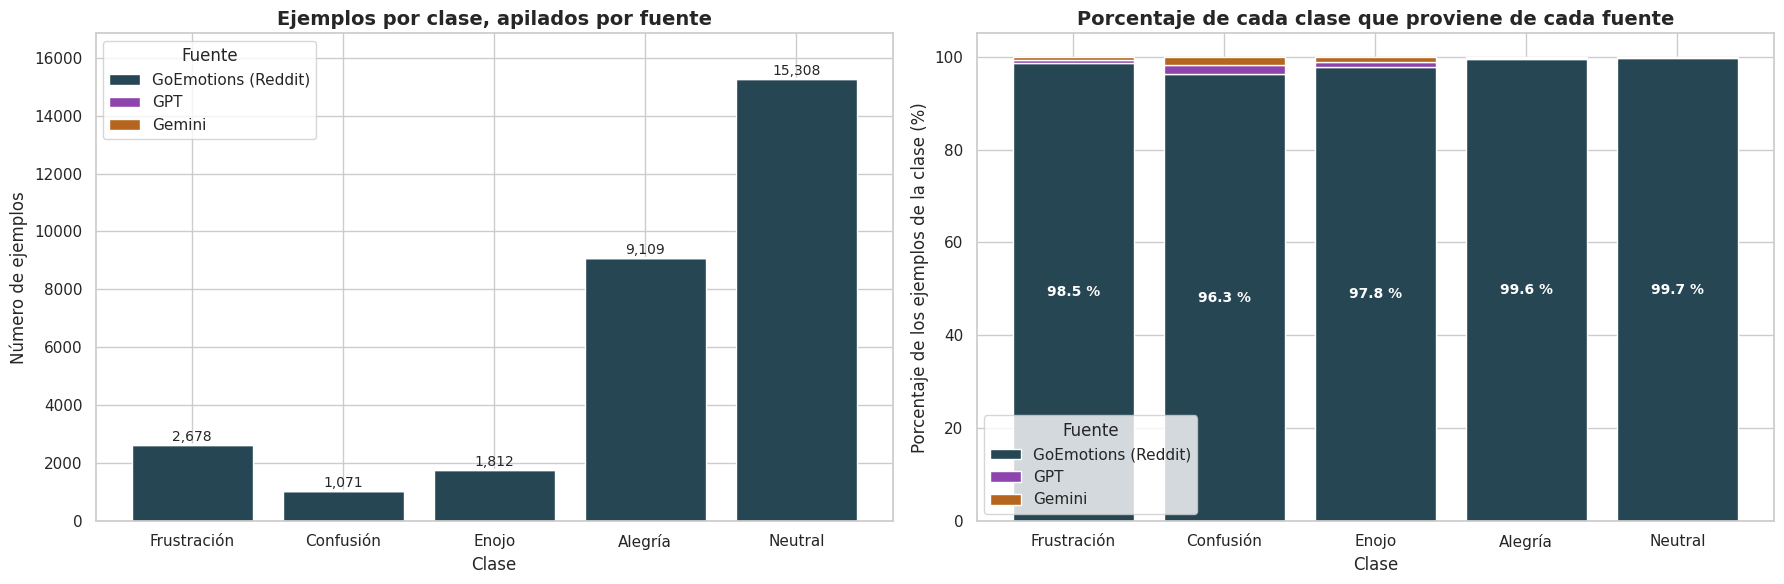

Porcentaje de los ejemplos de cada clase que proviene de cada fuente:


fuente,goemotions,gpt,gemini,sintéticos (GPT + Gemini)
clase,,,,
frustracion,98.54,0.75,0.71,1.46
confusion,96.27,1.87,1.87,3.74
enojo,97.79,1.10,1.10,2.20
alegria,99.56,0.22,0.22,0.44
neutral,99.74,0.13,0.13,0.26


In [54]:
def barras_apiladas_por_fuente(df, ax, titulo, porcentaje=False):
    """Barras por clase apiladas por fuente (conteos o porcentaje dentro de cada clase)."""
    tabla = pd.crosstab(df["clase"], df["fuente"]).reindex(index=ORDEN_CLASES, columns=ORDEN_FUENTES, fill_value=0)
    if porcentaje:
        tabla = tabla.div(tabla.sum(axis=1), axis=0) * 100
    nombres = [NOMBRES_CLASES[c] for c in ORDEN_CLASES]
    base = np.zeros(len(tabla))
    for fuente in ORDEN_FUENTES:
        valores = tabla[fuente].to_numpy(dtype=float)
        ax.bar(nombres, valores, bottom=base, color=PALETA_FUENTES[fuente], label=NOMBRES_FUENTES[fuente])
        if porcentaje:
            for x, (valor, inicio) in enumerate(zip(valores, base)):
                if valor >= 4:
                    ax.text(x, inicio + valor / 2, f"{valor:.1f} %", ha="center", va="center",
                            color="white", fontsize=10, fontweight="bold")
        base += valores
    if not porcentaje:
        for x, total in enumerate(base):
            ax.text(x, total, f"{int(total):,}", ha="center", va="bottom", fontsize=10)
        ax.set_ylim(0, base.max() * 1.1)
    ax.set_title(titulo)
    ax.set_xlabel("Clase")
    ax.set_ylabel("Porcentaje de los ejemplos de la clase (%)" if porcentaje else "Número de ejemplos")
    ax.legend(title="Fuente")
    return tabla


fig, ejes = plt.subplots(1, 2, figsize=(18, 6))
barras_apiladas_por_fuente(df_limpio, ejes[0], "Ejemplos por clase, apilados por fuente")
tabla_porcentaje_fuente = barras_apiladas_por_fuente(
    df_limpio, ejes[1], "Porcentaje de cada clase que proviene de cada fuente", porcentaje=True)
plt.tight_layout()
plt.show()

tabla_porcentaje_fuente = tabla_porcentaje_fuente.round(2)
tabla_porcentaje_fuente["sintéticos (GPT + Gemini)"] = tabla_porcentaje_fuente["gpt"] + tabla_porcentaje_fuente["gemini"]
print("Porcentaje de los ejemplos de cada clase que proviene de cada fuente:")
display(tabla_porcentaje_fuente.rename_axis("clase"))

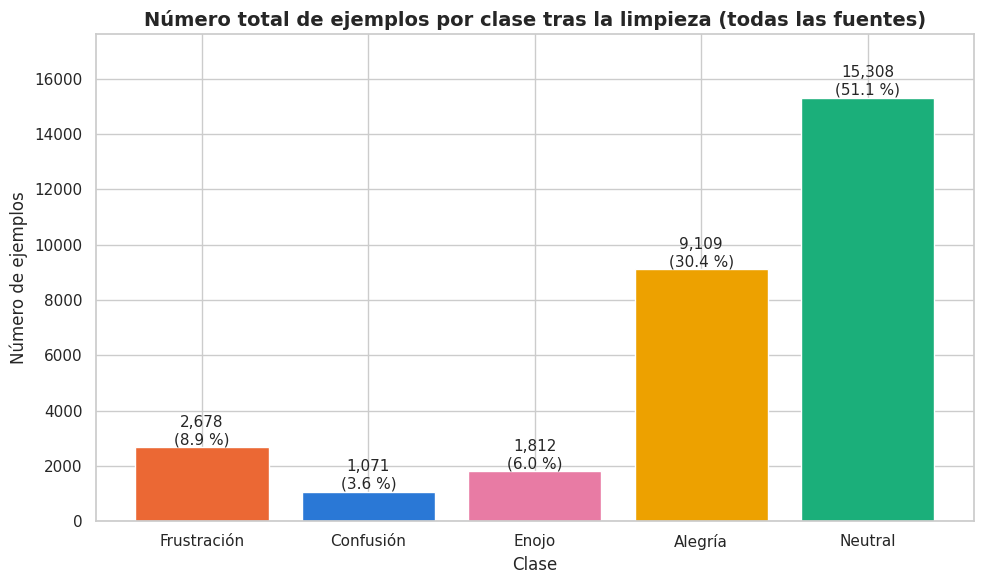

Clase mayoritaria: neutral (15,308 ejemplos)
Clase minoritaria: confusion (1,071 ejemplos)
Ratio de desbalance (mayoritaria / minoritaria): 14.3
Exactitud de un clasificador que siempre predice 'neutral': 51.1%


In [55]:
conteo_clases = df_limpio["clase"].value_counts().reindex(ORDEN_CLASES)
porcentaje_clases = conteo_clases / conteo_clases.sum() * 100

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.bar([NOMBRES_CLASES[c] for c in ORDEN_CLASES], conteo_clases.values,
                color=[PALETA_CLASES[c] for c in ORDEN_CLASES])
for barra, n, pct in zip(barras, conteo_clases.values, porcentaje_clases.values):
    ax.annotate(f"{n:,}\n({pct:.1f} %)", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha="center", va="bottom", fontsize=11)
ax.set_title("Número total de ejemplos por clase tras la limpieza (todas las fuentes)")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de ejemplos")
ax.set_ylim(0, conteo_clases.max() * 1.15)
plt.tight_layout()
plt.show()

ratio_desbalance = conteo_clases.max() / conteo_clases.min()
print(f"Clase mayoritaria: {conteo_clases.idxmax()} ({conteo_clases.max():,} ejemplos)")
print(f"Clase minoritaria: {conteo_clases.idxmin()} ({conteo_clases.min():,} ejemplos)")
print(f"Ratio de desbalance (mayoritaria / minoritaria): {ratio_desbalance:.1f}")
print(f"Exactitud de un clasificador que siempre predice '{conteo_clases.idxmax()}': "
      f"{conteo_clases.max() / conteo_clases.sum():.1%}")

**Interpretación.** La clase mayoritaria es `neutral`, con 15.308 ejemplos (51,1 %), y la minoritaria es `confusion`, con 1.071 ejemplos (3,6 %), lo que da un ratio de desbalance de 14,3. Casi todo el desbalance viene de GoEmotions: los sintéticos están balanceados (tras eliminar las variantes de plantilla en 2.7.4 quedan 20 mensajes por clase y fuente, salvo frustración en Gemini, con 19), pero son tan pocos que apenas se ven en el gráfico de conteos.

Este análisis tiene tres consecuencias para el resto del proyecto:

- **La exactitud (*accuracy*) no es una métrica adecuada.** Un clasificador que prediga siempre la clase mayoritaria obtendría una exactitud de 51,1 % sin haber aprendido nada, y fallaría precisamente en las clases minoritarias, que son las más importantes para el tutor (frustración, confusión, enojo). Por eso la métrica principal será el **F1-macro**, que calcula el F1 de cada clase por separado y los promedia sin ponderar, de modo que todas las clases pesan lo mismo sin importar cuántos ejemplos tengan.
- **Se necesita una estrategia de balanceo**, que se define en la subsección 2.13.
- **Dependencia de los datos sintéticos.** La clase en la que una mayor proporción de los ejemplos proviene de GPT y Gemini es confusión, con un 3,7 % de ejemplos sintéticos, seguida de enojo (2,2 %); en neutral son solo el 0,3 %. Son las clases con más riesgo de que el modelo aprenda el **estilo del generador** (sus frases típicas) en lugar de la emoción, aunque tras la eliminación de las plantillas los sintéticos son una fracción pequeña de todas las clases. Esta proporción aumentará tras el balanceo de 2.13, porque se submuestrea GoEmotions y los sintéticos se conservan completos.

**Cifras clave de 2.8**

- Ejemplos por clase tras la limpieza: frustración = 2.678, confusión = 1.071, enojo = 1.812, alegría = 9.109, neutral = 15.308.
- Ratio de desbalance: 14,3. Porcentaje de ejemplos sintéticos por clase: de 0,3 % (`neutral`) a 3,7 % (`confusion`).

### 2.9 Longitud de los textos por clase y fuente

Se caracteriza la longitud de los textos por tres motivos:

1. Comprobar si la longitud por sí sola ya distingue las clases o las fuentes. Si así fuera, el modelo podría aprender un atajo (por ejemplo, "los textos largos son sintéticos y por tanto de una clase concreta") en lugar del contenido.
2. Detectar diferencias de estilo entre los datos reales y los sintéticos.
3. Verificar que los textos caben en el límite de entrada del encoder.

Se calcula el número de palabras y de caracteres de cada texto en una copia (`df_longitud`). El coeficiente de variación (desviación estándar / media) permite comparar la homogeneidad de las longitudes entre fuentes aunque sus medias sean distintas.

In [56]:
df_longitud = df_limpio[["texto", "clase", "fuente"]].copy()
df_longitud["n_palabras"] = df_longitud["texto"].str.split().str.len()
df_longitud["n_caracteres"] = df_longitud["texto"].str.len()


def percentil(q):
    funcion = lambda serie: serie.quantile(q)
    funcion.__name__ = f"p{int(q * 100)}"
    return funcion


AGREGACIONES = ["mean", "median", "std", "min", "max", percentil(0.25), percentil(0.75), percentil(0.95)]
NOMBRES_ESTADISTICOS = {"mean": "media", "median": "mediana", "std": "desv_est", "min": "mínimo", "max": "máximo"}

estadisticos_fuente = (
    df_longitud.groupby("fuente")[["n_palabras", "n_caracteres"]].agg(AGREGACIONES)
    .reindex(ORDEN_FUENTES).round(1)
    .rename(columns=NOMBRES_ESTADISTICOS, level=1)
)
estadisticos_fuente.columns = estadisticos_fuente.columns.set_names(["medida", "estadístico"])
print("Estadísticos de longitud por fuente:")
display(estadisticos_fuente)

coef_variacion = (
    df_longitud.groupby("fuente")["n_palabras"].std() / df_longitud.groupby("fuente")["n_palabras"].mean()
).reindex(ORDEN_FUENTES).round(2)
print("Coeficiente de variación del número de palabras por fuente:")
display(coef_variacion.rename("coef_variacion").to_frame())

print("Número de palabras por clase y fuente:")
display(
    df_longitud.groupby(["clase", "fuente"])["n_palabras"].agg(AGREGACIONES)
    .reindex(pd.MultiIndex.from_product([ORDEN_CLASES, ORDEN_FUENTES], names=["clase", "fuente"]))
    .rename(columns=NOMBRES_ESTADISTICOS).round(1)
)

Estadísticos de longitud por fuente:


medida      n_palabras                                                   \
estadístico      media mediana desv_est mínimo máximo   p25   p75   p95   
fuente                                                                    
goemotions        13.3    13.0      7.0      3     75   7.0  18.0  26.0   
gpt               11.8    12.0      1.7      7     16  11.0  13.0  15.0   
gemini            10.3    10.0      1.5      7     13   9.0  11.0  13.0   

medida      n_caracteres                                                     
estadístico        media mediana desv_est mínimo máximo   p25    p75    p95  
fuente                                                                       
goemotions          76.0    71.0     40.1      5    743  43.0  104.0  147.0  
gpt                 69.0    69.5      8.8     45     87  63.0   75.0   83.0  
gemini              58.2    58.0      8.4     34     79  52.0   63.0   71.2

Coeficiente de variación del número de palabras por fuente:


,coef_variacion
fuente,
goemotions,0.52
gpt,0.14
gemini,0.15


Número de palabras por clase y fuente:


media  mediana  desv_est  mínimo  máximo   p25   p75  \
clase       fuente                                                             
frustracion goemotions   14.6     14.0       6.8       3      57   9.0  20.0   
            gpt          11.6     12.0       1.7       7      14  10.8  13.0   
            gemini       10.0     10.0       1.6       7      13   9.0  11.0   
confusion   goemotions   14.8     15.0       6.6       3      33  10.0  20.0   
            gpt          12.8     12.0       1.5      11      16  12.0  14.0   
            gemini       11.0     11.0       1.6       8      13   9.8  12.0   
enojo       goemotions   12.8     12.0       7.0       3      34   7.0  18.0   
            gpt          12.8     13.0       1.6      10      16  12.0  14.0   
            gemini       10.2     10.0       1.3       8      12   9.0  11.0   
alegria     goemotions   12.8     12.0       6.8       3      42   7.0  18.0   
            gpt          11.3     11.0       1.7       8      14  10.8  13.0   
            gemini        9.6      9.0       1.4       7      12   9.0  11.0   
neutral     goemotions   13.4     13.0       7.1       3      75   7.0  19.0   
            gpt          10.8     11.0       1.0       9      12  10.0  11.2   
            gemini       10.6     10.0       1.5       8      13  10.0  12.0   

                         p95  
clase       fuente            
frustracion goemotions  26.0  
            gpt         14.0  
            gemini      12.1  
confusion   goemotions  26.0  
            gpt         15.0  
            gemini      13.0  
enojo       goemotions  25.0  
            gpt         15.0  
            gemini      12.0  
alegria     goemotions  25.0  
            gpt         14.0  
            gemini      12.0  
neutral     goemotions  26.0  
            gpt         12.0  
            gemini      13.0

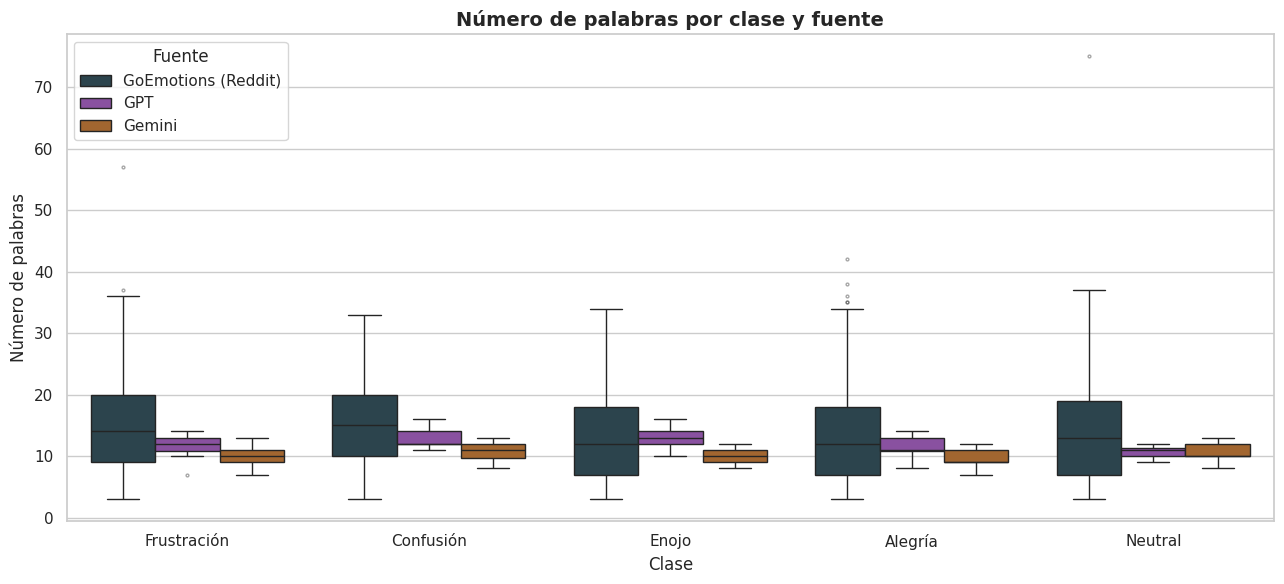

In [57]:
fig, ax = plt.subplots(figsize=(13, 6))
sns.boxplot(data=df_longitud, x="clase", y="n_palabras", hue="fuente",
            order=ORDEN_CLASES, hue_order=ORDEN_FUENTES, palette=PALETA_FUENTES,
            flierprops={"markersize": 2, "alpha": 0.4}, ax=ax)
ax.set_xticks(range(len(ORDEN_CLASES)))
ax.set_xticklabels([NOMBRES_CLASES[c] for c in ORDEN_CLASES])
manejadores, _ = ax.get_legend_handles_labels()
ax.legend(manejadores, [NOMBRES_FUENTES[f] for f in ORDEN_FUENTES], title="Fuente")
ax.set_title("Número de palabras por clase y fuente")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de palabras")
plt.tight_layout()
plt.show()

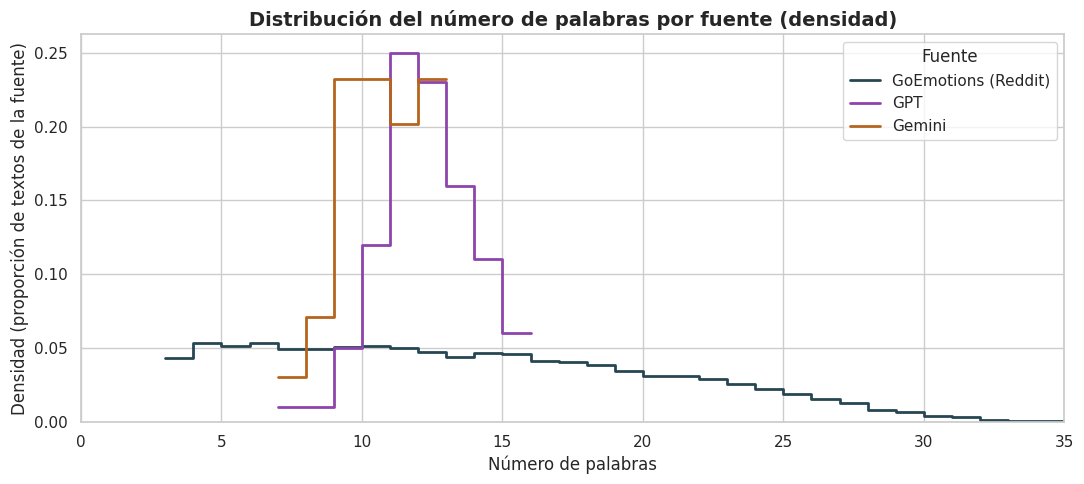

In [58]:
fig, ax = plt.subplots(figsize=(11, 5))
for fuente in ORDEN_FUENTES:
    datos = df_longitud.loc[df_longitud["fuente"] == fuente, "n_palabras"]
    sns.histplot(datos, binwidth=1, stat="density", element="step", fill=False, linewidth=2,
                 color=PALETA_FUENTES[fuente], label=NOMBRES_FUENTES[fuente], ax=ax)
ax.set_xlim(0, df_longitud["n_palabras"].quantile(0.99) + 5)
ax.set_title("Distribución del número de palabras por fuente (densidad)")
ax.set_xlabel("Número de palabras")
ax.set_ylabel("Densidad (proporción de textos de la fuente)")
ax.legend(title="Fuente")
plt.tight_layout()
plt.show()

In [59]:
LIMITE_TOKENS = 128
p95_palabras = df_longitud["n_palabras"].quantile(0.95)

print(f"Percentil 95 del número de palabras (todas las fuentes): {p95_palabras:.0f}")
print("Percentil 95 por fuente:")
print(df_longitud.groupby("fuente")["n_palabras"].quantile(0.95).reindex(ORDEN_FUENTES).to_string())
print(f"\nMáximo número de palabras: {df_longitud['n_palabras'].max()}")
print(f"Incluso suponiendo 2 tokens por palabra, el percentil 95 equivale a unos {2 * p95_palabras:.0f} tokens "
      f"(límite habitual del encoder: {LIMITE_TOKENS} tokens).")
print(f"Textos con más de {LIMITE_TOKENS // 2} palabras (posible truncación): "
      f"{(df_longitud['n_palabras'] > LIMITE_TOKENS // 2).sum():,}")

Percentil 95 del número de palabras (todas las fuentes): 26
Percentil 95 por fuente:
fuente
goemotions    26.0
gpt           15.0
gemini        13.0

Máximo número de palabras: 75
Incluso suponiendo 2 tokens por palabra, el percentil 95 equivale a unos 52 tokens (límite habitual del encoder: 128 tokens).
Textos con más de 64 palabras (posible truncación): 1


**Interpretación.**

- **Homogeneidad.** Los textos sintéticos tienen longitudes mucho más homogéneas que los de Reddit: su coeficiente de variación es de 0,14 (GPT) y 0,15 (Gemini), frente a 0,52 en GoEmotions. La mitad central de los mensajes de GPT tiene entre 11 y 13 palabras y la de Gemini entre 9 y 11 (con rangos completos de 7 a 16 y de 7 a 13 palabras), mientras que en GoEmotions el rango intercuartílico va de 7 a 18 palabras y el máximo llega a 75. Es otra señal de un estilo artificial: los generadores escriben siempre frases de una longitud parecida.
- **Diferencias entre fuentes.** La mediana de los sintéticos (12 palabras en GPT y 10 en Gemini) es algo menor que la de Reddit (13), y sus valores quedan dentro del rango central de GoEmotions, así que la longitud típica no separa las fuentes. Su dispersión sí lo hace en los extremos: ningún mensaje sintético tiene más de 16 palabras, de modo que un texto más largo solo puede venir de GoEmotions. Esto se revisará en el t-SNE coloreado por fuente.
- **Diferencias entre clases.** En GoEmotions, confusión (mediana de 15 palabras) y frustración (14) tienen textos algo más largos que enojo y alegría (12) y neutral (13), pero las distribuciones se solapan casi por completo (los percentiles 95 de todas las clases están entre 25 y 26 palabras). La longitud por sí sola no distingue las clases, así que el modelo tendrá que basarse en el contenido.

**Efecto de la limpieza del ruido de traducción (2.7.1).** Antes de esa limpieza, el máximo de GoEmotions era de 538 palabras, y casi todos los textos muy largos eran en realidad cadenas de `*`, `♪` o `¡` que contaban como palabras. Tras la limpieza y los filtros de 2.7, el máximo es de 75 palabras y la desviación estándar de GoEmotions es de 7,0 palabras: las estadísticas de esta subsección ya no incluyen ese ruido, y los comentarios anteriores se basan en estas cifras.

**Truncación.** Los modelos Sentence-BERT suelen truncar la entrada a 128 tokens. El número exacto de tokens depende del tokenizador del encoder que se elija, pero en español una palabra suele dividirse en uno o dos tokens. Con un percentil 95 de 26 palabras (unos 52 tokens en el peor caso), la gran mayoría de los textos cabe completa en el límite y la truncación no será un problema; solo 1 texto supera las 64 palabras.

**Cifras clave de 2.9**

- Mediana de palabras: GoEmotions = 13, GPT = 12, Gemini = 10. Percentil 95 global: 26 palabras. Máximo: 75 palabras.
- Coeficiente de variación: GoEmotions = 0,52, GPT = 0,14, Gemini = 0,15.

### 2.10 Vocabulario por clase y fuente

Se analiza qué palabras caracterizan a cada clase, para comprobar que el contenido es coherente con la etiqueta, detectar vocabulario de dominios ajenos al educativo y encontrar **muletillas** de los generadores: frases que se repiten en muchos mensajes sintéticos.

**Normalización solo para el análisis.** Para contar palabras de forma significativa, aquí (y solo aquí, no para el modelo) se aplica una normalización mínima: paso a minúsculas, eliminación de la puntuación y de los números, eliminación de los marcadores (`[NOMBRE]`, `[RELIGIÓN]`, `[URL]`) y eliminación de las *stopwords* en español de la lista de spaCy. Sin esto, las palabras más frecuentes de todas las clases serían "de", "que" o "la", que no dicen nada sobre la emoción. El texto que se usará para el modelo (`texto`) no se modifica.

In [60]:
from spacy.lang.es.stop_words import STOP_WORDS

STOPWORDS_ES = {palabra.lower() for palabra in STOP_WORDS}


def normalizar_para_analisis(texto):
    # Normalización mínima, solo para el análisis de vocabulario
    texto = re.sub(PATRON_MARCADOR, " ", texto)      # quitar marcadores como [NOMBRE]
    texto = texto.lower()
    texto = re.sub(r"[^\w\s]|\d|_", " ", texto)      # quitar puntuación, números y guiones bajos
    return [palabra for palabra in texto.split() if palabra not in STOPWORDS_ES and len(palabra) > 1]


df_vocabulario = df_limpio[["texto", "clase", "fuente"]].copy()
df_vocabulario["tokens"] = df_vocabulario["texto"].apply(normalizar_para_analisis)
df_vocabulario["texto_normalizado"] = df_vocabulario["tokens"].str.join(" ")

print(f"Stopwords en español (spaCy): {len(STOPWORDS_ES)}")
df_vocabulario.groupby("fuente", group_keys=False).sample(2, random_state=SEMILLA)[["fuente", "texto", "texto_normalizado"]]

Stopwords en español (spaCy): 521


,fuente,texto,texto_normalizado
29941,gemini,"¡Ya la libré, aprobé el semestre sin irme a final!",libré aprobé semestre irme
29919,gemini,No estoy seguro de si estoy usando el método correcto para el proyecto.,seguro usando método correcto proyecto
20631,goemotions,Ninguna en la mía.,
8387,goemotions,"Es un pensamiento encantador, realmente impresionante de tu parte. No lo sé personalmente, pero podrías intentar contactar con la Asociación Internacional de Mujeres de Seúl (SIWA).",pensamiento encantador realmente impresionante personalmente podrías intentar contactar asociación internacional mujeres seúl siwa
29798,gpt,Me desespera no poder hacer bien el problema de estadística.,desespera problema estadística
29784,gpt,Estoy bloqueado; no sé ni por dónde empezar con la evaluación de inglés.,bloqueado empezar evaluación inglés


#### 2.10.1 Palabras más frecuentes por clase (dataset unificado)

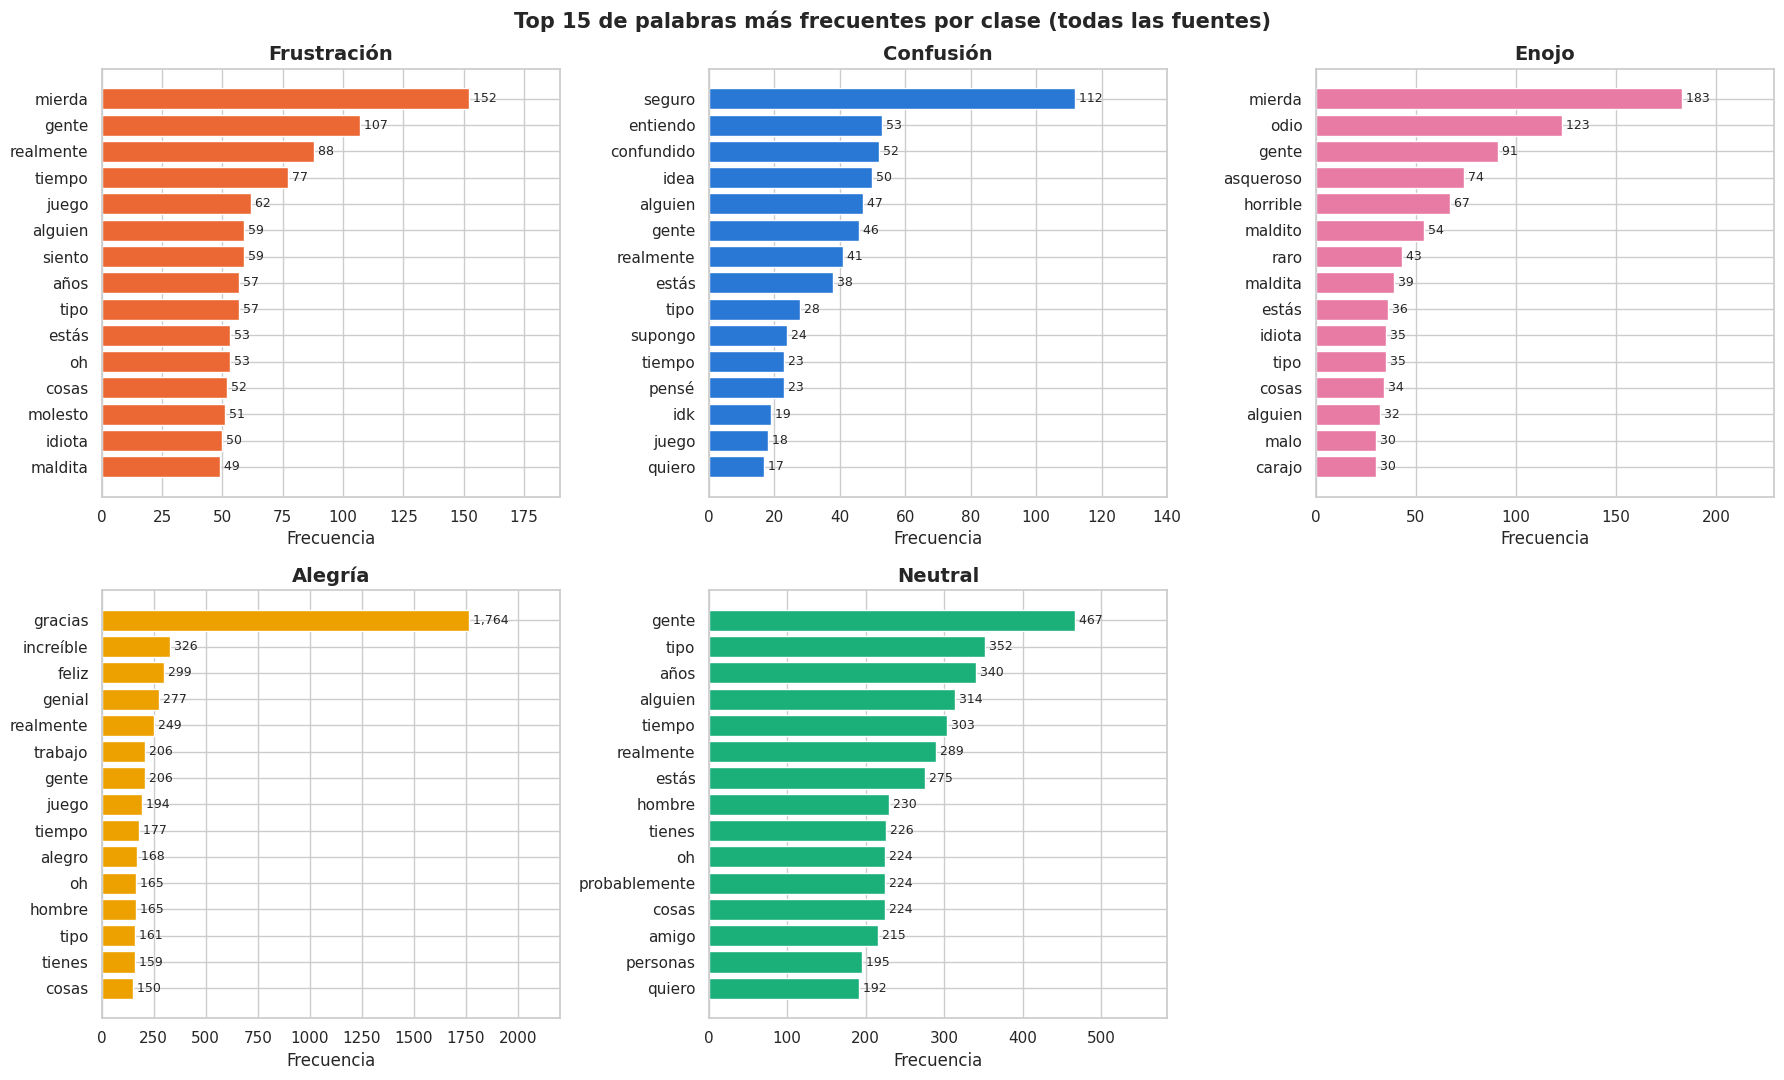

In [61]:
TOP_PALABRAS = 15


def graficar_top_por_clase(top_por_clase, titulo, etiqueta_x, formato="{:,.0f}"):
    fig, ejes = plt.subplots(2, 3, figsize=(18, 11))
    ejes = ejes.flatten()
    for ax, clase in zip(ejes, ORDEN_CLASES):
        datos = top_por_clase[clase].sort_values()
        ax.barh(datos.index, datos.values, color=PALETA_CLASES[clase])
        for i, valor in enumerate(datos.values):
            ax.text(valor, i, " " + formato.format(valor), va="center", fontsize=9)
        ax.set_xlim(0, datos.max() * 1.25)
        ax.set_title(NOMBRES_CLASES[clase])
        ax.set_xlabel(etiqueta_x)
    ejes[-1].axis("off")
    fig.suptitle(titulo, fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()


top_frecuencia = {
    clase: pd.Series(Counter(
        palabra for tokens in df_vocabulario.loc[df_vocabulario["clase"] == clase, "tokens"] for palabra in tokens
    )).nlargest(TOP_PALABRAS)
    for clase in ORDEN_CLASES
}
graficar_top_por_clase(top_frecuencia, f"Top {TOP_PALABRAS} de palabras más frecuentes por clase (todas las fuentes)",
                       "Frecuencia")

Como GoEmotions tiene muchos más textos que los sintéticos, la frecuencia del dataset unificado refleja sobre todo el vocabulario de Reddit. Para compararlo con el de GPT y Gemini se usa el TF-IDF promedio (que destaca el vocabulario propio de cada clase) y, a continuación, el desglose por fuente.

#### 2.10.2 Palabras características por clase según TF-IDF promedio

La frecuencia cruda favorece las palabras comunes a todas las clases. El **TF-IDF** reduce el peso de las palabras que aparecen en muchos textos, así que el promedio del TF-IDF de cada palabra dentro de una clase destaca mejor el vocabulario propio de esa clase. Se consideran solo palabras que aparecen en al menos 5 textos, para evitar que palabras rarísimas dominen el ranking.

Tamaño del vocabulario (palabras en al menos 5 textos): 5,276


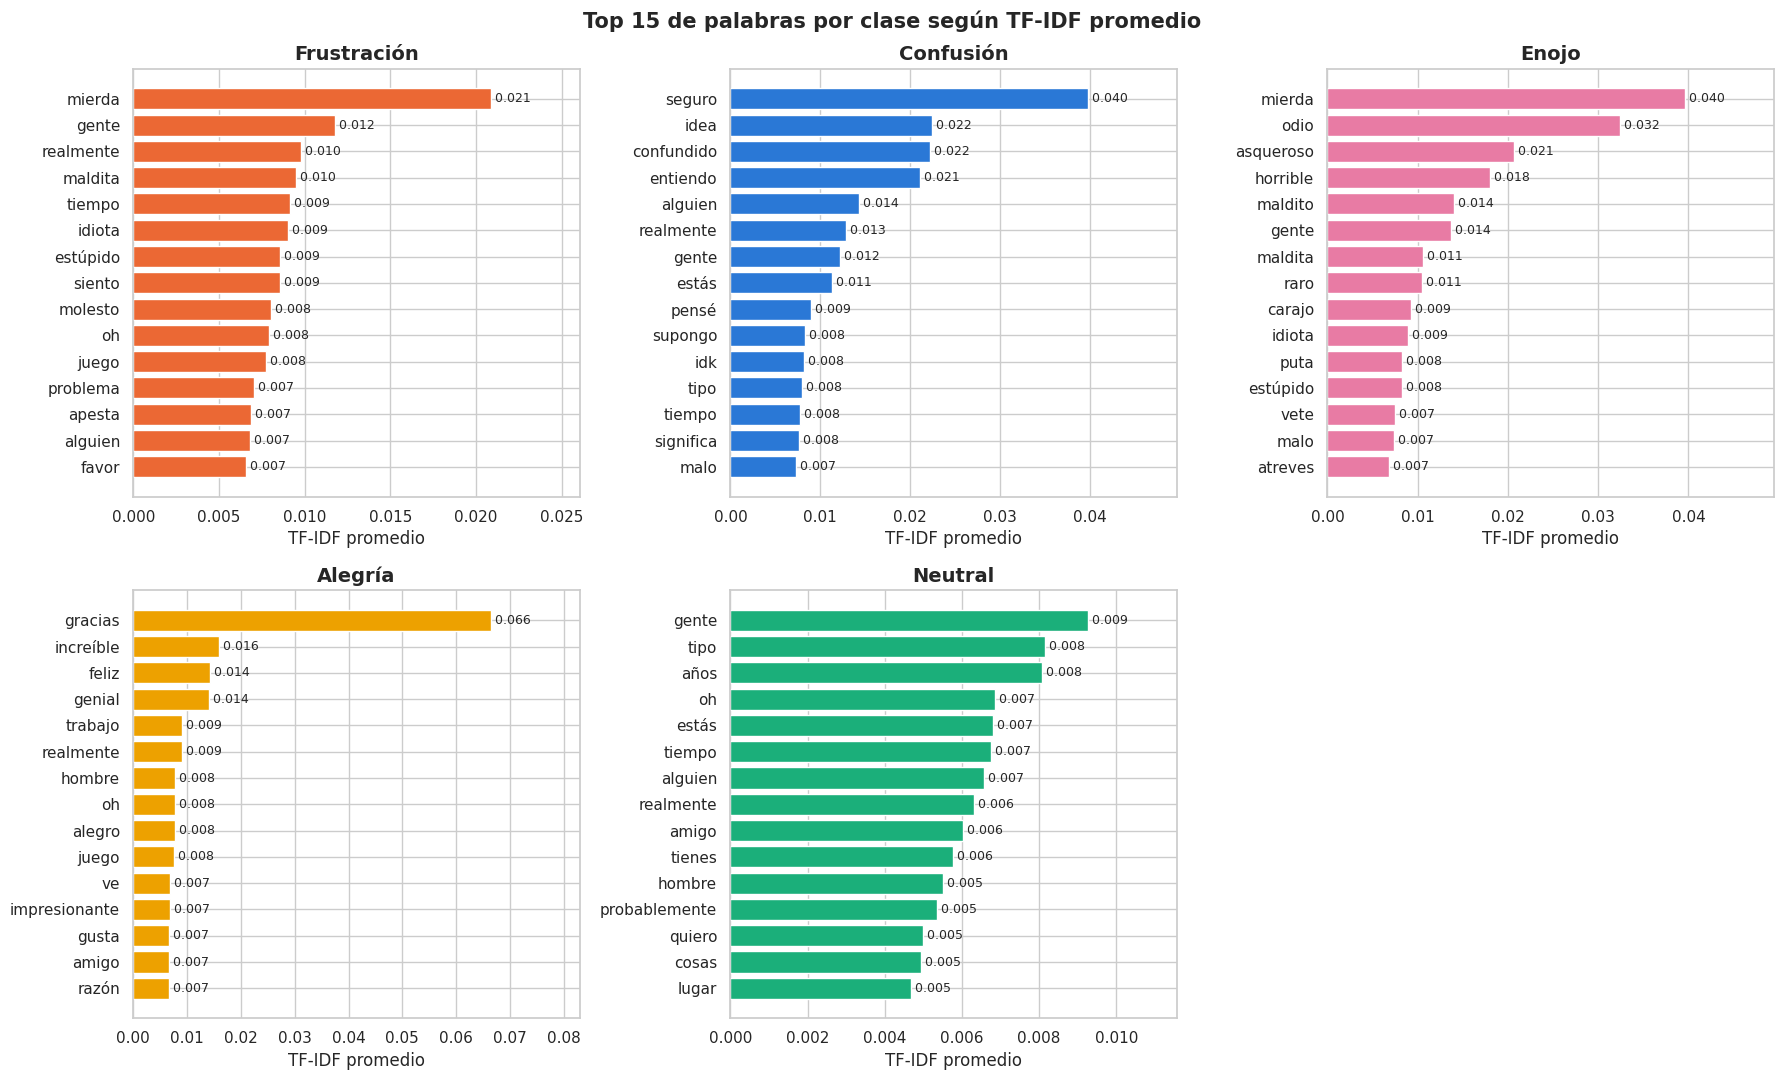

In [62]:
vectorizador_palabras = TfidfVectorizer(min_df=5)
matriz_tfidf = vectorizador_palabras.fit_transform(df_vocabulario["texto_normalizado"])
vocabulario = vectorizador_palabras.get_feature_names_out()

top_tfidf = {}
for clase in ORDEN_CLASES:
    filas_clase = (df_vocabulario["clase"] == clase).to_numpy()
    promedio = np.asarray(matriz_tfidf[filas_clase].mean(axis=0)).ravel()
    top_tfidf[clase] = pd.Series(promedio, index=vocabulario).nlargest(TOP_PALABRAS)

print(f"Tamaño del vocabulario (palabras en al menos 5 textos): {len(vocabulario):,}")
graficar_top_por_clase(top_tfidf, f"Top {TOP_PALABRAS} de palabras por clase según TF-IDF promedio",
                       "TF-IDF promedio", formato="{:.3f}")

#### 2.10.3 Palabras más frecuentes por clase y fuente

Para comparar fuentes de tamaños muy distintos, en lugar de la frecuencia absoluta se muestra el **porcentaje de mensajes de esa clase y fuente que contienen la palabra**. Cada columna corresponde a una fuente y usa su color.

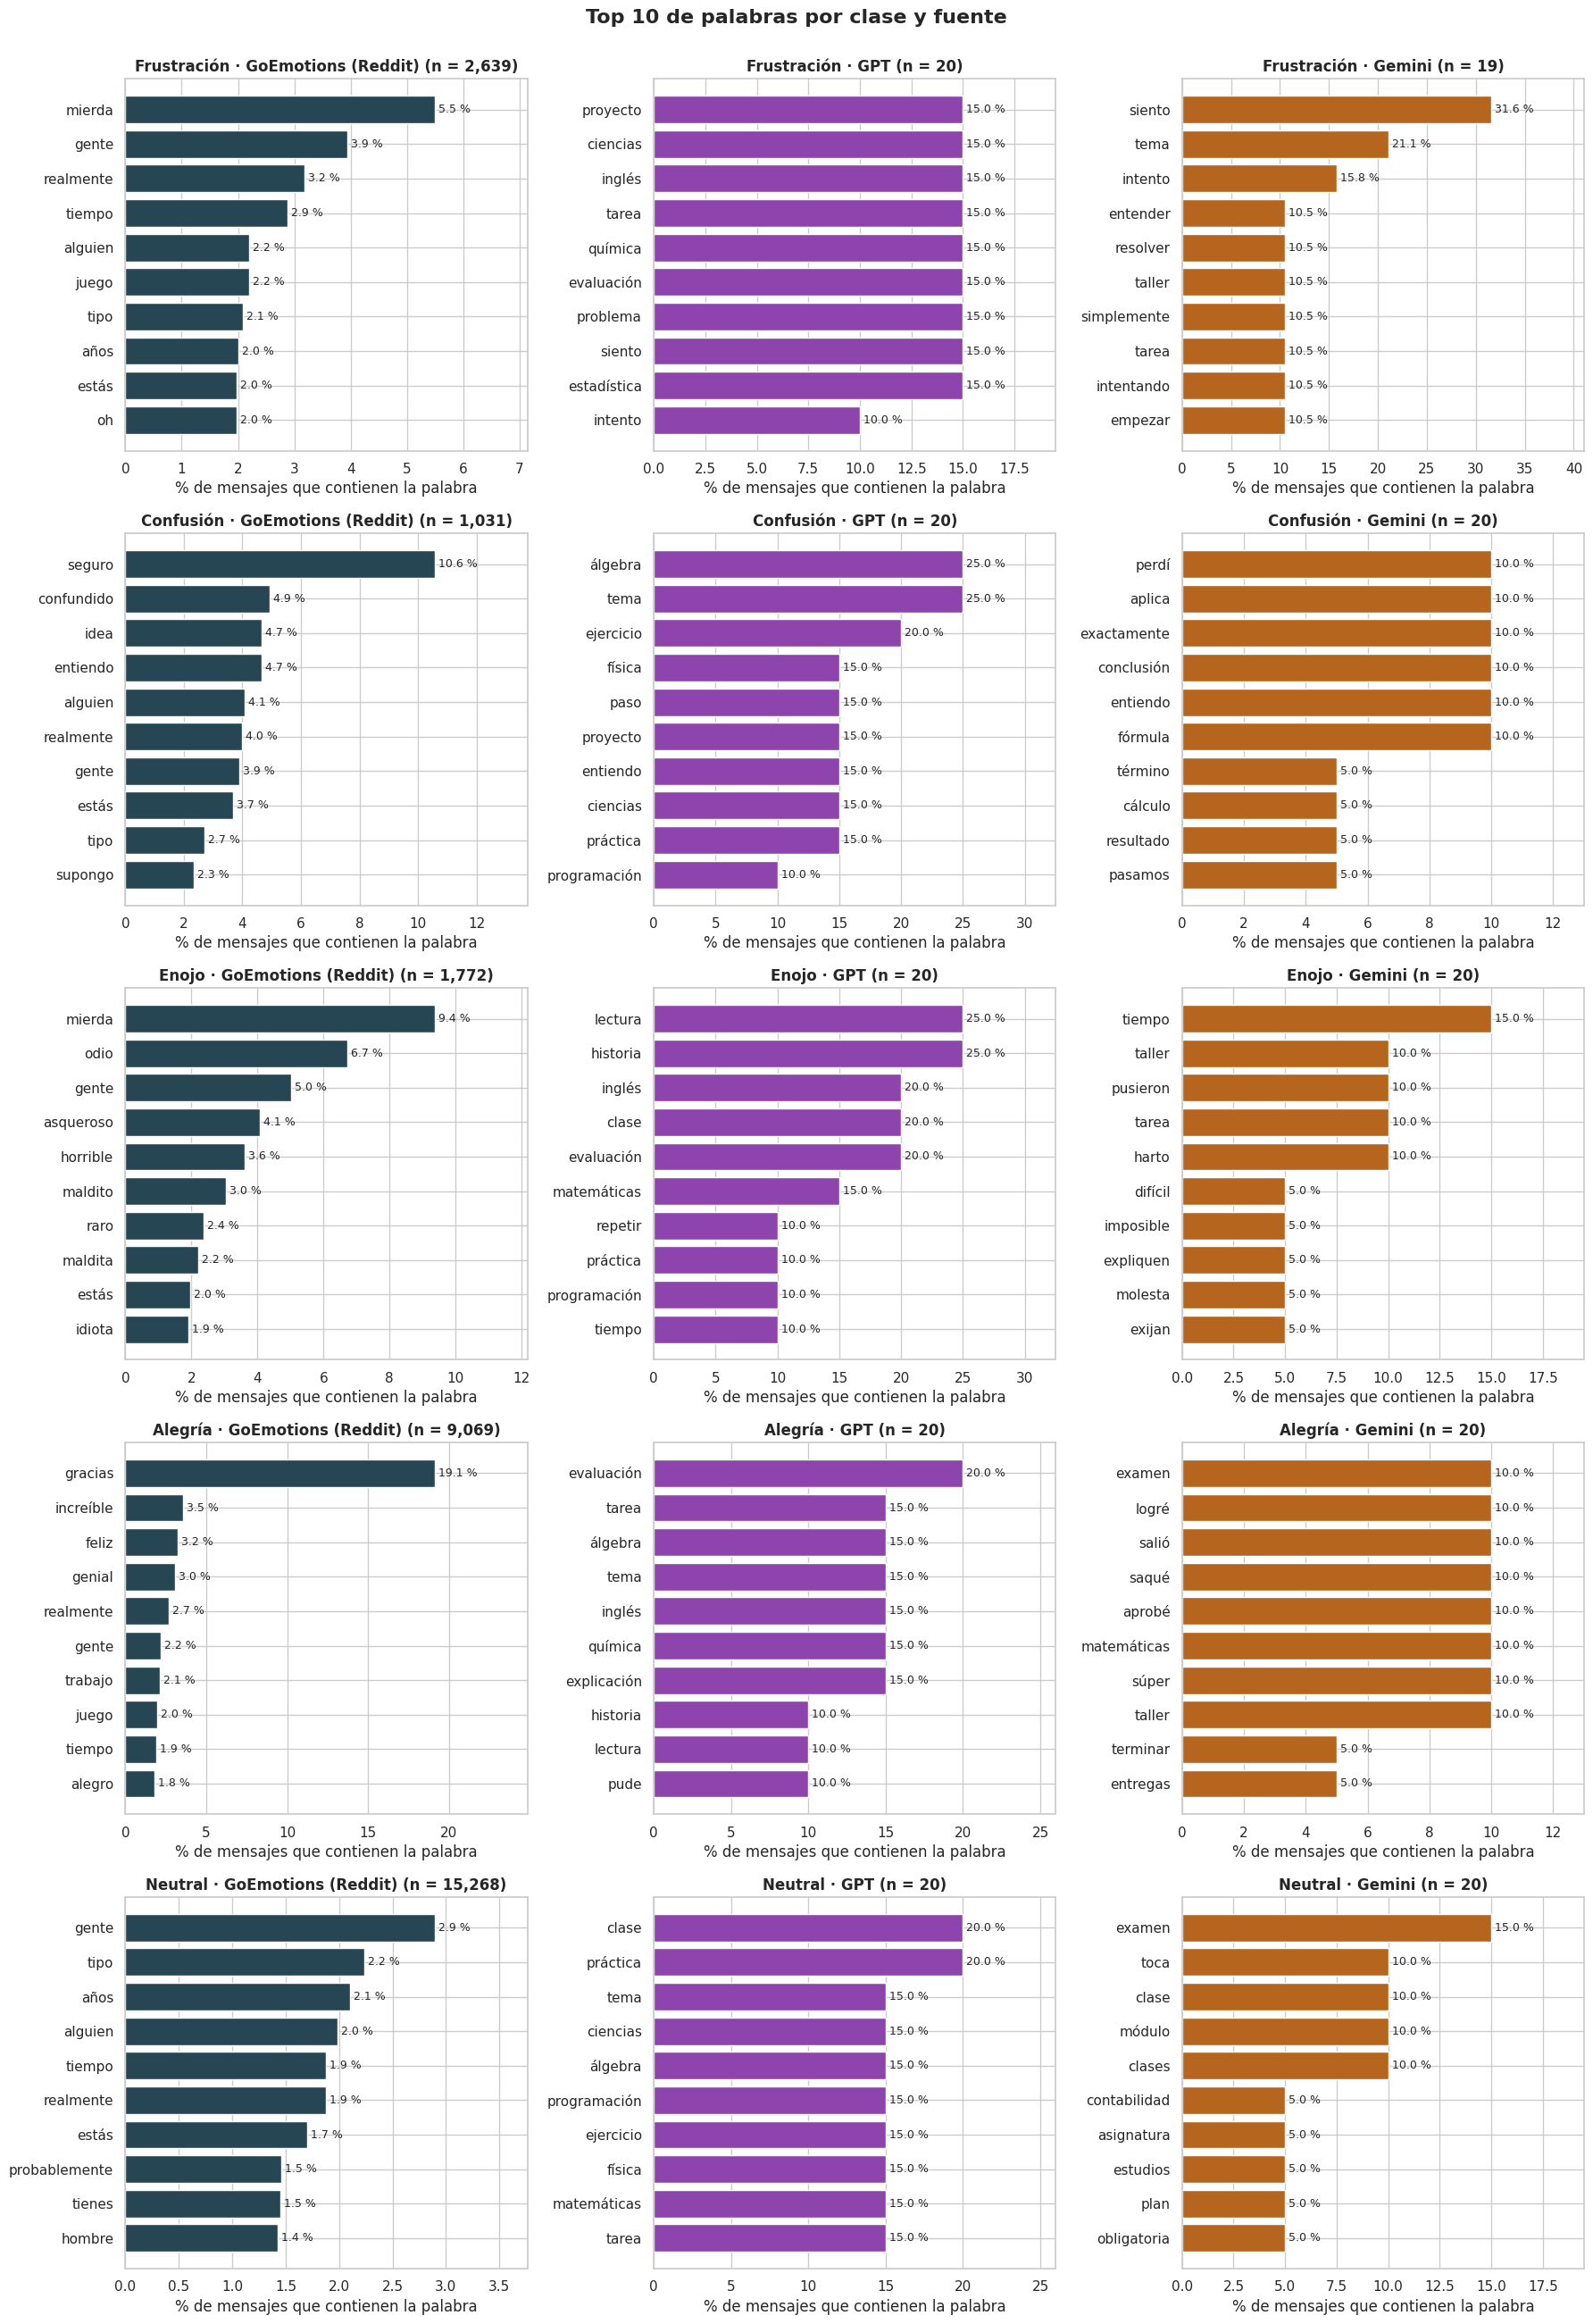

In [63]:
TOP_PALABRAS_FUENTE = 10

fig, ejes = plt.subplots(len(ORDEN_CLASES), len(ORDEN_FUENTES), figsize=(18, 26))
for fila, clase in enumerate(ORDEN_CLASES):
    for columna, fuente in enumerate(ORDEN_FUENTES):
        ax = ejes[fila, columna]
        tokens = df_vocabulario.loc[(df_vocabulario["clase"] == clase) & (df_vocabulario["fuente"] == fuente), "tokens"]
        if tokens.empty:
            ax.axis("off")
            continue
        # Porcentaje de mensajes que contienen cada palabra (cada mensaje cuenta una vez por palabra)
        presencia = pd.Series(Counter(p for lista in tokens for p in set(lista))) / len(tokens) * 100
        datos = presencia.nlargest(TOP_PALABRAS_FUENTE).sort_values()
        ax.barh(datos.index, datos.values, color=PALETA_FUENTES[fuente])
        for i, valor in enumerate(datos.values):
            ax.text(valor, i, f" {valor:.1f} %", va="center", fontsize=9)
        ax.set_xlim(0, datos.max() * 1.3)
        ax.set_title(f"{NOMBRES_CLASES[clase]} · {NOMBRES_FUENTES[fuente]} (n = {len(tokens):,})", fontsize=12)
        ax.set_xlabel("% de mensajes que contienen la palabra")
fig.suptitle(f"Top {TOP_PALABRAS_FUENTE} de palabras por clase y fuente", fontsize=16, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**Vocabulario exclusivo de cada tipo de fuente.** Para identificar de forma objetiva las palabras que delatan el dominio de Reddit, se listan las palabras más frecuentes de GoEmotions que **no aparecen en ningún mensaje sintético**, y viceversa.

In [64]:
es_goemotions = df_vocabulario["fuente"] == "goemotions"
presencia_goemotions = Counter(p for lista in df_vocabulario.loc[es_goemotions, "tokens"] for p in set(lista))
presencia_sinteticos = Counter(p for lista in df_vocabulario.loc[~es_goemotions, "tokens"] for p in set(lista))
n_goemotions, n_sinteticos = es_goemotions.sum(), (~es_goemotions).sum()

solo_goemotions = pd.Series({p: n for p, n in presencia_goemotions.items() if p not in presencia_sinteticos}).nlargest(25)
solo_sinteticos = pd.Series({p: n for p, n in presencia_sinteticos.items() if p not in presencia_goemotions}).nlargest(25)

display(pd.DataFrame({
    "solo en GoEmotions": solo_goemotions.index,
    "% de mensajes de GoEmotions": (solo_goemotions.values / n_goemotions * 100).round(2),
    "solo en sintéticos": list(solo_sinteticos.index) + [""] * (25 - len(solo_sinteticos)),
    "% de mensajes sintéticos": list((solo_sinteticos.values / n_sinteticos * 100).round(2)) + [np.nan] * (25 - len(solo_sinteticos)),
}))

,solo en GoEmotions,% de mensajes de GoEmotions,solo en sintéticos,% de mensajes sintéticos
0,gracias,5.94,aprobé,1.51
1,gente,2.93,módulo,1.51
2,realmente,2.29,avanzo,1.01
3,tipo,2.07,sencilla,1.01
4,años,1.80,corresponde,1.01
5,mierda,1.77,cansé,1.01
6,estás,1.62,exijan,1.01
7,oh,1.59,superé,1.01
8,hombre,1.54,apuntes,1.01
9,tienes,1.51,cuestionario,1.01


#### 2.10.4 Muletillas de inicio

Los modelos generadores suelen empezar muchos mensajes con la misma frase. Si, por ejemplo, la mayoría de los mensajes de confusión de GPT empiezan con "No entiendo", el clasificador puede aprender que "No entiendo" significa confusión, y fallar con mensajes reales que expresen confusión de otra forma. Para detectarlo se cuentan las **primeras palabras de cada mensaje** (en minúsculas y sin puntuación, pero **con** stopwords, porque "no", "me" o "por" forman parte de las muletillas).

Primero se muestran, para cada clase, las 10 combinaciones más frecuentes de las **dos primeras palabras** en cada fuente, con el porcentaje de mensajes de esa clase y fuente que empiezan así.

In [65]:
def inicio_mensaje(texto, n_palabras):
    palabras = re.sub(r"[^\w\s]", " ", re.sub(PATRON_MARCADOR, " ", texto).lower()).split()
    return " ".join(palabras[:n_palabras]) if len(palabras) >= n_palabras else None


def tabla_inicios(clase, n_palabras, top=10):
    columnas = {}
    for fuente in ORDEN_FUENTES:
        textos = df_limpio.loc[(df_limpio["clase"] == clase) & (df_limpio["fuente"] == fuente), "texto"]
        frecuentes = textos.apply(inicio_mensaje, n_palabras=n_palabras).value_counts().head(top)
        celdas_fuente = [f"{inicio} ({n / len(textos):.1%})" for inicio, n in frecuentes.items()]
        columnas[NOMBRES_FUENTES[fuente]] = celdas_fuente + [""] * (top - len(celdas_fuente))
    return pd.DataFrame(columnas, index=pd.RangeIndex(1, top + 1, name="puesto"))


for clase in ORDEN_CLASES:
    print(f"\n=== {NOMBRES_CLASES[clase]}: inicios de 2 palabras más frecuentes ===")
    display(tabla_inicios(clase, n_palabras=2))


=== Frustración: inicios de 2 palabras más frecuentes ===


,GoEmotions (Reddit),GPT,Gemini
puesto,,,
1,maldita sea (1.2%),siento que (10.0%),siento que (15.8%)
2,eso es (0.9%),no entiendo (5.0%),intento seguir (5.3%)
3,creo que (0.8%),por más (5.0%),me bloqueo (5.3%)
4,por qué (0.8%),llevo un (5.0%),definitivamente cálculo (5.3%)
5,no es (0.6%),me esfuerzo (5.0%),esto es (5.3%)
6,es una (0.6%),estoy bloqueado (5.0%),mi mente (5.3%)
7,no me (0.5%),cada vez (5.0%),llevo horas (5.3%)
8,así que (0.5%),me cuesta (5.0%),no soy (5.3%)
9,no puedo (0.4%),ya lo (5.0%),soy pésimo (5.3%)



=== Confusión: inicios de 2 palabras más frecuentes ===


,GoEmotions (Reddit),GPT,Gemini
puesto,,,
1,por qué (4.4%),me perdí (5.0%),por qué (10.0%)
2,no estoy (4.1%),podría explicar (5.0%),qué significa (5.0%)
3,no sé (3.0%),entiendo cada (5.0%),cómo pasamos (5.0%)
4,tal vez (1.8%),no me (5.0%),este tema (5.0%)
5,no entiendo (1.4%),cuál es (5.0%),me suena (5.0%)
6,así que (1.4%),creo que (5.0%),entiendo las (5.0%)
7,no es (1.3%),la explicación (5.0%),no me (5.0%)
8,creo que (1.2%),podría dar (5.0%),siento que (5.0%)
9,eso es (1.1%),no estoy (5.0%),me confundí (5.0%)



=== Enojo: inicios de 2 palabras más frecuentes ===


,GoEmotions (Reddit),GPT,Gemini
puesto,,,
1,a la (1.6%),estoy harto (5.0%),me molesta (5.0%)
2,eso es (1.5%),qué pérdida (5.0%),es demasiado (5.0%)
3,esto es (1.2%),ya me (5.0%),qué coraje (5.0%)
4,maldita sea (1.0%),no pienso (5.0%),odio matemáticas (5.0%)
5,es un (0.8%),es absurdo (5.0%),el examen (5.0%)
6,por qué (0.8%),me molesta (5.0%),este profesor (5.0%)
7,cómo te (0.8%),otra vez (5.0%),es injusto (5.0%)
8,no me (0.6%),no soporto (5.0%),es ridículo (5.0%)
9,qué carajo (0.6%),esta actividad (5.0%),ya me (5.0%)



=== Alegría: inicios de 2 palabras más frecuentes ===


,GoEmotions (Reddit),GPT,Gemini
puesto,,,
1,gracias por (3.3%),por fin (10.0%),por fin (10.0%)
2,eso es (1.6%),me fue (5.0%),valió totalmente (5.0%)
3,esto es (1.1%),estoy feliz (5.0%),qué felicidad (5.0%)
4,creo que (1.0%),después de (5.0%),saqué diez (5.0%)
5,estoy de (0.9%),qué alegría (5.0%),salió excelente (5.0%)
6,me alegro (0.9%),saqué la (5.0%),qué satisfacción (5.0%)
7,muchas gracias (0.7%),no puedo (5.0%),me felicitaron (5.0%)
8,es un (0.6%),hoy sí (5.0%),hoy todo (5.0%)
9,de acuerdo (0.6%),me salió (5.0%),ya la (5.0%)



=== Neutral: inicios de 2 palabras más frecuentes ===


,GoEmotions (Reddit),GPT,Gemini
puesto,,,
1,creo que (1.1%),hoy tenemos (5.0%),es una (5.0%)
2,eso es (0.7%),la próxima (5.0%),estoy esperando (5.0%)
3,tal vez (0.5%),el profesor (5.0%),esta materia (5.0%)
4,no hay (0.5%),tengo que (5.0%),no me (5.0%)
5,así que (0.5%),en el (5.0%),el profesor (5.0%)
6,parece que (0.5%),la evaluación (5.0%),estoy tomando (5.0%)
7,no es (0.5%),el material (5.0%),es un (5.0%)
8,esto es (0.5%),durante esta (5.0%),hice el (5.0%)
9,por qué (0.4%),anoté los (5.0%),solo busco (5.0%)


Para resumir todas las clases en una sola vista, el siguiente gráfico muestra, para inicios de 2 y de 3 palabras, el **porcentaje de mensajes que empiezan con alguno de los 10 inicios más frecuentes** de su clase y fuente. Un valor alto indica que la fuente usa pocas fórmulas de inicio. Como un grupo con pocos mensajes tiene, por fuerza, menos inicios distintos, este porcentaje favorece a las fuentes pequeñas; la comparación con muestras del mismo tamaño se hace en 2.11.

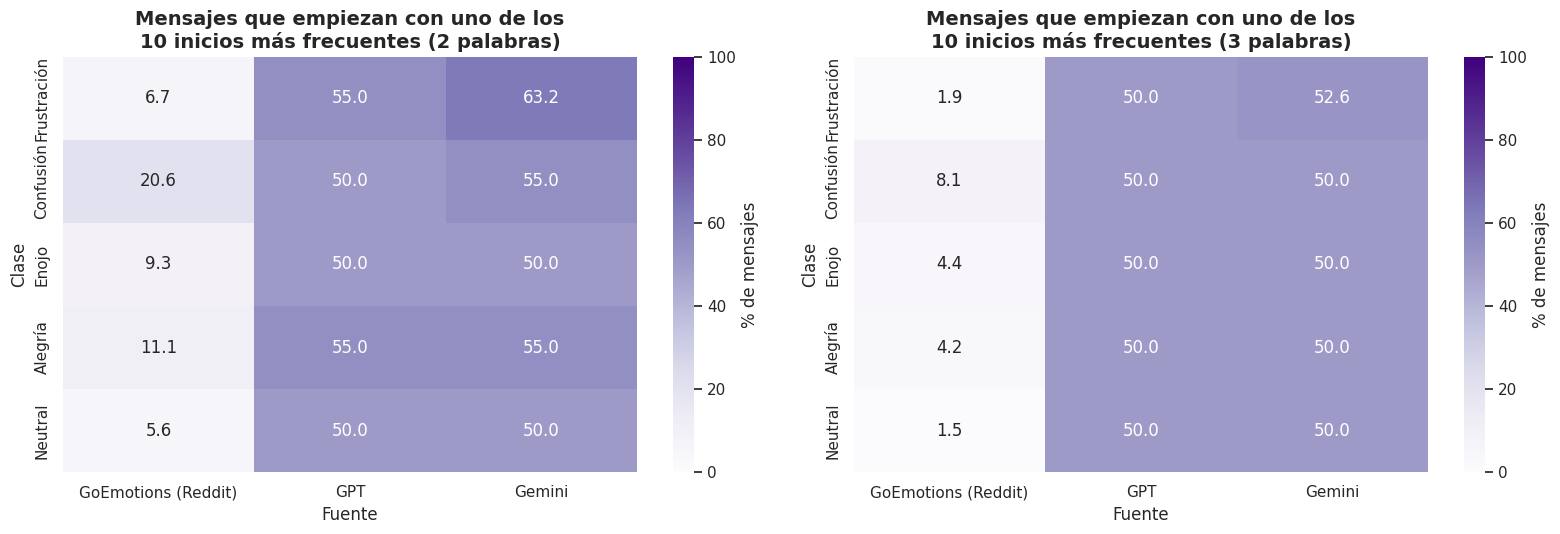

In [66]:
def cobertura_top_inicios(n_palabras, top=10):
    cobertura = pd.DataFrame(index=ORDEN_CLASES, columns=ORDEN_FUENTES, dtype=float)
    for clase in ORDEN_CLASES:
        for fuente in ORDEN_FUENTES:
            textos = df_limpio.loc[(df_limpio["clase"] == clase) & (df_limpio["fuente"] == fuente), "texto"]
            inicios = textos.apply(inicio_mensaje, n_palabras=n_palabras)
            cobertura.loc[clase, fuente] = inicios.value_counts().head(top).sum() / len(textos) * 100
    return cobertura


fig, ejes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, n_palabras in zip(ejes, [2, 3]):
    cobertura = cobertura_top_inicios(n_palabras)
    sns.heatmap(cobertura, annot=True, fmt=".1f", cmap="Purples", vmin=0, vmax=100,
                xticklabels=[NOMBRES_FUENTES[f] for f in ORDEN_FUENTES],
                yticklabels=[NOMBRES_CLASES[c] for c in ORDEN_CLASES],
                cbar_kws={"label": "% de mensajes"}, ax=ax)
    ax.set_title(f"Mensajes que empiezan con uno de los\n10 inicios más frecuentes ({n_palabras} palabras)")
    ax.set_xlabel("Fuente")
    ax.set_ylabel("Clase")
plt.tight_layout()
plt.show()

**Interpretación.**

- **Coherencia del vocabulario.** El vocabulario de cada clase es coherente con su etiqueta. En alegría domina "gracias" (1.764 apariciones y el TF-IDF promedio más alto de todo el análisis, 0,066), seguida de "increíble", "feliz" y "genial". En confusión destacan "seguro" (de "no estoy seguro"), "entiendo", "confundido", "idea" y "supongo". En enojo aparecen insultos y groserías ("mierda", "odio", "asqueroso", "horrible", "maldito", "idiota", "carajo"). Frustración comparte buena parte de ese vocabulario ("mierda", "maldita", "idiota", "estúpido"), otra señal de que su frontera con enojo es difusa. Neutral no tiene palabras propias: sus términos más frecuentes ("gente", "tipo", "años") son genéricos y su TF-IDF promedio no pasa de 0,009.
- **Dominio de Reddit.** La tabla de vocabulario exclusivo muestra palabras que no aparecen en ningún mensaje sintético y que delatan la conversación general de Reddit: "gente" (2,93 % de los mensajes de GoEmotions), "tipo", "años", "mierda", "hombre", "juego", "amigo" o "mundo"; "juego" aparece incluso entre las 15 palabras más frecuentes de frustración y de alegría. En los sintéticos, en cambio, las palabras exclusivas son académicas: "aprobé", "módulo", "cuestionario", "apuntes", "superé" o "avanzo". Incluso "gracias", la palabra más característica de alegría, no aparece en ningún mensaje sintético: los generadores expresan la alegría con logros académicos, no con agradecimientos. Esto confirma que GoEmotions no representa el dominio del tutor y justifica combinar las fuentes.
- **Efecto de 2.7.4.** Como cada plantilla aporta ahora un solo mensaje, los porcentajes de la tabla de inicios ya no reflejan las 10 variantes de cada frase de GPT (que antes daban exactamente un 5,0 % a cada inicio), sino cuántas plantillas *distintas* comparten un mismo inicio. Con 20 mensajes por clase y fuente (19 en frustración de Gemini), cada mensaje vale un 5 % (un 5,3 % en ese grupo), así que las diferencias pequeñas no son significativas. Por la misma razón, el heatmap de cobertura no es comparable entre fuentes: con 20 mensajes, los 10 inicios más frecuentes cubren por fuerza al menos el 50 % del grupo, que es justamente el mínimo que muestran GPT y Gemini (entre 50,0 % y 63,2 %), frente al 5,6 %–20,6 % de GoEmotions en los inicios de 2 palabras.
- **Muletillas de los generadores.** Las más fuertes son "siento que", con el que empiezan el 15,8 % de los mensajes de frustración de Gemini y el 10,0 % de los de GPT, y "por fin", con el que empiezan el 10,0 % de los mensajes de alegría de ambos generadores; en confusión, el 10,0 % de los mensajes de Gemini empieza con "por qué". GPT y Gemini comparten, por tanto, las mismas fórmulas para las mismas clases. Son un **riesgo**: el modelo podría aprender esas frases como atajo para predecir la clase en lugar de la emoción, y luego fallar con mensajes reales escritos de otra forma. La comparación del modelado entre un modelo entrenado solo con GoEmotions y otro que añade los sintéticos, junto con la evaluación sobre mensajes escritos por personas (ver 2.14), permitirá medir este efecto.

**Cifras clave de 2.10**

- Tamaño del vocabulario usado en el análisis TF-IDF: 5.276 palabras.
- Muletilla más frecuente por fuente: GPT = "siento que" (10,0 % de frustración; también "por fin", con el 10,0 % de alegría), Gemini = "siento que" (15,8 % de frustración).

### 2.11 Diversidad léxica por fuente

Se mide de forma objetiva qué tan variados son los datos sintéticos frente a los reales con tres métricas:

- **Type-token ratio (TTR):** palabras distintas / palabras totales. Cuanto más alto, más variado es el vocabulario.
- **Distinct-2:** bigramas (pares de palabras consecutivas) distintos / bigramas totales. Mide la variedad de las combinaciones de palabras, no solo del vocabulario; es la métrica habitual para evaluar la diversidad de textos generados.
- **Proporción de inicios repetidos:** proporción de mensajes cuyas primeras 3 palabras coinciden con las de otro mensaje de la muestra. Cuantifica las muletillas de 2.10.4.

**Control del tamaño.** Estas métricas dependen del tamaño de la muestra: cuantos más textos (o palabras) se cuentan, más se repiten las palabras y menor es el TTR. Para comparar de forma justa:

1. De cada fuente se toma una **muestra aleatoria del mismo número de mensajes**, igual al tamaño de la fuente más pequeña. Tras eliminar las variantes de plantilla (2.7.4), GPT queda con 100 mensajes y Gemini con 99, así que la muestra es de 99 mensajes.
2. Como los mensajes de cada fuente tienen longitudes distintas, el TTR y el distinct-2 se calculan sobre el **mismo número de palabras y de bigramas** en las tres fuentes (el mínimo entre ellas).
3. El muestreo se repite 10 veces (con semillas derivadas de la semilla global) y se informa la media y la desviación estándar. En las fuentes cuyo tamaño coincide, o casi, con el de la muestra (GPT y Gemini), la muestra es prácticamente la fuente completa, así que su desviación es cero o casi cero: la variabilidad entre repeticiones solo es informativa para GoEmotions.

Las palabras se cuentan sobre el texto natural en minúsculas, sin quitar stopwords, porque la diversidad incluye también cómo se combinan las palabras funcionales.

In [67]:
METRICAS_DIVERSIDAD = ["type_token_ratio", "distinct_2", "prop_inicios_repetidos"]
NOMBRES_METRICAS = {
    "type_token_ratio": "Type-token ratio",
    "distinct_2": "Distinct-2",
    "prop_inicios_repetidos": "Prop. de inicios repetidos",
}


def tokens_naturales(texto):
    return re.findall(r"\w+", re.sub(PATRON_MARCADOR, " ", texto).lower())


def calcular_diversidad(listas_tokens, n_palabras, n_bigramas):
    palabras = [p for tokens in listas_tokens for p in tokens][:n_palabras]
    bigramas = [b for tokens in listas_tokens for b in zip(tokens, tokens[1:])][:n_bigramas]
    inicios = pd.Series([" ".join(tokens[:3]) for tokens in listas_tokens if len(tokens) >= 3])
    return {
        "type_token_ratio": len(set(palabras)) / len(palabras),
        "distinct_2": len(set(bigramas)) / len(bigramas),
        "prop_inicios_repetidos": inicios.duplicated(keep=False).mean(),
    }


def comparar_diversidad(grupos, n_mensajes, semilla):
    """grupos: dict nombre -> Serie de textos. Devuelve las métricas de cada grupo con el tamaño controlado."""
    listas = {
        nombre: [tokens_naturales(t) for t in textos.sample(n_mensajes, random_state=semilla)]
        for nombre, textos in grupos.items()
    }
    n_palabras = min(sum(len(t) for t in lista) for lista in listas.values())
    n_bigramas = min(sum(max(len(t) - 1, 0) for t in lista) for lista in listas.values())
    return {nombre: calcular_diversidad(lista, n_palabras, n_bigramas) for nombre, lista in listas.items()}


N_REPETICIONES = 10
semillas = np.random.default_rng(SEMILLA).integers(0, 1_000_000, N_REPETICIONES)
n_muestra = int(contar_por_fuente(df_limpio).min())
textos_diversidad = {fuente: df_limpio.loc[df_limpio["fuente"] == fuente, "texto"] for fuente in ORDEN_FUENTES}

resultados = []
for repeticion, semilla in enumerate(semillas):
    for fuente, metricas in comparar_diversidad(textos_diversidad, n_muestra, int(semilla)).items():
        resultados.append({"repetición": repeticion, "fuente": fuente, **metricas})
df_diversidad = pd.DataFrame(resultados)

resumen_diversidad = (
    df_diversidad.groupby("fuente")[METRICAS_DIVERSIDAD].agg(["mean", "std"])
    .reindex(ORDEN_FUENTES).round(3)
    .rename(columns={"mean": "media", "std": "desv_est"}, level=1)
    .rename(columns=NOMBRES_METRICAS, level=0)
)
print(f"Mensajes por muestra: {n_muestra:,} (tamaño de la fuente más pequeña), {N_REPETICIONES} repeticiones")
display(resumen_diversidad)

if n_muestra < 100:
    print(f"Advertencia: la muestra tiene solo {n_muestra} mensajes. Las métricas de GoEmotions se estiman "
          f"con poca precisión; revisar su desviación estándar entre repeticiones en la tabla.")

Mensajes por muestra: 99 (tamaño de la fuente más pequeña), 10 repeticiones


Type-token ratio          Distinct-2           \
                      media desv_est      media desv_est   
fuente                                                     
goemotions            0.510    0.008      0.933    0.012   
gpt                   0.325    0.004      0.669    0.004   
gemini                0.427    0.000      0.885    0.000   

           Prop. de inicios repetidos           
                                media desv_est  
fuente                                          
goemotions                      0.008     0.01  
gpt                             0.000     0.00  
gemini                          0.000     0.00

Advertencia: la muestra tiene solo 99 mensajes. Las métricas de GoEmotions se estiman con poca precisión; revisar su desviación estándar entre repeticiones en la tabla.


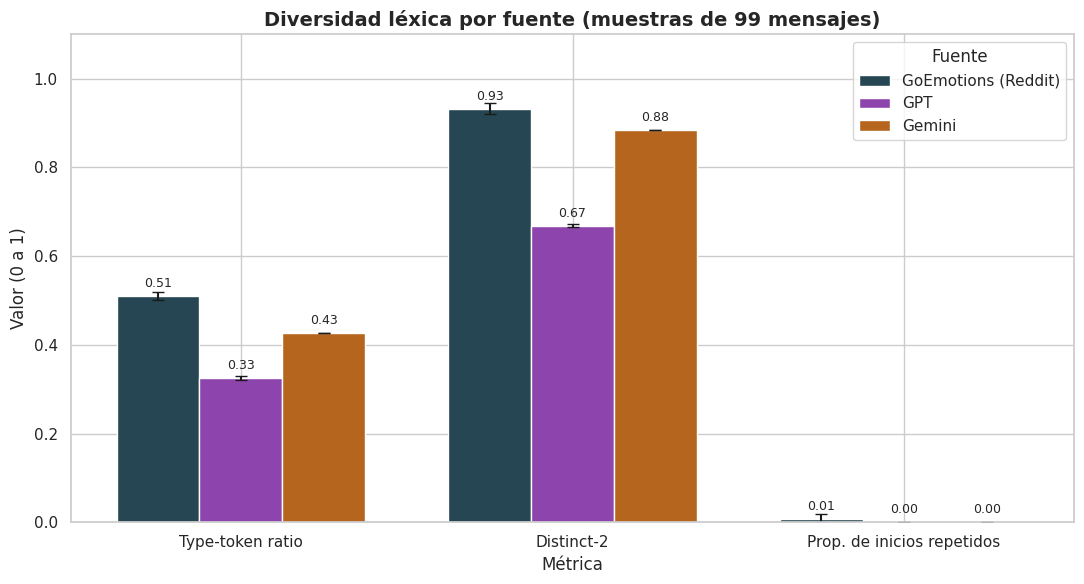

In [68]:
medias = df_diversidad.groupby("fuente")[METRICAS_DIVERSIDAD].mean().reindex(ORDEN_FUENTES)
desviaciones = df_diversidad.groupby("fuente")[METRICAS_DIVERSIDAD].std().reindex(ORDEN_FUENTES)

fig, ax = plt.subplots(figsize=(11, 6))
ancho = 0.25
posiciones = np.arange(len(METRICAS_DIVERSIDAD))
for k, fuente in enumerate(ORDEN_FUENTES):
    barras = ax.bar(posiciones + (k - 1) * ancho, medias.loc[fuente], width=ancho, yerr=desviaciones.loc[fuente],
                    capsize=4, color=PALETA_FUENTES[fuente], label=NOMBRES_FUENTES[fuente])
    for barra, valor in zip(barras, medias.loc[fuente]):
        ax.text(barra.get_x() + barra.get_width() / 2, valor + 0.02, f"{valor:.2f}", ha="center", fontsize=9)
ax.set_xticks(posiciones)
ax.set_xticklabels([NOMBRES_METRICAS[m] for m in METRICAS_DIVERSIDAD])
ax.set_ylim(0, 1.1)
ax.set_title(f"Diversidad léxica por fuente (muestras de {n_muestra:,} mensajes)")
ax.set_xlabel("Métrica")
ax.set_ylabel("Valor (0 a 1)")
ax.legend(title="Fuente")
plt.tight_layout()
plt.show()

**Diversidad por clase y fuente.** Se repite el cálculo dentro de cada clase, con muestras del tamaño del grupo clase × fuente más pequeño, para ver si la falta de diversidad se concentra en alguna clase.

**Advertencia.** Después de eliminar las variantes de plantilla (2.7.4), cada grupo clase × fuente de los sintéticos tiene 20 mensajes (19 en frustración de Gemini), de modo que el tamaño de muestra de este análisis (`n_muestra_clase`, que se imprime abajo) es de 19 mensajes. Con tan pocos mensajes, cada uno cambia la proporción de inicios repetidos en algo más de 5 puntos porcentuales, así que **las cifras por clase de este heatmap son solo orientativas**; las conclusiones sobre diversidad se basan en la comparación por fuente de la celda anterior.

Mensajes por muestra en cada grupo clase × fuente: 19
Advertencia: menos de 20 mensajes por grupo; las cifras por clase son solo orientativas.


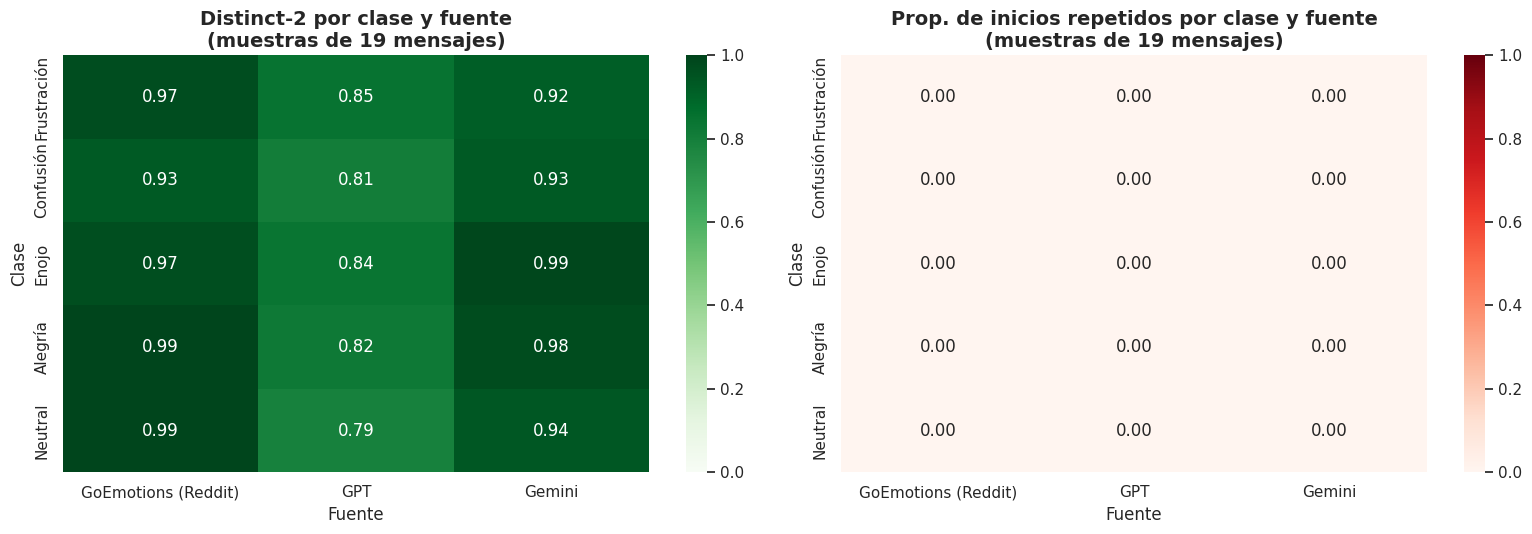

In [69]:
n_muestra_clase = int(df_limpio.groupby(["clase", "fuente"]).size().min())
print(f"Mensajes por muestra en cada grupo clase × fuente: {n_muestra_clase}")
if n_muestra_clase < 20:
    print("Advertencia: menos de 20 mensajes por grupo; las cifras por clase son solo orientativas.")
filas = []
for clase in ORDEN_CLASES:
    grupos = {
        fuente: df_limpio.loc[(df_limpio["clase"] == clase) & (df_limpio["fuente"] == fuente), "texto"]
        for fuente in ORDEN_FUENTES
    }
    for fuente, metricas in comparar_diversidad(grupos, n_muestra_clase, SEMILLA).items():
        filas.append({"clase": clase, "fuente": fuente, **metricas})
df_diversidad_clase = pd.DataFrame(filas)

fig, ejes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, metrica, mapa in zip(ejes, ["distinct_2", "prop_inicios_repetidos"], ["Greens", "Reds"]):
    tabla = df_diversidad_clase.pivot(index="clase", columns="fuente", values=metrica).reindex(
        index=ORDEN_CLASES, columns=ORDEN_FUENTES)
    sns.heatmap(tabla, annot=True, fmt=".2f", cmap=mapa, vmin=0, vmax=1,
                xticklabels=[NOMBRES_FUENTES[f] for f in ORDEN_FUENTES],
                yticklabels=[NOMBRES_CLASES[c] for c in ORDEN_CLASES], ax=ax)
    ax.set_title(f"{NOMBRES_METRICAS[metrica]} por clase y fuente\n(muestras de {n_muestra_clase} mensajes)")
    ax.set_xlabel("Fuente")
    ax.set_ylabel("Clase")
plt.tight_layout()
plt.show()

**Interpretación.** Con muestras de 99 mensajes, los datos sintéticos son menos variados que los de Reddit: su type-token ratio es de 0,325 (GPT) y 0,427 (Gemini) frente a 0,510 en GoEmotions, y su distinct-2, de 0,669 y 0,885 frente a 0,933. GPT es claramente el generador más repetitivo: su distinct-2 está 0,264 por debajo del de GoEmotions y 0,216 por debajo del de Gemini, diferencias muy superiores a la desviación estándar entre repeticiones (0,012 como máximo). Una explicación coherente con 2.7.4 es que, aunque ahora cada plantilla aporta un solo mensaje, GPT rellena todas sus plantillas con los mismos 10 temas ("la clase de matemáticas", "el tema de álgebra"…), de modo que esos bigramas se repiten entre mensajes distintos.

**Efecto de eliminar las plantillas.** La proporción de inicios repetidos de los sintéticos bajó de 0,998 (GPT) y 0,875 (Gemini) antes de 2.7.4 a 0,000 en ambos: al conservar un solo mensaje por plantilla, ya no hay dos mensajes con el mismo comienzo. En GoEmotions bajó de 0,027 a 0,008, en parte porque la muestra actual es más pequeña y es menos probable que dos comentarios coincidan por azar. Sin embargo, **incluso tras eliminar las plantillas, GPT sigue teniendo un distinct-2 claramente menor que GoEmotions** (0,669 frente a 0,933): la eliminación quitó las frases repetidas, pero no la pobreza de sus combinaciones de palabras.

**Por clase** (muestras de 19 mensajes, cifras solo orientativas), la menor diversidad de GPT se reparte entre todas las clases: su distinct-2 va de 0,79 (neutral) a 0,85 (frustración), frente a valores de 0,93 a 0,99 en GoEmotions y de 0,92 a 0,99 en Gemini. La proporción de inicios repetidos es 0,00 en todas las clases y fuentes.

**Estabilidad.** En GPT y Gemini la muestra es casi la fuente completa, así que su desviación estándar es de 0,004 o menos; en GoEmotions va de 0,008 a 0,012, un valor pequeño frente a las diferencias entre fuentes. Las conclusiones son, por tanto, estables pese al tamaño reducido de la muestra.

**Cifras clave de 2.11**

- Tamaño de muestra por fuente: 99 mensajes.
- Distinct-2: GoEmotions = 0,933, GPT = 0,669, Gemini = 0,885.
- Proporción de inicios repetidos: GoEmotions = 0,008, GPT = 0,000, Gemini = 0,000.

### 2.12 Revisión cualitativa: ejemplos y calidad

Las métricas anteriores no sustituyen la lectura directa de los datos. En esta subsección se revisan ejemplos concretos de cada fuente para documentar sus limitaciones.

#### 2.12.1 Ejemplos aleatorios por clase y fuente

Se muestran 3 ejemplos aleatorios por clase y por fuente, con el texto completo.

In [70]:
for clase in ORDEN_CLASES:
    print(f"\n=== {NOMBRES_CLASES[clase]} ===")
    ejemplos = (
        df_limpio[df_limpio["clase"] == clase]
        .groupby("fuente", group_keys=False).sample(n=3, random_state=SEMILLA)
    )
    ejemplos["fuente"] = pd.Categorical(ejemplos["fuente"], categories=ORDEN_FUENTES, ordered=True)
    display(ejemplos.sort_values("fuente")[["fuente", "texto", "emocion_original"]].reset_index(drop=True))


=== Frustración ===


,fuente,texto,emocion_original
0,goemotions,"Sin compromiso, los demócratas finalmente están mostrando alguna maldita columna vertebral.",annoyance
1,goemotions,Es 2019 amigo relajarse con los roles de género Editar: es 2019 Estoy cansado lo siento,disappointment
2,goemotions,"Olvidaste el milagro, fan falso.",annoyance
3,gpt,Me cuesta muchísimo seguir el ritmo de la lectura de historia.,frustracion
4,gpt,"Cada vez que intento estudiar el tema de álgebra, termino sintiéndome incapaz.",frustracion
5,gpt,Llevo un buen rato con la tarea de química y sigo sin avanzar.,frustracion
6,gemini,Intento seguir el ritmo de la clase pero me siento incapaz.,frustracion
7,gemini,Mi mente se quedó completamente en blanco durante la tarea.,frustracion
8,gemini,"Me rindo con este ejercicio, simplemente no me da la cabeza.",frustracion



=== Confusión ===


,fuente,texto,emocion_original
0,goemotions,Pagar a las parejas para tener hijos. No estoy seguro si los incentivos se aplican a las madres solteras.,confusion
1,goemotions,No sé por qué se molestan en ello.,confusion
2,goemotions,¡La izquierda se ha hecho daño en su confusión!,confusion
3,gpt,Quisiera confirmar si interpreté correctamente el ejercicio de la clase de matemáticas.,confusion
4,gpt,No logro distinguir estos dos conceptos cuando vemos el proyecto de ciencias.,confusion
5,gpt,¿Ese resultado se obtiene del paso anterior o de otra regla de la lectura de historia?,confusion
6,gemini,¿Cómo pasamos de ese resultado a la conclusión final?,confusion
7,gemini,"Me perdí en esa última parte, ¿podría repetirlo por favor?",confusion
8,gemini,"Entendí el principio, pero en la mitad de la explicación me perdí.",confusion



=== Enojo ===


,fuente,texto,emocion_original
0,goemotions,Odiaba el brócoli hasta que mis padres aprovecharon mi obsesión con los dinosaurios y me hicieron fingir que era un brontosaurio,anger
1,goemotions,Ese maldito FDR al que Estados Unidos amaba tanto que tuvo que escribir una enmienda a la Constitución para evitar que nadie más fuera elegido que muchas veces,anger
2,goemotions,"Es una mezcla asquerosa de mayonesa, ketchup y pepinillo.",disgust
3,gpt,¡Esta actividad de la clase de matemáticas está mal planteada!,enojo
4,gpt,¡Estoy furioso por la cantidad de tareas de la práctica de programación!,enojo
5,gpt,¡No soporto que evalúen el proyecto de ciencias sin haberlo explicado correctamente!,enojo
6,gemini,Me molesta demasiado que no expliquen bien y luego exijan tanto.,enojo
7,gemini,"¡No entiendo nada, esto no sirve para absolutamente nada!",enojo
8,gemini,¡Estoy harto de esta plataforma que siempre falla al subir el taller!,enojo



=== Alegría ===


,fuente,texto,emocion_original
0,goemotions,Salud. Nunca he oído hablar de ninguno de ellos. Los niños te harán eso...,excitement
1,goemotions,También me alegro de no ser el único que jura mucho a los objetos bastardos.,joy
2,goemotions,Ja. Me parece justo.,approval
3,gpt,¡Recibí una felicitación por mi trabajo sobre el ejercicio de física!,alegria
4,gpt,¡Estoy feliz porque aprobé la clase de matemáticas!,alegria
5,gpt,¡Qué alegría ver que todo mi esfuerzo con el tema de álgebra dio resultado!,alegria
6,gemini,¡Qué felicidad terminar todas mis entregas de la semana!,alegria
7,gemini,"¡Pasé física, todavía no me lo creo!",alegria
8,gemini,¡Logré resolver el problema más difícil de la teoría yo solo!,alegria



=== Neutral ===


,fuente,texto,emocion_original
0,goemotions,Y IA de alguna manera será mágicamente más perturbadora que la revolución industrial. Porque... razones.,neutral
1,goemotions,Esto es una reminiscencia de cuando pensamos que tuvimos suerte de tener [NOMBRE] Y [NOMBRE] en nuestro personal.,neutral
2,goemotions,¿Qué puntos de vista conflicto? Esa es una parte muy importante. ¿Aún te consideras ortodoxo? ¿Quieres ser ortodoxo?,neutral
3,gpt,El profesor dejó una tarea relacionada con la explicación de hoy.,neutral
4,gpt,Hoy corresponde completar la práctica del tema de álgebra.,neutral
5,gpt,En la sesión anterior vimos una introducción a la práctica de programación.,neutral
6,gemini,Es una asignatura obligatoria del plan de estudios.,neutral
7,gemini,Estoy revisando el temario de cálculo para ver qué sigue.,neutral
8,gemini,Subí el archivo de este problema a la plataforma hace un rato.,neutral


#### 2.12.2 GoEmotions: calidad de la traducción automática

La traducción automática falla sobre todo con la jerga, las groserías y las expresiones idiomáticas. Otro tipo de error, el ruido de símbolos y signos generado al traducir emojis o signos repetidos (cadenas de `¡` al final de la frase, `* * *`, `♪ ♪ ♪`), ya se limpió en 2.7.1; aquí se revisan los errores de significado, que no se pueden corregir automáticamente. Por ejemplo, en la exploración inicial apareció "if he does off himself" ("si se suicida") traducido como "si lo hace fuera de sí mismo", que cambia por completo el sentido. Ese ejemplo tiene la etiqueta `neutral`, así que se busca en `df_crudo`:

In [71]:
df_crudo[df_crudo["text"].str.contains("does off himself", case=False, regex=False)][["text", "text_es", "labels"]]

,text,text_es,labels
1,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actually dead","Ahora, si lo hace fuera de sí mismo, todo el mundo pensará que está teniendo una risa jodiendo con la gente en lugar de realmente muerto",[27]


Para encontrar más casos de forma sistemática se usan dos indicadores sobre los textos de GoEmotions que quedaron tras la limpieza, comparando la traducción (`texto`) con el original en inglés (`texto_ingles`):

- **Proporción de palabras que quedaron en inglés**: palabras de la traducción que aparecen idénticas en el texto original (sin contar marcadores, números ni palabras de menos de 4 letras, que pueden coincidir por casualidad en ambos idiomas). Una proporción alta indica que el traductor no supo traducir el texto, algo típico con jerga.
- **Proporción de letras en mayúsculas**: los textos escritos en mayúsculas (gritos) suelen traducirse peor.

In [72]:
def proporcion_sin_traducir(fila):
    palabras_es = re.findall(r"[^\W\d_]{4,}", re.sub(PATRON_MARCADOR, " ", fila["texto"]).lower())
    palabras_en = set(re.findall(r"[^\W\d_]{4,}", fila["texto_ingles"].lower()))
    if not palabras_es:
        return 0.0
    return sum(palabra in palabras_en for palabra in palabras_es) / len(palabras_es)


def proporcion_mayusculas(texto):
    letras = [c for c in re.sub(PATRON_MARCADOR, " ", texto) if c.isalpha()]
    return sum(c.isupper() for c in letras) / len(letras) if letras else 0.0


df_traduccion = df_limpio.loc[df_limpio["fuente"] == "goemotions",
                              ["texto_ingles", "texto", "clase", "emocion_original"]].copy()
df_traduccion["prop_sin_traducir"] = df_traduccion.apply(proporcion_sin_traducir, axis=1)
df_traduccion["prop_mayusculas"] = df_traduccion["texto"].apply(proporcion_mayusculas)

print(f"Textos con al menos un 30 % de palabras sin traducir: {(df_traduccion['prop_sin_traducir'] >= 0.3).sum():,} "
      f"de {len(df_traduccion):,}")
print("\nTextos con mayor proporción de palabras sin traducir:")
display(df_traduccion.sort_values("prop_sin_traducir", ascending=False)
        .head(8)[["texto_ingles", "texto", "emocion_original", "prop_sin_traducir"]].round(2))

mayusculas = df_traduccion["prop_mayusculas"] > 0.8
print("Textos escritos mayoritariamente en mayúsculas:")
display(df_traduccion[mayusculas].sample(min(8, mayusculas.sum()), random_state=SEMILLA)
        [["texto_ingles", "texto", "emocion_original"]])

Textos con al menos un 30 % de palabras sin traducir: 1,647 de 29,779

Textos con mayor proporción de palabras sin traducir:


,texto_ingles,texto,emocion_original,prop_sin_traducir
7809,Not livioosa it’s liviosaa,No livioosa es liviosaa,neutral,1.0
22301,Spinster Life 4EVA,Spinster Life 4EVA,neutral,1.0
29584,MR. STEAL YO' GIRL!,MR. ¡Steal Yo' Girl!,neutral,1.0
22863,Does not look bad! Thnx!,¡No se ve mal! ¡Thnx!,gratitude,1.0
22395,Bloody Sundae ([NAME] x [NAME]).,Bloody Sundae ([NOMBRE] x [NOMBRE]).,annoyance,1.0
41,Detective from svu.,Detective de svu.,neutral,1.0
1346,Why is [NAME] so memeable.,¿Por qué es tan memeable?,neutral,1.0
14552,Oh yeah...family chantel!,"¡Oh, sí... family chantel!",neutral,1.0


Textos escritos mayoritariamente en mayúsculas:


,texto_ingles,texto,emocion_original
3589,OKOGIE YOU ABSOLUTE MADMAN,OKOGIE USTED MADMAN ABSOLUTO,neutral
9161,B E N,B E N,neutral
7834,FOOD POISONING BAD BURRITO,ALIMENTACIÓN MAL BURRITO,disappointment
17495,OH NO NO NO NO,OH NO NO NO NO,neutral
12328,Mom.......MOTHERFUCKING CRACK,Mamá... MOTHERFUCKING CRACK,anger
21601,LEATHAL PAPERCUT BRINGING THE BANTZ,PAPERCUT LEATHAL QUE TRAE LA BANTZ,neutral
13363,NOO WHY IS THIS STILL HSPPENING SASUKE HAS HAD E N O U G H,NOO POR QUÉ ES ESTO AUN COMPATIBLE SASUKE HA TENIDO E N O U G H,neutral
29488,YOU MUST CONSTRUCT ADDITIONAL PYLONS,DEBERÍA CONSTRUCTAR PILONES ADICIONALES,neutral


**Interpretación.** 1.647 de los 29.779 textos de GoEmotions (5,5 %) tienen al menos un 30 % de palabras idénticas a las del original en inglés. El indicador sobreestima el problema, porque incluye nombres propios que no se traducen ("Jimmy Carter 2020", "¿Qué hay de Dallas y Austin?"), pero los ejemplos muestran los tres tipos de error esperados:

- **Jerga sin traducir:** "Oh im wiaitin.", "Bruh by no es [NOMBRE]", "PAPERCUT LEATHAL QUE TRAE LA BANTZ".
- **Groserías dejadas en inglés o traducidas de forma literal:** "Mamá... MOTHERFUCKING CRACK", o "WHY THE FUCK IS BAYLESS ISOING", traducido como "POR QUÉ FUE EL FOLLADO ES LA BAYLESS ISOING" (ver 2.1).
- **Traducciones palabra por palabra que pierden el sentido:** "FOOD POISONING BAD BURRITO" → "ALIMENTACIÓN MAL BURRITO", "STILL HSPPENING" → "AUN COMPATIBLE" o "YOU MUST CONSTRUCT ADDITIONAL PYLONS" → "DEBERÍA CONSTRUCTAR PILONES ADICIONALES".

Los textos escritos en mayúsculas concentran muchos de estos errores. En algunos casos la traducción cambia la emoción percibida respecto de la etiqueta: "ALIMENTACIÓN MAL BURRITO" está etiquetado como `disappointment`, pero en español ya no se entiende que alguien se intoxicó, y "si lo hace fuera de sí mismo" pierde por completo la referencia al suicidio del original. Estos errores no se pueden corregir automáticamente y quedan como una limitación del dataset (ver 2.12.4).

#### 2.12.3 Datasets sintéticos: ejemplos dudosos

En los datos sintéticos la etiqueta la asignó el propio generador al crear el mensaje, así que puede haber mensajes mal etiquetados o poco naturales. Para encontrar candidatos se buscan, en cada clase, **pistas léxicas de otra clase**: por ejemplo, un mensaje de enojo que habla de "no puedo" o "me cuesta" (más propio de la frustración) o un mensaje neutral con signos de exclamación. Es una búsqueda aproximada: los resultados son candidatos para revisar a mano, no errores confirmados.

In [73]:
PISTAS_DE_OTRA_CLASE = {
    "enojo": ("frustración", r"\b(?:no puedo|me cuesta|no avanzo|no logro|me rindo|frustr\w*|bloquead\w*|incapaz)\b"),
    "frustracion": ("enojo", r"\b(?:furios\w*|rabia|indign\w*|hart[oa]s?|odio|injust\w*|porquer\w*|absurd\w*)\b"),
    "confusion": ("frustración o enojo", r"\b(?:hart[oa]s?|furios\w*|rabia|odio|me rindo|frustr\w*)\b"),
    "alegria": ("una emoción negativa", r"\b(?:pero|aunque|todavía no|sigo sin)\b"),
    "neutral": ("una emoción", r"[!¡]|\b(?:me encanta|odio|hart[oa]s?|no entiendo|genial|frustr\w*)\b"),
}

sinteticos_limpios = df_limpio[df_limpio["fuente"] != "goemotions"]
for clase, (otra_clase, patron) in PISTAS_DE_OTRA_CLASE.items():
    candidatos = sinteticos_limpios[(sinteticos_limpios["clase"] == clase)
                                    & sinteticos_limpios["texto"].str.contains(patron, case=False, regex=True)]
    print(f"\n=== {NOMBRES_CLASES[clase]}: {len(candidatos):,} mensajes con pistas de {otra_clase} ===")
    if not candidatos.empty:
        display(candidatos.sample(min(6, len(candidatos)), random_state=SEMILLA)[["fuente", "texto"]]
                .reset_index(drop=True))


=== Enojo: 1 mensajes con pistas de frustración ===


,fuente,texto
0,gpt,"¡Qué clase tan frustrante, no explican nada de la evaluación de inglés!"



=== Frustración: 0 mensajes con pistas de enojo ===

=== Confusión: 0 mensajes con pistas de frustración o enojo ===

=== Alegría: 1 mensajes con pistas de una emoción negativa ===


,fuente,texto
0,gemini,"¡Pasé física, todavía no me lo creo!"



=== Neutral: 0 mensajes con pistas de una emoción ===


**Interpretación.** La búsqueda encontró muy pocos candidatos entre los 199 mensajes sintéticos: 1 mensaje de enojo con pistas de frustración y 1 de alegría con pistas de una emoción negativa. El de alegría ("¡Pasé física, todavía no me lo creo!", Gemini) es un falso positivo: "todavía no" forma parte de una expresión de alegría. Los casos dudosos son:

- "¡Qué clase tan frustrante, no explican nada de la evaluación de inglés!" (GPT, etiquetado como enojo): el propio mensaje dice "frustrante", y podría etiquetarse igualmente como frustración.
- "¡No entiendo nada, esto no sirve para absolutamente nada!" (Gemini, etiquetado como enojo, visto en 2.12.1): mezcla la confusión ("no entiendo nada") con la frustración, y la misma expresión aparece como frustración en la plantilla "no entiendo nada de {tema}" que comparten ambos generadores (2.7.4).
- Frases poco naturales por el relleno mecánico de GPT, como "Hoy corresponde completar la práctica del tema de álgebra." (neutral, 2.12.1) o, entre las variantes eliminadas en 2.7.4, "La evaluación de la evaluación de inglés está programada para el lunes."

Que haya tan pocos candidatos indica que los generadores usan un vocabulario muy prototípico de cada clase: las etiquetas resultan coherentes, pero los mensajes sintéticos pueden ser más fáciles de clasificar que los mensajes reales.

#### 2.12.4 Limitaciones de cada fuente y cómo se mitigan

| Fuente | Limitaciones | Mitigación en el proyecto |
|---|---|---|
| **GoEmotions** | Dominio de Reddit, no educativo (deportes, política, videojuegos, relaciones personales). Traducción automática con errores, sobre todo en jerga, groserías y expresiones idiomáticas. Las etiquetas se asignaron sobre el texto en inglés, de modo que la traducción puede cambiar la emoción percibida. Ruido de símbolos generado por la traducción (cadenas de `¡`, `*`, `♪`, signos repetidos). | Combinación con datos de contexto educativo (GPT y Gemini). Limpieza del ruido de traducción (2.7.1). Eliminación de textos muy cortos, que son los peor traducidos. |
| **GPT y Gemini** | **Generación con plantillas**: frases fijas en las que solo cambia la materia o el tema (20 por clase en cada generador), de modo que los 1 500 mensajes equivalían en realidad a 199 mensajes distintos (2.7.4). Errores gramaticales del relleno de las plantillas ("de el"). Menor diversidad léxica, muletillas de inicio, estilo artificial y homogéneo (2.9 a 2.11). Etiquetas asignadas por el propio generador, no por personas. | Corrección de las contracciones y **eliminación de las variantes de plantilla, conservando un mensaje por plantilla** (2.7.4); eliminación de casi duplicados (2.7.3); uso de dos generadores distintos; comparación en el modelado de un modelo entrenado solo con GoEmotions con otro que añade los sintéticos (ver 2.14). |
| **General** | La frontera entre frustración y enojo es difusa: `annoyance` y `anger` aparecen juntas en comentarios multietiqueta (2.3.3) y comparten vocabulario negativo. | Métrica F1-macro y análisis de la matriz de confusión y del t-SNE para cuantificar la confusión entre ambas clases. |

Además, la medida que mitiga todas las limitaciones a la vez es evaluar el modelo final sobre **un conjunto de prueba pequeño escrito por personas reales**, que nunca se usa para entrenar: es la única forma de medir el rendimiento en el escenario real del tutor.

### 2.13 Balanceo y construcción del dataset final

**Tope de ejemplos por clase para GoEmotions.** Se fija un tope de ejemplos por clase **solo para GoEmotions**: las clases de GoEmotions que lo superan se submuestrean de forma aleatoria, y las que están por debajo se conservan completas. El tope se calcula a partir del tamaño de la clase minoritaria de GoEmotions después de la limpieza, acotado entre 1 000 y 1 500 ejemplos:

$$\text{tope} = \min\big(\max(n_{\text{minoritaria}},\ 1000),\ 1500\big)$$

Así, si la clase minoritaria tiene entre 1 000 y 1 500 ejemplos, el tope coincide con su tamaño y GoEmotions queda totalmente balanceado; si tiene menos de 1 000, el tope se queda en 1 000 para no desperdiciar demasiados datos de las demás clases; y si tiene más de 1 500, el tope se limita a 1 500 para contener el costo computacional.

**Submuestreo estratificado.** Dentro de cada clase que se submuestrea, la muestra se estratifica por emoción original, de modo que se mantiene la composición interna de la clase observada en 2.4.3 (por ejemplo, la proporción entre `annoyance` y `disappointment` en frustración). Se usa la semilla fija para que el resultado sea reproducible.

**Los datos sintéticos (GPT y Gemini) se conservan completos**, porque son pocos y son los únicos que aportan el dominio educativo.

**Justificación**

- **Por qué se submuestrea GoEmotions.** Reduce el desbalance entre clases y el costo computacional: la evaluación se hará con un *repeated k-fold* de 10 × 10 (100 entrenamientos por modelo), y entrenar con todas las filas de `neutral` y `alegria` multiplicaría el tiempo sin aportar información proporcional. Además, reduce el peso relativo del dominio de Reddit frente al educativo.
- **Por qué no se sobremuestrea.** Duplicar ejemplos de las clases minoritarias no aporta información nueva y favorece el sobreajuste; además, durante la validación cruzada un mismo texto duplicado podría quedar a la vez en entrenamiento y en prueba, lo que inflaría las métricas (el mismo problema que se evitó en 2.7). SMOTE no tiene sentido directo sobre texto, porque interpola entre vectores numéricos; podría aplicarse sobre los embeddings, pero tendría que hacerse dentro del *pipeline* de cada partición de la validación cruzada para no generar *data leakage*, así que no se aplica en esta etapa.
- **El desbalance que quede** se manejará con `class_weight="balanced"` en los clasificadores.

In [74]:
from sklearn.model_selection import train_test_split

df_goemotions_limpio = df_limpio[df_limpio["fuente"] == "goemotions"]
df_sinteticos_limpio = df_limpio[df_limpio["fuente"] != "goemotions"]

conteo_goemotions = df_goemotions_limpio["clase"].value_counts().reindex(ORDEN_CLASES)
n_minoritaria = conteo_goemotions.min()
TOPE_POR_CLASE = int(min(max(n_minoritaria, 1000), 1500))
print(f"Clase minoritaria de GoEmotions: {conteo_goemotions.idxmin()} con {n_minoritaria:,} ejemplos")
print(f"Tope por clase para GoEmotions: {TOPE_POR_CLASE:,}")

partes = []
for clase in ORDEN_CLASES:
    df_clase = df_goemotions_limpio[df_goemotions_limpio["clase"] == clase]
    if len(df_clase) > TOPE_POR_CLASE:
        # Submuestreo aleatorio estratificado por emoción original
        df_clase, _ = train_test_split(
            df_clase, train_size=TOPE_POR_CLASE,
            stratify=df_clase["emocion_original"], random_state=SEMILLA,
        )
    partes.append(df_clase)
df_goemotions_balanceado = pd.concat(partes)

# Dataset balanceado = GoEmotions submuestreado + sintéticos completos (orden aleatorio)
df_balanceado = (
    pd.concat([df_goemotions_balanceado, df_sinteticos_limpio])
    .sample(frac=1, random_state=SEMILLA)
    .reset_index(drop=True)
)

conteo_antes = df_limpio["clase"].value_counts().reindex(ORDEN_CLASES)
conteo_despues = df_balanceado["clase"].value_counts().reindex(ORDEN_CLASES)
display(pd.DataFrame({
    "GoEmotions antes": conteo_goemotions,
    "GoEmotions después": df_goemotions_balanceado["clase"].value_counts().reindex(ORDEN_CLASES),
    "sintéticos": df_sinteticos_limpio["clase"].value_counts().reindex(ORDEN_CLASES, fill_value=0),
    "total antes": conteo_antes,
    "total después": conteo_despues,
}).rename_axis("clase"))
print(f"Total antes: {conteo_antes.sum():,} | total después: {conteo_despues.sum():,}")
print(f"Ratio de desbalance: antes = {conteo_antes.max() / conteo_antes.min():.2f}, "
      f"después = {conteo_despues.max() / conteo_despues.min():.2f}")

Clase minoritaria de GoEmotions: confusion con 1,031 ejemplos
Tope por clase para GoEmotions: 1,031


,GoEmotions antes,GoEmotions después,sintéticos,total antes,total después
clase,,,,,
frustracion,2639,1031,39,2678,1070
confusion,1031,1031,40,1071,1071
enojo,1772,1031,40,1812,1071
alegria,9069,1031,40,9109,1071
neutral,15268,1031,40,15308,1071


Total antes: 29,978 | total después: 5,354
Ratio de desbalance: antes = 14.29, después = 1.00


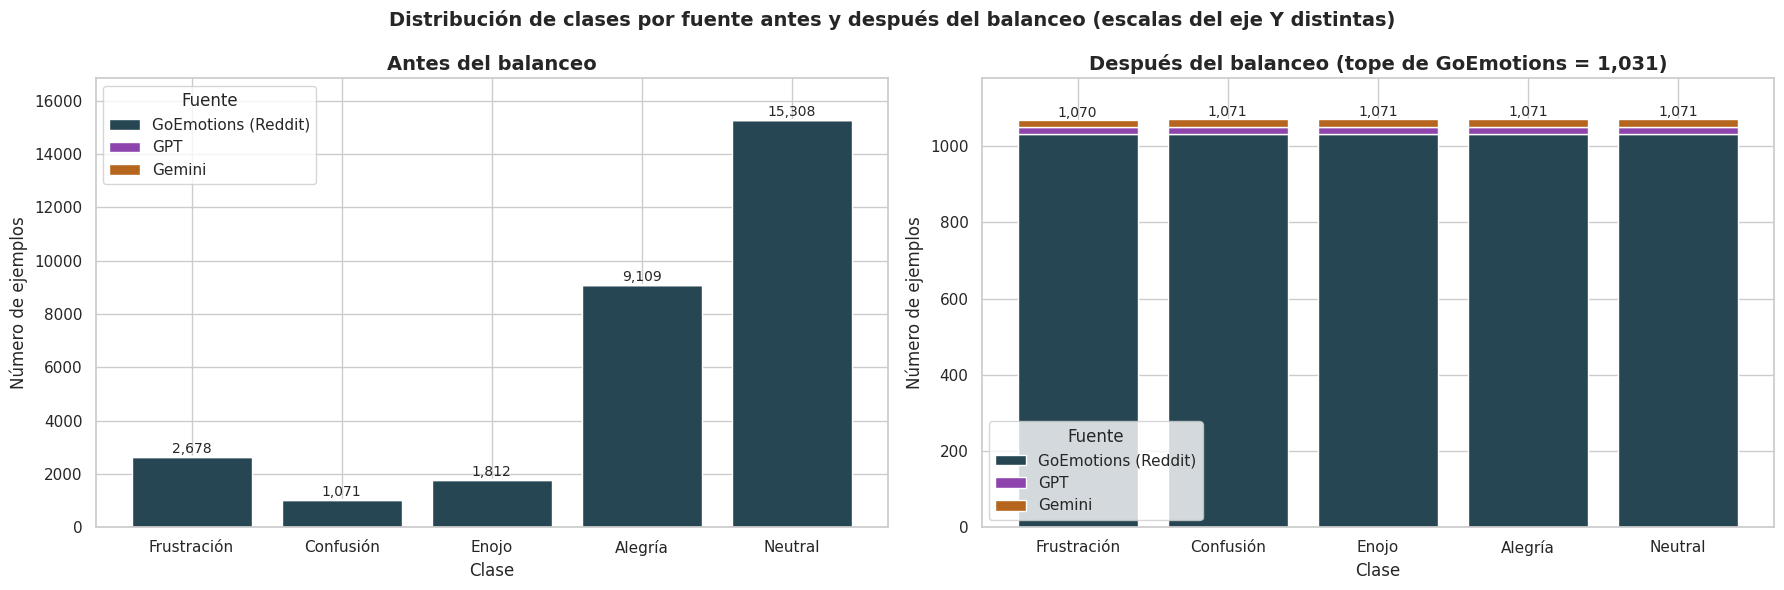

In [75]:
fig, ejes = plt.subplots(1, 2, figsize=(18, 6))
barras_apiladas_por_fuente(df_limpio, ejes[0], "Antes del balanceo")
barras_apiladas_por_fuente(df_balanceado, ejes[1], f"Después del balanceo (tope de GoEmotions = {TOPE_POR_CLASE:,})")
fig.suptitle("Distribución de clases por fuente antes y después del balanceo (escalas del eje Y distintas)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Dataset final.** Se conservan solo las cuatro columnas del esquema común: `texto`, `clase`, `emocion_original` y `fuente` (la columna auxiliar `texto_ingles` se descarta). El dataset se guarda en `DIRECTORIO_DATOS/dataset_final.csv` para no repetir todo el procesamiento en las secciones siguientes. En Colab, esa carpeta está en Google Drive, así que el archivo se conserva entre sesiones.

In [76]:
df_final = df_balanceado[["texto", "clase", "emocion_original", "fuente"]].copy()

tabla_final = pd.crosstab(df_final["clase"], df_final["fuente"], margins=True, margins_name="Total")
tabla_final = tabla_final.reindex(index=ORDEN_CLASES + ["Total"], columns=ORDEN_FUENTES + ["Total"], fill_value=0)
print("Dataset final: ejemplos por clase y fuente")
display(tabla_final)

porcentaje_sintetico_final = (df_final["fuente"] != "goemotions").groupby(df_final["clase"]).mean().reindex(ORDEN_CLASES) * 100
print("Porcentaje de ejemplos sintéticos por clase en el dataset final:")
display(porcentaje_sintetico_final.round(1).rename("% sintéticos").to_frame())
print(f"Porcentaje de ejemplos sintéticos en todo el dataset final: {(df_final['fuente'] != 'goemotions').mean():.1%}")

# Comprobación: los sintéticos deben repartirse de forma parecida entre clases. Si una clase tuviera
# muchos menos, la fuente empezaría a correlacionarse con la clase.
sinteticos_por_clase = df_final[df_final["fuente"] != "goemotions"]["clase"].value_counts().reindex(ORDEN_CLASES, fill_value=0)
media_sinteticos = sinteticos_por_clase.mean()
clases_con_pocos = sinteticos_por_clase[sinteticos_por_clase < 0.75 * media_sinteticos]
print(f"Sintéticos por clase: {sinteticos_por_clase.to_dict()} (media = {media_sinteticos:.1f})")
if clases_con_pocos.empty:
    print("Los sintéticos están repartidos de forma parecida entre las clases (ninguna por debajo del 75 % de la media).")
else:
    print(f"Advertencia: clases con muchos menos sintéticos que la media: {clases_con_pocos.to_dict()}")

os.makedirs(DIRECTORIO_DATOS, exist_ok=True)
df_final.to_csv(RUTA_DATASET_FINAL, index=False, encoding="utf-8")
print(f"Dataset final guardado en {RUTA_DATASET_FINAL}: {df_final.shape[0]:,} filas, {df_final.shape[1]} columnas")

df_final.head()

Dataset final: ejemplos por clase y fuente


fuente,goemotions,gpt,gemini,Total
clase,,,,
frustracion,1031,20,19,1070
confusion,1031,20,20,1071
enojo,1031,20,20,1071
alegria,1031,20,20,1071
neutral,1031,20,20,1071
Total,5155,100,99,5354


Porcentaje de ejemplos sintéticos por clase en el dataset final:


,% sintéticos
clase,
frustracion,3.6
confusion,3.7
enojo,3.7
alegria,3.7
neutral,3.7


Porcentaje de ejemplos sintéticos en todo el dataset final: 3.7%
Sintéticos por clase: {'frustracion': 39, 'confusion': 40, 'enojo': 40, 'alegria': 40, 'neutral': 40} (media = 39.8)
Los sintéticos están repartidos de forma parecida entre las clases (ninguna por debajo del 75 % de la media).
Dataset final guardado en /content/drive/MyDrive/analisis_sentimientos/data/dataset_final.csv: 5,354 filas, 4 columnas


,texto,clase,emocion_original,fuente
0,"Aquellos cuya ""autojusticia"" no excede la de los fariseos serán dejados fuera.",neutral,neutral,goemotions
1,¿No es por eso que [NOMBRE] está jugando con él?,confusion,confusion,goemotions
2,Un feo fuk,frustracion,annoyance,goemotions
3,> las barbas del cuello salen en manadas defendiendo su masculinidad no desarrollada/deformada. Eres un maricón deshonesto.,neutral,neutral,goemotions
4,"¿Lugares como por ejemplo? ¿Está [NOMBRE] proponiendo simplemente actualizar las barreras ya existentes o construir nuevas barreras. Y si esto último, ¿dónde específicamente?",confusion,confusion,goemotions


**Interpretación.** El tope quedó en 1.031 ejemplos por clase para GoEmotions, igual al tamaño de su clase minoritaria (`confusion`), porque este valor está entre 1.000 y 1.500. Se submuestrearon las clases frustración, enojo, alegría y neutral, y se conservó completa la clase confusión. El ratio de desbalance pasó de 14,3 a 1,0: el dataset final está prácticamente balanceado (1.070 ejemplos en frustración y 1.071 en cada una de las demás clases).

**Peso de los datos sintéticos.** Antes de eliminar las plantillas, cada clase tenía entre 298 y 300 mensajes sintéticos (tabla de 2.7.4); ahora los sintéticos son el 3,7 % del dataset final (entre el 3,6 % y el 3,7 % según la clase), con 39 o 40 mensajes por clase. La cifra anterior era engañosa: la mayor parte de esos mensajes eran variantes de la misma frase, que no aportaban información nueva y sí riesgo de *data leakage*. La cifra actual refleja cuántos mensajes educativos realmente distintos tiene el dataset. La comprobación de la celda anterior confirma que los sintéticos están repartidos de forma pareja entre clases (media de 39,8 por clase y ninguna por debajo del 75 % de la media), así que la fuente no permite predecir la clase. La contrapartida es que el peso del dominio educativo en el entrenamiento es pequeño: por eso en el modelado se comparará un modelo entrenado solo con GoEmotions con otro que añade los sintéticos (ver 2.14), y la evaluación sobre un conjunto de prueba escrito por personas cobra aún más importancia.

**Cifras clave de 2.13**

- Filas antes del balanceo: 29.978 → filas del dataset final: 5.354 (GoEmotions = 5.155, GPT = 100, Gemini = 99).
- Ejemplos por clase en el dataset final: frustración = 1.070, confusión = 1.071, enojo = 1.071, alegría = 1.071, neutral = 1.071.

### 2.14 Conclusiones del EDA

1. **Tamaño y composición del dataset final.** De los 54.263 comentarios originales de GoEmotions se conservan 5.155 tras filtrar los de una sola etiqueta (45.446), agrupar en las cinco clases (31.578), limpiar (29.779) y submuestrear; a ellos se suman 100 mensajes de GPT y 99 de Gemini. El dataset final tiene 5.354 ejemplos: frustración = 1.070, confusión = 1.071, enojo = 1.071, alegría = 1.071, neutral = 1.071. Los datos sintéticos aportan el 3,7 % del total.
2. **Desbalance.** El desbalance ya estaba en el dataset original (ratio de 185,1 entre la más y la menos frecuente de las 28 categorías). Tras la limpieza, el ratio entre las cinco clases era de 14,3 (`neutral`, con 15.308 ejemplos, frente a `confusion`, con 1.071), y un clasificador trivial que predijera siempre `neutral` tendría una exactitud de 51,1 %. Por eso se evaluará con **F1-macro** y no con exactitud. El submuestreo estratificado de GoEmotions con un tope de 1.031 ejemplos por clase redujo el ratio a 1,0, y el desbalance que pueda quedar se compensará con `class_weight="balanced"`.
3. **Datos reales frente a sintéticos.**
   - *Longitud:* los sintéticos tienen una mediana de 12 (GPT) y 10 (Gemini) palabras y un coeficiente de variación de 0,14 y 0,15, frente a 13 palabras y 0,52 en Reddit: su longitud típica es parecida, pero mucho más homogénea. El percentil 95 global (26 palabras) está muy por debajo del límite de 128 tokens del encoder, así que la truncación no es un problema.
   - *Vocabulario:* Reddit contiene términos ajenos a la educación ("gente", "tipo", "hombre", "juego", "amigo", "mierda"), mientras que los sintéticos se concentran en vocabulario académico ("aprobé", "módulo", "cuestionario", "apuntes").
   - *Muletillas:* los dos generadores usan las mismas fórmulas de inicio: el 15,8 % de los mensajes de frustración de Gemini y el 10,0 % de los de GPT empiezan con "siento que", y el 10,0 % de los mensajes de alegría de ambos, con "por fin".
   - *Diversidad:* con muestras del mismo tamaño, el distinct-2 es de 0,933 en Reddit frente a 0,669 en GPT y 0,885 en Gemini. La limpieza de casi duplicados (2.7.3) no eliminó ningún mensaje de GPT (0 %); fue la detección de plantillas (2.7.4) la que eliminó el 90,0 % de sus mensajes.
4. **Clases difíciles de separar.** Se anticipa que **frustración y enojo** serán las clases más difíciles de separar: `annoyance` y `anger` forman el par más frecuente de todo GoEmotions (348 comentarios multietiqueta), ambas clases comparten vocabulario negativo ("mierda", "maldita", "idiota") y la revisión de los sintéticos encontró un mensaje de enojo que se describe a sí mismo como "frustrante". También se esperan confusiones entre **frustración y confusión**, porque la expresión "no entiendo nada" aparece etiquetada como frustración en la plantilla que comparten GPT y Gemini, y como enojo en otro mensaje de Gemini. Esto se volverá a revisar en la visualización t-SNE y en la matriz de confusión.
5. **Plantillas en los datos sintéticos.** Los generadores no produjeron mensajes independientes: GPT usó 100 plantillas (20 por clase) con 10 variantes cada una, de modo que sus 1.000 mensajes eran en realidad 100 mensajes distintos; Gemini, 100 plantillas para sus 497 mensajes. Tras conservar un mensaje por plantilla, los sintéticos pasaron de 1.497 a 199 mensajes. **Lección metodológica:** un filtro de similitud sobre el texto completo (2.7.3) no detecta las plantillas generadas por LLMs, porque la parte variable domina la comparación en mensajes cortos; hay que analizar la **estructura** de los mensajes (inicios repetidos, enmascaramiento de la parte variable). Sin este paso, variantes de una misma frase habrían quedado en entrenamiento y en prueba de un mismo fold, inflando el F1.
6. **Limitaciones y mitigación.** GoEmotions aporta volumen y etiquetas humanas, pero proviene de Reddit, tiene errores de traducción (el 5,5 % de sus textos conserva al menos un 30 % de palabras sin traducir) y sus etiquetas se asignaron sobre el texto en inglés. Además, la traducción automática introdujo ruido de símbolos (cadenas de `¡` al final de la frase, `* * *`, `♪ ♪ ♪`) en 1.250 textos, que se limpió en 2.7.1 sin eliminar ejemplos. Los sintéticos aportan el dominio educativo, pero son menos diversos, tienen muletillas y su etiqueta la puso el generador. Se mitigan combinando las fuentes, eliminando casi duplicados y variantes de plantilla, y evaluando el modelo final con un conjunto de prueba escrito por personas.

**Trabajo para las secciones siguientes**

- **Experimento sobre el aporte de los datos sintéticos.** En el modelado se entrenarán y compararán dos versiones del clasificador, usando la columna `fuente` del dataset final:
  - **Modelo A:** entrenado solo con los comentarios de GoEmotions (`fuente == "goemotions"`).
  - **Modelo B:** entrenado con GoEmotions más los mensajes sintéticos de GPT y Gemini.

  El objetivo es medir si los mensajes sintéticos de contexto educativo mejoran o no el rendimiento. Para que la comparación sea justa, **ambos modelos se evaluarán sobre los mismos ejemplos de prueba**, y se reportará el rendimiento tanto en los ejemplos de GoEmotions como en los ejemplos educativos.
- **t-SNE:** además de colorear los embeddings por clase (lo pide la rúbrica), se hará una segunda visualización coloreada **por fuente**, para comprobar si los datos sintéticos forman grupos separados de los de GoEmotions (lo que indicaría que el encoder distingue el estilo del generador).
- **Conjunto de prueba humano:** el modelo final se evaluará sobre un conjunto pequeño de mensajes escritos por personas reales, que nunca se usa para entrenar.
- **Experimento entre generadores (opcional):** entrenar con GoEmotions + GPT y evaluar con Gemini, y viceversa, permitiría medir si el modelo aprende el estilo de un generador. Sin embargo, tras eliminar las plantillas cada generador aporta solo 100 mensajes (99 en Gemini), unos 20 por clase, una muestra demasiado pequeña para obtener conclusiones fiables, así que este experimento queda como opcional.
- **Regeneración de datos sintéticos:** si en el futuro se generan nuevos datos, el prompt debe pedir **variedad estructural** (frases construidas de forma distinta, no la misma frase cambiando la materia), y el análisis de plantillas de 2.7.4 debe repetirse sobre los datos nuevos antes de usarlos.

---

## 3. Extracción de características (Feature Extraction)

**Por qué hace falta extraer características.** Los clasificadores que se usarán en el modelado (SVM, regresión logística, kNN…) no trabajan con texto: reciben, para cada ejemplo, un vector numérico de tamaño fijo. La extracción de características convierte cada mensaje en ese vector, y de la calidad de la representación depende buena parte del rendimiento final: un clasificador solo puede separar las emociones si la representación conserva la información que las distingue.

**Técnicas de representación de texto**

| Técnica | Qué representa | Limitación principal |
|---|---|---|
| Bag of Words | Frecuencia de cada palabra del vocabulario | Ignora el orden y el significado; todas las palabras pesan igual |
| TF-IDF [6] | Bag of Words ponderado: reduce el peso de las palabras comunes a muchos textos | No captura el significado: sinónimos y paráfrasis son vectores distintos |
| Word embeddings promediados (Word2Vec [7], FastText [8]) | Promedio de vectores de palabras aprendidos en grandes corpus | Al promediar se pierde el contexto y el orden ("no me gusta" ≈ "me gusta") |
| Sentence embeddings (Sentence-BERT [4]) | Un vector por frase completa, calculado con un transformer que tiene en cuenta el contexto | Mayor costo de cálculo, aunque aquí se calcula una sola vez |

TF y IDF no son técnicas separadas, sino los dos factores de TF-IDF: la frecuencia del término en el texto (*term frequency*) y la rareza del término en el conjunto de textos (*inverse document frequency*).

**Elección y justificación.** La representación principal serán los **sentence embeddings de un modelo Sentence-BERT multilingüe preentrenado y congelado**, y TF-IDF se mantiene como **línea base**:

- Es la técnica de **transfer learning** que pide el proyecto: aprovecha lo que el modelo aprendió con millones de frases, mientras que Bag of Words y TF-IDF se construyen solo con este dataset.
- Las emociones dependen del **significado**, no de palabras clave: "No entiendo nada" y "estoy perdido con este tema" expresan confusión sin compartir ninguna palabra.
- Captura el **contexto y la negación**: "no estoy contento" y "estoy contento" tienen casi las mismas palabras, pero un significado opuesto.
- Es más robusto al **ruido de la traducción automática** y a la jerga observados en el EDA (2.7.1 y 2.12.2), porque una palabra mal traducida o desconocida no anula el significado del resto de la frase.
- El dataset es **pequeño** (unos 5.000 ejemplos) para aprender desde cero qué palabras importan; el encoder ya trae ese conocimiento.
- TF-IDF se conserva como **línea base** para demostrar con un test estadístico, en la sección de modelado, si el transfer learning aporta una mejora real.

Bag of Words y los word embeddings promediados no se implementan: Bag of Words es una versión menos informativa de TF-IDF (sin la ponderación por rareza), y los word embeddings promediados tienen la misma ventaja semántica que Sentence-BERT pero pierden el contexto y la negación, que son importantes para distinguir emociones.

**Diferencia con el uso de TF-IDF en el EDA.** En la Sección 2 se usó TF-IDF como **herramienta de análisis** (detección de casi duplicados en 2.7.3 y vocabulario por clase en 2.10.2), sobre copias normalizadas del texto. En esta sección se trata de la **representación que recibe el clasificador**, calculada sobre el texto natural, tal como se guardó en el dataset final.

**Independencia de la Sección 2.** Esta sección solo usa la celda de configuración general (importaciones, semilla, rutas y paletas) y el archivo `dataset_final.csv`, de modo que puede ejecutarse sin repetir el EDA: basta con ejecutar la configuración general y, a continuación, las celdas de esta sección.

### 3.1 Carga del dataset final

Se carga el dataset que generó la Sección 2 y se comprueba que coincide con el resultado de 2.13. Dos detalles de la lectura:

- Se usa `keep_default_na=False` para que pandas no convierta en valores nulos textos que, por casualidad, coinciden con las marcas de nulo que reconoce por defecto (por ejemplo, un comentario que diga solo "NA" o "None").
- El **orden de las filas se conserva en toda la sección**: la matriz de embeddings se alinea fila a fila con este DataFrame, así que la fila *i* de la matriz corresponde siempre al texto *i*, a su clase *i* y a su fuente *i*.

In [77]:
# Prompt (LLM): "3.1 Cargar dataset_final.csv desde RUTA_DATASET_FINAL (UTF-8), mostrar shape, columnas y la tabla
# clase x fuente; verificar con assert que no hay textos nulos ni vacíos y que clases y fuentes son exactamente las
# de ORDEN_CLASES y ORDEN_FUENTES; crear textos, y y fuente conservando el orden de las filas."
import hashlib
import json
import time

df_modelo = pd.read_csv(RUTA_DATASET_FINAL, encoding="utf-8", keep_default_na=False)
print(f"Dimensiones: {df_modelo.shape}")
print(f"Columnas: {list(df_modelo.columns)}")

tabla_clase_fuente_modelo = pd.crosstab(df_modelo["clase"], df_modelo["fuente"], margins=True, margins_name="Total")
print("\nEjemplos por clase y fuente (debe coincidir con la tabla final de 2.13):")
display(tabla_clase_fuente_modelo.reindex(index=ORDEN_CLASES + ["Total"], columns=ORDEN_FUENTES + ["Total"],
                                          fill_value=0))

# Verificaciones
assert df_modelo["texto"].notna().all(), "Hay textos nulos"
assert (df_modelo["texto"].str.strip() != "").all(), "Hay textos vacíos"
assert set(df_modelo["clase"]) == set(ORDEN_CLASES), f"Clases inesperadas: {set(df_modelo['clase'])}"
assert set(df_modelo["fuente"]) == set(ORDEN_FUENTES), f"Fuentes inesperadas: {set(df_modelo['fuente'])}"
print("Verificaciones correctas: sin textos nulos ni vacíos; clases y fuentes esperadas.")

# Variables de entrada para el resto de la notebook (mismo orden que df_modelo)
textos = df_modelo["texto"].tolist()
y = df_modelo["clase"].to_numpy()
fuente = df_modelo["fuente"].to_numpy()

# Codificación entera de las etiquetas, por si algún modelo la necesita (orden de ORDEN_CLASES)
CLASE_A_ENTERO = {clase: i for i, clase in enumerate(ORDEN_CLASES)}
ENTERO_A_CLASE = {i: clase for clase, i in CLASE_A_ENTERO.items()}
y_entero = df_modelo["clase"].map(CLASE_A_ENTERO).to_numpy()
print(f"Mapeo de clases a enteros: {CLASE_A_ENTERO}")

Dimensiones: (5354, 4)
Columnas: ['texto', 'clase', 'emocion_original', 'fuente']

Ejemplos por clase y fuente (debe coincidir con la tabla final de 2.13):


fuente,goemotions,gpt,gemini,Total
clase,,,,
frustracion,1031,20,19,1070
confusion,1031,20,20,1071
enojo,1031,20,20,1071
alegria,1031,20,20,1071
neutral,1031,20,20,1071
Total,5155,100,99,5354


Verificaciones correctas: sin textos nulos ni vacíos; clases y fuentes esperadas.
Mapeo de clases a enteros: {'frustracion': 0, 'confusion': 1, 'enojo': 2, 'alegria': 3, 'neutral': 4}


### 3.2 Elección del encoder

Se usa el modelo **`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`**, de la biblioteca `sentence-transformers` [4], [9].

**Ficha del modelo**

| Característica | Valor |
|---|---|
| Idiomas | Multilingüe (más de 50 idiomas, incluido el español) |
| Objetivo de entrenamiento | Que frases con el mismo significado (paráfrasis) tengan vectores cercanos, aunque estén escritas con palabras distintas o en idiomas distintos |
| Dimensión de salida | 384 |
| Longitud máxima de entrada | 128 tokens (el resto del texto se trunca) |
| Arquitectura | Transformer MiniLM de 12 capas, con *mean pooling* de los vectores de los tokens para obtener un único vector por frase |
| Origen | Destilación de conocimiento: un modelo "alumno" multilingüe aprende a reproducir los embeddings de un modelo "maestro" monolingüe en inglés, usando frases traducidas [10]. Se basa en la arquitectura Sentence-BERT [4] |

El modelo se usa **congelado**: solo se utiliza para transformar los textos en vectores, sin reentrenarlo (*feature extraction*). Es la forma más simple de transfer learning y la adecuada para un dataset de unos 5.000 ejemplos, en el que ajustar los millones de parámetros del transformer (*fine-tuning*) tendría un alto riesgo de sobreajuste y un costo computacional mucho mayor.

**Por qué el modelo ligero y no `paraphrase-multilingual-mpnet-base-v2`.** La alternativa más grande de la misma familia produce vectores de 768 dimensiones y suele dar resultados algo mejores, pero es varias veces más lenta y duplica la dimensión de los vectores. Eso importa porque en el modelado se usará un *repeated k-fold* de 10 × 10 (unos 100 entrenamientos por modelo) junto con la optimización de hiperparámetros: con vectores de 384 dimensiones, cada entrenamiento es más rápido y los modelos sensibles a la dimensión (como kNN) se ven menos afectados. Probar el modelo grande queda como trabajo futuro.

El cálculo funciona en CPU, pero es bastante más rápido con GPU. En Colab se recomienda activarla en *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4*.

In [78]:
# Prompt (LLM): "3.2 Instalar sentence-transformers si no está disponible; usar el modelo
# sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 en la constante NOMBRE_ENCODER; detectar si hay GPU
# con torch.cuda.is_available() e imprimir el dispositivo; cargar el modelo e imprimir su dimensión de salida y su
# max_seq_length, confirmando 384 y 128."
import importlib.util

if importlib.util.find_spec("sentence_transformers") is None:
    get_ipython().run_line_magic("pip", "install -q sentence-transformers")

import torch
from sentence_transformers import SentenceTransformer

NOMBRE_ENCODER = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
if DISPOSITIVO == "cuda":
    print(f"Dispositivo: GPU ({torch.cuda.get_device_name(0)})")
else:
    print("Dispositivo: CPU (no hay GPU disponible; el cálculo de los embeddings será más lento)")

modelo_encoder = SentenceTransformer(NOMBRE_ENCODER, device=DISPOSITIVO)
DIMENSION_EMBEDDING = modelo_encoder.get_sentence_embedding_dimension()
LONGITUD_MAXIMA_TOKENS = modelo_encoder.max_seq_length

print(f"Modelo: {NOMBRE_ENCODER}")
print(f"Dimensión de los embeddings: {DIMENSION_EMBEDDING}")
print(f"Longitud máxima de entrada (max_seq_length): {LONGITUD_MAXIMA_TOKENS} tokens")
assert DIMENSION_EMBEDDING == 384, "La dimensión de salida no es la esperada (384)"
assert LONGITUD_MAXIMA_TOKENS == 128, "La longitud máxima de entrada no es la esperada (128)"

Dispositivo: GPU (Tesla T4)


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Modelo: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Dimensión de los embeddings: 384
Longitud máxima de entrada (max_seq_length): 128 tokens


/tmp/ipykernel_182/69932528.py:22: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  DIMENSION_EMBEDDING = modelo_encoder.get_sentence_embedding_dimension()


### 3.3 Verificación de la longitud en tokens

En el EDA (2.9) la longitud se midió en palabras y se estimó que cada palabra equivale a unos 2 tokens como máximo. Aquí se mide con el **tokenizador real** del encoder, que es el que decide qué parte de cada texto se trunca. Se cuentan todos los tokens, incluidos los dos tokens especiales que el modelo añade al inicio y al final de cada texto, porque también ocupan espacio dentro del límite de 128.

Además, se calcula cuántos tokens produce cada palabra (sin contar los tokens especiales), para contrastar la estimación de 2.9.

In [79]:
# Prompt (LLM): "3.3 Tokenizar todos los textos con el tokenizador del modelo y contar los tokens de cada uno,
# incluidos los especiales; mostrar media, mediana, p95, p99 y máximo por fuente; contar cuántos textos superan los
# 128 tokens por fuente y en total, con 2 o 3 ejemplos; histograma con una línea vertical en 128."
codificacion = modelo_encoder.tokenizer(textos, add_special_tokens=True, truncation=False)
n_tokens = np.array([len(ids) for ids in codificacion["input_ids"]])
n_tokens_especiales = len(modelo_encoder.tokenizer("")["input_ids"])  # tokens que se añaden a un texto vacío
n_palabras_modelo = df_modelo["texto"].str.split().str.len().to_numpy()

df_tokens = pd.DataFrame({
    "fuente": fuente,
    "n_tokens": n_tokens,
    "tokens_por_palabra": (n_tokens - n_tokens_especiales) / n_palabras_modelo,
})


def estadisticos_tokens(serie):
    return pd.Series({
        "media": serie.mean(),
        "mediana": serie.median(),
        "p95": serie.quantile(0.95),
        "p99": serie.quantile(0.99),
        "máximo": serie.max(),
    })


tabla_tokens = df_tokens.groupby("fuente")["n_tokens"].apply(estadisticos_tokens).unstack().reindex(ORDEN_FUENTES)
tabla_tokens.loc["Total"] = estadisticos_tokens(df_tokens["n_tokens"])
print(f"Tokens especiales por texto: {n_tokens_especiales}")
print("Número de tokens por texto (incluidos los especiales):")
display(tabla_tokens.round(1))

print("Tokens por palabra (sin los tokens especiales):")
display(df_tokens.groupby("fuente")["tokens_por_palabra"].agg(["mean", "median", lambda s: s.quantile(0.95)])
        .reindex(ORDEN_FUENTES).set_axis(["media", "mediana", "p95"], axis=1).round(2))

truncados = n_tokens > LONGITUD_MAXIMA_TOKENS
tabla_truncados = pd.DataFrame({
    "textos": df_tokens["fuente"].value_counts().reindex(ORDEN_FUENTES),
    f"con más de {LONGITUD_MAXIMA_TOKENS} tokens": df_tokens.loc[truncados, "fuente"].value_counts()
        .reindex(ORDEN_FUENTES, fill_value=0),
})
tabla_truncados.loc["Total"] = tabla_truncados.sum()
tabla_truncados["% truncado"] = (tabla_truncados.iloc[:, 1] / tabla_truncados["textos"] * 100).round(2)
print("Textos que se truncarán:")
display(tabla_truncados)

if truncados.any():
    print("Ejemplos de textos truncados:")
    display(df_modelo.loc[truncados, ["texto", "clase", "fuente"]]
            .assign(n_tokens=n_tokens[truncados]).head(3))
else:
    print("Ningún texto supera el límite de tokens: no habrá truncación.")

Tokens especiales por texto: 2
Número de tokens por texto (incluidos los especiales):


,media,mediana,p95,p99,máximo
fuente,,,,,
goemotions,22.2,21.0,39.0,44.0,76.0
gpt,17.6,18.0,22.0,23.0,24.0
gemini,16.1,16.0,20.0,20.0,20.0
Total,22.0,21.0,38.0,44.0,76.0


Tokens por palabra (sin los tokens especiales):


,media,mediana,p95
fuente,,,
goemotions,1.54,1.46,2.20
gpt,1.32,1.30,1.55
gemini,1.38,1.33,1.70


Textos que se truncarán:


,textos,con más de 128 tokens,% truncado
fuente,,,
goemotions,5155,0,0.0
gpt,100,0,0.0
gemini,99,0,0.0
Total,5354,0,0.0


Ningún texto supera el límite de tokens: no habrá truncación.


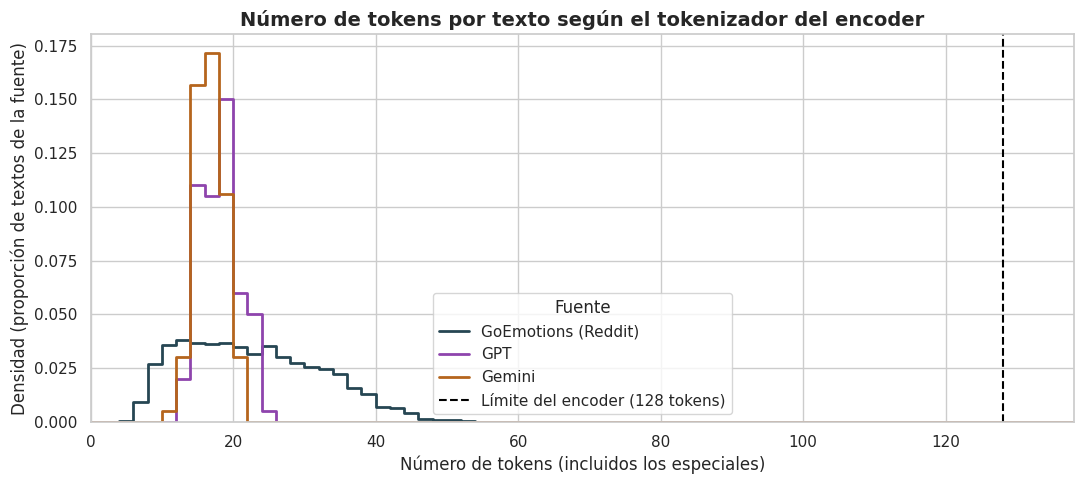

In [80]:
fig, ax = plt.subplots(figsize=(11, 5))
limite_x = max(LONGITUD_MAXIMA_TOKENS, n_tokens.max()) + 10
for nombre_fuente in ORDEN_FUENTES:
    datos = df_tokens.loc[df_tokens["fuente"] == nombre_fuente, "n_tokens"]
    sns.histplot(datos, binwidth=2, binrange=(0, limite_x), stat="density", element="step", fill=False,
                 linewidth=2, color=PALETA_FUENTES[nombre_fuente], label=NOMBRES_FUENTES[nombre_fuente], ax=ax)
ax.axvline(LONGITUD_MAXIMA_TOKENS, color="black", linestyle="--", linewidth=1.5,
           label=f"Límite del encoder ({LONGITUD_MAXIMA_TOKENS} tokens)")
ax.set_xlim(0, limite_x)
ax.set_title("Número de tokens por texto según el tokenizador del encoder")
ax.set_xlabel("Número de tokens (incluidos los especiales)")
ax.set_ylabel("Densidad (proporción de textos de la fuente)")
ax.legend(title="Fuente")
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar: indicar la mediana, el percentil 95 y el máximo de tokens por fuente, y cuántos textos superan los 128 tokens ([COMPLETAR] en total, [COMPLETAR] %). Comparar los tokens por palabra medidos ([COMPLETAR] de media) con la estimación de 2 tokens por palabra de 2.9 y decir si se confirma o se corrige. Concluir si la truncación afecta a una proporción relevante de los textos; si hay textos truncados, comentar si la parte que se pierde es importante para la emoción.]

### 3.4 Cálculo de los embeddings (con caché)

Se calcula un embedding de 384 dimensiones para cada texto, en lotes de 64 y con barra de progreso. Los vectores **no se normalizan** en este paso (`normalize_embeddings=False`): el escalado que necesite cada clasificador se hará dentro de su `Pipeline` en la sección de modelado. Para las comprobaciones de similitud de 3.5, la similitud coseno se calcula aparte.

**Caché en Drive.** Calcular los embeddings es el paso más lento de la sección, así que el resultado se guarda en `DIRECTORIO_DATOS` como un archivo `.npy`, junto con un archivo JSON de metadatos: el nombre del modelo, el número de filas y una **huella del dataset**, que es un hash SHA-256 de los textos y las clases en el orden del DataFrame. Al volver a ejecutar la celda:

- si el `.npy` existe **y** los metadatos coinciden (mismo modelo, mismo número de filas y misma huella), se carga en lugar de recalcularlo;
- si no coinciden (por ejemplo, porque se regeneró `dataset_final.csv` o se cambió de modelo), se recalcula y se sobrescribe.

La huella garantiza que nunca se usen embeddings de una versión anterior del dataset: basta con que cambie un texto, una etiqueta o el orden de las filas para que la caché se descarte.

In [81]:
# Prompt (LLM): "3.4 Calcular los embeddings con modelo.encode en lotes de 64, con barra de progreso, como arreglo
# float32 (n_textos, 384), sin normalizar. Caché en DIRECTORIO_DATOS: guardar embeddings_<nombre corto>.npy y un JSON
# con el modelo, el número de filas y un hash de los textos y clases; si existe y coincide, cargarlo; si no,
# recalcular y sobrescribir. Imprimir si se cargó o se recalculó y el tiempo empleado."
NOMBRE_CORTO_ENCODER = NOMBRE_ENCODER.split("/")[-1]
RUTA_EMBEDDINGS = os.path.join(DIRECTORIO_DATOS, f"embeddings_{NOMBRE_CORTO_ENCODER}.npy")
RUTA_METADATOS_EMBEDDINGS = os.path.join(DIRECTORIO_DATOS, f"embeddings_{NOMBRE_CORTO_ENCODER}.json")
TAMANO_LOTE = 64


def huella_dataset(lista_textos, lista_clases):
    """Hash SHA-256 de los textos y las clases, en orden. Los separadores evitan que dos datasets
    distintos produzcan la misma concatenación."""
    huella = hashlib.sha256()
    for texto, clase in zip(lista_textos, lista_clases):
        huella.update(texto.encode("utf-8") + b"\x1f" + str(clase).encode("utf-8") + b"\x1e")
    return huella.hexdigest()


metadatos_actuales = {
    "modelo": NOMBRE_ENCODER,
    "n_filas": len(textos),
    "huella_dataset": huella_dataset(textos, y),
}


def cargar_cache_embeddings():
    """Devuelve (matriz, motivo). La matriz es None si la caché no existe o no corresponde al dataset actual."""
    if not (os.path.exists(RUTA_EMBEDDINGS) and os.path.exists(RUTA_METADATOS_EMBEDDINGS)):
        return None, "no existe caché"
    with open(RUTA_METADATOS_EMBEDDINGS, encoding="utf-8") as archivo:
        metadatos_guardados = json.load(archivo)
    distintos = [clave for clave, valor in metadatos_actuales.items() if metadatos_guardados.get(clave) != valor]
    if distintos:
        return None, f"la caché no coincide con el dataset actual (campos distintos: {', '.join(distintos)})"
    matriz = np.load(RUTA_EMBEDDINGS)
    if matriz.shape != (len(textos), DIMENSION_EMBEDDING):
        return None, f"la matriz guardada tiene una forma inesperada {matriz.shape}"
    return matriz, "caché válida"


inicio = time.perf_counter()
X_embeddings, motivo = cargar_cache_embeddings()
if X_embeddings is None:
    print(f"Se recalculan los embeddings: {motivo}.")
    X_embeddings = modelo_encoder.encode(
        textos,
        batch_size=TAMANO_LOTE,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=False,
    ).astype(np.float32)
    os.makedirs(DIRECTORIO_DATOS, exist_ok=True)
    np.save(RUTA_EMBEDDINGS, X_embeddings)
    with open(RUTA_METADATOS_EMBEDDINGS, "w", encoding="utf-8") as archivo:
        json.dump({**metadatos_actuales, "dimension": DIMENSION_EMBEDDING,
                   "fecha": time.strftime("%Y-%m-%d %H:%M:%S")}, archivo, ensure_ascii=False, indent=2)
    origen_embeddings = "recalculados y guardados en la caché"
else:
    origen_embeddings = "cargados de la caché"
duracion = time.perf_counter() - inicio

print(f"Embeddings {origen_embeddings} en {duracion:.1f} s.")
print(f"Archivo: {RUTA_EMBEDDINGS}")
print(f"Forma de X_embeddings: {X_embeddings.shape}, tipo: {X_embeddings.dtype}")

Embeddings cargados de la caché en 2.0 s.
Archivo: /content/drive/MyDrive/analisis_sentimientos/data/embeddings_paraphrase-multilingual-MiniLM-L12-v2.npy
Forma de X_embeddings: (5354, 384), tipo: float32


**Por qué calcular los embeddings fuera del pipeline no produce *data leakage*.** Es habitual exigir que toda transformación se ajuste dentro de cada fold de la validación cruzada. Aquí no hace falta, por tres razones:

- **El encoder está congelado.** No se entrena ni se ajusta con estos datos: sus parámetros son los mismos antes y después de procesar el dataset, así que no aprende nada de los textos de prueba.
- **Cada texto se transforma de forma independiente de los demás.** El embedding de un mensaje depende solo de ese mensaje, como una función fija aplicada fila a fila, igual que pasar el texto a minúsculas. No interviene ninguna estadística calculada sobre el conjunto de datos (medias, vocabulario, frecuencias).
- **Por eso da lo mismo calcularlos antes o dentro de cada fold:** el vector de cada texto sería idéntico en ambos casos. Calcularlos una sola vez da exactamente el mismo resultado y ahorra repetir el cálculo en los 100 entrenamientos del *repeated k-fold*.

En cambio, todo lo que **sí aprende de los datos** (el escalado, la selección de características, el vectorizador TF-IDF de 3.6 y el propio clasificador) irá dentro del `Pipeline` y se ajustará solo con el conjunto de entrenamiento de cada fold.

### 3.5 Comprobaciones de los embeddings

Antes de usar los vectores en los modelos se verifica que son correctos y que capturan significado, con tres comprobaciones:

1. **Integridad:** forma de la matriz, ausencia de valores `NaN` o infinitos y norma L2 de los vectores (un vector de norma cero o anormalmente grande indicaría un problema en el cálculo).
2. **Similitud coseno media entre clases y entre fuentes:** si el encoder captura la emoción, los textos de una misma clase deberían estar, en promedio, más cerca entre sí que de los de otras clases.
3. **Vecinos más cercanos** de algunos textos de ejemplo, para ver qué tipo de parecido captura el encoder.

La similitud coseno se calcula sobre una **copia normalizada** de los vectores (cada uno dividido por su norma), de modo que el producto escalar entre dos vectores es su similitud coseno. Esa copia solo se usa en estas comprobaciones; `X_embeddings` no se modifica.

In [82]:
# Prompt (LLM): "3.5.1 Integridad: forma de la matriz, ausencia de NaN o infinitos y estadísticos de la norma L2 de
# los vectores (media, mínimo, máximo)."
normas = np.linalg.norm(X_embeddings, axis=1)
print(f"Forma: {X_embeddings.shape} (filas = textos del dataset final: {len(textos):,})")
print(f"Valores NaN: {np.isnan(X_embeddings).sum():,} | valores infinitos: {np.isinf(X_embeddings).sum():,}")
print(f"Norma L2 de los vectores: media = {normas.mean():.3f}, mínimo = {normas.min():.3f}, máximo = {normas.max():.3f}")
assert X_embeddings.shape == (len(textos), DIMENSION_EMBEDDING)
assert np.isfinite(X_embeddings).all(), "Hay valores NaN o infinitos en los embeddings"
assert (normas > 0).all(), "Hay vectores nulos"

# Copia normalizada, SOLO para las comprobaciones de similitud de esta subsección
X_unitarios = X_embeddings / normas[:, None]

Forma: (5354, 384) (filas = textos del dataset final: 5,354)
Valores NaN: 0 | valores infinitos: 0
Norma L2 de los vectores: media = 3.731, mínimo = 2.239, máximo = 6.153


**Similitud coseno media entre clases.** Se toma una muestra estratificada de 300 textos por clase (con la semilla fija) y se calcula una matriz 5 × 5: cada celda es la similitud coseno media entre los textos de dos clases, y la diagonal es la similitud media **dentro** de cada clase (sin contar la similitud de cada texto consigo mismo, que siempre vale 1). Usar una muestra evita calcular innecesariamente la matriz completa de unos 5.000 × 5.000 pares.

Como el dataset final tiene unos 1.031 ejemplos de GoEmotions y unos 40 sintéticos por clase, la muestra está formada sobre todo por comentarios de GoEmotions.

Textos por clase en la muestra: {'frustracion': 300, 'confusion': 300, 'enojo': 300, 'alegria': 300, 'neutral': 300}
Textos por fuente en la muestra: {'goemotions': 300, 'gpt': 100, 'gemini': 99}


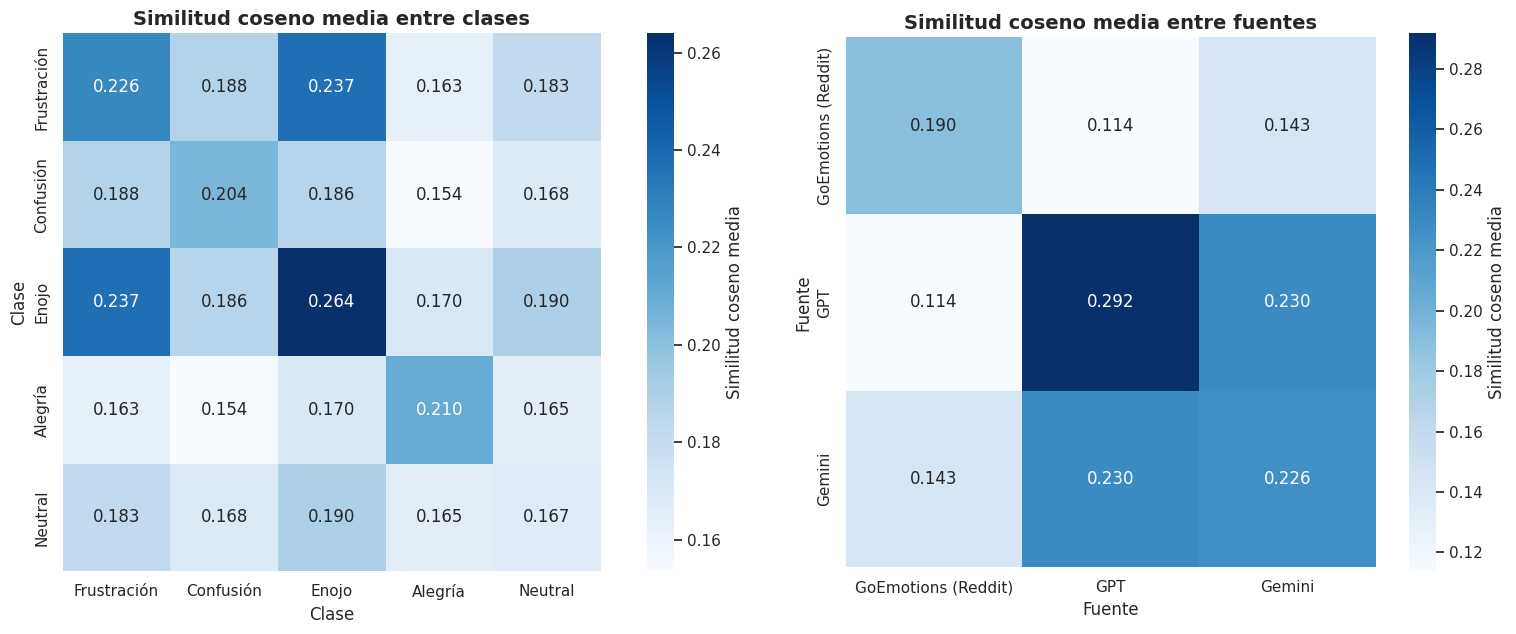

Similitud dentro de cada clase frente a la similitud con las demás:


,dentro de la clase,media con las demás clases,diferencia
frustracion,0.226,0.193,0.034
confusion,0.204,0.174,0.030
enojo,0.264,0.196,0.068
alegria,0.210,0.163,0.047
neutral,0.167,0.177,-0.009


Pares de clases distintas, de más a menos parecidos:


,clase 1,clase 2,similitud media
0,Frustración,Enojo,0.237
1,Enojo,Neutral,0.190
2,Frustración,Confusión,0.188
3,Confusión,Enojo,0.186
4,Frustración,Neutral,0.183
5,Enojo,Alegría,0.170
6,Confusión,Neutral,0.168
7,Alegría,Neutral,0.165
8,Frustración,Alegría,0.163
9,Confusión,Alegría,0.154


In [83]:
# Prompt (LLM): "3.5.2 Matriz 5x5 con la similitud coseno media entre los textos de cada par de clases (la diagonal es
# la similitud dentro de la clase), sobre una muestra estratificada de 300 textos por clase con la semilla fija;
# mostrarla como heatmap con los nombres de las clases. 3.5.3 Repetir con una matriz 3x3 por fuente."
TEXTOS_POR_GRUPO = 300


def similitud_media_entre_grupos(columna, orden, n_por_grupo=TEXTOS_POR_GRUPO):
    """Similitud coseno media entre los grupos de `columna` (clase o fuente), sobre una muestra estratificada.
    En la diagonal se excluye la similitud de cada texto consigo mismo."""
    posiciones = {}
    for grupo in orden:
        filas_grupo = df_modelo[df_modelo[columna] == grupo]
        muestra = filas_grupo.sample(min(n_por_grupo, len(filas_grupo)), random_state=SEMILLA)
        posiciones[grupo] = df_modelo.index.get_indexer(muestra.index)
    matriz = pd.DataFrame(index=orden, columns=orden, dtype=float)
    for a in orden:
        for b in orden:
            similitudes = X_unitarios[posiciones[a]] @ X_unitarios[posiciones[b]].T
            if a == b:
                n = len(posiciones[a])
                matriz.loc[a, b] = (similitudes.sum() - np.trace(similitudes)) / (n * (n - 1))
            else:
                matriz.loc[a, b] = similitudes.mean()
    tamanos = {grupo: len(p) for grupo, p in posiciones.items()}
    return matriz, tamanos


def graficar_similitud(matriz, nombres, titulo, ax):
    sns.heatmap(matriz.astype(float), annot=True, fmt=".3f", cmap="Blues", square=True,
                xticklabels=[nombres[g] for g in matriz.columns], yticklabels=[nombres[g] for g in matriz.index],
                cbar_kws={"label": "Similitud coseno media"}, ax=ax)
    ax.set_title(titulo)


similitud_clases, tamanos_clases = similitud_media_entre_grupos("clase", ORDEN_CLASES)
similitud_fuentes, tamanos_fuentes = similitud_media_entre_grupos("fuente", ORDEN_FUENTES)
print(f"Textos por clase en la muestra: {tamanos_clases}")
print(f"Textos por fuente en la muestra: {tamanos_fuentes}")

fig, ejes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [5, 3.6]})
graficar_similitud(similitud_clases, NOMBRES_CLASES, "Similitud coseno media entre clases", ejes[0])
ejes[0].set_xlabel("Clase")
ejes[0].set_ylabel("Clase")
graficar_similitud(similitud_fuentes, NOMBRES_FUENTES, "Similitud coseno media entre fuentes", ejes[1])
ejes[1].set_xlabel("Fuente")
ejes[1].set_ylabel("Fuente")
plt.tight_layout()
plt.show()

# Resumen numérico: similitud dentro de cada clase frente a la media con las demás clases
resumen_similitud = pd.DataFrame({
    "dentro de la clase": np.diag(similitud_clases.astype(float)),
    "media con las demás clases": [similitud_clases.loc[c].drop(c).mean() for c in ORDEN_CLASES],
}, index=ORDEN_CLASES)
resumen_similitud["diferencia"] = resumen_similitud["dentro de la clase"] - resumen_similitud["media con las demás clases"]
print("Similitud dentro de cada clase frente a la similitud con las demás:")
display(resumen_similitud.round(3))

pares_clases = pd.DataFrame(
    [(NOMBRES_CLASES[a], NOMBRES_CLASES[b], similitud_clases.loc[a, b])
     for i, a in enumerate(ORDEN_CLASES) for b in ORDEN_CLASES[i + 1:]],
    columns=["clase 1", "clase 2", "similitud media"],
).sort_values("similitud media", ascending=False).reset_index(drop=True)
print("Pares de clases distintas, de más a menos parecidos:")
display(pares_clases.round(3))

**Vecinos más cercanos.** Se elige, con la semilla fija, un mensaje **sintético** de cada clase (son los de contexto educativo, el escenario del tutor) y se muestran sus 5 vecinos más cercanos en todo el dataset por similitud coseno, con su clase y su fuente. En este punto **todavía no hay ningún modelo entrenado**: los vecinos reflejan solo lo que el encoder preentrenado considera parecido, sin haber visto ninguna etiqueta.

In [84]:
# Prompt (LLM): "3.5.4 Elegir con la semilla fija un texto de ejemplo por clase, de origen sintético, y mostrar sus
# 5 vecinos más cercanos por similitud coseno, con su texto, su clase, su fuente y la similitud."
N_VECINOS = 5
resumen_vecinos = []
for clase in ORDEN_CLASES:
    candidatos = df_modelo[(df_modelo["clase"] == clase) & (df_modelo["fuente"] != "goemotions")]
    posicion_consulta = df_modelo.index.get_loc(candidatos.sample(1, random_state=SEMILLA).index[0])

    similitudes = X_unitarios @ X_unitarios[posicion_consulta]
    similitudes[posicion_consulta] = -np.inf  # excluir el propio texto
    vecinos = np.argsort(-similitudes)[:N_VECINOS]

    print(f"\n=== {NOMBRES_CLASES[clase]} | consulta ({NOMBRES_FUENTES[fuente[posicion_consulta]]}): "
          f"«{textos[posicion_consulta]}» ===")
    display(pd.DataFrame({
        "texto": [textos[i] for i in vecinos],
        "clase": y[vecinos],
        "fuente": fuente[vecinos],
        "similitud": similitudes[vecinos].round(3),
    }, index=pd.RangeIndex(1, N_VECINOS + 1, name="vecino")))
    resumen_vecinos.append({
        "clase de la consulta": clase,
        "vecinos de la misma clase": int((y[vecinos] == clase).sum()),
        "vecinos sintéticos": int((fuente[vecinos] != "goemotions").sum()),
    })

print(f"\nResumen de los {N_VECINOS} vecinos más cercanos de cada consulta:")
display(pd.DataFrame(resumen_vecinos).set_index("clase de la consulta"))


=== Frustración | consulta (GPT): «No avanzo nada con la clase de matemáticas, por más tiempo que le dedique.» ===


,texto,clase,fuente,similitud
vecino,,,,
1,"Me da igual sacar buena o mala nota, con aprobar matemáticas me basta.",neutral,gemini,0.803
2,¡Me da rabia que la clase de matemáticas sea tan desorganizado!,enojo,gpt,0.753
3,¡Otra vez lo mismo con la clase de matemáticas; esto es desesperante!,enojo,gpt,0.730
4,"Odio matemáticas, es una pérdida total de tiempo.",enojo,gemini,0.727
5,"Cada vez que intento estudiar el tema de álgebra, termino sintiéndome incapaz.",frustracion,gpt,0.689



=== Confusión | consulta (Gemini): «¿Cómo pasamos de ese resultado a la conclusión final?» ===


,texto,clase,fuente,similitud
vecino,,,,
1,El siguiente nivel hasta la terminación.,neutral,goemotions,0.651
2,No me queda clara la diferencia entre el sujeto y la conclusión.,confusion,gemini,0.644
3,¿Ese resultado se obtiene del paso anterior o de otra regla de la lectura de historia?,confusion,gpt,0.529
4,El final fue impresionante.,alegria,goemotions,0.525
5,"Estoy seguro de que pase lo que pase al final, [NOMBRE] lo arruinará.",frustracion,goemotions,0.522



=== Enojo | consulta (GPT): «¡No sirve de nada estudiar la evaluación de inglés si después preguntan otra cosa!» ===


,texto,clase,fuente,similitud
vecino,,,,
1,"¡Qué clase tan frustrante, no explican nada de la evaluación de inglés!",enojo,gpt,0.817
2,¡No tiene sentido que nos hagan repetir la evaluación de inglés tantas veces!,enojo,gpt,0.803
3,¡Basta de complicar la evaluación de inglés con instrucciones confusas!,enojo,gpt,0.792
4,¡Saqué la nota máxima en la evaluación de inglés!,alegria,gpt,0.709
5,Mi mente se queda en blanco cuando trabajo en la evaluación de inglés.,frustracion,gpt,0.701


... (2 outputs left out)


=== Neutral | consulta (GPT): «Hoy tenemos la clase de matemáticas según el horario.» ===


,texto,clase,fuente,similitud
vecino,,,,
1,Tengo que entregar el trabajo de la clase de matemáticas el viernes.,neutral,gpt,0.673
2,Hoy corresponde completar la práctica del tema de álgebra.,neutral,gpt,0.624
3,El curso tiene una unidad dedicada al tema de álgebra.,neutral,gpt,0.621
4,Anoté los ejercicios de la clase de matemáticas en mi cuaderno.,neutral,gpt,0.610
5,¿Cuál es la relación entre este concepto y la clase de matemáticas?,confusion,gpt,0.596



Resumen de los 5 vecinos más cercanos de cada consulta:


,vecinos de la misma clase,vecinos sintéticos
clase de la consulta,,
frustracion,1,5
confusion,2,2
enojo,3,5
alegria,4,5
neutral,4,5


**Interpretación.** [COMPLETAR tras ejecutar:

- **Integridad.** Confirmar que la matriz tiene la forma esperada ([COMPLETAR] × 384), que no hay valores `NaN` ni infinitos y que las normas están en un rango estrecho (media [COMPLETAR], de [COMPLETAR] a [COMPLETAR]).
- **Separación entre clases.** Indicar si la diagonal de la matriz 5 × 5 es mayor que el resto (columna "diferencia" positiva en todas las clases) y cuánto: si las diferencias son pequeñas, las clases se solapan en el espacio de embeddings y el clasificador tendrá que aprender fronteras finas. Señalar los dos o tres pares de clases más parecidos ([COMPLETAR]) y si coinciden con lo que anticipó el EDA (frustración frente a enojo, 2.3.3 y 2.14).
- **Efecto de la fuente.** Comentar si la similitud dentro de GPT y dentro de Gemini es mucho mayor que dentro de GoEmotions y que entre fuentes ([COMPLETAR]). Si es así, el encoder separa el estilo y el dominio de los mensajes sintéticos, lo que se revisará en el t-SNE coloreado por fuente y es uno de los motivos del experimento A/B de 3.7.
- **Vecinos más cercanos.** Indicar cuántos vecinos comparten la clase de la consulta y cuántos son sintéticos (tabla resumen). Comentar con ejemplos si los vecinos comparten la **emoción** o solo el **tema** (por ejemplo, mensajes sobre exámenes con emociones distintas): si los vecinos son sobre todo mensajes sintéticos del mismo tema, la similitud está dominada por el dominio y no por la emoción, y el clasificador tendrá que aprender a separarlas.]

### 3.6 Línea base: TF-IDF

La línea base usa TF-IDF sobre el texto natural. La función `crear_vectorizador_tfidf()` devuelve un vectorizador **nuevo y sin ajustar**, para que en la sección de modelado se coloque como primer paso de un `Pipeline` (por ejemplo, TF-IDF + regresión logística). Los parámetros iniciales están pensados para textos cortos y se documentan en el código; los definitivos (como `min_df` o el rango de n-gramas) podrán optimizarse en el modelado.

**Diferencia clave respecto a los embeddings: TF-IDF sí aprende de los datos.** El vectorizador construye el vocabulario y calcula los pesos IDF a partir de los textos con los que se ajusta. Por eso debe ir **dentro del `Pipeline`** y ajustarse solo con el conjunto de entrenamiento de cada fold. Si se ajustara con todo el dataset antes de la validación cruzada, el vocabulario incluiría palabras que solo aparecen en los textos de prueba y los pesos IDF reflejarían su frecuencia en ellos: información de los folds de prueba se filtraría al entrenamiento (*data leakage*) y la métrica quedaría inflada.

En el EDA (2.7.3 y 2.10.2) se ajustó TF-IDF con todo el dataset sin ningún problema, porque era un análisis descriptivo y no la evaluación de un modelo.

In [85]:
# Prompt (LLM): "3.6 Definir crear_vectorizador_tfidf() que devuelva un TfidfVectorizer nuevo, sin ajustar, con
# parámetros razonables para textos cortos documentados en comentarios: n-gramas de 1 a 2, min_df=2,
# sublinear_tf=True, lowercase=True y sin quitar stopwords."
from sklearn.feature_extraction.text import TfidfVectorizer


def crear_vectorizador_tfidf():
    """Devuelve un TfidfVectorizer nuevo y SIN AJUSTAR, para usarlo dentro de un Pipeline."""
    return TfidfVectorizer(
        ngram_range=(1, 2),   # palabras y bigramas: los bigramas capturan algo de negación ("no entiendo")
        min_df=2,             # descarta los términos que aparecen en un solo texto de entrenamiento
        sublinear_tf=True,    # usa 1 + log(tf): una palabra repetida no domina el vector
        lowercase=True,       # "Odio" y "odio" son el mismo término
        stop_words=None,      # no se quitan stopwords: "no", "me" o "nada" tienen carga emocional
        dtype=np.float32,
    )


print(crear_vectorizador_tfidf())

TfidfVectorizer(dtype=<class 'numpy.float32'>, min_df=2, ngram_range=(1, 2),
                sublinear_tf=True)


**Ilustración de las diferencias con los embeddings, sin *data leakage*.** Para comparar en la práctica ambas representaciones se hace **una única partición estratificada** por clase (80 % entrenamiento, 20 % prueba, semilla fija). El vectorizador se ajusta **solo con el entrenamiento** y después transforma ambos conjuntos. Se miden:

- la dimensión del vocabulario (número de características) frente a las 384 dimensiones de los embeddings;
- el porcentaje de valores distintos de cero (TF-IDF produce matrices dispersas; los embeddings son densos);
- la proporción de textos de prueba que no contienen **ningún término** del vocabulario de entrenamiento, que TF-IDF representa con un vector nulo.

Esta partición es **solo ilustrativa**: no se entrena ningún clasificador con ella. La evaluación real se hará con *repeated k-fold* en la sección de modelado.

In [86]:
# Prompt (LLM): "3.6.3 Hacer una única partición estratificada 80/20 con semilla fija, ajustar el vectorizador solo
# con el entrenamiento, transformar ambos conjuntos y mostrar la dimensión del vocabulario frente a 384, el
# porcentaje de valores distintos de cero frente a los embeddings y la proporción de textos de prueba sin ningún
# término del vocabulario. 3.6.4 Tabla comparativa final embeddings frente a TF-IDF."
from sklearn.model_selection import train_test_split

indices_entrenamiento, indices_prueba = train_test_split(
    np.arange(len(textos)), test_size=0.2, stratify=y, random_state=SEMILLA)

vectorizador_ilustracion = crear_vectorizador_tfidf()
X_tfidf_entrenamiento = vectorizador_ilustracion.fit_transform([textos[i] for i in indices_entrenamiento])
X_tfidf_prueba = vectorizador_ilustracion.transform([textos[i] for i in indices_prueba])

n_caracteristicas_tfidf = X_tfidf_entrenamiento.shape[1]
densidad_tfidf = X_tfidf_entrenamiento.nnz / np.prod(X_tfidf_entrenamiento.shape) * 100
densidad_embeddings = np.count_nonzero(X_embeddings) / X_embeddings.size * 100
terminos_por_texto = np.diff(X_tfidf_prueba.indptr)
sin_vocabulario = terminos_por_texto == 0

print(f"Textos de entrenamiento: {len(indices_entrenamiento):,} | textos de prueba: {len(indices_prueba):,}")
print(f"Características de TF-IDF (vocabulario de entrenamiento): {n_caracteristicas_tfidf:,} "
      f"frente a {DIMENSION_EMBEDDING} de los embeddings")
print(f"Valores distintos de cero: TF-IDF = {densidad_tfidf:.2f} % | embeddings = {densidad_embeddings:.2f} %")
print(f"Términos del vocabulario por texto de prueba: media = {terminos_por_texto.mean():.1f}, "
      f"mediana = {np.median(terminos_por_texto):.0f}")
print(f"Textos de prueba sin ningún término del vocabulario (vector nulo): {sin_vocabulario.sum():,} "
      f"de {len(indices_prueba):,} ({sin_vocabulario.mean():.2%})")

fuente_prueba = fuente[indices_prueba]
print("Textos de prueba con vector TF-IDF nulo, por fuente:")
display(pd.DataFrame({
    "textos de prueba": pd.Series(fuente_prueba).value_counts().reindex(ORDEN_FUENTES, fill_value=0),
    "con vector nulo": pd.Series(fuente_prueba[sin_vocabulario]).value_counts().reindex(ORDEN_FUENTES, fill_value=0),
}))
if sin_vocabulario.any():
    print("Ejemplos de textos de prueba con vector TF-IDF nulo:")
    display(pd.DataFrame({
        "texto": [textos[i] for i in indices_prueba[sin_vocabulario]],
        "clase": y[indices_prueba[sin_vocabulario]],
    }).head(5))

tabla_representaciones = pd.DataFrame({
    "Sentence-BERT (embeddings)": [
        f"{DIMENSION_EMBEDDING}", f"Densa ({densidad_embeddings:.0f} % de valores distintos de cero)",
        "No (encoder preentrenado y congelado)", "Fuera del pipeline, una sola vez (3.4)",
        "Sí (frases parecidas tienen vectores cercanos)",
    ],
    "TF-IDF (línea base)": [
        f"{n_caracteristicas_tfidf:,} (depende de los datos de entrenamiento)",
        f"Dispersa ({densidad_tfidf:.2f} % de valores distintos de cero)",
        "Sí (vocabulario y pesos IDF)", "Dentro del pipeline, en cada fold",
        "No (solo coincidencia de palabras y bigramas)",
    ],
}, index=["Dimensión", "Tipo de matriz", "¿Aprende de los datos?", "Dónde se calcula", "¿Captura significado?"])
print("Comparación de las dos representaciones:")
display(tabla_representaciones)

Textos de entrenamiento: 4,283 | textos de prueba: 1,071
Características de TF-IDF (vocabulario de entrenamiento): 8,416 frente a 384 de los embeddings
Valores distintos de cero: TF-IDF = 0.20 % | embeddings = 100.00 %
Términos del vocabulario por texto de prueba: media = 14.7, mediana = 14
Textos de prueba sin ningún término del vocabulario (vector nulo): 1 de 1,071 (0.09%)
Textos de prueba con vector TF-IDF nulo, por fuente:


,textos de prueba,con vector nulo
goemotions,1037,1
gpt,18,0
gemini,16,0


Ejemplos de textos de prueba con vector TF-IDF nulo:


,texto,clase
0,"Concédenos pasteles, concédenos pasteles.",neutral


Comparación de las dos representaciones:


,Sentence-BERT (embeddings),TF-IDF (línea base)
Dimensión,384,"8,416 (depende de los datos de entrenamiento)"
Tipo de matriz,Densa (100 % de valores distintos de cero),Dispersa (0.20 % de valores distintos de cero)
¿Aprende de los datos?,No (encoder preentrenado y congelado),Sí (vocabulario y pesos IDF)
Dónde se calcula,"Fuera del pipeline, una sola vez (3.4)","Dentro del pipeline, en cada fold"
¿Captura significado?,Sí (frases parecidas tienen vectores cercanos),No (solo coincidencia de palabras y bigramas)


**Interpretación.** [COMPLETAR tras ejecutar: comparar la dimensión del vocabulario de TF-IDF ([COMPLETAR] características) con las 384 de los embeddings, y su dispersión ([COMPLETAR] % de valores distintos de cero frente al [COMPLETAR] % de los embeddings). Indicar cuántos textos de prueba quedan con vector nulo ([COMPLETAR], [COMPLETAR] %) y de qué fuente son: para el clasificador con TF-IDF esos textos son indistinguibles entre sí, mientras que el encoder les asigna un vector con significado. Comentar que, con textos cortos, cada mensaje activa muy pocos términos (mediana de [COMPLETAR] por texto), lo que limita la información disponible para TF-IDF.]

### 3.7 Preparación para el modelado y el experimento A/B

Se dejan disponibles, con nombres claros, las variables que usarán las secciones siguientes, todas alineadas fila a fila con `df_modelo`:

| Variable | Contenido | Uso |
|---|---|---|
| `X_embeddings` | Matriz densa `n × 384` de embeddings | Entrada de los pipelines con Sentence-BERT |
| `textos` | Lista de textos | Entrada de los pipelines con TF-IDF |
| `y` | Clase de cada fila (texto) | Etiquetas (`y_entero` y `CLASE_A_ENTERO` si se necesitan enteros) |
| `fuente` | Fuente de cada fila | Experimento A/B y análisis por fuente |
| `mascara_goemotions`, `mascara_sinteticos` | Máscaras booleanas por fuente | Selección de filas del experimento A/B |

In [87]:
# Prompt (LLM): "3.7 Dejar disponibles X_embeddings, textos, y y fuente; crear mascara_goemotions
# (fuente == 'goemotions') y mascara_sinteticos (fuente en gpt o gemini) y mostrar una tabla con el número de filas
# por clase en cada subconjunto."
mascara_goemotions = fuente == "goemotions"
mascara_sinteticos = np.isin(fuente, ["gpt", "gemini"])

# Comprobaciones de alineación y de que las máscaras cubren todo el dataset sin solaparse
assert X_embeddings.shape[0] == len(textos) == len(y) == len(fuente)
assert not (mascara_goemotions & mascara_sinteticos).any()
assert (mascara_goemotions | mascara_sinteticos).all()

tabla_subconjuntos = pd.DataFrame({
    "GoEmotions (modelo A)": pd.Series(y[mascara_goemotions]).value_counts(),
    "Sintéticos (GPT + Gemini)": pd.Series(y[mascara_sinteticos]).value_counts(),
    "GoEmotions + sintéticos (modelo B)": pd.Series(y).value_counts(),
}).reindex(ORDEN_CLASES).fillna(0).astype(int)
tabla_subconjuntos.loc["Total"] = tabla_subconjuntos.sum()
tabla_subconjuntos.index = [NOMBRES_CLASES.get(c, c) for c in tabla_subconjuntos.index]
print("Filas por clase en cada subconjunto:")
display(tabla_subconjuntos)

print("Variables disponibles para el modelado:")
print(f"  X_embeddings: {X_embeddings.shape}, {X_embeddings.dtype}")
print(f"  textos: {len(textos):,} textos")
print(f"  y: {len(y):,} etiquetas | fuente: {len(fuente):,} valores")
print(f"  mascara_goemotions: {mascara_goemotions.sum():,} filas | mascara_sinteticos: {mascara_sinteticos.sum():,} filas")

Filas por clase en cada subconjunto:


,GoEmotions (modelo A),Sintéticos (GPT + Gemini),GoEmotions + sintéticos (modelo B)
Frustración,1031,39,1070
Confusión,1031,40,1071
Enojo,1031,40,1071
Alegría,1031,40,1071
Neutral,1031,40,1071
Total,5155,199,5354


Variables disponibles para el modelado:
  X_embeddings: (5354, 384), float32
  textos: 5,354 textos
  y: 5,354 etiquetas | fuente: 5,354 valores
  mascara_goemotions: 5,155 filas | mascara_sinteticos: 199 filas


**Experimento sobre el aporte de los datos sintéticos (se implementará en el modelado).** Para medir si los mensajes de contexto educativo mejoran el clasificador se compararán dos versiones:

- **Modelo A:** entrenado solo con los comentarios de GoEmotions (`mascara_goemotions`).
- **Modelo B:** entrenado con GoEmotions más los mensajes sintéticos de GPT y Gemini (todas las filas).

Como los embeddings se calcularon una sola vez para todo el dataset, ambos modelos usan **exactamente los mismos vectores**: lo único que cambia son las filas que se usan para entrenar. Para que la comparación sea justa, **ambos modelos deben evaluarse sobre los mismos ejemplos de prueba**, y se reportará el rendimiento por separado en los ejemplos de GoEmotions y en los educativos (sintéticos). Los ejemplos sintéticos de prueba nunca se usan para entrenar el modelo B en ese fold, así que el modelo A los ve como mensajes de un dominio nuevo y el modelo B como mensajes de un dominio conocido. El diseño detallado de la evaluación se define en la sección de modelado.

Una limitación que ya se puede anticipar con la tabla anterior: los sintéticos son pocos (unos 40 por clase), así que en cada fold de prueba habrá solo unos pocos mensajes educativos por clase, y la métrica sobre ellos tendrá una variabilidad alta. El *repeated k-fold* ayuda a promediarla.

### 3.8 Conclusiones de la sección

[COMPLETAR tras ejecutar la sección, con las cifras obtenidas:]

1. **Representación elegida.** Cada mensaje se representa con el embedding de `paraphrase-multilingual-MiniLM-L12-v2`, un modelo Sentence-BERT multilingüe preentrenado y congelado (transfer learning). El resultado es una matriz densa de [COMPLETAR] × 384, guardada en caché en Drive junto con la huella del dataset.
2. **Longitud en tokens.** [COMPLETAR] textos ([COMPLETAR] %) superan el límite de 128 tokens y se truncarán; el percentil 95 es de [COMPLETAR] tokens, así que la truncación [COMPLETAR: no es / es] un problema. La medición confirma (o corrige) la estimación de 2.9: [COMPLETAR] tokens por palabra de media.
3. **Comprobaciones de similitud.** [COMPLETAR: si la similitud dentro de cada clase supera la similitud con las demás y por cuánto; los pares de clases más parecidos; si la fuente (sintéticos frente a GoEmotions) influye más que la clase en la similitud, y qué mostraron los vecinos más cercanos.]
4. **Diferencias con TF-IDF.** TF-IDF genera [COMPLETAR] características dispersas ([COMPLETAR] % de valores distintos de cero) frente a 384 densas, y deja con vector nulo al [COMPLETAR] % de los textos de prueba, que no comparten ningún término con el vocabulario de entrenamiento.
5. **Data leakage.** Los embeddings se calculan fuera del pipeline sin *data leakage* porque el encoder está congelado y transforma cada texto de forma independiente: el resultado sería idéntico dentro de cada fold. TF-IDF, en cambio, aprende el vocabulario y los pesos IDF de los datos, así que irá dentro del `Pipeline` y se ajustará solo con el entrenamiento de cada fold, igual que el escalado, la selección de características y el clasificador.

Las referencias citadas en esta sección se encuentran en la lista única de la Sección 10.

---

## 4. Selección de características (Feature Selection)

### 4.1 Introducción

**Reglas para evitar el *data leakage* en las Secciones 4 a 8.** El *data leakage* ocurre cuando información de los ejemplos de prueba influye, aunque sea de forma indirecta, en el entrenamiento del modelo; la métrica obtenida queda entonces inflada y no mide la capacidad real de generalización. Todo el código de esta parte de la notebook cumple las siguientes reglas, implementadas con scikit-learn [11]:

| Paso | ¿Aprende de los datos? | Dónde va |
|---|---|---|
| Encoder Sentence-BERT (congelado) | No: viene preentrenado y no se ajusta | **Fuera**, calculado una vez (Sección 3) |
| `StandardScaler` | Sí: media y desviación de cada dimensión | **Dentro** del pipeline |
| `SelectKBest(f_classif)` | Sí: puntaje F de cada dimensión con las etiquetas | **Dentro** del pipeline |
| `TfidfVectorizer` | Sí: vocabulario y pesos IDF | **Dentro** del pipeline |
| Clasificador | Sí | **Dentro** del pipeline (último paso) |
| `class_weight="balanced"` | Calcula los pesos con las etiquetas de entrenamiento | Parámetro del clasificador, dentro del pipeline |

1. **Todo lo que aprende de los datos va dentro de un `Pipeline`**, que se pasa **sin ajustar** a las funciones de validación cruzada; así cada paso se ajusta solo con el conjunto de entrenamiento de cada partición.
2. **Conjunto de prueba final.** Antes de cualquier análisis se separa un 20 % de los datos (4.2) que no se usa hasta la evaluación final (6.4, 7.1 y 7.2), una sola vez por modelo.
3. **Un pipeline nuevo en cada ajuste:** funciones fábrica que devuelven siempre un pipeline sin ajustar, y `clone` en los bucles manuales.
4. **Las mismas particiones para todo lo que se compara:** una única lista de 100 particiones (10 × 10) para las Secciones 6 y 7.
5. **Un CV propio para la optimización** (5 × 2), distinto del de la comparación (10 × 10).
6. **Los análisis descriptivos no alimentan a los modelos:** los puntajes F de 4.3 y el t-SNE de la Sección 8 solo describen los datos; ninguna variable creada en ellos se usa en un modelo.
7. **Ningún preprocesamiento fuera del pipeline:** no hay escalado, PCA, sobremuestreo ni selección de filas por etiqueta fuera de él; el desbalance se trata con `class_weight="balanced"`, y el pipeline de TF-IDF no lleva escalado.

**Selección de características de tipo *filter*.** Un método *filter* evalúa cada característica por separado con un estadístico, sin entrenar el modelo final, y conserva las `k` mejores. Es rápido y no depende del clasificador. Los métodos *wrapper* (por ejemplo, la eliminación recursiva) entrenan el modelo muchas veces con distintos subconjuntos de características, y los *embedded* (por ejemplo, la regularización L1) seleccionan durante el propio entrenamiento.

**Método elegido: `SelectKBest` con `f_classif` (ANOVA F).** Para cada una de las 384 dimensiones del embedding, el ANOVA compara la variación de sus valores **entre** las 5 clases con la variación **dentro** de cada clase. Un F alto indica que las medias de esa dimensión difieren mucho entre clases en relación con su dispersión, es decir, que la dimensión ayuda a separarlas.

**Por qué probarlo con embeddings.** Con transfer learning la selección de características no es obligatoria, pero tiene sentido probarla: las 384 dimensiones de un encoder genérico no están pensadas para emociones, y algunas pueden ser ruido para esta tarea. **La decisión de cuántas dimensiones conservar (`k`) no se toma en esta sección:** se optimiza en la Sección 5, dentro del pipeline, e incluye la opción de conservarlas todas (`k = "all"`).

**Por qué la selección debe ir dentro del pipeline.** Si se eligieran las `k` mejores dimensiones con todo el dataset y después se evaluara con validación cruzada, la elección ya habría "visto" las etiquetas de los folds de prueba: las dimensiones elegidas serían las que mejor separan también esos ejemplos, y el F1 saldría inflado.

In [88]:
# Prompt (LLM): "Secciones 4 a 8: importar lo necesario e instalar Optuna si falta; definir una caché en
# DIRECTORIO_DATOS que reutilice un resultado solo si corresponde al mismo dataset (misma huella que la caché de
# embeddings de la Sección 3) y a la misma configuración, e imprimir si se cargó o se recalculó y el tiempo."
import importlib.util

if importlib.util.find_spec("optuna") is None:
    get_ipython().run_line_magic("pip", "install -q optuna")

import shutil
import tempfile

import joblib
import optuna
from joblib import Parallel, delayed
from scipy import stats
from sklearn import set_config
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix,
                             f1_score)
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score, cross_validate, learning_curve,
                                     train_test_split, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Huella del dataset: la misma que valida la caché de embeddings de la Sección 3
HUELLA_DATASET = huella_dataset(textos, y)
assert HUELLA_DATASET == metadatos_actuales["huella_dataset"]

# Colores de los modelos (distintos de las paletas de clases y de fuentes)
PALETA_MODELOS = {
    "rl": "#3d5a80",       # regresión logística con embeddings
    "svm": "#c8553d",      # SVM con kernel RBF y embeddings
    "tfidf": "#7a7a7a",    # regresión logística con TF-IDF
    "A": "#2a9d8f",        # modelo A (solo GoEmotions)
    "B": "#e9c46a",        # modelo B (GoEmotions + sintéticos)
}
NOMBRES_MODELOS = {
    "rl": "Embeddings + regresión logística",
    "svm": "Embeddings + SVM (kernel RBF)",
    "tfidf": "TF-IDF + regresión logística",
    "A": "Modelo A (solo GoEmotions)",
    "B": "Modelo B (GoEmotions + sintéticos)",
}


def con_cache(nombre, configuracion, calcular):
    """Devuelve el resultado guardado en DIRECTORIO_DATOS/cache_<nombre>.joblib si corresponde al mismo dataset y a
    la misma configuración; si no, lo calcula con `calcular()`, lo guarda y lo devuelve."""
    ruta = os.path.join(DIRECTORIO_DATOS, f"cache_{nombre}.joblib")
    clave = {"huella_dataset": HUELLA_DATASET, **configuracion}
    inicio = time.perf_counter()
    motivo = "no existe caché"
    if os.path.exists(ruta):
        guardado = joblib.load(ruta)
        if guardado.get("clave") == clave:
            print(f"[{nombre}] cargado de la caché en {time.perf_counter() - inicio:.1f} s.")
            return guardado["resultado"]
        motivo = "la caché no corresponde al dataset o a la configuración actuales"
    print(f"[{nombre}] se recalcula ({motivo})...")
    resultado = calcular()
    os.makedirs(DIRECTORIO_DATOS, exist_ok=True)
    joblib.dump({"clave": clave, "resultado": resultado}, ruta)
    print(f"[{nombre}] recalculado y guardado en {time.perf_counter() - inicio:.1f} s.")
    return resultado


print(f"Huella del dataset: {HUELLA_DATASET[:16]}…")
print(f"Optuna {optuna.__version__} disponible.")

Huella del dataset: 90288a2af9f49cc2…
Optuna 5.1.0 disponible.


### 4.2 Partición desarrollo / prueba final

Los puntajes F de esta sección deben calcularse **solo con el conjunto de desarrollo**, así que la partición que se describe en 5.1 se crea aquí, antes de cualquier análisis que use las etiquetas:

- **Desarrollo (80 %):** se usa para todo el análisis y la optimización de las Secciones 4 a 7 (puntajes F, Optuna, curvas, comparación estadística y experimentos complementarios).
- **Prueba final (20 %):** no se usa hasta la evaluación final, una sola vez por modelo (6.4, 7.1 y 7.2).

La partición se estratifica por la combinación **clase + tipo de fuente** (GoEmotions o sintético), para que ambos conjuntos tengan la misma proporción de clases y de mensajes educativos; si se estratificara solo por clase, el pequeño grupo de sintéticos podría quedar repartido de forma desigual. Los índices se guardan en Drive para que la partición sea siempre la misma.

In [89]:
# Prompt (LLM): "Regla 2: dividir el dataset en desarrollo (80 %) y prueba final (20 %) con train_test_split,
# estratificando por clase + tipo de fuente (GoEmotions o sintético), con random_state=SEMILLA; guardar los índices
# en Drive y comprobar con assert que no se solapan y que juntos cubren todo el dataset."
TIPO_FUENTE = np.where(mascara_goemotions, "goemotions", "sintetico")
ESTRATO = np.array([f"{clase}|{tipo}" for clase, tipo in zip(y, TIPO_FUENTE)])
PROPORCION_PRUEBA = 0.2


def crear_particion_desarrollo_prueba():
    desarrollo, prueba = train_test_split(np.arange(len(y)), test_size=PROPORCION_PRUEBA, stratify=ESTRATO,
                                          random_state=SEMILLA)
    return {"desarrollo": np.sort(desarrollo), "prueba": np.sort(prueba)}


particion = con_cache("particion_desarrollo_prueba", {"proporcion_prueba": PROPORCION_PRUEBA, "semilla": SEMILLA},
                      crear_particion_desarrollo_prueba)
idx_desarrollo, idx_prueba = particion["desarrollo"], particion["prueba"]

assert len(np.intersect1d(idx_desarrollo, idx_prueba)) == 0, "Los conjuntos de desarrollo y prueba se solapan"
assert len(idx_desarrollo) + len(idx_prueba) == len(y), "Los conjuntos no cubren todo el dataset"
assert np.array_equal(np.union1d(idx_desarrollo, idx_prueba), np.arange(len(y)))

textos_array = np.array(textos, dtype=object)

# Conjunto de desarrollo: el único que se usa en las Secciones 4 a 7 hasta la evaluación final
X_des, y_des, textos_des = X_embeddings[idx_desarrollo], y[idx_desarrollo], textos_array[idx_desarrollo]
fuente_des, estrato_des = fuente[idx_desarrollo], ESTRATO[idx_desarrollo]
mascara_goemotions_des = mascara_goemotions[idx_desarrollo]

# Conjunto de prueba final: solo se usa en 6.4, 7.1 (punto 6) y 7.2 (punto 5)
X_prueba, y_prueba, textos_prueba = X_embeddings[idx_prueba], y[idx_prueba], textos_array[idx_prueba]
fuente_prueba = fuente[idx_prueba]
mascara_goemotions_prueba = mascara_goemotions[idx_prueba]

print(f"Desarrollo: {len(idx_desarrollo):,} filas | prueba final: {len(idx_prueba):,} filas")

[particion_desarrollo_prueba] se recalcula (no existe caché)...
[particion_desarrollo_prueba] recalculado y guardado en 0.0 s.
Desarrollo: 4,283 filas | prueba final: 1,071 filas


### 4.3 Análisis descriptivo de los puntajes F

Se calculan los puntajes F y sus p-valores con `f_classif` para las 384 dimensiones, **solo con el conjunto de desarrollo**. Este análisis es **descriptivo** (Regla 6): sirve para entender cómo se reparte la información entre las dimensiones, pero **no** se usa para elegir características. La selección real la hace `SelectKBest` dentro del pipeline, con el conjunto de entrenamiento de cada partición, y el valor de `k` se optimiza en la Sección 5. Por eso las variables de esta celda llevan el sufijo `_descriptivo` y no se usan en ningún modelo.

Las líneas verticales marcan los valores de `k` que se probarán en la Sección 5 (32, 64, 128, 192 y 256; la opción "all" equivale a las 384 dimensiones).

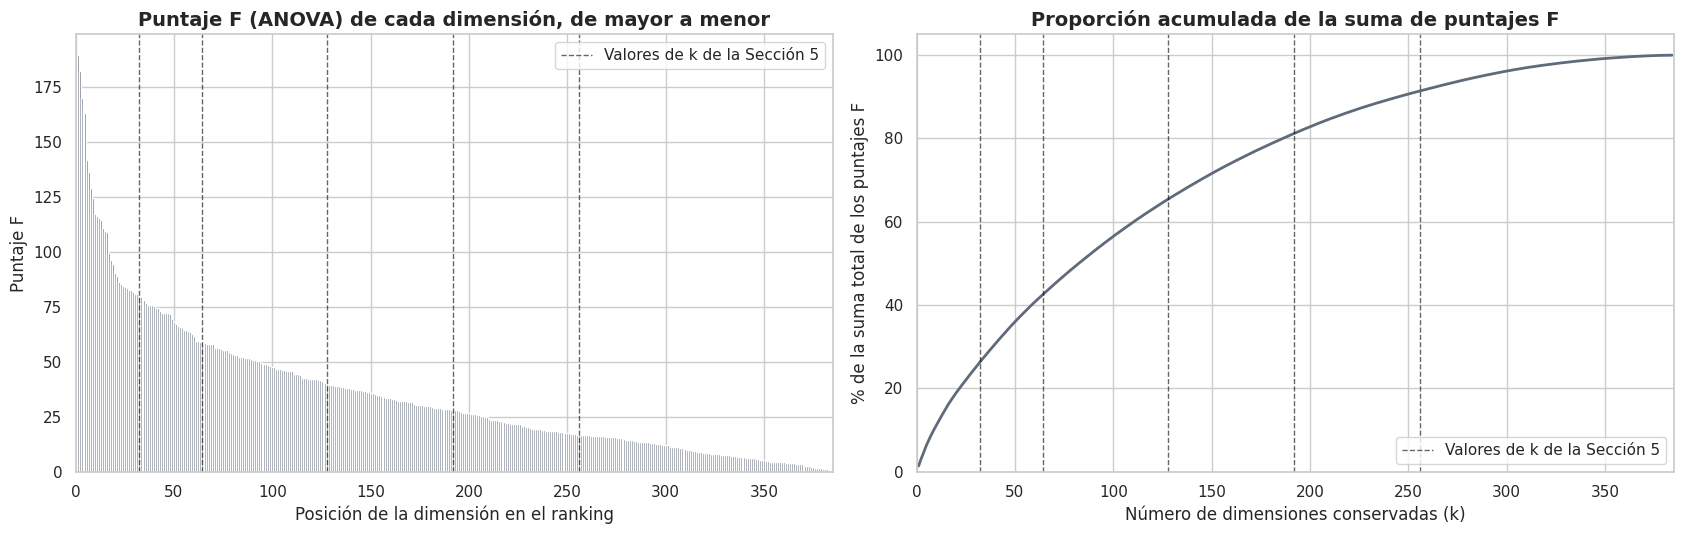

Proporción de la suma de puntajes F que concentran las k primeras dimensiones:


,% de la suma de F
k,
32,26.2
64,42.5
128,65.5
192,81.2
256,91.4
384,100.0


Puntaje F: máximo = 189.6, mediana = 28.0, mínimo = 0.70
Dimensiones con p-valor < 0,05: 373 de 384
Dimensiones con p-valor < 0,05 / 384 = 1.3e-04 (Bonferroni): 346 de 384


In [90]:
# Prompt (LLM): "4.2 Calcular los puntajes F y p-valores de f_classif solo con el conjunto de desarrollo; graficar
# los 384 puntajes ordenados con líneas en los valores de k, la curva acumulada de la suma de puntajes F, contar las
# dimensiones con p < 0,05 y p < 0,05/384 (Bonferroni) y un boxplot por clase de las 3 dimensiones con mayor F."
OPCIONES_K = ["32", "64", "128", "192", "256", "all"]   # valores de k que se optimizarán en la Sección 5
VALORES_K_NUMERICOS = [int(k) for k in OPCIONES_K if k != "all"]

puntajes_f_descriptivo, p_valores_descriptivo = f_classif(X_des, y_des)
orden_descriptivo = np.argsort(puntajes_f_descriptivo)[::-1]
f_ordenado_descriptivo = puntajes_f_descriptivo[orden_descriptivo]
f_acumulado_descriptivo = np.cumsum(f_ordenado_descriptivo) / f_ordenado_descriptivo.sum()
n_dimensiones = X_des.shape[1]

fig, ejes = plt.subplots(1, 2, figsize=(17, 5.5))
posiciones = np.arange(1, n_dimensiones + 1)
ejes[0].bar(posiciones, f_ordenado_descriptivo, width=1.0, color=COLOR_GENERAL)
ejes[0].set_title("Puntaje F (ANOVA) de cada dimensión, de mayor a menor")
ejes[0].set_xlabel("Posición de la dimensión en el ranking")
ejes[0].set_ylabel("Puntaje F")
ejes[1].plot(posiciones, f_acumulado_descriptivo * 100, color=COLOR_GENERAL, linewidth=2)
ejes[1].set_title("Proporción acumulada de la suma de puntajes F")
ejes[1].set_xlabel("Número de dimensiones conservadas (k)")
ejes[1].set_ylabel("% de la suma total de los puntajes F")
ejes[1].set_ylim(0, 105)
for ax in ejes:
    for i, k in enumerate(VALORES_K_NUMERICOS):
        ax.axvline(k, color="black", linestyle="--", linewidth=1, alpha=0.6,
                   label="Valores de k de la Sección 5" if i == 0 else None)
    ax.set_xlim(0, n_dimensiones + 1)
    ax.legend()
plt.tight_layout()
plt.show()

print("Proporción de la suma de puntajes F que concentran las k primeras dimensiones:")
display(pd.DataFrame({
    "k": VALORES_K_NUMERICOS + [n_dimensiones],
    "% de la suma de F": [round(f_acumulado_descriptivo[k - 1] * 100, 1) for k in VALORES_K_NUMERICOS + [n_dimensiones]],
}).set_index("k"))

umbral_bonferroni = 0.05 / n_dimensiones
print(f"Puntaje F: máximo = {f_ordenado_descriptivo[0]:.1f}, mediana = {np.median(puntajes_f_descriptivo):.1f}, "
      f"mínimo = {f_ordenado_descriptivo[-1]:.2f}")
print(f"Dimensiones con p-valor < 0,05: {(p_valores_descriptivo < 0.05).sum()} de {n_dimensiones}")
print(f"Dimensiones con p-valor < 0,05 / {n_dimensiones} = {umbral_bonferroni:.1e} (Bonferroni): "
      f"{(p_valores_descriptivo < umbral_bonferroni).sum()} de {n_dimensiones}")

**Corrección de Bonferroni.** Al hacer 384 pruebas a la vez, incluso si ninguna dimensión estuviera relacionada con la clase se esperaría que alrededor del 5 % (unas 19) dieran un p-valor menor que 0,05 por puro azar. Dividir el nivel de significancia entre el número de pruebas (0,05 / 384) controla la probabilidad de declarar significativa alguna dimensión que en realidad no lo es.

**Dimensiones con mayor puntaje F.** El siguiente gráfico muestra, para las 3 dimensiones con mayor F, la distribución de sus valores en cada clase, para ver qué clases separan.

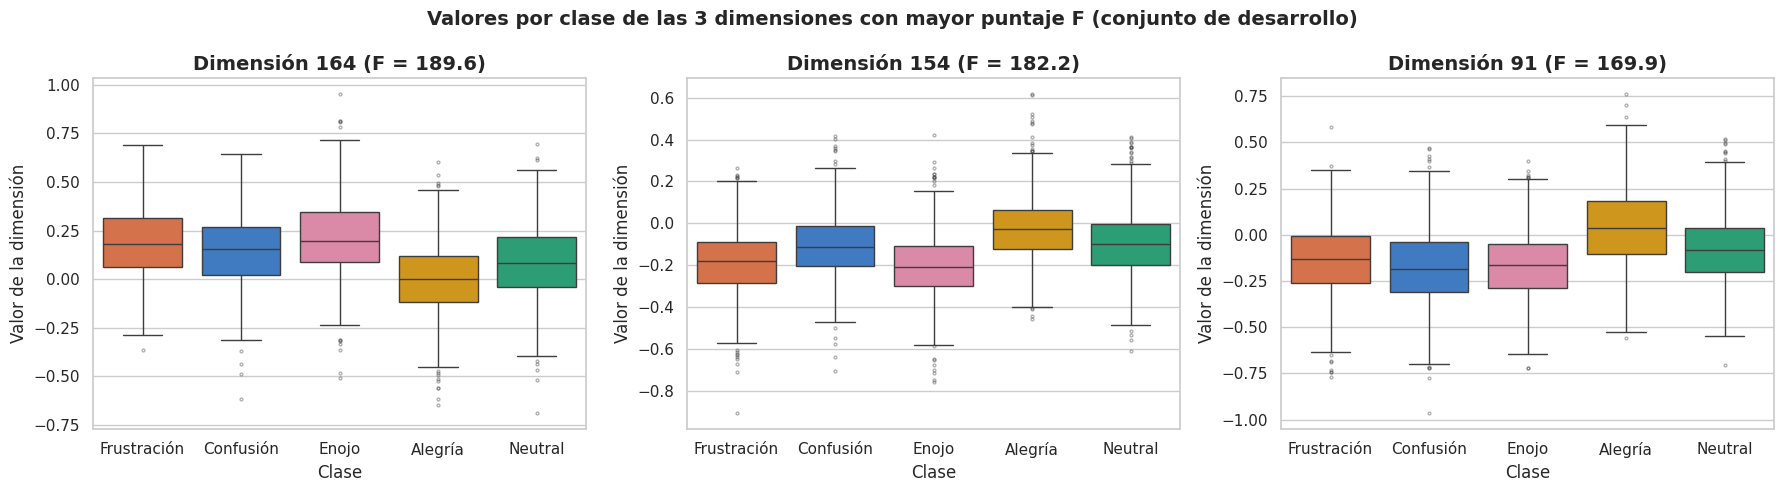

In [91]:
top3_descriptivo = orden_descriptivo[:3]
fig, ejes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
for ax, dimension in zip(ejes, top3_descriptivo):
    datos = pd.DataFrame({"clase": y_des, "valor": X_des[:, dimension]})
    sns.boxplot(data=datos, x="clase", y="valor", hue="clase", order=ORDEN_CLASES, hue_order=ORDEN_CLASES,
                palette=PALETA_CLASES, legend=False, flierprops={"markersize": 2, "alpha": 0.4}, ax=ax)
    ax.set_xticks(range(len(ORDEN_CLASES)))
    ax.set_xticklabels([NOMBRES_CLASES[c] for c in ORDEN_CLASES])
    ax.set_title(f"Dimensión {dimension} (F = {puntajes_f_descriptivo[dimension]:.1f})")
    ax.set_xlabel("Clase")
    ax.set_ylabel("Valor de la dimensión")
fig.suptitle("Valores por clase de las 3 dimensiones con mayor puntaje F (conjunto de desarrollo)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar: indicar si la información está concentrada en pocas dimensiones (curva acumulada que sube rápido; qué porcentaje de la suma de F concentran las 32 o 64 primeras) o repartida en muchas (curva casi lineal). Indicar cuántas dimensiones son significativas con y sin Bonferroni ([COMPLETAR] y [COMPLETAR] de 384). Comentar qué clases separan las 3 dimensiones con mayor F (por ejemplo, si alguna separa sobre todo alegría o enojo del resto). Concluir qué se espera de la optimización de `k`: si casi todas las dimensiones son significativas, es probable que conservar muchas o todas sea lo mejor. Recordar que este análisis es descriptivo y no se usa para elegir características.]

### 4.4 Integración en el pipeline

Los pipelines con embeddings de la Sección 5 tienen esta estructura:

```
Pipeline([
    ("escalado", StandardScaler()),
    ("seleccion", SelectKBest(score_func=f_classif, k=k)),
    ("clasificador", <LogisticRegression o SVC>),
])
```

- **`escalado`:** centra cada dimensión en 0 y la lleva a desviación estándar 1. Es necesario para la regresión logística y la SVM, porque ambas usan distancias o productos escalares y penalizan los pesos por igual en todas las dimensiones. El ANOVA F no depende de la escala de cada dimensión (es un cociente de varianzas), así que escalar antes o después de seleccionar no cambia qué dimensiones se eligen.
- **`seleccion`:** conserva las `k` dimensiones con mayor puntaje F, calculado con las etiquetas del conjunto de entrenamiento. Con `k = "all"` no elimina ninguna.
- **`clasificador`:** el modelo que se entrena con las dimensiones seleccionadas.

Al llamar a `fit` con un conjunto de entrenamiento, cada paso aprende solo de ese conjunto (las medias y desviaciones, los puntajes F y los pesos del clasificador). Al predecir, el conjunto de prueba solo se **transforma** con lo aprendido: nunca participa en el ajuste.

---

## 5. Pipelines y optimización de hiperparámetros

### 5.1 Partición desarrollo / prueba final

La partición se creó en 4.2 (Regla 2), antes del análisis de los puntajes F. Aquí se muestra su composición y se repiten las comprobaciones.

**Por qué un conjunto de prueba final.** Los hiperparámetros se eligen (Sección 5) con el mismo conjunto de desarrollo con el que después se comparan los modelos (Sección 6). Por eso los puntajes de la validación cruzada tienen un **sesgo optimista**: los hiperparámetros elegidos son, en parte, los que mejor se ajustaron por azar a esas particiones. La forma rigurosa de evitarlo sería un *nested cross-validation*, que se desaconseja por su costo; el conjunto de prueba final, que no participa en ninguna decisión, da una estimación **sin ese sesgo**. Además, ambos modelos reciben exactamente el mismo tratamiento (misma optimización, mismas particiones), de modo que la comparación entre ellos sigue siendo justa aunque los puntajes absolutos sean algo optimistas.

In [92]:
# Prompt (LLM): "5.1 Mostrar una tabla de clase x tipo de fuente para los conjuntos de desarrollo y de prueba final,
# y los assert de no solapamiento."
assert len(np.intersect1d(idx_desarrollo, idx_prueba)) == 0
assert len(idx_desarrollo) + len(idx_prueba) == len(y)

tabla_particion = pd.concat({
    "desarrollo": pd.crosstab(y_des, np.where(mascara_goemotions_des, "GoEmotions", "sintético")),
    "prueba final": pd.crosstab(y_prueba, np.where(mascara_goemotions_prueba, "GoEmotions", "sintético")),
}, axis=1).reindex(ORDEN_CLASES)
tabla_particion.index = [NOMBRES_CLASES[c] for c in tabla_particion.index]
tabla_particion.loc["Total"] = tabla_particion.sum()
display(tabla_particion)
print(f"Proporción de sintéticos: desarrollo = {(~mascara_goemotions_des).mean():.1%}, "
      f"prueba final = {(~mascara_goemotions_prueba).mean():.1%}")

desarrollo           prueba final          
col_0       GoEmotions sintético   GoEmotions sintético
Frustración        825        31          206         8
Confusión          825        32          206         8
Enojo              824        32          207         8
Alegría            825        32          206         8
Neutral            825        32          206         8
Total             4124       159         1031        40

Proporción de sintéticos: desarrollo = 3.7%, prueba final = 3.7%


### 5.2 Definición de los pipelines

Se comparan dos clasificadores sobre los embeddings:

- **Regresión logística multinomial.** Modelo lineal que estima la probabilidad de cada clase con una función *softmax* de una combinación lineal de las características. El hiperparámetro **`C`** es el inverso de la fuerza de la regularización L2: un `C` pequeño obliga a usar pesos pequeños (modelo más simple, riesgo de subajuste) y un `C` grande permite ajustarse mucho a los datos de entrenamiento (riesgo de sobreajuste).
- **Máquina de vectores de soporte (SVM) con kernel RBF [12].** Busca la frontera que separa las clases con el mayor margen posible; para 5 clases, scikit-learn combina clasificadores binarios uno contra uno. El kernel **RBF** (función de base radial) mide la similitud entre dos ejemplos como $\exp(-\gamma \lVert x - x' \rVert^2)$ y permite fronteras **no lineales**. **`C`** controla el compromiso entre un margen amplio y los errores de entrenamiento (mismo papel que en la regresión logística). **`gamma`** controla el alcance de la influencia de cada ejemplo: un `gamma` grande produce fronteras muy irregulares (sobreajuste) y uno pequeño, fronteras suaves. Se usa `cache_size=1000` (MB) para guardar en memoria más valores del kernel y acelerar el entrenamiento.

**Un modelo lineal frente a uno no lineal.** La regresión logística ya es el modelo lineal de la comparación, así que la SVM se usa solo con kernel RBF. De este modo la Sección 6 compara un clasificador **lineal** con uno **no lineal**, lo que responde a una pregunta más informativa (¿hace falta una frontera no lineal sobre los embeddings?) que comparar dos modelos lineales entre sí.

En ambos se usa **`class_weight="balanced"`**, que pondera cada ejemplo de forma inversamente proporcional a la frecuencia de su clase en el conjunto de entrenamiento. El dataset final está prácticamente balanceado (2.13), pero dentro de cada partición pueden quedar pequeñas diferencias, y así ninguna clase domina el ajuste.

Cada modelo se construye con una **función fábrica** que devuelve siempre un pipeline nuevo y sin ajustar (Regla 3). El parámetro `k` admite el valor `"all"`, que equivale a no seleccionar.

In [ ]:
# Prompt (LLM): "5.2 Funciones fábrica que devuelven un pipeline nuevo: crear_pipeline_rl(C, k) con StandardScaler,
# SelectKBest(f_classif, k) y LogisticRegression(C, class_weight='balanced', max_iter=5000, random_state=SEMILLA);
# crear_pipeline_svm(C, gamma, k) con SVC(kernel='rbf', C, gamma, class_weight='balanced', cache_size=1000,
# random_state=SEMILLA). k admite 'all'.
# Mostrar uno de los pipelines con set_config(display='diagram')."
def convertir_k(valor):
    """Optuna guarda k como texto ('64', 'all'); SelectKBest necesita un entero o 'all'."""
    return valor if valor == "all" else int(valor)


def crear_pipeline_rl(C, k):
    return Pipeline([
        ("escalado", StandardScaler()),
        ("seleccion", SelectKBest(score_func=f_classif, k=convertir_k(k))),
        ("clasificador", LogisticRegression(C=C, class_weight="balanced", max_iter=5000, random_state=SEMILLA)),
    ])


def crear_pipeline_svm(C, gamma, k):
    return Pipeline([
        ("escalado", StandardScaler()),
        ("seleccion", SelectKBest(score_func=f_classif, k=convertir_k(k))),
        ("clasificador", SVC(C=C, kernel="rbf", gamma=gamma, class_weight="balanced", cache_size=1000,
                             random_state=SEMILLA)),
    ])


set_config(display="diagram")
print("Estructura del pipeline de la SVM (ejemplo con valores cualesquiera de los hiperparámetros):")
display(crear_pipeline_svm(C=1.0, gamma=1e-3, k="all"))

### 5.3 Optimización con Optuna

**Optuna [13]** es una biblioteca de optimización de hiperparámetros. En lugar de evaluar todas las combinaciones de una malla, usa el muestreador **TPE** (*Tree-structured Parzen Estimator*) [14]: tras unos primeros trials aleatorios, modela por separado la distribución de los hiperparámetros de los trials buenos y la de los malos, y propone los valores que tienen más probabilidad de ser buenos. Así concentra los trials en las zonas prometedoras del espacio, y con unas decenas de trials suele encontrar soluciones tan buenas como una malla de cientos de combinaciones.

**Espacios de búsqueda**

| Modelo | Hiperparámetro | Valores |
|---|---|---|
| Regresión logística | `C` | log-uniforme entre 10⁻³ y 10² |
| | `k` | {32, 64, 128, 192, 256, "all"} |
| SVM (kernel RBF fijo) | `C` | log-uniforme entre 10⁻² y 10 |
| | `gamma` | log-uniforme entre 10⁻⁴ y 10⁻¹ |
| | `k` | {32, 64, 128, 192, 256, "all"} |

Como referencia, el valor `gamma="scale"` que scikit-learn usa por defecto equivale, con 384 dimensiones estandarizadas, a 1/384 ≈ 0,0026, que queda dentro del rango de búsqueda.

**Cambio del espacio de búsqueda de la SVM.** La primera versión del espacio incluía también `kernel = linear` y `C` hasta 10². Al ejecutarla, la regresión logística completó sus 50 trials, pero la SVM tardaba unos **4 minutos por trial**: tras unos 20 minutos solo llevaba 5 de 50 (mejor F1-macro ≈ 0,53), lo que suponía más de 3 horas para el estudio completo. La causa es que `SVC` (libsvm) converge muy despacio con el kernel lineal y `C` alto, y los `C` altos también hacen lenta la SVM con RBF. Por eso se hicieron dos cambios:

- **Solo kernel RBF.** El modelo lineal de la comparación ya es la regresión logística; buscar también la SVM lineal sería redundante y era la parte más costosa de la búsqueda (5.2).
- **`C` hasta 10.** Los valores más altos (regularización muy débil) eran los que hacían inviable el tiempo de entrenamiento y, con datos ruidosos como los de este proyecto (traducción automática, etiquetas asignadas sobre el texto en inglés), tienden a sobreajustar.

Además, la SVM usa `N_TRIALS_SVM = 30` trials con un **límite de 25 minutos** (`timeout=1500`): si se alcanza el límite, la búsqueda se detiene al terminar el trial en curso y se usan los trials completados (se imprime cuántos fueron). La regresión logística conserva sus 50 trials, y su estudio no se modifica. Al final de 5.3 se muestra la duración de cada trial para documentar el costo computacional.

**Validación usada en la optimización (Regla 5).** Cada trial se evalúa con un *repeated stratified k-fold* de **5 folds × 2 repeticiones** sobre el conjunto de desarrollo (10 ajustes por trial), con F1-macro como métrica. Es más liviano que el 10 × 10 de la comparación estadística porque se repite en cada trial (500 ajustes para los 50 trials de la regresión logística y hasta 300 para los 30 de la SVM): con un 10 × 10 serían 10 veces más. El conjunto de prueba final no participa.

**Caché.** Cada estudio se guarda en una base SQLite en `DIRECTORIO_DATOS` (`load_if_exists=True`): al volver a ejecutar, se cargan los trials ya hechos y solo se ejecutan los que falten hasta `N_TRIALS` (`N_TRIALS_SVM` en la SVM). El nombre del estudio incluye la huella del dataset, de modo que, si el dataset cambia, se empieza un estudio nuevo. El estudio de la SVM con el espacio nuevo se llama `svm_rbf` y se guarda en la misma base que el estudio anterior (`optuna_embeddings_svm.db`), para no mezclar sus trials con los 5 del espacio antiguo; ese estudio antiguo no se borra, pero no se usa. Durante la búsqueda la base se usa en el disco local de Colab y después se copia a Drive, porque SQLite puede dar errores de bloqueo si se escribe directamente en Drive.

In [ ]:
# Prompt (LLM): "5.3 CV de la optimización RepeatedStratifiedKFold(5, 2, SEMILLA) sobre el desarrollo. Función
# objetivo por modelo que construye un pipeline nuevo con los hiperparámetros del trial, calcula cross_val_score con
# f1_macro y n_jobs=-1, guarda la desviación como atributo del trial y devuelve la media. Espacios de búsqueda
# (RL: C log 1e-3..1e2, k; SVM solo RBF: C log 1e-2..1e1, gamma log 1e-4..1e-1, k). TPESampler(seed=SEMILLA),
# N_TRIALS=50 para RL y N_TRIALS_SVM=30 con timeout=1500 s para la SVM; estudios en SQLite en DIRECTORIO_DATOS con
# load_if_exists=True; el de la SVM con un nombre nuevo ('svm_rbf') en la misma base que el estudio antiguo.
# Imprimir cuántos trials se completaron y una tabla con la duración de cada trial en minutos."
N_TRIALS = 50          # regresión logística (estudio ya completado; no se modifica)
N_TRIALS_SVM = 30      # SVM con kernel RBF
TIMEOUT_SVM = 1500     # límite de tiempo de la búsqueda de la SVM, en segundos (25 minutos)
CV_OPTIMIZACION = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEMILLA)
optuna.logging.set_verbosity(optuna.logging.WARNING)


def evaluar_en_cv_optimizacion(trial, pipeline, X, etiquetas):
    puntajes = cross_val_score(pipeline, X, etiquetas, cv=CV_OPTIMIZACION, scoring="f1_macro", n_jobs=-1)
    trial.set_user_attr("f1_std", float(puntajes.std()))
    return float(puntajes.mean())


def objetivo_rl(trial):
    C = trial.suggest_float("C", 1e-3, 1e2, log=True)
    k = trial.suggest_categorical("k", OPCIONES_K)
    return evaluar_en_cv_optimizacion(trial, crear_pipeline_rl(C, k), X_des, y_des)


def objetivo_svm(trial):
    C = trial.suggest_float("C", 1e-2, 1e1, log=True)
    gamma = trial.suggest_float("gamma", 1e-4, 1e-1, log=True)
    k = trial.suggest_categorical("k", OPCIONES_K)
    return evaluar_en_cv_optimizacion(trial, crear_pipeline_svm(C, gamma, k), X_des, y_des)


def contar_completos(estudio):
    return sum(t.state == optuna.trial.TrialState.COMPLETE for t in estudio.trials)


def ejecutar_estudio(nombre, objetivo, n_trials, archivo=None, timeout=None):
    """Crea o carga el estudio `nombre` de Optuna, guardado en DIRECTORIO_DATOS/optuna_<archivo>.db (por defecto,
    archivo = nombre), y ejecuta los trials que falten hasta `n_trials`, con un límite de `timeout` segundos."""
    archivo = archivo or nombre
    ruta_drive = os.path.join(DIRECTORIO_DATOS, f"optuna_{archivo}.db")
    ruta_local = os.path.join(tempfile.gettempdir(), f"optuna_{archivo}.db")
    if os.path.exists(ruta_drive):
        shutil.copy(ruta_drive, ruta_local)
    estudio = optuna.create_study(
        study_name=f"{nombre}_{HUELLA_DATASET[:12]}",
        storage=f"sqlite:///{ruta_local}",
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEMILLA),
        load_if_exists=True,
    )
    inicio = time.perf_counter()
    completos = contar_completos(estudio)
    faltan = n_trials - completos
    if faltan > 0:
        limite = f" (límite de {timeout / 60:.0f} min)" if timeout else ""
        print(f"[{nombre}] {completos} trials en la caché; se ejecutan hasta {faltan} más{limite}...")
        try:
            estudio.optimize(objetivo, n_trials=faltan, timeout=timeout, show_progress_bar=True)
        finally:
            # Se copia a Drive aunque la búsqueda se interrumpa, para no perder los trials ya completados
            os.makedirs(DIRECTORIO_DATOS, exist_ok=True)
            shutil.copy(ruta_local, ruta_drive)
        nuevos = contar_completos(estudio) - completos
        print(f"[{nombre}] {nuevos} trials nuevos completados ({contar_completos(estudio)} de {n_trials} en total); "
              f"guardado en {time.perf_counter() - inicio:.1f} s.")
        if contar_completos(estudio) < n_trials:
            print(f"[{nombre}] Se alcanzó el límite de tiempo: se usan los {contar_completos(estudio)} trials completados. "
                  "Al volver a ejecutar la celda se continuaría con los que faltan.")
    else:
        print(f"[{nombre}] cargado de la caché ({completos} trials) en {time.perf_counter() - inicio:.1f} s.")
    return estudio


def trials_completos(estudio):
    """DataFrame con los trials completos de un estudio, ordenados por número."""
    tabla = estudio.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state"))
    tabla = tabla[tabla["state"] == "COMPLETE"].drop(columns="state")
    return tabla.rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", "")).sort_values("number")


# Regresión logística: mismo estudio y misma base que antes (se carga de la caché sin recalcular)
estudio_rl = ejecutar_estudio("embeddings_rl", objetivo_rl, N_TRIALS)
# SVM con kernel RBF: estudio nuevo ('svm_rbf') en la misma base que el estudio antiguo ('embeddings_svm'),
# que no se borra pero ya no se usa
estudio_svm = ejecutar_estudio("svm_rbf", objetivo_svm, N_TRIALS_SVM, archivo="embeddings_svm", timeout=TIMEOUT_SVM)
print(f"\nTrials completados: regresión logística = {contar_completos(estudio_rl)} de {N_TRIALS}; "
      f"SVM (kernel RBF) = {contar_completos(estudio_svm)} de {N_TRIALS_SVM}.")


def tabla_duraciones(estudio):
    """Trials completos con su F1-macro, hiperparámetros y duración en minutos."""
    tabla = estudio.trials_dataframe(attrs=("number", "value", "params", "duration", "state"))
    tabla = tabla[tabla["state"] == "COMPLETE"].drop(columns="state")
    tabla["duración (min)"] = tabla.pop("duration").dt.total_seconds() / 60
    return tabla.rename(columns=lambda c: c.replace("params_", "")).rename(
        columns={"number": "trial", "value": "F1-macro"}).sort_values("trial").reset_index(drop=True)


duraciones = {"rl": tabla_duraciones(estudio_rl), "svm": tabla_duraciones(estudio_svm)}
print("\nCosto computacional de la optimización (CV 5 × 2: 10 ajustes por trial):")
display(pd.DataFrame([
    {"modelo": NOMBRES_MODELOS[clave], "trials": len(tabla),
     "duración media (min)": tabla["duración (min)"].mean(), "duración mediana (min)": tabla["duración (min)"].median(),
     "duración máxima (min)": tabla["duración (min)"].max(), "total (min)": tabla["duración (min)"].sum()}
    for clave, tabla in duraciones.items()
]).set_index("modelo").round(2))
print(f"\n=== {NOMBRES_MODELOS['svm']}: duración de cada trial ===")
display(duraciones["svm"].round({"F1-macro": 4, "C": 4, "gamma": 5, "duración (min)": 2}))

In [ ]:
# Prompt (LLM): "5.3.5 Mostrar para cada modelo los mejores hiperparámetros, su F1-macro medio ± desviación y el
# número de trials, y una tabla con los 10 mejores trials."
def parametros_rl(estudio):
    return {"C": float(estudio.best_params["C"]), "k": estudio.best_params["k"]}


def parametros_svm(estudio):
    mejores = estudio.best_params
    return {"C": float(mejores["C"]), "gamma": float(mejores["gamma"]), "k": mejores["k"]}


PARAMS_RL = parametros_rl(estudio_rl)
PARAMS_SVM = parametros_svm(estudio_svm)
trials_rl, trials_svm = trials_completos(estudio_rl), trials_completos(estudio_svm)

resumen_optimizacion = pd.DataFrame([
    {"modelo": NOMBRES_MODELOS[clave], "mejores hiperparámetros": params,
     "F1-macro (media)": round(estudio.best_value, 4), "F1-macro (desv. est.)": round(estudio.best_trial.user_attrs["f1_std"], 4),
     "trials": len(trials)}
    for clave, estudio, params, trials in [("rl", estudio_rl, PARAMS_RL, trials_rl),
                                           ("svm", estudio_svm, PARAMS_SVM, trials_svm)]
]).set_index("modelo")
display(resumen_optimizacion)

for clave, trials in [("rl", trials_rl), ("svm", trials_svm)]:
    print(f"\n=== {NOMBRES_MODELOS[clave]}: los 10 mejores trials ===")
    display(trials.sort_values("value", ascending=False).head(10).rename(
        columns={"number": "trial", "value": "F1-macro", "f1_std": "desv. est."}).round(4).reset_index(drop=True))

**Interpretación.** [COMPLETAR tras ejecutar: mejores hiperparámetros de cada modelo y su F1-macro en el CV de la optimización ([COMPLETAR] ± [COMPLETAR] para la regresión logística y [COMPLETAR] ± [COMPLETAR] para la SVM con kernel RBF). Indicar cuántos trials completó la SVM dentro del límite de 25 minutos ([COMPLETAR] de 30) y su duración media por trial ([COMPLETAR] min, frente a unos 4 min con el espacio original). Comentar si los 10 mejores trials tienen F1 muy parecidos (meseta: el resultado es poco sensible a los hiperparámetros en esa zona) y qué valores de `C`, `gamma` y `k` predominan entre ellos.]

### 5.4 Gráficas de la optimización

Se muestran cuatro gráficas:

1. **Historial de la optimización:** el F1 de cada trial y el mejor F1 acumulado, para ver si la búsqueda converge.
2. **F1 frente a `C`** en todos los trials de cada modelo (eje logarítmico), con la SVM coloreada por `gamma` (escala logarítmica). Como en la SVM con kernel RBF `C` y `gamma` interactúan, se añade un gráfico de dispersión de **`C` frente a `gamma`** con el F1 como color, que muestra en qué zona del plano están los mejores trials.
3. **Curva de validación de `C`** del mejor de los dos modelos: con el resto de hiperparámetros fijos en su óptimo, `C` recorre 12 valores en escala logarítmica dentro del mismo rango de la búsqueda (de 10⁻³ a 10² en la regresión logística y de 10⁻² a 10 en la SVM) y se mide el F1 de entrenamiento y de validación con el CV de la optimización (5 × 2) sobre el conjunto de desarrollo. Es la gráfica principal de la optimización: muestra las zonas de subajuste y de sobreajuste.
4. **F1 frente a `k`:** el mejor F1 obtenido con cada valor de `k`, para saber si la selección de características de la Sección 4 ayudó.

In [ ]:
# Prompt (LLM): "5.4.1 Historial de optimización de cada estudio: F1 de cada trial y mejor F1 acumulado frente al
# número de trial. 5.4.2 F1 frente a C con todos los trials de cada modelo (eje X logarítmico), con la SVM coloreada
# por gamma en escala logarítmica (barra de color), y dispersión de C frente a gamma de la SVM con el F1 como color."
fig, ejes = plt.subplots(1, 2, figsize=(17, 5), sharey=True)
for ax, (clave, trials) in zip(ejes, [("rl", trials_rl), ("svm", trials_svm)]):
    ax.scatter(trials["number"], trials["value"], color=PALETA_MODELOS[clave], alpha=0.6, s=30, label="F1 de cada trial")
    ax.plot(trials["number"], trials["value"].cummax(), color="black", linewidth=2, label="Mejor F1 acumulado")
    ax.set_title(f"Historial de la optimización: {NOMBRES_MODELOS[clave]}")
    ax.set_xlabel("Número de trial")
    ax.set_ylabel("F1-macro (CV 5 × 2)")
    ax.legend()
plt.tight_layout()
plt.show()

from matplotlib.colors import LogNorm

fig, ejes = plt.subplots(1, 2, figsize=(17, 5), sharey=True)
ejes[0].scatter(trials_rl["C"], trials_rl["value"], color=PALETA_MODELOS["rl"], alpha=0.7, s=35, label="Trials")
ejes[0].set_title(f"F1 frente a C: {NOMBRES_MODELOS['rl']}")
ejes[0].legend()
puntos = ejes[1].scatter(trials_svm["C"], trials_svm["value"], c=trials_svm["gamma"], cmap="viridis",
                         norm=LogNorm(vmin=1e-4, vmax=1e-1), alpha=0.85, s=40, edgecolor="white", linewidth=0.5)
fig.colorbar(puntos, ax=ejes[1], label="gamma (escala logarítmica)")
ejes[1].set_title(f"F1 frente a C: {NOMBRES_MODELOS['svm']}")
for ax in ejes:
    ax.set_xscale("log")
    ax.set_xlabel("C (escala logarítmica)")
    ax.set_ylabel("F1-macro (CV 5 × 2)")
plt.tight_layout()
plt.show()

# Interacción C–gamma de la SVM: cada punto es un trial, coloreado por su F1-macro
fig, ax = plt.subplots(figsize=(10, 6.5))
puntos = ax.scatter(trials_svm["C"], trials_svm["gamma"], c=trials_svm["value"], cmap="viridis", s=70,
                    edgecolor="white", linewidth=0.5)
fig.colorbar(puntos, ax=ax, label="F1-macro (CV 5 × 2)")
mejor_svm = trials_svm.loc[trials_svm["value"].idxmax()]
ax.scatter(mejor_svm["C"], mejor_svm["gamma"], marker="*", s=350, color="#c8553d", edgecolor="black", zorder=3,
           label=f"Mejor trial (F1 = {mejor_svm['value']:.4f})")
ax.axhline(1 / X_des.shape[1], color="gray", linestyle=":", label=f"gamma = 'scale' ≈ 1/{X_des.shape[1]}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e-2, 1e1)
ax.set_ylim(1e-4, 1e-1)
ax.set_title(f"C frente a gamma en los trials: {NOMBRES_MODELOS['svm']}")
ax.set_xlabel("C (escala logarítmica)")
ax.set_ylabel("gamma (escala logarítmica)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

In [ ]:
# Prompt (LLM): "5.4.3 Curva de validación de C del mejor modelo con validation_curve: el resto de hiperparámetros
# fijo en el óptimo, C en 12 valores en escala logarítmica dentro del rango de la búsqueda (RL: 1e-3..1e2; SVM:
# 1e-2..1e1), CV de la optimización sobre el desarrollo. Graficar
# F1 de entrenamiento y de validación con bandas de ± 1 desviación y marcar el C óptimo."
MEJOR_EN_OPTIMIZACION = "svm" if estudio_svm.best_value > estudio_rl.best_value else "rl"
if MEJOR_EN_OPTIMIZACION == "rl":
    pipeline_curva, C_optimo, rango_C = crear_pipeline_rl(**PARAMS_RL), PARAMS_RL["C"], np.logspace(-3, 2, 12)
else:
    pipeline_curva, C_optimo, rango_C = crear_pipeline_svm(**PARAMS_SVM), PARAMS_SVM["C"], np.logspace(-2, 1, 12)
params_curva = PARAMS_RL if MEJOR_EN_OPTIMIZACION == "rl" else PARAMS_SVM
print(f"Modelo con mejor F1 en la optimización: {NOMBRES_MODELOS[MEJOR_EN_OPTIMIZACION]} ({params_curva})")


def calcular_curva_validacion():
    entrenamiento, validacion = validation_curve(
        pipeline_curva, X_des, y_des, param_name="clasificador__C", param_range=rango_C,
        cv=CV_OPTIMIZACION, scoring="f1_macro", n_jobs=-1)
    return {"entrenamiento": entrenamiento, "validacion": validacion}


curva_validacion = con_cache(
    "curva_validacion_C",
    {"modelo": MEJOR_EN_OPTIMIZACION, "params": params_curva, "rango_C": rango_C.tolist()},
    calcular_curva_validacion)

fig, ax = plt.subplots(figsize=(11, 6))
for nombre, color, etiqueta in [("entrenamiento", COLOR_GENERAL, "Entrenamiento"),
                                ("validacion", PALETA_MODELOS[MEJOR_EN_OPTIMIZACION], "Validación")]:
    media, desviacion = curva_validacion[nombre].mean(axis=1), curva_validacion[nombre].std(axis=1)
    ax.plot(rango_C, media, marker="o", color=color, label=f"F1-macro de {etiqueta.lower()}")
    ax.fill_between(rango_C, media - desviacion, media + desviacion, color=color, alpha=0.2)
ax.axvline(C_optimo, color="black", linestyle="--", label=f"C óptimo de Optuna = {C_optimo:.3g}")
ax.set_xscale("log")
ax.set_title(f"Curva de validación de C: {NOMBRES_MODELOS[MEJOR_EN_OPTIMIZACION]}")
ax.set_xlabel("C (escala logarítmica; mayor C = menos regularización)")
ax.set_ylabel("F1-macro (CV 5 × 2, media ± 1 desv. est.)")
ax.legend()
plt.tight_layout()
plt.show()

tabla_curva = pd.DataFrame({
    "C": rango_C,
    "F1 entrenamiento": curva_validacion["entrenamiento"].mean(axis=1),
    "F1 validación": curva_validacion["validacion"].mean(axis=1),
    "desv. validación": curva_validacion["validacion"].std(axis=1),
})
tabla_curva["brecha"] = tabla_curva["F1 entrenamiento"] - tabla_curva["F1 validación"]
display(tabla_curva.round(4))

In [ ]:
# Prompt (LLM): "5.4.4 F1 frente a k: el mejor F1 obtenido para cada valor de k en cada modelo."
mejor_por_k = pd.DataFrame({
    NOMBRES_MODELOS[clave]: trials.groupby("k")["value"].max().reindex(OPCIONES_K)
    for clave, trials in [("rl", trials_rl), ("svm", trials_svm)]
})
trials_por_k = pd.DataFrame({
    NOMBRES_MODELOS[clave]: trials["k"].value_counts().reindex(OPCIONES_K, fill_value=0)
    for clave, trials in [("rl", trials_rl), ("svm", trials_svm)]
})

fig, ax = plt.subplots(figsize=(11, 5.5))
posiciones = np.arange(len(OPCIONES_K))
ancho = 0.38
for desplazamiento, clave in [(-ancho / 2, "rl"), (ancho / 2, "svm")]:
    valores = mejor_por_k[NOMBRES_MODELOS[clave]]
    barras = ax.bar(posiciones + desplazamiento, valores.fillna(0), width=ancho, color=PALETA_MODELOS[clave],
                    label=NOMBRES_MODELOS[clave])
    for barra, valor in zip(barras, valores):
        if not np.isnan(valor):
            ax.text(barra.get_x() + barra.get_width() / 2, valor, f"{valor:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(posiciones)
ax.set_xticklabels([f"k = {k}" if k != "all" else "todas (384)" for k in OPCIONES_K])
valores_validos = mejor_por_k.stack()
ax.set_ylim(valores_validos.min() - 0.03, valores_validos.max() + 0.02)
ax.set_title("Mejor F1-macro obtenido con cada número de dimensiones seleccionadas (k)")
ax.set_xlabel("Número de dimensiones conservadas por SelectKBest")
ax.set_ylabel("Mejor F1-macro (CV 5 × 2)")
ax.legend(title="Modelo")
plt.tight_layout()
plt.show()

print("Número de trials que probó cada valor de k (TPE explora más los valores prometedores):")
display(trials_por_k)

**Interpretación.** [COMPLETAR tras ejecutar:

- **Historial.** Indicar en qué trial se alcanzó el mejor F1 de cada estudio y si la curva del mejor acumulado se estabiliza antes del último trial (50 en la regresión logística y [COMPLETAR] en la SVM): si se estabiliza, la búsqueda convergió.
- **`C` y `gamma` de la SVM.** Indicar en qué zona del plano `C`–`gamma` están los mejores trials ([COMPLETAR]) y si el `gamma` óptimo ([COMPLETAR]) está cerca del valor por defecto 1/384 ≈ 0,0026. Comentar si hay una franja diagonal de buenos resultados (un `gamma` mayor compensado con un `C` menor, o al revés) y si los `gamma` grandes dan F1 bajos (fronteras demasiado irregulares, sobreajuste).
- **Curva de validación de `C`.** Describir la zona de **subajuste** (C pequeño: entrenamiento y validación bajos y parecidos), la zona del óptimo y la zona de **sobreajuste** (C grande: el F1 de entrenamiento sigue subiendo, hasta [COMPLETAR], mientras que el de validación se estanca o baja, y la brecha crece). Comprobar que el C óptimo de Optuna ([COMPLETAR]) cae en la zona de máximo F1 de validación.
- **Valor de `k`.** Indicar el valor de `k` elegido en cada modelo y si la selección de características mejoró el F1 frente a conservar las 384 dimensiones (diferencia de [COMPLETAR]). Relacionarlo con la Sección 4: si la información está repartida en muchas dimensiones, es esperable que conservar muchas o todas sea lo mejor; cualquiera de los dos resultados es válido.]

### 5.5 Curva de aprendizaje

La curva de aprendizaje muestra cómo cambia el F1 de entrenamiento y de validación al aumentar el número de ejemplos de entrenamiento, con los mejores hiperparámetros de cada modelo (en la SVM, los de la búsqueda acotada de 5.3: kernel RBF y `C` ≤ 10). Se usan 8 tamaños, del 10 % al 100 % del conjunto de entrenamiento de cada partición, y el CV de la optimización (5 × 2) sobre el conjunto de desarrollo. Permite diagnosticar:

- **Varianza (sobreajuste):** una brecha grande entre entrenamiento y validación.
- **Sesgo (subajuste):** un F1 de validación bajo que no mejora aunque se añadan datos.
- **Si más datos ayudarían:** si la curva de validación sigue subiendo al final, conseguir más ejemplos mejoraría el modelo.

In [ ]:
# Prompt (LLM): "5.5 learning_curve con el mejor pipeline de cada modelo, tamaños del 10 % al 100 % (8 puntos), el
# CV de la optimización y scoring f1_macro sobre el desarrollo; graficar F1 de entrenamiento y de validación frente
# al número de ejemplos con bandas de ± 1 desviación."
TAMANOS_ENTRENAMIENTO = np.linspace(0.1, 1.0, 8)
pipelines_optimos = {"rl": lambda: crear_pipeline_rl(**PARAMS_RL), "svm": lambda: crear_pipeline_svm(**PARAMS_SVM)}


def calcular_curva_aprendizaje(clave):
    tamanos, entrenamiento, validacion = learning_curve(
        pipelines_optimos[clave](), X_des, y_des, train_sizes=TAMANOS_ENTRENAMIENTO, cv=CV_OPTIMIZACION,
        scoring="f1_macro", n_jobs=-1, shuffle=True, random_state=SEMILLA)
    return {"tamanos": tamanos, "entrenamiento": entrenamiento, "validacion": validacion}


curvas_aprendizaje = {
    clave: con_cache(f"curva_aprendizaje_{clave}",
                     {"params": PARAMS_RL if clave == "rl" else PARAMS_SVM, "tamanos": TAMANOS_ENTRENAMIENTO.tolist()},
                     lambda clave=clave: calcular_curva_aprendizaje(clave))
    for clave in ["rl", "svm"]
}

fig, ejes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True)
filas_resumen = []
for ax, clave in zip(ejes, ["rl", "svm"]):
    curva = curvas_aprendizaje[clave]
    for nombre, color, etiqueta in [("entrenamiento", COLOR_GENERAL, "Entrenamiento"),
                                    ("validacion", PALETA_MODELOS[clave], "Validación")]:
        media, desviacion = curva[nombre].mean(axis=1), curva[nombre].std(axis=1)
        ax.plot(curva["tamanos"], media, marker="o", color=color, label=f"F1-macro de {etiqueta.lower()}")
        ax.fill_between(curva["tamanos"], media - desviacion, media + desviacion, color=color, alpha=0.2)
    ax.set_title(f"Curva de aprendizaje: {NOMBRES_MODELOS[clave]}")
    ax.set_xlabel("Número de ejemplos de entrenamiento")
    ax.set_ylabel("F1-macro (CV 5 × 2, media ± 1 desv. est.)")
    ax.legend()
    for tamano, f1_ent, f1_val in zip(curva["tamanos"], curva["entrenamiento"].mean(axis=1),
                                      curva["validacion"].mean(axis=1)):
        filas_resumen.append({"modelo": NOMBRES_MODELOS[clave], "ejemplos": tamano, "F1 entrenamiento": f1_ent,
                              "F1 validación": f1_val, "brecha": f1_ent - f1_val})
plt.tight_layout()
plt.show()
display(pd.DataFrame(filas_resumen).set_index(["modelo", "ejemplos"]).round(4))

**Interpretación.** [COMPLETAR tras ejecutar: para cada modelo, indicar la brecha entre entrenamiento y validación con todos los datos ([COMPLETAR] en la regresión logística y [COMPLETAR] en la SVM): una brecha grande indica varianza. Indicar el nivel del F1 de validación (sesgo) y si la curva de validación sigue subiendo entre los dos últimos tamaños (de [COMPLETAR] a [COMPLETAR]): si sube, más datos ayudarían. Relacionarlo con el tamaño del dataset tras el balanceo (2.13): el submuestreo dejó 1.031 ejemplos de GoEmotions por clase, aunque las clases mayoritarias tenían muchos más; si la curva sigue subiendo, usar más ejemplos de esas clases (con un tope más alto) sería una mejora posible, a costa del balanceo.]

### 5.6 Resumen de la sección

In [ ]:
# Prompt (LLM): "5.6 Tabla con los hiperparámetros finales de cada modelo y su F1 en el CV de la optimización."
resumen_hiperparametros = pd.DataFrame([
    {"modelo": NOMBRES_MODELOS["rl"], "C": PARAMS_RL["C"], "kernel": "— (lineal)", "gamma": "—", "k": PARAMS_RL["k"],
     "F1-macro CV 5 × 2": f"{estudio_rl.best_value:.4f} ± {estudio_rl.best_trial.user_attrs['f1_std']:.4f}"},
    {"modelo": NOMBRES_MODELOS["svm"], "C": PARAMS_SVM["C"], "kernel": "rbf", "gamma": PARAMS_SVM["gamma"],
     "k": PARAMS_SVM["k"],
     "F1-macro CV 5 × 2": f"{estudio_svm.best_value:.4f} ± {estudio_svm.best_trial.user_attrs['f1_std']:.4f}"},
]).set_index("modelo")
display(resumen_hiperparametros)

**Conclusiones de la Sección 5.** [COMPLETAR tras ejecutar, con las cifras de la tabla: hiperparámetros finales de la regresión logística y de la SVM con kernel RBF, su F1-macro en el CV de la optimización, si la selección de características se conservó (`k` elegido) y lo que mostraron la curva de validación y la curva de aprendizaje (sobreajuste o subajuste, si más datos ayudarían). Recordar que estas cifras tienen un sesgo optimista, porque los hiperparámetros se eligieron con las mismas particiones; la comparación rigurosa se hace en la Sección 6 y la estimación sin sesgo, en el conjunto de prueba final.]

---

## 6. Comparación estadística: regresión logística (lineal) frente a SVM con kernel RBF (no lineal)

### 6.1 Diseño

- **Técnicas que se comparan:** **Sentence-BERT + regresión logística (clasificador lineal)** frente a **Sentence-BERT + SVM con kernel RBF (clasificador no lineal)**, cada una con sus mejores hiperparámetros de la Sección 5. La pregunta es si una frontera no lineal mejora la clasificación sobre los embeddings o si basta con una lineal.
- **Por qué se fija la representación:** si cambiaran a la vez la representación y el clasificador, no se podría saber cuál de los dos causa la diferencia. El efecto de la representación se estudia aparte, en 7.1.
- **Hipótesis:** H₀: no hay diferencia en el F1-macro entre ambos modelos; H₁: sí la hay (prueba bilateral). Nivel de significancia α = 0,05.
- **Protocolo:** *repeated stratified k-fold* de **10 folds × 10 repeticiones** sobre el conjunto de desarrollo, con **las mismas 100 particiones para ambos modelos** (Regla 4). Así se obtienen 100 pares de puntajes, y cada diferencia compara los dos modelos exactamente con los mismos datos de entrenamiento y de prueba.
- Las particiones se estratifican por **clase + tipo de fuente**, igual que la partición de 4.2, para que cada fold de prueba tenga una proporción parecida de mensajes sintéticos (necesario para el experimento de 7.2). Esta lista de particiones es la que se reutiliza en 7.1 y 7.2.

In [ ]:
# Prompt (LLM): "6.2.1 Generar una sola vez la lista de 100 particiones (índices de entrenamiento, índices de prueba)
# con RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=SEMILLA) sobre el desarrollo; comprobar con
# assert que hay 100 particiones y que en ninguna se solapan entrenamiento y prueba."
N_FOLDS, N_REPETICIONES_CV = 10, 10
cv_comparacion = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPETICIONES_CV, random_state=SEMILLA)
PARTICIONES = list(cv_comparacion.split(np.zeros(len(y_des)), estrato_des))
REPETICION_DE_PARTICION = np.repeat(np.arange(N_REPETICIONES_CV), N_FOLDS)  # repetición a la que pertenece cada partición

assert len(PARTICIONES) == N_FOLDS * N_REPETICIONES_CV == 100
for entrenamiento, prueba in PARTICIONES:
    assert len(np.intersect1d(entrenamiento, prueba)) == 0, "Una partición mezcla entrenamiento y prueba"
for repeticion in range(N_REPETICIONES_CV):
    pruebas = np.concatenate([PARTICIONES[i][1] for i in np.where(REPETICION_DE_PARTICION == repeticion)[0]])
    assert np.array_equal(np.sort(pruebas), np.arange(len(y_des))), "Una repetición no cubre el desarrollo una vez"

N_ENTRENAMIENTO, N_PRUEBA_FOLD = len(PARTICIONES[0][0]), len(PARTICIONES[0][1])
print(f"Particiones: {len(PARTICIONES)} | ejemplos por partición: entrenamiento ≈ {N_ENTRENAMIENTO:,}, "
      f"prueba ≈ {N_PRUEBA_FOLD:,}")
print(f"Sintéticos por fold de prueba: media = "
      f"{np.mean([(~mascara_goemotions_des[prueba]).sum() for _, prueba in PARTICIONES]):.1f}")

### 6.2 Ejecución

Se evalúa cada pipeline, **sin ajustar**, con `cross_validate` y `cv=PARTICIONES`. Además del F1-macro se registran la exactitud y la exactitud balanceada, y los puntajes de entrenamiento para detectar sobreajuste. Los puntajes se guardan en Drive.

In [ ]:
# Prompt (LLM): "6.2 cross_validate de cada pipeline sin ajustar con cv=lista_de_particiones, scoring f1_macro,
# accuracy y balanced_accuracy, return_train_score=True y n_jobs=-1; guardar los puntajes en Drive; tabla con media
# ± desviación de cada métrica y modelo en entrenamiento y validación."
METRICAS_CV = ["f1_macro", "accuracy", "balanced_accuracy"]
NOMBRES_METRICAS_CV = {"f1_macro": "F1-macro", "accuracy": "Exactitud", "balanced_accuracy": "Exactitud balanceada"}


def evaluar_10x10(pipeline, X):
    resultado = cross_validate(pipeline, X, y_des, cv=PARTICIONES, scoring=METRICAS_CV,
                               return_train_score=True, n_jobs=-1)
    return {clave: np.asarray(valor) for clave, valor in resultado.items()}


resultados_cv = {
    "rl": con_cache("comparacion_10x10_rl", {"params": PARAMS_RL, "cv": "10x10"},
                    lambda: evaluar_10x10(crear_pipeline_rl(**PARAMS_RL), X_des)),
    "svm": con_cache("comparacion_10x10_svm", {"params": PARAMS_SVM, "cv": "10x10"},
                     lambda: evaluar_10x10(crear_pipeline_svm(**PARAMS_SVM), X_des)),
}


def tabla_resultados_cv(claves):
    filas = []
    for clave in claves:
        for metrica in METRICAS_CV:
            ent, val = resultados_cv[clave][f"train_{metrica}"], resultados_cv[clave][f"test_{metrica}"]
            filas.append({"modelo": NOMBRES_MODELOS[clave], "métrica": NOMBRES_METRICAS_CV[metrica],
                          "entrenamiento": f"{ent.mean():.4f} ± {ent.std():.4f}",
                          "validación": f"{val.mean():.4f} ± {val.std():.4f}"})
    return pd.DataFrame(filas).set_index(["modelo", "métrica"])


display(tabla_resultados_cv(["rl", "svm"]))

In [ ]:
# Prompt (LLM): "6.2.5 Boxplot de los 100 F1-macro de cada modelo e histograma de las 100 diferencias (SVM − RL) con
# una línea en 0."
def graficar_comparacion_pareada(puntajes_a, puntajes_b, clave_a, clave_b, titulo_metrica="F1-macro"):
    """Boxplot de los puntajes de dos modelos e histograma de las diferencias pareadas (B − A)."""
    diferencias = puntajes_b - puntajes_a
    fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
    caja = ejes[0].boxplot([puntajes_a, puntajes_b], patch_artist=True, widths=0.5)
    for parche, clave in zip(caja["boxes"], [clave_a, clave_b]):
        parche.set_facecolor(PALETA_MODELOS[clave])
        parche.set_alpha(0.7)
    ejes[0].set_xticks([1, 2])
    ejes[0].set_xticklabels([NOMBRES_MODELOS[clave_a], NOMBRES_MODELOS[clave_b]])
    ejes[0].set_title(f"{titulo_metrica} en las {len(puntajes_a)} particiones")
    ejes[0].set_xlabel("Modelo")
    ejes[0].set_ylabel(titulo_metrica)
    ejes[1].hist(diferencias, bins=20, color=COLOR_GENERAL, edgecolor="white", label="Diferencias")
    ejes[1].axvline(0, color="black", linestyle="--", label="Sin diferencia")
    ejes[1].axvline(diferencias.mean(), color=PALETA_MODELOS[clave_b], linewidth=2,
                    label=f"Diferencia media = {diferencias.mean():+.4f}")
    ejes[1].set_title(f"Diferencias pareadas ({NOMBRES_MODELOS[clave_b]} − {NOMBRES_MODELOS[clave_a]})")
    ejes[1].set_xlabel(f"Diferencia de {titulo_metrica}")
    ejes[1].set_ylabel("Número de particiones")
    ejes[1].legend()
    plt.tight_layout()
    plt.show()


f1_rl, f1_svm = resultados_cv["rl"]["test_f1_macro"], resultados_cv["svm"]["test_f1_macro"]
graficar_comparacion_pareada(f1_rl, f1_svm, "rl", "svm")

### 6.3 Pruebas de hipótesis

Se aplican dos pruebas sobre las 100 diferencias pareadas *d* = F1(SVM con kernel RBF) − F1(regresión logística):

- **Test de Wilcoxon de rangos con signo [15].** Es **pareado** (compara los dos modelos en la misma partición) y **no paramétrico**: no supone que las diferencias sigan una distribución normal, solo ordena sus valores absolutos y compara la suma de rangos de las diferencias positivas y negativas. Es la prueba recomendada por Demšar [16] para comparar clasificadores. La prueba de Shapiro-Wilk sobre las diferencias indica si el supuesto de normalidad del t-test sería razonable.
- **t-test corregido de Nadeau y Bengio [17].** Los 100 puntajes **no son independientes**: dos particiones de 10 folds comparten alrededor del 89 % de sus ejemplos de entrenamiento, y las 10 repeticiones usan los mismos datos. El t-test estándar supone independencia y, por eso, **subestima la varianza** de la diferencia media y encuentra diferencias significativas con demasiada facilidad (Wilcoxon sufre el mismo problema en menor medida). La corrección de Nadeau y Bengio infla la varianza en función de la proporción entre los tamaños de prueba y de entrenamiento:

$$\hat\sigma^2_{\text{corregida}} = \left(\frac{1}{J} + \frac{n_{\text{prueba}}}{n_{\text{entrenamiento}}}\right) \hat\sigma^2_d, \qquad t = \frac{\bar d}{\sqrt{\hat\sigma^2_{\text{corregida}}}},$$

con *J* = 100 diferencias, $\hat\sigma^2_d$ su varianza muestral y *J* − 1 = 99 grados de libertad.

- **Tamaño del efecto:** la diferencia media de F1-macro con su **intervalo de confianza del 95 %**, calculado con la varianza corregida. Una diferencia puede ser estadísticamente significativa y, aun así, demasiado pequeña para importar en la práctica.

**Regla de decisión.** Se usa el t-test corregido para decidir, porque es el más conservador y el adecuado para validación cruzada repetida; Wilcoxon se reporta como contraste. Si la diferencia no es significativa, se elige el modelo **más simple y rápido**, la regresión logística.

In [ ]:
# Prompt (LLM): "6.3 Test de Wilcoxon (scipy.stats.wilcoxon) sobre las 100 diferencias pareadas, Shapiro-Wilk de las
# diferencias, y t-test corregido de Nadeau y Bengio implementado como función documentada: varianza corregida
# (1/J + n_prueba/n_entrenamiento)·var(d) con ddof=1, t = media/sqrt(var corregida), 99 gl, p bilateral; diferencia
# media con IC del 95 % calculado con la varianza corregida."
ALFA = 0.05


def t_test_corregido(diferencias, n_entrenamiento, n_prueba, alfa=ALFA):
    """t-test corregido de Nadeau y Bengio (2003) para puntajes de validación cruzada repetida.

    diferencias: diferencias pareadas de la métrica en cada partición (J valores).
    n_entrenamiento, n_prueba: tamaños de los conjuntos de entrenamiento y de prueba de una partición.
    Devuelve el estadístico t, el p-valor bilateral (J − 1 grados de libertad) y el IC de la diferencia media."""
    d = np.asarray(diferencias, dtype=float)
    J = len(d)
    varianza_corregida = (1 / J + n_prueba / n_entrenamiento) * d.var(ddof=1)
    error_estandar = np.sqrt(varianza_corregida)
    grados_libertad = J - 1
    if error_estandar == 0:
        t, p = (0.0, 1.0) if d.mean() == 0 else (np.inf * np.sign(d.mean()), 0.0)
    else:
        t = d.mean() / error_estandar
        p = 2 * stats.t.sf(abs(t), grados_libertad)
    margen = stats.t.ppf(1 - alfa / 2, grados_libertad) * error_estandar
    return {"t": t, "p": p, "gl": grados_libertad, "ic_inferior": d.mean() - margen, "ic_superior": d.mean() + margen}


def comparar_pareado(puntajes_a, puntajes_b, n_entrenamiento=None, n_prueba=None):
    """Wilcoxon, Shapiro-Wilk y (si se indican los tamaños) t-test corregido sobre las diferencias B − A."""
    d = np.asarray(puntajes_b, dtype=float) - np.asarray(puntajes_a, dtype=float)
    resultado = {"pares": len(d), "media A": np.mean(puntajes_a), "media B": np.mean(puntajes_b),
                 "diferencia media (B − A)": d.mean(), "desv. est. de las diferencias": d.std(ddof=1)}
    if np.allclose(d, 0):
        resultado.update({"Wilcoxon W": np.nan, "Wilcoxon p": 1.0})
    else:
        wilcoxon = stats.wilcoxon(d)
        resultado.update({"Wilcoxon W": wilcoxon.statistic, "Wilcoxon p": wilcoxon.pvalue})
    if len(d) >= 3 and not np.allclose(d, d[0]):
        resultado["Shapiro-Wilk p"] = stats.shapiro(d).pvalue
    if n_entrenamiento is not None:
        corregido = t_test_corregido(d, n_entrenamiento, n_prueba)
        resultado.update({"t corregido": corregido["t"], "p (t corregido)": corregido["p"],
                          "IC 95 % inferior": corregido["ic_inferior"], "IC 95 % superior": corregido["ic_superior"]})
    return resultado


resultado_rl_svm = comparar_pareado(f1_rl, f1_svm, N_ENTRENAMIENTO, N_PRUEBA_FOLD)
display(pd.Series(resultado_rl_svm, name="SVM (B) frente a RL (A)").to_frame().round(5))

diferencia_media = resultado_rl_svm["diferencia media (B − A)"]
significativo_corregido = resultado_rl_svm["p (t corregido)"] < ALFA
significativo_wilcoxon = resultado_rl_svm["Wilcoxon p"] < ALFA
print(f"Wilcoxon: {'se rechaza' if significativo_wilcoxon else 'no se rechaza'} H₀ (p = {resultado_rl_svm['Wilcoxon p']:.4g})")
print(f"t-test corregido: {'se rechaza' if significativo_corregido else 'no se rechaza'} H₀ "
      f"(p = {resultado_rl_svm['p (t corregido)']:.4g})")
print(f"Diferencia media de F1-macro (SVM − RL): {diferencia_media:+.4f}, IC 95 % "
      f"[{resultado_rl_svm['IC 95 % inferior']:+.4f}, {resultado_rl_svm['IC 95 % superior']:+.4f}]")

if significativo_corregido:
    MODELO_ELEGIDO = "svm" if diferencia_media > 0 else "rl"
    motivo_eleccion = "la diferencia es significativa según el t-test corregido y favorece a este modelo"
else:
    MODELO_ELEGIDO = "rl"
    motivo_eleccion = ("la diferencia no es significativa según el t-test corregido, así que se elige el modelo "
                       "más simple y rápido")
print(f"\nModelo elegido: {NOMBRES_MODELOS[MODELO_ELEGIDO]} ({motivo_eleccion}).")


def crear_pipeline_elegido():
    """Pipeline nuevo, sin ajustar, del modelo elegido con sus mejores hiperparámetros."""
    return crear_pipeline_rl(**PARAMS_RL) if MODELO_ELEGIDO == "rl" else crear_pipeline_svm(**PARAMS_SVM)

**Interpretación.** [COMPLETAR tras ejecutar: F1-macro medio de la regresión logística y de la SVM con kernel RBF en el 10 × 10 ([COMPLETAR] y [COMPLETAR]), diferencia media con su IC del 95 % ([COMPLETAR]), decisión sobre H₀ con Wilcoxon (p = [COMPLETAR]) y con el t-test corregido (p = [COMPLETAR]), y si ambos coinciden. Si no coinciden, explicar que es el efecto esperado de la corrección: el t-test corregido amplía la varianza y es más difícil rechazar H₀. Comentar si las diferencias son aproximadamente normales según Shapiro-Wilk. Valorar el tamaño del efecto en la práctica: una diferencia de pocas milésimas de F1 no cambia el comportamiento del tutor. Interpretar el resultado como lineal frente a no lineal: si la SVM con kernel RBF no supera a la regresión logística, la información de los embeddings es aprovechable con una frontera lineal. Indicar el modelo elegido y por qué; si la diferencia no es significativa, justificar la regresión logística por ser más simple, más rápida de entrenar y de aplicar, y por dar probabilidades directamente. Comparar el F1 de entrenamiento y de validación de la tabla de 6.2 para valorar el sobreajuste de cada modelo.]

### 6.4 Evaluación final en el conjunto de prueba

Es la **única vez** que se usa el conjunto de prueba final con estos dos modelos (Regla 2). Cada pipeline se ajusta con **todo el conjunto de desarrollo** y predice el conjunto de prueba. Si el F1 de la prueba final es parecido a la media del CV, la estimación del CV era fiable; si es mucho peor, los hiperparámetros se habrían sobreajustado a las particiones de validación.

In [ ]:
# Prompt (LLM): "6.4 Ajustar el pipeline de cada modelo con todo el desarrollo y predecir el conjunto de prueba final;
# tabla con F1-macro, exactitud y exactitud balanceada en la prueba final junto a su media en el CV de 6.2."
def metricas_clasificacion(y_real, y_predicho):
    return {
        "F1-macro": f1_score(y_real, y_predicho, average="macro", labels=ORDEN_CLASES, zero_division=0),
        "Exactitud": accuracy_score(y_real, y_predicho),
        "Exactitud balanceada": balanced_accuracy_score(y_real, y_predicho),
    }


modelos_finales, predicciones_prueba = {}, {}
for clave in ["rl", "svm"]:
    inicio = time.perf_counter()
    modelos_finales[clave] = pipelines_optimos[clave]().fit(X_des, y_des)
    predicciones_prueba[clave] = modelos_finales[clave].predict(X_prueba)
    print(f"{NOMBRES_MODELOS[clave]}: ajustado con el desarrollo y evaluado en {time.perf_counter() - inicio:.1f} s")

filas = []
for clave in ["rl", "svm"]:
    for metrica, valor in metricas_clasificacion(y_prueba, predicciones_prueba[clave]).items():
        metrica_cv = {"F1-macro": "f1_macro", "Exactitud": "accuracy", "Exactitud balanceada": "balanced_accuracy"}[metrica]
        filas.append({"modelo": NOMBRES_MODELOS[clave], "métrica": metrica,
                      "media CV 10 × 10": resultados_cv[clave][f"test_{metrica_cv}"].mean(), "prueba final": valor})
tabla_prueba_final = pd.DataFrame(filas).set_index(["modelo", "métrica"])
tabla_prueba_final["diferencia (prueba − CV)"] = tabla_prueba_final["prueba final"] - tabla_prueba_final["media CV 10 × 10"]
print(f"\nConjunto de prueba final: {len(y_prueba):,} ejemplos")
display(tabla_prueba_final.round(4))

**Informe del modelo elegido.** Para el modelo elegido en 6.3 se muestran el informe por clase (precisión, *recall* y F1), la matriz de confusión normalizada por filas (cada fila suma 1 y la diagonal es el *recall* de cada clase) y en conteos absolutos, el F1-macro por separado en los ejemplos de GoEmotions y en los sintéticos, y ejemplos de los errores más frecuentes.

In [ ]:
# Prompt (LLM): "6.4.3 Para el modelo elegido: classification_report por clase; matriz de confusión normalizada por
# filas y en conteos con los nombres de las clases y la paleta de la notebook; F1-macro por separado en GoEmotions y
# en sintéticos de la prueba final con el número de ejemplos; 5 ejemplos de errores de los pares más confundidos."
def graficar_matrices_confusion(y_real, y_predicho, titulo):
    """Matriz de confusión normalizada por filas (recall) y en conteos, con las etiquetas en el color de cada clase."""
    nombres = [NOMBRES_CLASES[c] for c in ORDEN_CLASES]
    conteos = confusion_matrix(y_real, y_predicho, labels=ORDEN_CLASES)
    normalizada = conteos / conteos.sum(axis=1, keepdims=True).clip(min=1)
    fig, ejes = plt.subplots(1, 2, figsize=(17, 6.5))
    for ax, matriz, formato, subtitulo in [(ejes[0], normalizada, ".2f", "normalizada por filas (recall)"),
                                           (ejes[1], conteos, "d", "en conteos")]:
        sns.heatmap(matriz, annot=True, fmt=formato, cmap="Blues", square=True, xticklabels=nombres,
                    yticklabels=nombres, cbar_kws={"label": "Proporción de la clase real" if formato == ".2f"
                                                   else "Número de ejemplos"}, ax=ax)
        for etiqueta, clase in zip(ax.get_xticklabels(), ORDEN_CLASES):
            etiqueta.set_color(PALETA_CLASES[clase])
            etiqueta.set_fontweight("bold")
        for etiqueta, clase in zip(ax.get_yticklabels(), ORDEN_CLASES):
            etiqueta.set_color(PALETA_CLASES[clase])
            etiqueta.set_fontweight("bold")
        ax.set_title(f"Matriz de confusión {subtitulo}")
        ax.set_xlabel("Clase predicha")
        ax.set_ylabel("Clase real")
    fig.suptitle(titulo, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()
    return conteos


prediccion_elegido = predicciones_prueba[MODELO_ELEGIDO]
print(f"Modelo elegido: {NOMBRES_MODELOS[MODELO_ELEGIDO]}\n")
print(classification_report(y_prueba, prediccion_elegido, labels=ORDEN_CLASES,
                            target_names=[NOMBRES_CLASES[c] for c in ORDEN_CLASES], digits=3, zero_division=0))
conteos_confusion = graficar_matrices_confusion(
    y_prueba, prediccion_elegido, f"Conjunto de prueba final: {NOMBRES_MODELOS[MODELO_ELEGIDO]}")

print("F1-macro por grupo en el conjunto de prueba final:")
display(pd.DataFrame([
    {"grupo": nombre, "ejemplos": int(mascara.sum()),
     "F1-macro": f1_score(y_prueba[mascara], prediccion_elegido[mascara], average="macro", labels=ORDEN_CLASES,
                          zero_division=0)}
    for nombre, mascara in [("GoEmotions", mascara_goemotions_prueba), ("Sintéticos (GPT + Gemini)", ~mascara_goemotions_prueba),
                            ("Total", np.ones(len(y_prueba), dtype=bool))]
]).set_index("grupo").round(4))
print("Nota: el grupo sintético tiene muy pocos ejemplos, así que su F1 es poco preciso.")

# Pares (clase real -> clase predicha) más confundidos
pares_confundidos = sorted(
    [(conteos_confusion[i, j], ORDEN_CLASES[i], ORDEN_CLASES[j])
     for i in range(len(ORDEN_CLASES)) for j in range(len(ORDEN_CLASES)) if i != j], reverse=True)[:3]
df_errores = pd.DataFrame({"texto": textos_prueba, "clase real": y_prueba, "clase predicha": prediccion_elegido,
                           "fuente": fuente_prueba})
for n_errores, real, predicha in pares_confundidos:
    print(f"\n=== {NOMBRES_CLASES[real]} predicha como {NOMBRES_CLASES[predicha]}: {n_errores} errores ===")
    errores = df_errores[(df_errores["clase real"] == real) & (df_errores["clase predicha"] == predicha)]
    display(errores.sample(min(5, len(errores)), random_state=SEMILLA).reset_index(drop=True))

**Interpretación.** [COMPLETAR tras ejecutar:

- **Coherencia con el CV.** Comparar el F1-macro de la prueba final ([COMPLETAR]) con la media del 10 × 10 ([COMPLETAR]): si la diferencia es pequeña, la estimación del CV era fiable y no hay señales de sobreajuste a la validación.
- **Clases.** Indicar la clase mejor reconocida ([COMPLETAR], F1 = [COMPLETAR]) y la peor ([COMPLETAR], F1 = [COMPLETAR]).
- **Confusiones.** Indicar los pares más confundidos (por ejemplo, [COMPLETAR] → [COMPLETAR], [COMPLETAR] errores) y si se confirma la frontera difusa entre frustración y enojo anticipada en el EDA (2.3.3: `annoyance` y `anger` son el par más frecuente de GoEmotions) y en la similitud entre clases de la Sección 3 (frustración–enojo fue el par más parecido, 0,237). Comentar con los ejemplos de errores si muchos son ambiguos incluso para una persona.
- **GoEmotions frente a sintéticos.** Comparar el F1 en ambos grupos ([COMPLETAR] con [COMPLETAR] ejemplos y [COMPLETAR] con [COMPLETAR] ejemplos), con la cautela de que el grupo sintético es muy pequeño.
- **Implicaciones para el tutor.** Confundir frustración con enojo es menos grave que confundirlas con alegría o neutral, porque en ambos casos el tutor debería responder con empatía y simplificar la explicación; en cambio, no detectar la frustración o la confusión (predecirlas como neutral) haría que el tutor no reaccionara.]

---

## 7. Experimentos complementarios

### 7.1 ¿Aporta el transfer learning? TF-IDF frente a Sentence-BERT, con el mismo clasificador

Para aislar el efecto de la representación se **fija el clasificador** (regresión logística) y solo cambia la entrada:

- **Embeddings + regresión logística:** el pipeline de la Sección 5, con sus mejores hiperparámetros. Sus 100 puntajes del 10 × 10 ya se calcularon en 6.2.
- **TF-IDF + regresión logística:** el vectorizador de la Sección 3 (`crear_vectorizador_tfidf()`) seguido de una regresión logística con `class_weight="balanced"`. **No** lleva `StandardScaler` (Regla 7): la matriz TF-IDF es dispersa y centrarla la volvería densa, y TF-IDF ya está normalizado (cada vector tiene norma L2 igual a 1). La entrada es la lista de **textos** del conjunto de desarrollo, y el vectorizador se ajusta dentro del pipeline en cada partición.

Para que la comparación sea justa, TF-IDF también se optimiza con Optuna, con el mismo CV liviano (5 × 2) y 50 trials: `C` (log-uniforme entre 10⁻² y 10²), `min_df` ∈ {1, 2, 3} y el rango de n-gramas ∈ {(1, 1), (1, 2)}. Después ambos pipelines se evalúan con **las mismas 100 particiones** de la Sección 6 (Regla 4): uno recibe `X_des` y el otro `textos_des`, pero la lista de índices es la misma.

In [ ]:
# Prompt (LLM): "7.1 Pipeline TF-IDF: crear_vectorizador_tfidf() -> LogisticRegression(class_weight='balanced',
# max_iter=5000), sin StandardScaler, con los textos del desarrollo como entrada. Optimizar con Optuna con el mismo CV
# liviano C (log 1e-2..1e2), min_df en {1,2,3} y n-gramas en {(1,1),(1,2)}, guardando el estudio en SQLite. Evaluar
# con las mismas 100 particiones de la Sección 6."
OPCIONES_NGRAMAS = {"1-1": (1, 1), "1-2": (1, 2)}


def crear_pipeline_tfidf(C, min_df=2, ngramas="1-2"):
    vectorizador = crear_vectorizador_tfidf()
    vectorizador.set_params(min_df=min_df, ngram_range=OPCIONES_NGRAMAS[ngramas])
    return Pipeline([
        ("tfidf", vectorizador),
        ("clasificador", LogisticRegression(C=C, class_weight="balanced", max_iter=5000, random_state=SEMILLA)),
    ])


def objetivo_tfidf(trial):
    C = trial.suggest_float("C", 1e-2, 1e2, log=True)
    min_df = trial.suggest_categorical("min_df", [1, 2, 3])
    ngramas = trial.suggest_categorical("ngramas", list(OPCIONES_NGRAMAS))
    return evaluar_en_cv_optimizacion(trial, crear_pipeline_tfidf(C, min_df, ngramas), textos_des, y_des)


estudio_tfidf = ejecutar_estudio("tfidf_rl", objetivo_tfidf)
PARAMS_TFIDF = {"C": float(estudio_tfidf.best_params["C"]), "min_df": int(estudio_tfidf.best_params["min_df"]),
                "ngramas": estudio_tfidf.best_params["ngramas"]}
print(f"Mejores hiperparámetros de TF-IDF: {PARAMS_TFIDF} | F1-macro CV 5 × 2 = {estudio_tfidf.best_value:.4f} ± "
      f"{estudio_tfidf.best_trial.user_attrs['f1_std']:.4f}")
pipelines_optimos["tfidf"] = lambda: crear_pipeline_tfidf(**PARAMS_TFIDF)

resultados_cv["tfidf"] = con_cache("comparacion_10x10_tfidf", {"params": PARAMS_TFIDF, "cv": "10x10"},
                                   lambda: evaluar_10x10(crear_pipeline_tfidf(**PARAMS_TFIDF), textos_des))
display(tabla_resultados_cv(["tfidf", "rl"]))

In [ ]:
# Prompt (LLM): "7.1.5 Wilcoxon y t-test corregido sobre las diferencias pareadas, tamaño del efecto y boxplot, igual
# que en 6.3."
f1_tfidf = resultados_cv["tfidf"]["test_f1_macro"]
resultado_tfidf_rl = comparar_pareado(f1_tfidf, f1_rl, N_ENTRENAMIENTO, N_PRUEBA_FOLD)
display(pd.Series(resultado_tfidf_rl, name="Embeddings + RL (B) frente a TF-IDF + RL (A)").to_frame().round(5))
graficar_comparacion_pareada(f1_tfidf, f1_rl, "tfidf", "rl")

**Evaluación en el conjunto de prueba final.** El pipeline TF-IDF se ajusta con todo el conjunto de desarrollo (sus textos) y predice el conjunto de prueba final, una sola vez. Se compara el F1 por clase con el de la regresión logística con embeddings de 6.4, que se evaluó sobre los mismos ejemplos.

In [ ]:
# Prompt (LLM): "7.1.6 Evaluación en el conjunto de prueba final del pipeline TF-IDF ajustado con todo el desarrollo y
# comparación del F1 por clase con el de los embeddings."
modelos_finales["tfidf"] = crear_pipeline_tfidf(**PARAMS_TFIDF).fit(textos_des, y_des)
predicciones_prueba["tfidf"] = modelos_finales["tfidf"].predict(textos_prueba)

f1_por_clase = pd.DataFrame({
    NOMBRES_MODELOS[clave]: f1_score(y_prueba, predicciones_prueba[clave], average=None, labels=ORDEN_CLASES,
                                     zero_division=0)
    for clave in ["tfidf", "rl"]
}, index=[NOMBRES_CLASES[c] for c in ORDEN_CLASES])
f1_por_clase.loc["F1-macro"] = [f1_score(y_prueba, predicciones_prueba[c], average="macro", labels=ORDEN_CLASES)
                                for c in ["tfidf", "rl"]]
f1_por_clase["diferencia (embeddings − TF-IDF)"] = f1_por_clase.iloc[:, 1] - f1_por_clase.iloc[:, 0]
print("F1 por clase en el conjunto de prueba final:")
display(f1_por_clase.round(4))

fig, ax = plt.subplots(figsize=(11, 5.5))
posiciones = np.arange(len(ORDEN_CLASES))
ancho = 0.38
for desplazamiento, clave in [(-ancho / 2, "tfidf"), (ancho / 2, "rl")]:
    ax.bar(posiciones + desplazamiento, f1_por_clase[NOMBRES_MODELOS[clave]].iloc[:len(ORDEN_CLASES)], width=ancho,
           color=PALETA_MODELOS[clave], label=NOMBRES_MODELOS[clave])
ax.set_xticks(posiciones)
ax.set_xticklabels([NOMBRES_CLASES[c] for c in ORDEN_CLASES])
ax.set_title("F1 por clase en el conjunto de prueba final: TF-IDF frente a embeddings")
ax.set_xlabel("Clase")
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
ax.legend(title="Representación")
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar: F1-macro medio de TF-IDF y de los embeddings en el 10 × 10 ([COMPLETAR] y [COMPLETAR]), diferencia media con su IC del 95 % ([COMPLETAR]) y p-valores de Wilcoxon y del t-test corregido. Indicar si el transfer learning mejora significativamente a TF-IDF y si la mejora es relevante en la práctica. Con la tabla por clase, indicar en qué clases mejoran más los embeddings (es esperable en confusión y frustración, que se expresan con paráfrasis variadas) y si TF-IDF es competitivo en alguna (por ejemplo, alegría, donde "gracias" es una palabra clave muy fuerte, como se vio en 2.10). Hiperparámetros elegidos para TF-IDF: [COMPLETAR].]

### 7.2 ¿Aportan los datos sintéticos? Modelo A frente a modelo B

**Diseño**

- **Modelo A:** entrenado solo con las filas de GoEmotions.
- **Modelo B:** entrenado con GoEmotions + sintéticos (GPT y Gemini).
- Ambos usan **el mismo pipeline y los mismos hiperparámetros**: los del modelo elegido en la Sección 6. Solo cambian las filas de entrenamiento.
- **Ambos se evalúan sobre exactamente los mismos ejemplos de prueba**, que incluyen filas de GoEmotions y sintéticas. Si cada modelo se evaluara con validación cruzada sobre sus propios datos, los conjuntos de prueba serían distintos y la comparación no sería válida.
- Se usan **las mismas 100 particiones** de la Sección 6, con un bucle manual: en cada partición, A se ajusta con las filas de entrenamiento que son de GoEmotions y B con todas las filas de entrenamiento, ambos con un `clone` nuevo del pipeline (Regla 3), y ambos predicen todas las filas de prueba.

**Métricas**

- **Por partición (100 pares):** F1-macro global y F1-macro en las filas de prueba de GoEmotions.
- **Por repetición (10 pares):** F1-macro en las filas **sintéticas**, juntando las predicciones de los 10 folds de cada repetición. Cada fold de prueba tiene solo unos 3 mensajes sintéticos por clase, así que calcular el F1 por partición no tiene sentido; en cambio, cada fila sintética del desarrollo aparece exactamente una vez por repetición, de modo que cada uno de los 10 valores usa todos los sintéticos.

**Limitación.** Los hiperparámetros se optimizaron con datos que incluían sintéticos (el conjunto de desarrollo completo), lo que podría favorecer levemente al modelo B. Además, el t-test corregido usa el tamaño de entrenamiento de B; el de A es algo menor (no incluye los sintéticos), una diferencia de alrededor del 4 % que apenas cambia la corrección.

In [ ]:
# Prompt (LLM): "7.2.2 Bucle manual sobre las mismas 100 particiones: en cada una, modelo A = clone(pipeline) ajustado
# con las filas de entrenamiento de GoEmotions y modelo B = clone(pipeline) ajustado con todas las filas de
# entrenamiento; ambos predicen todas las filas de prueba. Guardar las predicciones con el número de repetición y
# comprobar con assert que ninguna fila de prueba aparece en el entrenamiento de A ni de B."
def ajustar_particion_a_b(numero, entrenamiento, prueba, pipeline_base):
    entrenamiento_a = entrenamiento[mascara_goemotions_des[entrenamiento]]
    assert len(np.intersect1d(prueba, entrenamiento_a)) == 0, "Fila de prueba en el entrenamiento de A"
    assert len(np.intersect1d(prueba, entrenamiento)) == 0, "Fila de prueba en el entrenamiento de B"
    modelo_a = clone(pipeline_base).fit(X_des[entrenamiento_a], y_des[entrenamiento_a])
    modelo_b = clone(pipeline_base).fit(X_des[entrenamiento], y_des[entrenamiento])
    return pd.DataFrame({
        "particion": numero,
        "repeticion": REPETICION_DE_PARTICION[numero],
        "fila_desarrollo": prueba,
        "clase_real": y_des[prueba],
        "goemotions": mascara_goemotions_des[prueba],
        "prediccion_A": modelo_a.predict(X_des[prueba]),
        "prediccion_B": modelo_b.predict(X_des[prueba]),
    })


def calcular_experimento_a_b():
    pipeline_base = crear_pipeline_elegido()
    partes = Parallel(n_jobs=-1)(
        delayed(ajustar_particion_a_b)(numero, entrenamiento, prueba, pipeline_base)
        for numero, (entrenamiento, prueba) in enumerate(PARTICIONES))
    return pd.concat(partes, ignore_index=True)


params_elegido = PARAMS_RL if MODELO_ELEGIDO == "rl" else PARAMS_SVM
predicciones_a_b = con_cache("experimento_a_b_10x10", {"modelo": MODELO_ELEGIDO, "params": params_elegido, "cv": "10x10"},
                             calcular_experimento_a_b)
assert predicciones_a_b["particion"].nunique() == 100
print(f"Predicciones guardadas: {len(predicciones_a_b):,} (cada fila del desarrollo, una vez por repetición)")

In [ ]:
# Prompt (LLM): "7.2.3 y 7.2.4 Métricas por partición (F1-macro global y en GoEmotions, 100 pares) y por repetición
# (F1-macro en sintéticos juntando los 10 folds, 10 pares). Wilcoxon y t-test corregido para las métricas por
# partición; Wilcoxon para las 10 repeticiones."
def f1_macro(datos, columna):
    return f1_score(datos["clase_real"], datos[columna], average="macro", labels=ORDEN_CLASES, zero_division=0)


metricas_particion = pd.DataFrame([
    {"particion": numero,
     "F1 global A": f1_macro(g, "prediccion_A"), "F1 global B": f1_macro(g, "prediccion_B"),
     "F1 GoEmotions A": f1_macro(g[g["goemotions"]], "prediccion_A"),
     "F1 GoEmotions B": f1_macro(g[g["goemotions"]], "prediccion_B")}
    for numero, g in predicciones_a_b.groupby("particion")
]).set_index("particion")
metricas_repeticion = pd.DataFrame([
    {"repeticion": repeticion,
     "F1 sintéticos A": f1_macro(g, "prediccion_A"), "F1 sintéticos B": f1_macro(g, "prediccion_B"),
     "filas sintéticas": len(g)}
    for repeticion, g in predicciones_a_b[~predicciones_a_b["goemotions"]].groupby("repeticion")
]).set_index("repeticion")

pruebas_a_b = pd.DataFrame({
    "F1-macro global (100 particiones)": comparar_pareado(
        metricas_particion["F1 global A"], metricas_particion["F1 global B"], N_ENTRENAMIENTO, N_PRUEBA_FOLD),
    "F1-macro en GoEmotions (100 particiones)": comparar_pareado(
        metricas_particion["F1 GoEmotions A"], metricas_particion["F1 GoEmotions B"], N_ENTRENAMIENTO, N_PRUEBA_FOLD),
    "F1-macro en sintéticos (10 repeticiones)": comparar_pareado(
        metricas_repeticion["F1 sintéticos A"], metricas_repeticion["F1 sintéticos B"]),
})
print(f"Filas sintéticas por repetición: {int(metricas_repeticion['filas sintéticas'].iloc[0])}")
display(pruebas_a_b.round(5))
print("Nota: con solo 10 pares, la potencia del test de Wilcoxon para la métrica sintética es baja "
      "(el p-valor exacto más pequeño posible es 0,002).")

**Evaluación en el conjunto de prueba final.** A se ajusta con las filas de GoEmotions del desarrollo y B con todo el desarrollo (es el mismo modelo final de 6.4), y ambos se evalúan sobre todo el conjunto de prueba final. El gráfico muestra las tres métricas del CV (media ± desviación) y las de la prueba final.

In [ ]:
# Prompt (LLM): "7.2.5 y 7.2.6 A y B ajustados con su parte del desarrollo, evaluados sobre todo el conjunto de prueba
# final con el F1 global, en GoEmotions y en sintéticos (indicando cuántas filas tiene cada grupo); tabla y gráfico de
# barras agrupadas A vs B para las tres métricas, con barras de error."
modelo_a_final = crear_pipeline_elegido().fit(X_des[mascara_goemotions_des], y_des[mascara_goemotions_des])
modelo_b_final = modelos_finales[MODELO_ELEGIDO]   # ajustado con todo el desarrollo en 6.4
predicciones_prueba["A"] = modelo_a_final.predict(X_prueba)
predicciones_prueba["B"] = modelo_b_final.predict(X_prueba)

grupos_prueba = {"F1-macro global": np.ones(len(y_prueba), dtype=bool),
                 "F1-macro en GoEmotions": mascara_goemotions_prueba,
                 "F1-macro en sintéticos": ~mascara_goemotions_prueba}
tabla_a_b_prueba = pd.DataFrame([
    {"métrica": metrica, "filas": int(mascara.sum()),
     **{NOMBRES_MODELOS[m]: f1_score(y_prueba[mascara], predicciones_prueba[m][mascara], average="macro",
                                     labels=ORDEN_CLASES, zero_division=0) for m in ["A", "B"]}}
    for metrica, mascara in grupos_prueba.items()
]).set_index("métrica")
tabla_a_b_prueba["diferencia (B − A)"] = tabla_a_b_prueba[NOMBRES_MODELOS["B"]] - tabla_a_b_prueba[NOMBRES_MODELOS["A"]]
print("Conjunto de prueba final:")
display(tabla_a_b_prueba.round(4))

valores_cv = {
    "F1-macro global": (metricas_particion["F1 global A"], metricas_particion["F1 global B"]),
    "F1-macro en GoEmotions": (metricas_particion["F1 GoEmotions A"], metricas_particion["F1 GoEmotions B"]),
    "F1-macro en sintéticos": (metricas_repeticion["F1 sintéticos A"], metricas_repeticion["F1 sintéticos B"]),
}
fig, ejes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True)
posiciones = np.arange(len(valores_cv))
ancho = 0.38
for i, modelo in enumerate(["A", "B"]):
    medias = [valores[i].mean() for valores in valores_cv.values()]
    desviaciones = [valores[i].std() for valores in valores_cv.values()]
    ejes[0].bar(posiciones + (i - 0.5) * ancho, medias, width=ancho, yerr=desviaciones, capsize=5,
                color=PALETA_MODELOS[modelo], label=NOMBRES_MODELOS[modelo])
    ejes[1].bar(posiciones + (i - 0.5) * ancho, tabla_a_b_prueba[NOMBRES_MODELOS[modelo]], width=ancho,
                color=PALETA_MODELOS[modelo], label=NOMBRES_MODELOS[modelo])
ejes[0].set_title("Validación cruzada 10 × 10 (media ± 1 desv. est.)")
ejes[1].set_title(f"Conjunto de prueba final ({int((~mascara_goemotions_prueba).sum())} sintéticos)")
for ax in ejes:
    ax.set_xticks(posiciones)
    ax.set_xticklabels(list(valores_cv))
    ax.set_xlabel("Métrica")
    ax.set_ylabel("F1-macro")
    ax.set_ylim(0, 1.05)
    ax.legend(title="Modelo")
fig.suptitle("Aporte de los datos sintéticos: modelo A frente a modelo B", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación.** [COMPLETAR tras ejecutar:

- **Mensajes educativos.** Indicar si B mejora a A en los sintéticos (F1 medio de [COMPLETAR] frente a [COMPLETAR] en las 10 repeticiones; Wilcoxon p = [COMPLETAR]) y en la prueba final ([COMPLETAR] frente a [COMPLETAR], con solo [COMPLETAR] mensajes).
- **GoEmotions.** Indicar si añadir los sintéticos perjudica en GoEmotions (diferencia de [COMPLETAR], t-test corregido p = [COMPLETAR]). Es esperable que el efecto sea nulo o muy pequeño, porque los sintéticos son solo el 3,7 % del entrenamiento.
- **Cautela.** Los sintéticos son unos 200 mensajes en total (unos 160 en el desarrollo, unos 3 por clase en cada fold de prueba) tras eliminar las plantillas en el EDA (2.7.4), así que la métrica sintética tiene mucha variabilidad y el test con 10 pares tiene poca potencia. Además, los sintéticos de prueba fueron generados por los mismos modelos y con un estilo muy homogéneo (2.9 a 2.11), de modo que una mejora en ellos puede reflejar en parte que B aprende el estilo del generador y no solo el dominio educativo. La prueba con mensajes escritos por personas (7.3) es la forma de comprobarlo.]

### 7.3 (Opcional) Evaluación con mensajes escritos por personas

La prueba más cercana al caso de uso real del tutor es evaluar el modelo con mensajes **escritos por estudiantes reales**, que ni GoEmotions ni los generadores representan del todo. Si existe el archivo `mensajes_reales.csv` en `DIRECTORIO_DATOS`, se evalúan el modelo elegido y los modelos A y B (ajustados con todo el desarrollo) sobre esos mensajes.

**Formato esperado del archivo:** CSV en UTF-8 con dos columnas:

| Columna | Contenido |
|---|---|
| `texto` | Mensaje escrito por una persona real, tal como lo escribiría a un tutor (por ejemplo, "no me sale el ejercicio 3 y ya llevo una hora"). |
| `clase` | Una de `frustracion`, `confusion`, `enojo`, `alegria` o `neutral` (minúsculas y sin tildes). |

Se recomiendan al menos 10 mensajes por clase, etiquetados por más de una persona si es posible. Si el archivo no existe, la celda lo indica y la notebook continúa sin error.

In [ ]:
# Prompt (LLM): "7.3 Si existe mensajes_reales.csv en DIRECTORIO_DATOS (columnas texto y clase), cargarlo, verificar
# su formato, calcular sus embeddings con el mismo encoder y evaluar el modelo elegido y los modelos A y B: F1-macro,
# informe por clase y matriz de confusión. Si no existe, mostrar un mensaje informativo y continuar sin error."
RUTA_MENSAJES_REALES = os.path.join(DIRECTORIO_DATOS, "mensajes_reales.csv")

if not os.path.exists(RUTA_MENSAJES_REALES):
    print(f"No se encontró {RUTA_MENSAJES_REALES}.")
    print("La evaluación con mensajes escritos por personas se omite. Para hacerla, cree el archivo con el formato "
          "descrito arriba y vuelva a ejecutar esta celda.")
else:
    df_reales = pd.read_csv(RUTA_MENSAJES_REALES, encoding="utf-8", keep_default_na=False)
    assert {"texto", "clase"} <= set(df_reales.columns), f"Columnas inesperadas: {list(df_reales.columns)}"
    df_reales["clase"] = df_reales["clase"].str.strip().str.lower()
    clases_invalidas = set(df_reales["clase"]) - set(ORDEN_CLASES)
    assert not clases_invalidas, f"Clases no reconocidas: {clases_invalidas}"
    df_reales = df_reales[df_reales["texto"].str.strip() != ""].reset_index(drop=True)
    print(f"Mensajes reales: {len(df_reales):,}")
    display(df_reales["clase"].value_counts().reindex(ORDEN_CLASES, fill_value=0).rename("mensajes").to_frame())

    X_reales = modelo_encoder.encode(df_reales["texto"].tolist(), batch_size=TAMANO_LOTE, convert_to_numpy=True,
                                     normalize_embeddings=False).astype(np.float32)
    y_reales = df_reales["clase"].to_numpy()
    modelos_reales = {MODELO_ELEGIDO: modelos_finales[MODELO_ELEGIDO], "A": modelo_a_final, "B": modelo_b_final}
    predicciones_reales = {clave: modelo.predict(X_reales) for clave, modelo in modelos_reales.items()}
    display(pd.DataFrame({NOMBRES_MODELOS[clave]: metricas_clasificacion(y_reales, prediccion)
                          for clave, prediccion in predicciones_reales.items()}).T.round(4))
    print(f"\nInforme por clase del modelo elegido ({NOMBRES_MODELOS[MODELO_ELEGIDO]}):")
    print(classification_report(y_reales, predicciones_reales[MODELO_ELEGIDO], labels=ORDEN_CLASES,
                                target_names=[NOMBRES_CLASES[c] for c in ORDEN_CLASES], digits=3, zero_division=0))
    graficar_matrices_confusion(y_reales, predicciones_reales[MODELO_ELEGIDO],
                                f"Mensajes escritos por personas: {NOMBRES_MODELOS[MODELO_ELEGIDO]}")

**Interpretación.** [COMPLETAR tras ejecutar: si el archivo existe, comparar el F1-macro en los mensajes reales con el del conjunto de prueba final y comentar si A o B generalizan mejor a mensajes de estudiantes reales; es la prueba más cercana al caso de uso del tutor. Si el archivo no existe, indicar que esta evaluación queda pendiente como trabajo futuro.]

---

## 8. Visualización con t-SNE

### 8.1 Introducción

**t-SNE** (*t-distributed Stochastic Neighbor Embedding*) [18] reduce los vectores de 384 dimensiones a 2 dimensiones intentando conservar las **vecindades locales**: los puntos que están cerca en el espacio original quedan cerca en el plano. Para leerlo correctamente hay que tener en cuenta que:

- Lo interpretable es **qué puntos quedan cerca** entre sí.
- Las **distancias entre grupos lejanos** y el **tamaño** de los grupos no tienen un significado fiable: t-SNE expande las zonas densas y comprime las dispersas.
- El resultado depende de la perplejidad (el número aproximado de vecinos que considera cada punto); por eso se comprueba que la estructura general se mantiene con varios valores.

Es un análisis **descriptivo** (Regla 6): t-SNE **no usa las etiquetas** para calcular las coordenadas; la clase y la fuente solo se usan para colorear los puntos. Por eso se aplica a **todo** el dataset (desarrollo y prueba final), y nada de lo que se calcula aquí se usa en ningún modelo.

In [ ]:
# Prompt (LLM): "8.2 t-SNE sobre X_embeddings de todo el dataset: StandardScaler seguido de PCA a 50 componentes
# (indicar la varianza explicada), TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto',
# random_state=SEMILLA); guardar las coordenadas en Drive; cuadrícula opcional con perplejidades 10, 30 y 50."
N_COMPONENTES_PCA = 50
PERPLEJIDADES = [10, 30, 50]
PERPLEJIDAD_PRINCIPAL = 30

# Escalado y PCA SOLO para la visualización: no se reutilizan en ningún modelo
escalador_tsne = StandardScaler()
pca_tsne = PCA(n_components=N_COMPONENTES_PCA, random_state=SEMILLA)
X_pca_tsne = pca_tsne.fit_transform(escalador_tsne.fit_transform(X_embeddings))
print(f"Varianza explicada por las {N_COMPONENTES_PCA} componentes principales: "
      f"{pca_tsne.explained_variance_ratio_.sum():.1%}")


def calcular_tsne(perplejidad):
    return TSNE(n_components=2, perplexity=perplejidad, init="pca", learning_rate="auto",
                random_state=SEMILLA).fit_transform(X_pca_tsne)


coordenadas_tsne = {
    perplejidad: con_cache(f"tsne_perplejidad_{perplejidad}",
                           {"perplejidad": perplejidad, "componentes_pca": N_COMPONENTES_PCA, "semilla": SEMILLA},
                           lambda perplejidad=perplejidad: calcular_tsne(perplejidad))
    for perplejidad in PERPLEJIDADES
}
tsne_xy = coordenadas_tsne[PERPLEJIDAD_PRINCIPAL]
print(f"Coordenadas del t-SNE principal (perplejidad {PERPLEJIDAD_PRINCIPAL}): {tsne_xy.shape}")

### 8.3 Visualizaciones

**Coloreado por clase.** Cada punto es un mensaje, coloreado con la paleta de clases de la notebook.

In [ ]:
# Prompt (LLM): "8.3.1 t-SNE coloreado por clase con PALETA_CLASES, leyenda con NOMBRES_CLASES, puntos pequeños y
# semitransparentes. 8.2.5 Cuadrícula con las perplejidades 10, 30 y 50."
def dibujar_por_clase(ax, coordenadas, tamano=6, alfa=0.5):
    for clase in ORDEN_CLASES:
        mascara = y == clase
        ax.scatter(coordenadas[mascara, 0], coordenadas[mascara, 1], s=tamano, alpha=alfa, color=PALETA_CLASES[clase],
                   label=NOMBRES_CLASES[clase], linewidths=0)
    ax.set_xticks([])
    ax.set_yticks([])


fig, ax = plt.subplots(figsize=(12, 10))
dibujar_por_clase(ax, tsne_xy)
ax.set_title(f"t-SNE de los embeddings coloreado por clase (perplejidad {PERPLEJIDAD_PRINCIPAL})")
ax.set_xlabel("Dimensión 1 del t-SNE")
ax.set_ylabel("Dimensión 2 del t-SNE")
ax.legend(title="Clase", markerscale=4, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

fig, ejes = plt.subplots(1, len(PERPLEJIDADES), figsize=(20, 6.5))
for ax, perplejidad in zip(ejes, PERPLEJIDADES):
    dibujar_por_clase(ax, coordenadas_tsne[perplejidad], tamano=3)
    ax.set_title(f"Perplejidad = {perplejidad}")
    ax.set_xlabel("Dimensión 1 del t-SNE")
    ax.set_ylabel("Dimensión 2 del t-SNE")
ejes[-1].legend(title="Clase", markerscale=5, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Estabilidad del t-SNE frente a la perplejidad (coloreado por clase)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Coloreado por fuente.** Los mensajes sintéticos se dibujan encima, más grandes y con otro marcador, para que se vean entre los más de 5.000 comentarios de GoEmotions.

In [ ]:
# Prompt (LLM): "8.3.2 t-SNE coloreado por fuente con PALETA_FUENTES; los puntos sintéticos encima, más grandes y con
# otro marcador. 8.3.3 Cuadrícula de 5 paneles, uno por clase, que resalte esa clase sobre el resto en gris."
MARCADORES_FUENTES = {"goemotions": "o", "gpt": "^", "gemini": "D"}
fig, ax = plt.subplots(figsize=(12, 10))
for nombre_fuente in ORDEN_FUENTES:
    mascara = fuente == nombre_fuente
    es_real = nombre_fuente == "goemotions"
    ax.scatter(tsne_xy[mascara, 0], tsne_xy[mascara, 1], s=6 if es_real else 45, alpha=0.35 if es_real else 0.95,
               marker=MARCADORES_FUENTES[nombre_fuente], color=PALETA_FUENTES[nombre_fuente],
               edgecolors="none" if es_real else "white", linewidths=0 if es_real else 0.6,
               label=f"{NOMBRES_FUENTES[nombre_fuente]} ({mascara.sum():,})", zorder=1 if es_real else 3)
ax.set_title(f"t-SNE de los embeddings coloreado por fuente (perplejidad {PERPLEJIDAD_PRINCIPAL})")
ax.set_xlabel("Dimensión 1 del t-SNE")
ax.set_ylabel("Dimensión 2 del t-SNE")
ax.set_xticks([])
ax.set_yticks([])
ax.legend(title="Fuente", markerscale=1.5, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

fig, ejes = plt.subplots(2, 3, figsize=(19, 12))
for ax, clase in zip(ejes.flatten(), ORDEN_CLASES):
    mascara = y == clase
    ax.scatter(tsne_xy[~mascara, 0], tsne_xy[~mascara, 1], s=3, alpha=0.25, color="#c8c8c8", label="Resto de clases",
               linewidths=0)
    ax.scatter(tsne_xy[mascara, 0], tsne_xy[mascara, 1], s=5, alpha=0.7, color=PALETA_CLASES[clase],
               label=NOMBRES_CLASES[clase], linewidths=0)
    ax.set_title(NOMBRES_CLASES[clase])
    ax.set_xlabel("Dimensión 1 del t-SNE")
    ax.set_ylabel("Dimensión 2 del t-SNE")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend(markerscale=4, loc="upper right")
ejes.flatten()[-1].axis("off")
fig.suptitle("t-SNE: cada clase resaltada sobre el resto", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Aciertos y errores del modelo elegido en el conjunto de prueba final.** Se resaltan los mensajes de la prueba final según si el modelo elegido (6.4) acertó o falló su clase; el resto de puntos se muestra en gris como referencia.

In [ ]:
# Prompt (LLM): "8.3.4 t-SNE coloreado según si el modelo elegido acertó o falló en el conjunto de prueba final."
acierto_prueba = predicciones_prueba[MODELO_ELEGIDO] == y_prueba
fig, ax = plt.subplots(figsize=(12, 10))
ax.scatter(tsne_xy[idx_desarrollo, 0], tsne_xy[idx_desarrollo, 1], s=3, alpha=0.2, color="#c8c8c8",
           label="Conjunto de desarrollo", linewidths=0)
ax.scatter(tsne_xy[idx_prueba[acierto_prueba], 0], tsne_xy[idx_prueba[acierto_prueba], 1], s=10, alpha=0.7,
           color="#2a9d8f", label=f"Prueba final: acierto ({acierto_prueba.sum():,})", linewidths=0)
ax.scatter(tsne_xy[idx_prueba[~acierto_prueba], 0], tsne_xy[idx_prueba[~acierto_prueba], 1], s=18, alpha=0.9,
           color="#c8553d", marker="x", label=f"Prueba final: error ({(~acierto_prueba).sum():,})")
ax.set_title(f"t-SNE: aciertos y errores de {NOMBRES_MODELOS[MODELO_ELEGIDO]} en el conjunto de prueba final")
ax.set_xlabel("Dimensión 1 del t-SNE")
ax.set_ylabel("Dimensión 2 del t-SNE")
ax.set_xticks([])
ax.set_yticks([])
ax.legend(title="Mensajes", markerscale=2, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### 8.4 Interpretación

[COMPLETAR tras ejecutar, con referencias concretas a lo que se ve en los gráficos:

- **Clases.** Indicar qué clases forman grupos definidos (es esperable en alegría, por el peso de "gracias", y en enojo, por los insultos; ver 2.10) y cuáles se mezclan. Relacionarlo con la matriz de confusión de 6.4 y con la similitud entre clases de la Sección 3 (frustración–enojo fue el par más parecido y neutral la clase con menor similitud interna, 0,167, menor incluso que su similitud media con las demás clases).
- **Perplejidad.** Confirmar que la estructura general (qué clases se agrupan y cuáles se mezclan) se mantiene con perplejidades 10, 30 y 50.
- **Fuentes.** Indicar si los sintéticos forman grupos aparte de GoEmotions o se reparten entre los comentarios de su clase. Si forman grupos aparte, el encoder separa el estilo o el dominio de los generadores, lo que es coherente con [COMPLETAR: el resultado del experimento 7.2].
- **Errores.** Indicar si los errores del modelo se concentran en las zonas donde se mezclan las clases.]

---

## 9. Conclusiones

[COMPLETAR tras ejecutar la notebook completa: cada conclusión debe apoyarse en una cifra obtenida en la notebook.]

1. **Datos.** El dataset final tiene 5.354 mensajes balanceados (1.070 de frustración y 1.071 de cada una de las demás clases): 5.155 comentarios de GoEmotions traducidos al español y 199 mensajes educativos sintéticos (100 de GPT y 99 de Gemini), el 3,7 % del total. El EDA encontró tres problemas que condicionaron el diseño: el ruido de símbolos de la traducción automática (1.250 textos limpiados en 2.7.1); la generación con plantillas de los sintéticos (GPT tenía 100 plantillas con 10 variantes cada una), que el filtro de similitud TF-IDF no detectó porque en mensajes cortos la parte variable domina la comparación (2.7.4); y un desbalance de 14,3 entre la clase mayoritaria y la minoritaria, tratado con submuestreo estratificado, `class_weight="balanced"` y el F1-macro como métrica.
2. **Representación.** [COMPLETAR: resultado de 7.1. Los embeddings de Sentence-BERT obtienen un F1-macro de [COMPLETAR] frente a [COMPLETAR] de TF-IDF con el mismo clasificador (diferencia de [COMPLETAR], IC 95 % [COMPLETAR], t-test corregido p = [COMPLETAR]); en la prueba final, [COMPLETAR] frente a [COMPLETAR].]
3. **Selección de características.** [COMPLETAR: valor de `k` elegido en cada modelo y si la selección ayudó frente a conservar las 384 dimensiones (5.4), en relación con el análisis de los puntajes F de la Sección 4.]
4. **Modelos.** [COMPLETAR: hiperparámetros óptimos (5.6); F1-macro en el 10 × 10 de la regresión logística (lineal) y de la SVM con kernel RBF (no lineal); resultado de Wilcoxon y del t-test corregido (p-valores), diferencia media con su IC del 95 % y modelo elegido con su justificación.]
5. **Rendimiento final.** [COMPLETAR: F1-macro del modelo elegido en el conjunto de prueba final y su coherencia con el CV; clase mejor y peor reconocida; principales confusiones y si se confirma la frontera difusa entre frustración y enojo.]
6. **Datos sintéticos.** [COMPLETAR: resultado de 7.2 (F1 en sintéticos y en GoEmotions de A y B, p-valores) y la cautela por el tamaño pequeño de la muestra sintética.]
7. **t-SNE.** [COMPLETAR: qué confirma o matiza el t-SNE de lo anterior (clases que se separan o se mezclan, posición de los sintéticos).]
8. **Limitaciones y trabajo futuro.**
   - **Dominio:** la mayor parte de los datos son comentarios de Reddit, no mensajes de estudiantes; los mensajes educativos son solo 199.
   - **Traducción automática:** el 5,5 % de los textos de GoEmotions conserva al menos un 30 % de palabras sin traducir (2.12.2), y las etiquetas se asignaron sobre el texto en inglés.
   - **Datos sintéticos:** regenerarlos pidiendo variedad estructural (no la misma frase cambiando la materia) y repetir el análisis de plantillas de 2.7.4 sobre los datos nuevos.
   - **Evaluación con mensajes reales:** construir el conjunto de 7.3 con mensajes escritos por estudiantes, etiquetados por más de una persona.
   - **Representación:** probar el encoder más grande (`paraphrase-multilingual-mpnet-base-v2`) o un ajuste fino (*fine-tuning*) del encoder cuando haya más datos educativos.
   - **Integración:** incorporar el clasificador al tutor virtual de la tesis para que adapte su estrategia pedagógica según la emoción detectada.

---

## 10. Referencias

**Referencias teóricas y de datos**

[1] R. Pekrun, "The control-value theory of achievement emotions: Assumptions, corollaries, and implications for educational research and practice," *Educational Psychology Review*, vol. 18, no. 4, pp. 315–341, 2006.

[2] S. D'Mello and A. Graesser, "Dynamics of affective states during complex learning," *Learning and Instruction*, vol. 22, no. 2, pp. 145–157, 2012.

[3] D. Demszky, D. Movshovitz-Attias, J. Ko, A. Cowen, G. Nemade, and S. Ravi, "GoEmotions: A dataset of fine-grained emotions," in *Proc. 58th Annu. Meeting of the Association for Computational Linguistics (ACL)*, 2020, pp. 4040–4054.

[4] N. Reimers and I. Gurevych, "Sentence-BERT: Sentence embeddings using Siamese BERT-networks," in *Proc. 2019 Conf. Empirical Methods in Natural Language Processing and 9th Int. Joint Conf. Natural Language Processing (EMNLP-IJCNLP)*, 2019, pp. 3982–3992.

[5] M. Romero (mrm8488), "go_emotions-es-mt: GoEmotions dataset machine-translated to Spanish," Hugging Face Datasets. [Online]. Available: https://huggingface.co/datasets/mrm8488/go_emotions-es-mt

[6] G. Salton and C. Buckley, "Term-weighting approaches in automatic text retrieval," *Information Processing & Management*, vol. 24, no. 5, pp. 513–523, 1988.

[7] T. Mikolov, K. Chen, G. Corrado, and J. Dean, "Efficient estimation of word representations in vector space," arXiv:1301.3781, 2013.

[8] P. Bojanowski, E. Grave, A. Joulin, and T. Mikolov, "Enriching word vectors with subword information," *Transactions of the Association for Computational Linguistics*, vol. 5, pp. 135–146, 2017.

[9] Sentence-Transformers, "paraphrase-multilingual-MiniLM-L12-v2," Hugging Face. [Online]. Available: https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2. Documentación de la biblioteca: https://www.sbert.net

[10] N. Reimers and I. Gurevych, "Making monolingual sentence embeddings multilingual using knowledge distillation," in *Proc. 2020 Conf. Empirical Methods in Natural Language Processing (EMNLP)*, 2020, pp. 4512–4525.

[11] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[12] C. Cortes and V. Vapnik, "Support-vector networks," *Machine Learning*, vol. 20, no. 3, pp. 273–297, 1995.

[13] T. Akiba, S. Sano, T. Yanase, T. Ohta, and M. Koyama, "Optuna: A next-generation hyperparameter optimization framework," in *Proc. 25th ACM SIGKDD Int. Conf. Knowledge Discovery & Data Mining*, 2019, pp. 2623–2631.

[14] J. Bergstra, R. Bardenet, Y. Bengio, and B. Kégl, "Algorithms for hyper-parameter optimization," in *Advances in Neural Information Processing Systems 24 (NeurIPS)*, 2011, pp. 2546–2554.

[15] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bulletin*, vol. 1, no. 6, pp. 80–83, 1945.

[16] J. Demšar, "Statistical comparisons of classifiers over multiple data sets," *Journal of Machine Learning Research*, vol. 7, pp. 1–30, 2006.

[17] C. Nadeau and Y. Bengio, "Inference for the generalization error," *Machine Learning*, vol. 52, no. 3, pp. 239–281, 2003.

[18] L. van der Maaten and G. Hinton, "Visualizing data using t-SNE," *Journal of Machine Learning Research*, vol. 9, pp. 2579–2605, 2008.

**Referencias de código.** Además de scikit-learn [11], sentence-transformers [9] y Optuna [13], el código usa las siguientes bibliotecas [19]–[27]:

[19] C. R. Harris *et al.*, "Array programming with NumPy," *Nature*, vol. 585, pp. 357–362, 2020.

[20] W. McKinney, "Data structures for statistical computing in Python," in *Proc. 9th Python in Science Conf. (SciPy)*, 2010, pp. 56–61.

[21] P. Virtanen *et al.*, "SciPy 1.0: Fundamental algorithms for scientific computing in Python," *Nature Methods*, vol. 17, pp. 261–272, 2020.

[22] J. D. Hunter, "Matplotlib: A 2D graphics environment," *Computing in Science & Engineering*, vol. 9, no. 3, pp. 90–95, 2007.

[23] M. L. Waskom, "seaborn: Statistical data visualization," *Journal of Open Source Software*, vol. 6, no. 60, p. 3021, 2021.

[24] Q. Lhoest *et al.*, "Datasets: A community library for natural language processing," in *Proc. 2021 Conf. Empirical Methods in Natural Language Processing: System Demonstrations*, 2021, pp. 175–184.

[25] M. Honnibal, I. Montani, S. Van Landeghem, and A. Boyd, "spaCy: Industrial-strength natural language processing in Python," 2020, doi: 10.5281/zenodo.1212303.

[26] scikit-learn developers, "scikit-learn: User guide," [Online]. Available: https://scikit-learn.org/stable/user_guide.html

[27] Optuna developers, "Optuna documentation," [Online]. Available: https://optuna.readthedocs.io

**Uso de LLM en el código.** Siguiendo la rúbrica, en las celdas de código escritas con ayuda de un modelo de lenguaje, el prompt usado figura como comentario de Python al inicio de la celda (`# Prompt (LLM): ...`).